
## Задание № 1. Формирование репрезентативного русскоязычного текстового корпуса

### Цель работы

Сформировать репрезентативный русскоязычный текстовый корпус объёмом не менее 5 миллионов токенов, включающий тексты различных функционально-стилевых доменов, для последующего исследования методов токенизации, стемминга, лемматизации и субсловной сегментации.

### Постановка задачи

В рамках задания необходимо:

1. Выбрать не менее двух независимых источников русскоязычных текстов.
2. Изучить происхождение данных, структуру наборов и условия их использования.
3. Организовать загрузку и последовательную обработку документов без полного размещения исходных корпусов в оперативной памяти.
4. Выполнить первичную очистку текстов от HTML-разметки, технических элементов и избыточных пробельных символов.
5. Исключить пустые, слишком короткие и повторяющиеся документы.
6. Рассчитать приблизительное количество токенов для каждого документа.
7. Сформировать единый корпус в формате JSONL с кодировкой UTF-8.
8. Проверить общий объём корпуса, распределение документов по источникам, корректность метаданных и отсутствие дубликатов.
9. Сохранить результаты проверки и сведения об источниках для обеспечения воспроизводимости исследования.

### Источники текстовых данных

Для исследования выбраны два корпуса:

**1. Lenta.ru — новостной домен.**

Корпус русскоязычных новостных публикаций, подготовленный в проекте Lenta.Ru-News-Dataset. Используется архив версии v1.1, включающий публикации за 1999–2019 годы. Лицензия на повторное распространение текстов не подтверждена; данные используются локально в учебных целях без публичной публикации исходных материалов.

**2. Русская Википедия — энциклопедический домен.**

Подготовленный корпус энциклопедических статей Wikimedia Wikipedia, конфигурация 20231101.ru. Датасет распространяется с указанием лицензий CC BY-SA 3.0 и GFDL. При повторном использовании учитываются требования атрибуции и распространения производных материалов.

Планируемый объём составляет приблизительно 3 миллиона токенов из каждого домена, суммарно не менее 6 миллионов токенов.

### Используемые методы и инструменты

- Python — программная реализация обработки данных.
- Corus — чтение архива новостей Lenta.ru.
- Hugging Face Datasets — потоковая загрузка статей Википедии.
- BeautifulSoup — удаление остаточной HTML-разметки.
- Регулярные выражения — нормализация пробелов и предварительная токенизация.
- JSONL — хранение документов и метаданных.
- hashlib — выявление повторяющихся документов.
- pandas — формирование сводных статистических таблиц.

### Ожидаемый результат

Результатом выполнения задания должен стать единый русскоязычный корпус объёмом не менее 5 миллионов токенов, включающий новостные и энциклопедические тексты.

Каждый документ будет содержать уникальный идентификатор, очищенный текст, заголовок, источник, категорию, язык, дату публикации при наличии, URL и приблизительное количество токенов.

Дополнительно будут сформированы статистические таблицы, протокол проверки качества корпуса и описание происхождения исходных данных.

Полученный корпус станет основой для последующих заданий по токенизации и нормализации текста.


In [1]:
# ============================================================
# ПРАКТИЧЕСКАЯ РАБОТА № 1. NLP
# ЗАДАНИЕ № 1. ФОРМИРОВАНИЕ ТЕКСТОВОГО КОРПУСА
# ============================================================

# ============================================================
# 1. УСТАНОВКА И ИМПОРТ БИБЛИОТЕК
# ============================================================

import sys
import subprocess
import importlib.util

required_packages = {
    "requests": "requests",
    "bs4": "beautifulsoup4",
    "corus": "corus",
    "datasets": "datasets",
    "huggingface_hub": "huggingface_hub",
    "pandas": "pandas",
    "tqdm": "tqdm",
    "pyarrow": "pyarrow",
}

missing_packages = [
    package
    for module, package in required_packages.items()
    if importlib.util.find_spec(module) is None
]

if missing_packages:
    print("Установка библиотек:", ", ".join(missing_packages))
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        *missing_packages
    ])

import re
import json
import random
import hashlib
import platform
import time

from pathlib import Path
from collections import Counter
from datetime import datetime, timezone
from importlib.metadata import version
from urllib.parse import urlparse

import requests
import pandas as pd

from bs4 import BeautifulSoup
from corus import load_lenta2
from datasets import load_dataset
from tqdm.auto import tqdm
from IPython.display import display

# ============================================================
# 2. КОНФИГУРАЦИЯ И ВОСПРОИЗВОДИМОСТЬ
# ============================================================

SEED = 42
random.seed(SEED)

TARGET_TOKENS_PER_SOURCE = 3_000_000
MIN_TOTAL_TOKENS = 5_000_000

MIN_DOCUMENT_TOKENS = 50
MAX_DOCUMENT_TOKENS = 20_000

PROJECT_DIR = (
    Path.home() / "Desktop" / "ML" / "NLP" / "Practika_1"
)

RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
REPORT_DIR = PROJECT_DIR / "reports" / "task1"
NOTEBOOK_DIR = PROJECT_DIR / "notebooks"

for folder in [
    RAW_DIR, PROCESSED_DIR, REPORT_DIR, NOTEBOOK_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

LENTA_PATH = RAW_DIR / "lenta-ru-news.csv.bz2"
CORPUS_PATH = PROCESSED_DIR / "corpus.jsonl"
TEMP_PATH = PROCESSED_DIR / "corpus.jsonl.part"

STATS_PATH = REPORT_DIR / "corpus_statistics.json"
SOURCES_PATH = REPORT_DIR / "source_metadata.json"
CSV_REPORT_PATH = REPORT_DIR / "corpus_summary.csv"

LENTA_URL = (
    "https://github.com/yutkin/Lenta.Ru-News-Dataset/"
    "releases/download/v1.1/lenta-ru-news.csv.bz2"
)

WIKI_DATASET = "wikimedia/wikipedia"
WIKI_CONFIG = "20231101.ru"

# Сохраняем дефисы внутри слов, не учитываем пунктуацию.
TOKEN_PATTERN = re.compile(
    r"[^\W_]+(?:[-'][^\W_]+)*",
    flags=re.UNICODE
)

SPACE_PATTERN = re.compile(r"\s+")

print("=" * 70)
print("ПРАКТИЧЕСКАЯ РАБОТА № 1 — ЗАДАНИЕ № 1")
print("=" * 70)
print("Python:", sys.version.split()[0])
print("Архитектура:", platform.machine())
print("ОС:", platform.system())
print("Проект:", PROJECT_DIR)
print("Цель:", f"{TARGET_TOKENS_PER_SOURCE:,}", "токенов на домен")

# ============================================================
# 3. ФУНКЦИИ ОЧИСТКИ И ОБРАБОТКИ
# ============================================================

def clean_text(text):
    """Первичная очистка текста без потери словоформ."""

    if not isinstance(text, str):
        return ""

    if "<" in text and ">" in text:
        soup = BeautifulSoup(text, "html.parser")

        for element in soup([
            "script", "style", "nav", "footer",
            "header", "aside", "noscript",
            "form", "iframe"
        ]):
            element.decompose()

        text = soup.get_text(separator=" ")

    text = text.replace("\ufeff", "")
    text = text.replace("\u200b", "")
    text = text.replace("\xa0", " ")

    text = SPACE_PATTERN.sub(" ", text)

    return text.strip()


def count_tokens(text):
    """Предварительный подсчёт словесных токенов."""
    return len(TOKEN_PATTERN.findall(text))


def get_text_hash(text):
    """Вычисление SHA-256 очищенного текста."""
    return hashlib.sha256(
        text.encode("utf-8")
    ).hexdigest()


def normalize_date(value):
    """Преобразование даты в ISO 8601."""

    if value is None or not str(value).strip():
        return None

    try:
        result = pd.to_datetime(
            value, errors="coerce", utc=True
        )

        if pd.isna(result):
            return None

        return result.isoformat()

    except (ValueError, TypeError, OverflowError):
        return None


def get_lenta_date(record):
    """
    Получение даты из метаданных или URL публикации.
    При отсутствии достоверной даты возвращает None.
    """

    value = getattr(record, "date", None)

    if value is not None:
        result = normalize_date(value)
        if result:
            return result

    url = getattr(record, "url", "") or ""

    match = re.search(
        r"/news/(\d{4})/(\d{2})/(\d{2})/",
        url
    )

    if match:
        year, month, day = match.groups()
        return normalize_date(f"{year}-{month}-{day}")

    return None


def make_document(
    doc_id, text, title, source,
    category, date=None, url=None
):
    """Создание унифицированной JSONL-записи."""

    text = clean_text(text)
    title = clean_text(title)

    tokens = count_tokens(text)

    if not MIN_DOCUMENT_TOKENS <= tokens <= MAX_DOCUMENT_TOKENS:
        return None

    return {
        "id": str(doc_id),
        "text": text,
        "title": title or None,
        "source": source,
        "category": category,
        "language": "ru",
        "date": normalize_date(date),
        "url": str(url) if url else None,
        "tokens_approx": tokens
    }


# ============================================================
# 4. ЗАГРУЗКА АРХИВА LENTA.RU
# ============================================================

def download_lenta():
    """Потоковая загрузка архива с проверкой целостности."""

    if LENTA_PATH.exists() and LENTA_PATH.stat().st_size > 0:
        print("\nАрхив Lenta.ru уже существует.")
        print("Повторная загрузка не требуется.")
        return

    print("\nЗагрузка Lenta.ru...")

    part_path = RAW_DIR / "lenta-ru-news.csv.bz2.part"

    # Частичный файл перезаписываем при новой попытке.
    if part_path.exists():
        part_path.unlink()

    try:
        with requests.get(
            LENTA_URL,
            stream=True,
            timeout=(30, 120)
        ) as response:

            response.raise_for_status()

            total = int(
                response.headers.get("content-length", 0)
            )

            with open(part_path, "wb") as output:
                with tqdm(
                    total=total or None,
                    unit="B",
                    unit_scale=True,
                    desc="Скачивание Lenta.ru"
                ) as progress:

                    for chunk in response.iter_content(
                        chunk_size=1024 * 1024
                    ):
                        if chunk:
                            output.write(chunk)
                            progress.update(len(chunk))

        # Проверяем сигнатуру BZip2.
        with open(part_path, "rb") as file:
            signature = file.read(3)

        if signature != b"BZh":
            raise ValueError(
                "Загруженный файл не является архивом BZip2."
            )

        part_path.replace(LENTA_PATH)

    except Exception:
        if part_path.exists():
            part_path.unlink()
        raise

    print("Архив загружен.")
    print(
        "Размер:",
        round(LENTA_PATH.stat().st_size / 1024**2, 2),
        "МБ"
    )


download_lenta()

# ============================================================
# 5. ПОДГОТОВКА СТАТИСТИКИ
# ============================================================

statistics = {
    "lenta": {
        "documents": 0,
        "tokens": 0,
        "short_or_long": 0,
        "duplicates": 0
    },
    "wikipedia": {
        "documents": 0,
        "tokens": 0,
        "short_or_long": 0,
        "duplicates": 0
    }
}

seen_hashes = set()
seen_ids = set()


def save_document(document, output, source_key):
    """Проверка документа и запись в JSONL."""

    if document is None:
        statistics[source_key]["short_or_long"] += 1
        return False

    text_hash = get_text_hash(document["text"])

    if (
        text_hash in seen_hashes
        or document["id"] in seen_ids
    ):
        statistics[source_key]["duplicates"] += 1
        return False

    seen_hashes.add(text_hash)
    seen_ids.add(document["id"])

    output.write(
        json.dumps(
            document, ensure_ascii=False
        ) + "\n"
    )

    statistics[source_key]["documents"] += 1
    statistics[source_key]["tokens"] += document["tokens_approx"]

    return True


# ============================================================
# 6. ФОРМИРОВАНИЕ ЕДИНОГО КОРПУСА
# ============================================================

print("\n" + "=" * 70)
print("ФОРМИРОВАНИЕ КОРПУСА")
print("=" * 70)

start_time = time.perf_counter()

try:
    with open(
        TEMP_PATH, "w", encoding="utf-8"
    ) as output:

        # ----------------------------------------------------
        # 6.1. LENTA.RU
        # ----------------------------------------------------

        print("\n[1/2] Обработка новостей Lenta.ru")

        lenta_records = load_lenta2(str(LENTA_PATH))

        for index, record in enumerate(
            tqdm(lenta_records, desc="Lenta.ru")
        ):

            document = make_document(
                doc_id=f"lenta_{index}",
                text=getattr(record, "text", ""),
                title=getattr(record, "title", ""),
                source="Lenta.ru",
                category="news",
                date=get_lenta_date(record),
                url=getattr(record, "url", None)
            )

            save_document(document, output, "lenta")

            if (
                statistics["lenta"]["tokens"]
                >= TARGET_TOKENS_PER_SOURCE
            ):
                break

        print(
            "Документов:",
            statistics["lenta"]["documents"]
        )
        print(
            "Токенов:",
            statistics["lenta"]["tokens"]
        )

        if statistics["lenta"]["tokens"] < TARGET_TOKENS_PER_SOURCE:
            raise RuntimeError(
                "Lenta.ru не достигла целевого объёма."
            )

        # ----------------------------------------------------
        # 6.2. РУССКАЯ ВИКИПЕДИЯ
        # ----------------------------------------------------

        print("\n[2/2] Обработка русской Википедии")

        print("Подключение к Hugging Face...")

        wiki_stream = load_dataset(
            WIKI_DATASET,
            WIKI_CONFIG,
            split="train",
            streaming=True
        )

        for index, record in enumerate(
            tqdm(wiki_stream, desc="Wikipedia")
        ):

            wiki_id = record.get("id")

            if wiki_id is None or str(wiki_id).strip() == "":
                wiki_id = index

            document = make_document(
                doc_id=f"wiki_{wiki_id}",
                text=record.get("text", ""),
                title=record.get("title", ""),
                source="Russian Wikipedia",
                category="encyclopedia",
                date=None,
                url=record.get("url")
            )

            save_document(document, output, "wikipedia")

            if (
                statistics["wikipedia"]["tokens"]
                >= TARGET_TOKENS_PER_SOURCE
            ):
                break

        print(
            "Документов:",
            statistics["wikipedia"]["documents"]
        )
        print(
            "Токенов:",
            statistics["wikipedia"]["tokens"]
        )

        if statistics["wikipedia"]["tokens"] < TARGET_TOKENS_PER_SOURCE:
            raise RuntimeError(
                "Википедия не достигла целевого объёма."
            )

    # Атомарно заменяем корпус только после успешной сборки.
    TEMP_PATH.replace(CORPUS_PATH)

except Exception:
    print("\nОшибка при формировании корпуса.")
    print("Частичные данные:", TEMP_PATH)
    print("Исправим ошибку перед повторным запуском.")
    raise

processing_time = time.perf_counter() - start_time

# ============================================================
# 7. ПРОВЕРКА КОРРЕКТНОСТИ JSONL
# ============================================================

print("\n" + "=" * 70)
print("ПРОВЕРКА КОРПУСА")
print("=" * 70)

required_fields = {
    "id", "text", "title", "source",
    "category", "language", "date",
    "url", "tokens_approx"
}

verified_ids = set()
verified_hashes = set()

verified_documents = 0
verified_tokens = 0
verified_sources = Counter()

with open(
    CORPUS_PATH, "r", encoding="utf-8"
) as file:

    for line_number, line in enumerate(file, start=1):

        doc = json.loads(line)

        assert required_fields.issubset(doc), (
            f"Отсутствуют поля в строке {line_number}"
        )

        assert doc["id"] not in verified_ids, (
            f"Повторный ID: {doc['id']}"
        )

        assert doc["language"] == "ru"

        assert isinstance(doc["text"], str)
        assert doc["text"].strip()

        actual_tokens = count_tokens(doc["text"])

        assert actual_tokens == doc["tokens_approx"], (
            f"Ошибка подсчёта токенов: {line_number}"
        )

        current_hash = get_text_hash(doc["text"])

        assert current_hash not in verified_hashes, (
            f"Точный дубликат: {line_number}"
        )

        verified_ids.add(doc["id"])
        verified_hashes.add(current_hash)

        verified_documents += 1
        verified_tokens += actual_tokens
        verified_sources[doc["source"]] += 1

assert len(verified_sources) >= 2, (
    "Корпус должен содержать минимум два домена."
)

assert verified_tokens >= MIN_TOTAL_TOKENS, (
    "Корпус не достиг 5 миллионов токенов."
)

assert verified_documents == sum(
    s["documents"] for s in statistics.values()
)

assert verified_tokens == sum(
    s["tokens"] for s in statistics.values()
)

print("Формат JSONL: корректный")
print("Обязательные поля: присутствуют")
print("Уникальность ID: подтверждена")
print("Точные текстовые дубликаты: отсутствуют")
print("Количество источников:", len(verified_sources))
print("Минимальный объём: достигнут")

# ============================================================
# 8. СТАТИСТИЧЕСКАЯ ТАБЛИЦА
# ============================================================

summary_rows = []

for key, values in statistics.items():

    summary_rows.append({
        "Источник": key,
        "Документов": values["documents"],
        "Токенов": values["tokens"],
        "Средняя длина, токенов": round(
            values["tokens"] / values["documents"], 2
        ) if values["documents"] else 0,
        "Пропущено": values["short_or_long"],
        "Дубликатов": values["duplicates"],
        "Доля токенов, %": round(
            values["tokens"] / verified_tokens * 100, 2
        )
    })

summary_df = pd.DataFrame(summary_rows)

display(summary_df)

print("\nИТОГОВЫЕ ПОКАЗАТЕЛИ")
print("-" * 50)

print(f"Всего документов: {verified_documents:,}")
print(f"Всего токенов: {verified_tokens:,}")
print(
    "Средняя длина документа:",
    round(verified_tokens / verified_documents, 2)
)

print(
    "Размер корпуса:",
    round(CORPUS_PATH.stat().st_size / 1024**2, 2),
    "МБ"
)

print(
    "Время обработки:",
    round(processing_time, 2),
    "секунд"
)

# ============================================================
# 9. СОХРАНЕНИЕ ОТЧЁТОВ И МЕТАДАННЫХ
# ============================================================

source_metadata = {
    "lenta": {
        "name": "Lenta.Ru-News-Dataset",
        "version": "v1.1",
        "domain": "news",
        "url": LENTA_URL,
        "license": "Not verified for article texts",
        "redistribution": "Do not publish raw texts without permission"
    },
    "wikipedia": {
        "name": "Wikimedia Wikipedia",
        "version": WIKI_CONFIG,
        "domain": "encyclopedia",
        "url": (
            "https://huggingface.co/datasets/"
            "wikimedia/wikipedia"
        ),
        "license": "CC BY-SA 3.0 / GFDL",
        "redistribution": "Subject to applicable license terms"
    }
}

report = {
    "task": 1,
    "language": "ru",
    "seed": SEED,
    "total_documents": verified_documents,
    "total_tokens": verified_tokens,
    "minimum_required_tokens": MIN_TOTAL_TOKENS,
    "tokenizer_regex": TOKEN_PATTERN.pattern,
    "min_document_tokens": MIN_DOCUMENT_TOKENS,
    "max_document_tokens": MAX_DOCUMENT_TOKENS,
    "processing_seconds": round(processing_time, 2),
    "sources": statistics,
    "python_version": sys.version.split()[0],
    "library_versions": {
        package: version(package)
        for package in [
            "requests", "beautifulsoup4",
            "corus", "datasets", "pandas",
            "pyarrow", "huggingface_hub"
        ]
    },
    "created_at": datetime.now(
        timezone.utc
    ).isoformat()
}

with open(STATS_PATH, "w", encoding="utf-8") as file:
    json.dump(
        report, file,
        ensure_ascii=False,
        indent=2
    )

with open(SOURCES_PATH, "w", encoding="utf-8") as file:
    json.dump(
        source_metadata, file,
        ensure_ascii=False,
        indent=2
    )

summary_df.to_csv(
    CSV_REPORT_PATH,
    index=False,
    encoding="utf-8-sig"
)

# ============================================================
# 10. ПРОСМОТР ПРИМЕРОВ ДОКУМЕНТОВ
# ============================================================

print("\n" + "=" * 70)
print("ПРИМЕРЫ ДОКУМЕНТОВ")
print("=" * 70)

examples = {}

with open(
    CORPUS_PATH, "r", encoding="utf-8"
) as file:

    for line in file:
        doc = json.loads(line)
        source = doc["source"]

        if source not in examples:
            examples[source] = doc

        if len(examples) == len(verified_sources):
            break

for source, doc in examples.items():

    print("\n" + "-" * 60)
    print("Источник:", source)
    print("ID:", doc["id"])
    print("Заголовок:", doc["title"])
    print("Категория:", doc["category"])
    print("Дата:", doc["date"])
    print("Токенов:", doc["tokens_approx"])
    print("Текст:", doc["text"][:350], "...")

# ============================================================
# 11. ФИНАЛЬНЫЙ РЕЗУЛЬТАТ
# ============================================================

print("\n" + "=" * 70)
print("ЗАДАНИЕ № 1 — ФОРМИРОВАНИЕ КОРПУСА ЗАВЕРШЕНО")
print("=" * 70)

print("Корпус:", CORPUS_PATH)
print("Статистика:", STATS_PATH)
print("Метаданные:", SOURCES_PATH)
print("CSV-отчёт:", CSV_REPORT_PATH)

print("\nВсе программные проверки пройдены.")
print("Корпус готов к дальнейшему исследованию.")


Установка библиотек: beautifulsoup4, corus, datasets, huggingface_hub



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ПРАКТИЧЕСКАЯ РАБОТА № 1 — ЗАДАНИЕ № 1
Python: 3.12.3
Архитектура: arm64
ОС: Darwin
Проект: /Users/lenar_966/Desktop/ML/NLP/Practika_1
Цель: 3,000,000 токенов на домен

Загрузка Lenta.ru...


Скачивание Lenta.ru: 100%|██████████| 346M/346M [09:17<00:00, 620kB/s]  


Архив загружен.
Размер: 330.0 МБ

ФОРМИРОВАНИЕ КОРПУСА

[1/2] Обработка новостей Lenta.ru


Lenta.ru: 21106it [00:04, 4497.82it/s]


Документов: 20761
Токенов: 3000025

[2/2] Обработка русской Википедии
Подключение к Hugging Face...


Wikipedia: 1194it [02:36,  7.64it/s]


Документов: 1176
Токенов: 3007400

ПРОВЕРКА КОРПУСА
Формат JSONL: корректный
Обязательные поля: присутствуют
Уникальность ID: подтверждена
Точные текстовые дубликаты: отсутствуют
Количество источников: 2
Минимальный объём: достигнут


,Источник,Документов,Токенов,"Средняя длина, токенов",Пропущено,Дубликатов,"Доля токенов, %"
0,lenta,20761,3000025,144.50,346,0,49.94
1,wikipedia,1176,3007400,2557.31,19,0,50.06



ИТОГОВЫЕ ПОКАЗАТЕЛИ
--------------------------------------------------
Всего документов: 21,937
Всего токенов: 6,007,425
Средняя длина документа: 273.85
Размер корпуса: 85.22 МБ
Время обработки: 166.01 секунд

ПРИМЕРЫ ДОКУМЕНТОВ

------------------------------------------------------------
Источник: Lenta.ru
ID: lenta_0
Заголовок: 1914. Русские войска вступили в пределы Венгрии
Категория: news
Дата: 1914-09-16T00:00:00+00:00
Токенов: 118
Текст: Бои у Сопоцкина и Друскеник закончились отступлением германцев. Неприятель, приблизившись с севера к Осовцу начал артиллерийскую борьбу с крепостью. В артиллерийском бою принимают участие тяжелые калибры. С раннего утра 14 сентября огонь достиг значительного напряжения. Попытка германской пехоты пробиться ближе к крепости отражена. В Галиции мы зан ...

------------------------------------------------------------
Источник: Russian Wikipedia
ID: wiki_7
Заголовок: Литва
Категория: encyclopedia
Дата: None
Токенов: 5922
Текст: Литва́ ( ), официальн


### Анализ результатов и вывод по заданию № 1

В ходе выполнения первого задания был сформирован русскоязычный текстовый корпус на основе двух независимых источников: новостных публикаций Lenta.ru и энциклопедических статей русской Википедии. Выбор источников позволил объединить тексты различных функционально-стилевых доменов и подготовить основу для сравнительного исследования методов токенизации и нормализации.

Для формирования корпуса была реализована программная процедура последовательной загрузки и обработки текстовых документов средствами Python. Первичная очистка включала удаление HTML-разметки и технических элементов, нормализацию пробельных символов и исключение документов, не соответствующих установленным ограничениям по длине. Для выявления точных текстовых дубликатов использовалось хеширование SHA-256. Предварительный подсчёт токенов выполнялся с помощью регулярных выражений.

**Основные результаты формирования корпуса:**

- Общее количество документов — **21 937**.
- Общее количество токенов — **6 007 425**.
- Средняя длина документа — **273,85 токена**.
- Объём сохранённого корпуса — **85,22 МБ**.
- Время формирования корпуса — **166,01 секунды**.
- Количество представленных доменов — **2**.

В новостной части корпуса было сохранено **20 761 документ**, содержащий **3 000 025 токенов**. Средняя длина новостной публикации составила **144,50 токена**. Доля новостного домена в общем количестве токенов достигла **49,94%**.

Энциклопедическая часть корпуса включила **1 176 статей**, содержащих **3 007 400 токенов**. Средняя длина энциклопедического документа составила **2 557,31 токена**, а доля данного домена в общем объёме корпуса — **50,06%**.

Сравнение характеристик источников выявило существенные различия в длине документов. Энциклопедические статьи оказались в среднем приблизительно в **17,7 раза длиннее** новостных публикаций. Данное различие объясняется особенностями функционального назначения текстов: новостные материалы преимущественно ориентированы на краткое изложение событий, тогда как энциклопедические статьи содержат более развёрнутые описания понятий, явлений и фактов.

При этом распределение корпуса по количеству токенов оказалось практически равномерным. Это позволяет проводить дальнейшее сравнение методов обработки текста на двух различных доменах при сопоставимых объёмах текстового материала. Вместе с тем количество документов существенно различается, что необходимо учитывать при организации обучающих и тестовых выборок.

В процессе обработки были исключены **346 новостных документов и 19 энциклопедических статей**, не соответствующих ограничениям по длине. Точных текстовых дубликатов среди сохранённых документов не обнаружено. Программная проверка подтвердила корректность структуры JSONL, наличие обязательных полей, уникальность идентификаторов и соответствие сохранённых значений количества токенов фактическим результатам предварительной токенизации.

Полученный корпус содержит **6 007 425 токенов**, что превышает установленный преподавателем минимальный объём в 5 миллионов токенов на **1 007 425 токенов**, или приблизительно на **20,15%**. Следовательно, количественное требование задания выполнено с запасом.

**Ограничения исследования.**

Несмотря на успешное формирование корпуса, необходимо учитывать ряд ограничений. Во-первых, предварительная токенизация на основе регулярных выражений не учитывает все особенности морфологии русского языка и может отличаться от результатов специализированных алгоритмов. Во-вторых, проверка дубликатов выявляет только полные текстовые совпадения и не исключает наличие близких по содержанию документов. В-третьих, последовательный отбор публикаций из источников не гарантирует равномерного представления тематических и временных категорий. Кроме того, существенно различается количество документов в двух доменах.

Указанные особенности необходимо учитывать при последующем разбиении корпуса на обучающую и тестовую выборки, сравнении алгоритмов нормализации и обучении моделей субсловной токенизации.

**Итоговый вывод.**

В результате выполнения задания сформирован единый русскоязычный текстовый корпус, содержащий более 6 миллионов токенов из двух функционально-стилевых доменов. Реализованы процедуры загрузки, первичной очистки, предварительной токенизации, удаления точных дубликатов, сохранения метаданных и программной проверки корректности данных.

Основные количественные требования задания выполнены. Полученный корпус может использоваться в качестве исходной базы для дальнейшего исследования методов токенизации, стемминга, лемматизации и субсловной сегментации. Для подтверждения полной репрезентативности и качества корпуса необходима дополнительная проверка тематического охвата и выборочная оценка текстов.



## Задание № 2. Разработка программного модуля первичной очистки текста

### Цель работы

Разработать универсальный и конфигурируемый программный модуль `text_cleaner.py`, предназначенный для первичной очистки и унификации русскоязычных текстовых данных перед последующими этапами токенизации, стемминга, лемматизации и субсловной сегментации.

### Постановка задачи

В рамках задания необходимо:

1. Реализовать удаление остаточных HTML-тегов, скриптов, CSS-вставок и иных технических элементов.
2. Обеспечить нормализацию пробельных символов, включая множественные пробелы, табуляции и переводы строк.
3. Реализовать опциональное приведение текста к нижнему регистру.
4. Обеспечить сохранение дефисов в составных словах, аббревиатур и обозначений единиц измерения при отключённом приведении к нижнему регистру.
5. Подключить словарь русских стоп-слов и реализовать их фильтрацию.
6. Предусмотреть три режима обработки стоп-слов: до морфологической нормализации, после неё и без фильтрации.
7. Реализовать конфигурируемый интерфейс для последующего подключения морфологического нормализатора.
8. Оформить алгоритмы в отдельном Python-модуле с документацией публичных функций и классов.
9. Провести функциональную проверку модуля на тестовых строках и выборке ранее сформированного корпуса.
10. Сохранить результаты проверки для последующего анализа.

### Используемые методы и инструменты

- Python — разработка программного модуля.
- BeautifulSoup — удаление HTML-разметки, скриптов и CSS.
- Регулярные выражения — нормализация пробелов и выделение слов.
- stop-words-ru — словарь русских стоп-слов.
- dataclasses — описание параметров очистки.
- pathlib — управление путями проекта.
- pandas — сравнительный анализ результатов.
- JSON — сохранение конфигурации и экспериментальных результатов.

### Методологические особенности

Удаление стоп-слов может выполняться на разных этапах обработки текста.

При фильтрации до морфологической нормализации некоторые изменённые словоформы могут сохраняться, поскольку не совпадают со словарными формами стоп-слов.

При фильтрации после нормализации словоформы предварительно приводятся к базовому представлению, что потенциально повышает полноту удаления стоп-слов.

При отключённой фильтрации сохраняется исходная лексическая структура текста. Такой вариант особенно важен для последующего обучения субсловных моделей токенизации.

В данном задании реализуется возможность выбора порядка операций. Для демонстрации режима фильтрации после нормализации используется подключаемый морфологический нормализатор.

### Ожидаемый результат

Результатом выполнения задания должен стать самостоятельный модуль `text_cleaner.py`, обеспечивающий конфигурируемую первичную очистку русскоязычных текстов.

Должны быть реализованы три режима фильтрации стоп-слов, возможность подключения нормализатора, сохранение лингвистически значимых элементов и корректная обработка HTML и пробельных символов.

Работоспособность модуля должна быть подтверждена результатами функциональных проверок и сравнением характеристик текстов до и после очистки.


In [3]:

# ============================================================
# ПРАКТИЧЕСКАЯ РАБОТА № 1. NLP
# ЗАДАНИЕ № 2. РАЗРАБОТКА МОДУЛЯ TEXT_CLEANER.PY
# ============================================================

# ============================================================
# 1. УСТАНОВКА И ИМПОРТ БИБЛИОТЕК
# ============================================================

import sys
import subprocess
import importlib
import importlib.util
import json
import re
import time
import random
import inspect
import textwrap
from pathlib import Path
from collections import Counter
from importlib.metadata import version

packages = {
    "bs4": "beautifulsoup4",
    "pandas": "pandas",
    "pymorphy3": "pymorphy3",
    "nltk": "nltk",
}

missing = [
    package
    for module, package in packages.items()
    if importlib.util.find_spec(module) is None
]

if missing:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", *missing
    ])

import pandas as pd
import pymorphy3

from IPython.display import display

# ------------------------------------------------------------
# 2. Пути и параметры
# ------------------------------------------------------------

SEED = 42
random.seed(SEED)

PROJECT_DIR = (
    Path.home() / "Desktop" / "ML" / "NLP" / "Practika_1"
)

CORPUS_PATH = (
    PROJECT_DIR / "data" / "processed" / "corpus.jsonl"
)

MODULE_PATH = PROJECT_DIR / "text_cleaner.py"

REPORT_DIR = PROJECT_DIR / "reports" / "task2"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

RESULTS_PATH = REPORT_DIR / "cleaning_comparison.csv"
EXAMPLES_PATH = REPORT_DIR / "cleaning_examples.json"
CONFIG_PATH = REPORT_DIR / "cleaner_config.json"

SAMPLE_SIZE = 1000

if not CORPUS_PATH.exists():
    raise FileNotFoundError(
        f"Не найден корпус из задания № 1: {CORPUS_PATH}"
    )


# ============================================================
# 3. ПОДГОТОВКА РУССКОГО СЛОВАРЯ СТОП-СЛОВ
# ============================================================

# Используем библиотеку stop-words вместо NLTK.
# Словарь поставляется вместе с библиотекой,
# поэтому отдельная загрузка языковых ресурсов не нужна.

import subprocess
import sys
from importlib.util import find_spec

if find_spec("stop_words") is None:
    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "stop-words"
    ])

from stop_words import get_stop_words

russian_stopwords = set(get_stop_words("ru"))

assert len(russian_stopwords) > 0, (
    "Не удалось загрузить русский словарь стоп-слов."
)

print("=" * 70)
print("ЗАДАНИЕ № 2. МОДУЛЬ ОЧИСТКИ ТЕКСТА")
print("=" * 70)

print("Папка проекта:", PROJECT_DIR)
print("Источник стоп-слов: stop-words")
print("Количество русских стоп-слов:", len(russian_stopwords))
print("Словарь успешно загружен.")


# ============================================================
# 4. СОЗДАНИЕ САМОСТОЯТЕЛЬНОГО МОДУЛЯ
# ============================================================

module_code = r'''
"""
text_cleaner.py

Универсальный модуль первичной очистки текстовых данных.

Возможности:
- удаление HTML, CSS и JavaScript;
- нормализация пробельных символов;
- опциональное приведение к нижнему регистру;
- удаление стоп-слов до или после нормализации;
- отключение фильтрации стоп-слов;
- подключение пользовательского нормализатора;
- сохранение пунктуации и дефисов вне удалённых стоп-слов.

Модуль предназначен для использования в NLP-пайплайнах.
"""

import re
from dataclasses import dataclass
from typing import Callable, Optional, Iterable

from bs4 import BeautifulSoup


SPACE_RE = re.compile(r"\s+")
WORD_RE = re.compile(
    r"[^\W_]+(?:[-'][^\W_]+)*",
    re.UNICODE
)


@dataclass
class CleanerConfig:
    """
    Параметры очистки текста.

    lowercase:
        Приводить текст к нижнему регистру.

    remove_html:
        Удалять HTML-разметку.

    normalize_spaces:
        Нормализовать пробельные символы.

    stopword_mode:
        'none' — не удалять стоп-слова;
        'before' — удалять до морфологической нормализации;
        'after' — удалять после морфологической нормализации.

    apply_normalization:
        Выполнять морфологическую нормализацию.

    preserve_punctuation:
        Сохранять пунктуацию, если это возможно.
    """

    lowercase: bool = False
    remove_html: bool = True
    normalize_spaces: bool = True
    stopword_mode: str = "none"
    apply_normalization: bool = False
    preserve_punctuation: bool = True

    def __post_init__(self):
        if self.stopword_mode not in {
            "none", "before", "after"
        }:
            raise ValueError(
                "stopword_mode должен быть none, before или after"
            )


class TextCleaner:
    """
    Конфигурируемый модуль очистки текстов.

    Parameters
    ----------
    config:
        Объект CleanerConfig.

    stop_words:
        Коллекция стоп-слов.

    normalizer:
        Функция, принимающая слово и возвращающая
        его нормализованное представление.
    """

    def __init__(
        self,
        config: Optional[CleanerConfig] = None,
        stop_words: Optional[Iterable[str]] = None,
        normalizer: Optional[Callable[[str], str]] = None
    ):

        self.config = config or CleanerConfig()

        self.stop_words = {
            str(word).casefold()
            for word in (stop_words or [])
        }

        self.normalizer = normalizer

        if (
            self.config.apply_normalization
            and self.normalizer is None
        ):
            raise ValueError(
                "Для морфологической нормализации "
                "необходимо передать normalizer."
            )

        if (
            self.config.stopword_mode == "after"
            and self.normalizer is None
        ):
            raise ValueError(
                "Режим after требует normalizer."
            )

    def remove_html(self, text: str) -> str:
        """Удаляет HTML и технические элементы."""

        if not isinstance(text, str):
            return ""

        if "<" not in text or ">" not in text:
            return text

        soup = BeautifulSoup(text, "html.parser")

        for element in soup([
            "script", "style", "nav",
            "footer", "header", "aside",
            "noscript", "iframe", "form"
        ]):
            element.decompose()

        return soup.get_text(separator=" ")

    def normalize_whitespace(self, text: str) -> str:
        """Сворачивает последовательности пробелов."""

        text = text.replace("\ufeff", "")
        text = text.replace("\u200b", "")
        text = text.replace("\xa0", " ")

        return SPACE_RE.sub(" ", text).strip()

    def normalize_word(self, word: str) -> str:
        """Применяет подключённый нормализатор."""

        if self.normalizer is None:
            return word

        result = self.normalizer(word)

        if not isinstance(result, str):
            raise TypeError(
                "Нормализатор должен возвращать строку."
            )

        return result

    def process_words(self, text: str) -> str:
        """
        Обрабатывает слова, сохраняя промежуточные
        символы и пунктуацию при необходимости.
        """

        parts = []
        last_end = 0

        for match in WORD_RE.finditer(text):

            word = match.group()
            separator = text[last_end:match.start()]

            lookup_word = word.casefold()

            # Фильтрация до нормализации.
            if (
                self.config.stopword_mode == "before"
                and lookup_word in self.stop_words
            ):
                last_end = match.end()
                continue

            # Морфологическая нормализация.
            if self.config.apply_normalization:
                word = self.normalize_word(word)

            # Фильтрация после нормализации.
            if self.config.stopword_mode == "after":
                normalized_lookup = (
                    self.normalize_word(word).casefold()
                    if not self.config.apply_normalization
                    else word.casefold()
                )

                if normalized_lookup in self.stop_words:
                    last_end = match.end()
                    continue

            if self.config.preserve_punctuation:
                parts.append(separator)
            elif parts:
                parts.append(" ")

            parts.append(word)
            last_end = match.end()

        if self.config.preserve_punctuation:
            parts.append(text[last_end:])

        result = "".join(parts)

        return self.normalize_whitespace(result)

    def clean(self, text: str) -> str:
        """
        Выполняет полный цикл очистки текста.

        Returns
        -------
        str
            Очищенный текст.
        """

        if text is None:
            return ""

        if not isinstance(text, str):
            text = str(text)

        if self.config.remove_html:
            text = self.remove_html(text)

        if self.config.normalize_spaces:
            text = self.normalize_whitespace(text)

        if self.config.lowercase:
            text = text.lower()

        if (
            self.config.stopword_mode != "none"
            or self.config.apply_normalization
        ):
            text = self.process_words(text)

        if self.config.normalize_spaces:
            text = self.normalize_whitespace(text)

        return text

    def transform(self, texts: Iterable[str]) -> list[str]:
        """Очищает коллекцию текстов."""

        return [self.clean(text) for text in texts]


def clean_text(
    text: str,
    config: Optional[CleanerConfig] = None,
    stop_words: Optional[Iterable[str]] = None,
    normalizer: Optional[Callable[[str], str]] = None
) -> str:
    """
    Удобная функция первичной очистки одного текста.

    Parameters
    ----------
    text:
        Исходный текст.

    config:
        Настройки обработки.

    stop_words:
        Список стоп-слов.

    normalizer:
        Подключаемый морфологический нормализатор.

    Returns
    -------
    str
        Очищенный текст.
    """

    cleaner = TextCleaner(
        config=config,
        stop_words=stop_words,
        normalizer=normalizer
    )

    return cleaner.clean(text)
'''

MODULE_PATH.write_text(
    textwrap.dedent(module_code).lstrip(),
    encoding="utf-8"
)

# Импортируем созданный модуль.
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

if "text_cleaner" in sys.modules:
    importlib.reload(sys.modules["text_cleaner"])
else:
    importlib.import_module("text_cleaner")

from text_cleaner import (
    CleanerConfig,
    TextCleaner,
    clean_text
)

print("\nМодуль создан:", MODULE_PATH)
print("Размер:", MODULE_PATH.stat().st_size, "байт")

# ============================================================
# 5. СОЗДАНИЕ МОРФОЛОГИЧЕСКОГО НОРМАЛИЗАТОРА
# ============================================================

morph = pymorphy3.MorphAnalyzer()

# Кэш ускоряет обработку повторяющихся слов.
from functools import lru_cache

@lru_cache(maxsize=100_000)
def lemmatize_word(word):
    """Возвращает нормальную форму русского слова."""
    return morph.parse(word)[0].normal_form

# ============================================================
# 6. КОНФИГУРАЦИИ ЭКСПЕРИМЕНТА
# ============================================================

configs = {
    "basic": CleanerConfig(
        lowercase=False,
        remove_html=True,
        normalize_spaces=True,
        stopword_mode="none",
        apply_normalization=False
    ),

    "lowercase": CleanerConfig(
        lowercase=True,
        remove_html=True,
        normalize_spaces=True,
        stopword_mode="none",
        apply_normalization=False
    ),

    "stop_before": CleanerConfig(
        lowercase=True,
        stopword_mode="before",
        apply_normalization=True
    ),

    "stop_after": CleanerConfig(
        lowercase=True,
        stopword_mode="after",
        apply_normalization=True
    ),

    "lemmatization_only": CleanerConfig(
        lowercase=True,
        stopword_mode="none",
        apply_normalization=True
    )
}

cleaners = {}

for name, config in configs.items():

    cleaners[name] = TextCleaner(
        config=config,
        stop_words=russian_stopwords,
        normalizer=lemmatize_word
        if config.apply_normalization else None
    )

# ============================================================
# 7. ФУНКЦИОНАЛЬНАЯ ПРОВЕРКА
# ============================================================

print("\n" + "=" * 70)
print("ФУНКЦИОНАЛЬНАЯ ПРОВЕРКА")
print("=" * 70)

test_texts = [
    """
    <html>
        <style>.hidden {display:none}</style>
        <script>alert('test')</script>
        <body>
            <h1>Обработка ТЕКСТОВ</h1>
            <p>Это   пример    текста.</p>
        </body>
    </html>
    """,

    "АК БАРС Банк использует Push-уведомления и SMS-сообщения.",

    "Мы были в городе, а затем вернулись домой.",

    "Компания обработала 1500 документов за 24 часа.",

    "Санкт-Петербург — крупный город Российской Федерации."
]

for index, text in enumerate(test_texts, start=1):

    print(f"\nТестовый текст № {index}")
    print("-" * 60)

    print("Исходный:", re.sub(r"\s+", " ", text).strip())

    for name, cleaner in cleaners.items():
        result = cleaner.clean(text)
        print(f"{name:20s}: {result}")

# ------------------------------------------------------------
# Проверки корректности
# ------------------------------------------------------------

html_result = cleaners["basic"].clean(test_texts[0])

assert "<script>" not in html_result
assert "alert" not in html_result
assert ".hidden" not in html_result

assert "Обработка ТЕКСТОВ" in html_result

assert cleaners["basic"].clean(
    "АК БАРС Банк"
) == "АК БАРС Банк"

assert cleaners["lowercase"].clean(
    "АК БАРС Банк"
) == "ак барс банк"

assert cleaners["basic"].clean(
    "Push-уведомления"
) == "Push-уведомления"

assert cleaners["basic"].clean(
    "  Пример \t текста \n "
) == "Пример текста"

assert cleaners["basic"].clean(None) == ""

# Проверка идемпотентности базовой очистки.
for text in test_texts:

    once = cleaners["basic"].clean(text)
    twice = cleaners["basic"].clean(once)

    assert once == twice

# Проверка режимов фильтрации.
assert configs["stop_before"].stopword_mode == "before"
assert configs["stop_after"].stopword_mode == "after"
assert configs["basic"].stopword_mode == "none"

print("\nФункциональные проверки пройдены.")

# ============================================================
# 8. ЗАГРУЗКА ВЫБОРКИ ИЗ КОРПУСА
# ============================================================

print("\n" + "=" * 70)
print("ЗАГРУЗКА ВЫБОРКИ КОРПУСА")
print("=" * 70)

# Берём документы обоих доменов.
# Равномерно по количеству документов:
# 500 новостей и 500 энциклопедических статей.

sample_per_source = SAMPLE_SIZE // 2

samples = {
    "Lenta.ru": [],
    "Russian Wikipedia": []
}

with open(CORPUS_PATH, "r", encoding="utf-8") as file:

    for line in file:

        doc = json.loads(line)
        source = doc["source"]

        if (
            source in samples
            and len(samples[source]) < sample_per_source
        ):
            samples[source].append(doc)

        if all(
            len(items) >= sample_per_source
            for items in samples.values()
        ):
            break

documents = [
    doc
    for source_docs in samples.values()
    for doc in source_docs
]

assert len(documents) == SAMPLE_SIZE, (
    f"Получено {len(documents)} документов "
    f"вместо {SAMPLE_SIZE}"
)

print("Документов в выборке:", len(documents))

for source, items in samples.items():
    print(source, ":", len(items))

# ============================================================
# 9. СРАВНЕНИЕ МЕТОДОВ НА РЕАЛЬНЫХ ДАННЫХ
# ============================================================

TOKEN_PATTERN = re.compile(
    r"[^\W_]+(?:[-'][^\W_]+)*",
    re.UNICODE
)

def count_tokens(text):
    return len(TOKEN_PATTERN.findall(text))


experiment_results = []
examples = []

print("\n" + "=" * 70)
print("СРАВНЕНИЕ РЕЖИМОВ ОЧИСТКИ")
print("=" * 70)

for method_name, cleaner in cleaners.items():

    start = time.perf_counter()

    total_before = 0
    total_after = 0
    changed_documents = 0

    for index, doc in enumerate(documents):

        original = doc["text"]
        cleaned = cleaner.clean(original)

        before = count_tokens(original)
        after = count_tokens(cleaned)

        total_before += before
        total_after += after

        if original != cleaned:
            changed_documents += 1

        if index < 3:
            examples.append({
                "method": method_name,
                "source": doc["source"],
                "original": original[:500],
                "cleaned": cleaned[:500]
            })

    elapsed = time.perf_counter() - start

    reduction = (
        (total_before - total_after)
        / total_before * 100
        if total_before else 0
    )

    experiment_results.append({
        "Метод": method_name,
        "Документов": len(documents),
        "Токенов до": total_before,
        "Токенов после": total_after,
        "Сокращение, %": round(reduction, 2),
        "Изменено документов": changed_documents,
        "Время, сек": round(elapsed, 3)
    })

results_df = pd.DataFrame(experiment_results)

display(results_df)

# ============================================================
# 10. СОХРАНЕНИЕ РЕЗУЛЬТАТОВ
# ============================================================

results_df.to_csv(
    RESULTS_PATH,
    index=False,
    encoding="utf-8-sig"
)

with open(
    EXAMPLES_PATH, "w", encoding="utf-8"
) as file:
    json.dump(
        examples,
        file,
        ensure_ascii=False,
        indent=2
    )

config_report = {
    "task": 2,
    "sample_size": SAMPLE_SIZE,
    "sample_distribution": {
        key: len(value)
        for key, value in samples.items()
    },
    "stopword_source": "stop-words (Russian)",
    "stopword_count": len(russian_stopwords),
    "normalizer": "pymorphy3",
    "seed": SEED,
    "configurations": {
        name: vars(config)
        for name, config in configs.items()
    },
    "library_versions": {
        name: version(name)
        for name in [
            "pymorphy3",
            "nltk",
            "beautifulsoup4",
            "pandas"
        ]
    }
}

with open(
    CONFIG_PATH, "w", encoding="utf-8"
) as file:
    json.dump(
        config_report,
        file,
        ensure_ascii=False,
        indent=2
    )

# ============================================================
# 11. ИТОГОВАЯ ПРОВЕРКА
# ============================================================

print("\n" + "=" * 70)
print("ИТОГОВЫЕ РЕЗУЛЬТАТЫ")
print("=" * 70)

print("Модуль:", MODULE_PATH)
print("Результаты:", RESULTS_PATH)
print("Примеры:", EXAMPLES_PATH)
print("Конфигурация:", CONFIG_PATH)

print("\nПубличные компоненты модуля:")
print("- CleanerConfig")
print("- TextCleaner")
print("- clean_text")

print("\nРеализованные режимы стоп-слов:")
print("- none")
print("- before")
print("- after")

print("\nВсе функциональные проверки пройдены.")
print("Задание № 2: программная реализация выполнена.")



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


ЗАДАНИЕ № 2. МОДУЛЬ ОЧИСТКИ ТЕКСТА
Папка проекта: /Users/lenar_966/Desktop/ML/NLP/Practika_1
Источник стоп-слов: stop-words
Количество русских стоп-слов: 421
Словарь успешно загружен.

Модуль создан: /Users/lenar_966/Desktop/ML/NLP/Practika_1/text_cleaner.py
Размер: 8594 байт

ФУНКЦИОНАЛЬНАЯ ПРОВЕРКА

Тестовый текст № 1
------------------------------------------------------------
Исходный: <html> <style>.hidden {display:none}</style> <script>alert('test')</script> <body> <h1>Обработка ТЕКСТОВ</h1> <p>Это пример текста.</p> </body> </html>
basic               : Обработка ТЕКСТОВ Это пример текста.
lowercase           : обработка текстов это пример текста.
stop_before         : обработка текст пример текст.
stop_after          : обработка текст пример текст.
lemmatization_only  : обработка текст это пример текст.

Тестовый текст № 2
------------------------------------------------------------
Исходный: АК БАРС Банк использует Push-уведомления и SMS-сообщения.
basic               : АК БАР

,Метод,Документов,Токенов до,Токенов после,"Сокращение, %",Изменено документов,"Время, сек"
0,basic,1000,1366476,1366476,0.00,0,0.714
1,lowercase,1000,1366476,1366476,0.00,1000,0.722
2,stop_before,1000,1366476,1005446,26.42,1000,7.759
3,stop_after,1000,1366476,992057,27.40,1000,6.926
4,lemmatization_only,1000,1366476,1366476,0.00,1000,6.849



ИТОГОВЫЕ РЕЗУЛЬТАТЫ
Модуль: /Users/lenar_966/Desktop/ML/NLP/Practika_1/text_cleaner.py
Результаты: /Users/lenar_966/Desktop/ML/NLP/Practika_1/reports/task2/cleaning_comparison.csv
Примеры: /Users/lenar_966/Desktop/ML/NLP/Practika_1/reports/task2/cleaning_examples.json
Конфигурация: /Users/lenar_966/Desktop/ML/NLP/Practika_1/reports/task2/cleaner_config.json

Публичные компоненты модуля:
- CleanerConfig
- TextCleaner
- clean_text

Реализованные режимы стоп-слов:
- none
- before
- after

Все функциональные проверки пройдены.
Задание № 2: программная реализация выполнена.



### Анализ результатов и вывод по заданию № 2

В ходе выполнения второго задания был разработан самостоятельный программный модуль `text_cleaner.py`, предназначенный для конфигурируемой первичной очистки русскоязычных текстов. Модуль обеспечивает удаление HTML-разметки и технических элементов, нормализацию пробельных символов, опциональное приведение текста к нижнему регистру, морфологическую нормализацию и фильтрацию стоп-слов на различных этапах обработки.

Для обеспечения гибкости реализации разработаны класс `TextCleaner`, конфигурационный класс `CleanerConfig` и публичная функция `clean_text`. Морфологическая нормализация выполнялась с использованием библиотеки `pymorphy3`, а для фильтрации применялся русский словарь стоп-слов из библиотеки `stop-words`.

Экспериментальная проверка проводилась на выборке из **1 000 документов**, включающей новостные публикации Lenta.ru и энциклопедические статьи русской Википедии. Исходный объём выборки составил **1 366 476 токенов**.

В рамках эксперимента были исследованы пять конфигураций обработки текста:

1. **basic** — базовая очистка без изменения регистра, удаления стоп-слов и морфологической нормализации.
2. **lowercase** — базовая очистка с приведением текста к нижнему регистру.
3. **stop_before** — удаление стоп-слов до морфологической нормализации.
4. **stop_after** — удаление стоп-слов после морфологической нормализации.
5. **lemmatization_only** — лемматизация без удаления стоп-слов.

**Результаты сравнения методов**

Базовая очистка не изменила количество токенов: до и после обработки оно составило **1 366 476**. Ни один документ не изменился, что согласуется с результатами предварительной очистки корпуса в первом задании. Время обработки составило **0,714 секунды**.

Приведение текста к нижнему регистру также не повлияло на количество токенов, однако привело к изменению всех **1 000 документов**. Время обработки составило **0,722 секунды**. Следовательно, унификация регистра изменяет символьное представление текста, но не обязательно сокращает его объём.

При удалении стоп-слов до морфологической нормализации количество токенов уменьшилось с **1 366 476 до 1 005 446**, то есть на **361 030 токенов**, или **26,42%**. Время выполнения составило **7,759 секунды**.

При удалении стоп-слов после морфологической нормализации количество токенов сократилось до **992 057**, что соответствует уменьшению на **374 419 токенов**, или **27,40%**. Данный метод удалил на **13 389 токенов больше**, чем фильтрация до нормализации. Разница в относительном сокращении составила **0,98 процентного пункта**.

Полученный результат показывает, что морфологическая нормализация перед фильтрацией позволяет выявлять дополнительные словоформы, соответствующие стоп-словам. Это особенно важно для русского языка, характеризующегося развитой системой словоизменения.

При использовании только лемматизации количество токенов осталось неизменным — **1 366 476**. При этом все документы были изменены, поскольку часть словоформ была приведена к нормальным формам. Таким образом, лемматизация воздействует прежде всего на лексическое представление текста, а не на количество выделенных токенов.

**Анализ производительности**

Наименьшее время обработки показали конфигурации `basic` и `lowercase`: **0,714 и 0,722 секунды** соответственно.

Применение морфологической нормализации существенно увеличило вычислительные затраты. Время обработки составило:

- `stop_before` — **7,759 секунды**;
- `stop_after` — **6,926 секунды**;
- `lemmatization_only` — **6,849 секунды**.

Увеличение времени связано с необходимостью морфологического анализа словоформ. При этом измерения выполнялись последовательно с использованием кэширования, поэтому полученные значения характеризуют конкретный эксперимент и не позволяют однозначно установить преимущество одного режима по скорости.

**Практическая интерпретация**

Результаты эксперимента подтверждают, что выбор последовательности операций существенно влияет на характеристики обработанного текста.

Для задач, требующих удаления служебной лексики, целесообразно рассматривать фильтрацию после морфологической нормализации, поскольку она обеспечивает более полное сокращение числа стоп-слов.

В то же время удаление стоп-слов не является универсально необходимой процедурой. Для задач языкового моделирования, анализа контекста и обучения субсловных токенизаторов сохранение служебных слов может быть принципиально важным. Поэтому разработанный модуль предусматривает возможность полного отключения фильтрации.

**Ограничения эксперимента**

Исследование проводилось на выборке из 1 000 документов, а не на всём сформированном корпусе. Сравнение производительности основано на однократных последовательных измерениях. Кроме того, эксперимент оценивал изменение количества токенов, но не влияние очистки на качество решения последующих NLP-задач.

**Итоговый вывод**

В результате выполнения задания разработан и проверен программный модуль `text_cleaner.py`, обеспечивающий гибкую первичную очистку русскоязычных текстов и настройку порядка морфологической нормализации и фильтрации стоп-слов.

Эксперимент показал, что фильтрация стоп-слов после лемматизации обеспечивает наибольшее сокращение корпуса — **27,40%**, тогда как фильтрация до нормализации сокращает его на **26,42%**. При этом морфологическая обработка требует значительно больше вычислительного времени по сравнению с базовой очисткой.

Разработанный модуль может использоваться повторно в последующих заданиях для подготовки текстов к токенизации, лемматизации и обучению субсловных моделей. Основные функциональные требования задания выполнены.



## Задание № 3. Разработка универсального модуля стандартизации текста

### Цель работы

Разработать универсальный программный модуль стандартизации русскоязычных текстов, обеспечивающий унификацию специальных символов, знаков пунктуации, дефисов, числовых значений, интернет-адресов и сокращений перед последующими этапами токенизации и морфологической нормализации.

### Постановка задачи

В рамках задания необходимо:

1. Реализовать отдельный программный модуль `text_standardizer.py`, предназначенный для стандартизации текстовых данных.
2. Обеспечить унификацию различных вариантов дефисов, тире, кавычек и иных знаков пунктуации.
3. Реализовать обнаружение URL-адресов с последующей заменой на специальный маркер `<URL>`.
4. Реализовать обнаружение адресов электронной почты с заменой на маркер `<EMAIL>`.
5. Реализовать замену числовых значений на маркер `<NUMBER>`.
6. Предусмотреть возможность отключения отдельных операций стандартизации.
7. Реализовать опциональное раскрытие распространённых русскоязычных сокращений и аббревиатур.
8. Вынести параметры обработки и словарь сокращений во внешний конфигурационный файл JSON.
9. Обеспечить возможность использования модуля совместно с ранее разработанным `text_cleaner.py`.
10. Провести функциональное тестирование модуля и сравнительный эксперимент на выборке документов сформированного корпуса.
11. Сохранить результаты стандартизации, статистические характеристики и конфигурацию эксперимента.

### Используемые методы и инструменты

- Python — программная реализация алгоритмов стандартизации.
- Регулярные выражения — обнаружение и замена специальных последовательностей.
- JSON — хранение внешних конфигурационных параметров.
- pathlib — управление файловой структурой проекта.
- dataclasses — описание параметров обработки.
- pandas — формирование сравнительных статистических таблиц.
- collections.Counter — подсчёт частоты специальных маркеров.
- hashlib — проверка воспроизводимости результатов.
- text_cleaner.py — интеграция с модулем первичной очистки текста.

### Методологические особенности

Стандартизация текста направлена на уменьшение вариативности поверхностного представления данных без обязательного изменения их лексического содержания.

Замена URL-адресов, email и чисел специальными маркерами позволяет сократить количество уникальных последовательностей, которые не всегда несут существенную лексическую информацию.

Унификация пунктуации и дефисов обеспечивает согласованное представление символов, встречающихся в различных источниках.

Раскрытие сокращений выполняется опционально, поскольку некоторые аббревиатуры имеют несколько возможных значений и требуют учёта контекста.

Внешний конфигурационный файл позволяет изменять параметры обработки без редактирования исходного кода модуля.

### Ожидаемый результат

Результатом выполнения задания должен стать самостоятельный модуль `text_standardizer.py`, обеспечивающий конфигурируемую стандартизацию русскоязычных текстов.

Модуль должен корректно обрабатывать URL, email, числа, пунктуацию, дефисы и распространённые сокращения, поддерживать загрузку параметров из JSON и совместную работу с модулем первичной очистки текста.

Работоспособность реализации должна быть подтверждена функциональными проверками, сравнением результатов обработки реальных документов и сохранением статистических отчётов.


In [5]:

# ============================================================
# ПРАКТИЧЕСКАЯ РАБОТА № 1. NLP
# ЗАДАНИЕ № 3. УНИВЕРСАЛЬНАЯ СТАНДАРТИЗАЦИЯ ТЕКСТА
# ============================================================

# ============================================================
# 1. ИМПОРТЫ И НАСТРОЙКИ ПРОЕКТА
# ============================================================

import sys
import re
import json
import time
import random
import hashlib
import importlib
import textwrap

from pathlib import Path
from collections import Counter
from dataclasses import asdict
from IPython.display import display

import pandas as pd

SEED = 42
random.seed(SEED)

PROJECT_DIR = Path.home() / "Desktop" / "ML" / "NLP" / "Practika_1"

CORPUS_PATH = PROJECT_DIR / "data" / "processed" / "corpus.jsonl"
CLEANER_PATH = PROJECT_DIR / "text_cleaner.py"
MODULE_PATH = PROJECT_DIR / "text_standardizer.py"

CONFIG_DIR = PROJECT_DIR / "config"
REPORT_DIR = PROJECT_DIR / "reports" / "task3"

CONFIG_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

CONFIG_PATH = CONFIG_DIR / "standardizer_config.json"
RESULTS_PATH = REPORT_DIR / "standardization_comparison.csv"
EXAMPLES_PATH = REPORT_DIR / "standardization_examples.json"
REPORT_PATH = REPORT_DIR / "standardization_report.json"

SAMPLE_PER_SOURCE = 500

if not CORPUS_PATH.exists():
    raise FileNotFoundError(
        f"Не найден корпус задания № 1: {CORPUS_PATH}"
    )

if not CLEANER_PATH.exists():
    raise FileNotFoundError(
        f"Не найден модуль задания № 2: {CLEANER_PATH}"
    )

print("=" * 70)
print("ЗАДАНИЕ № 3. СТАНДАРТИЗАЦИЯ ТЕКСТА")
print("=" * 70)
print("Проект:", PROJECT_DIR)

# ============================================================
# 2. СОЗДАНИЕ ВНЕШНЕЙ КОНФИГУРАЦИИ JSON
# ============================================================

# Если конфигурация уже существует, не перезаписываем её.
# Это позволяет менять правила вручную и повторять эксперимент.

default_config = {
    "normalize_punctuation": True,
    "normalize_hyphens": True,
    "replace_urls": True,
    "replace_emails": True,
    "replace_numbers": True,
    "expand_abbreviations": False,
    "normalize_whitespace": True,
    "markers": {
        "url": "<URL>",
        "email": "<EMAIL>",
        "number": "<NUMBER>"
    },
    "abbreviations": {
        "т. д.": "так далее",
        "т. п.": "тому подобное",
        "т. е.": "то есть",
        "напр.": "например",
        "г.": "город",
        "ул.": "улица",
        "руб.": "рублей",
        "млн": "миллион",
        "млрд": "миллиард"
    }
}

if not CONFIG_PATH.exists():
    CONFIG_PATH.write_text(
        json.dumps(
            default_config,
            ensure_ascii=False,
            indent=2
        ),
        encoding="utf-8"
    )

print("\nКонфигурация:", CONFIG_PATH)

# ============================================================
# 3. СОЗДАНИЕ МОДУЛЯ TEXT_STANDARDIZER.PY
# ============================================================

module_code = r'''
"""
text_standardizer.py

Универсальный модуль стандартизации текста.

Поддерживает:
- унификацию пунктуации и дефисов;
- замену URL, email и чисел специальными маркерами;
- опциональное раскрытие сокращений;
- загрузку правил из JSON;
- обработку отдельных строк и коллекций текстов.

Модуль не выполняет лемматизацию и не удаляет стоп-слова.
"""

import json
import re

from dataclasses import dataclass, field
from pathlib import Path
from typing import Iterable


# URL с протоколом, www и доменами.
URL_RE = re.compile(
    r"(?<![\w@])(?:https?://|www\.)[^\s<>\"']+"
    r"|(?<![\w@])(?:[a-zA-Z0-9-]+\.)+"
    r"(?:ru|com|org|net|рф|edu|gov|io|info)"
    r"(?:/[^\s<>\"']*)?",
    re.IGNORECASE
)

EMAIL_RE = re.compile(
    r"(?<![\w.+-])"
    r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}"
    r"(?![\w-])",
    re.IGNORECASE
)


# Целые, десятичные, разделённые пробелами и со знаком.
NUMBER_RE = re.compile(
    r"(?<![\w])"
    r"[+-]?\d+(?:[ \u00a0\u202f]\d{3})*"
    r"(?:[.,]\d+)?"
    r"(?:[eE][+-]?\d+)?"
    r"(?![\w])"
)

SPACE_RE = re.compile(r"\s+")

# Символы, которые не должны изменяться внутри маркеров.
MARKER_RE = re.compile(r"<(?:URL|EMAIL|NUMBER)>")

# Стандартизация кавычек и пунктуации.
PUNCTUATION_MAP = str.maketrans({
    "«": '"',
    "»": '"',
    "„": '"',
    "“": '"',
    "”": '"',
    "‟": '"',
    "’": "'",
    "‘": "'",
    "…": "...",
    "，": ",",
    "。": ".",
    "！": "!",
    "？": "?"
})

HYPHEN_MAP = str.maketrans({
    "‐": "-",
    "‑": "-",
    "‒": "-",
    "–": "-",
    "—": "-",
    "―": "-",
    "−": "-"
})


@dataclass
class StandardizerConfig:
    """Конфигурация стандартизации текста."""

    normalize_punctuation: bool = True
    normalize_hyphens: bool = True
    replace_urls: bool = True
    replace_emails: bool = True
    replace_numbers: bool = True
    expand_abbreviations: bool = False
    normalize_whitespace: bool = True

    markers: dict = field(default_factory=lambda: {
        "url": "<URL>",
        "email": "<EMAIL>",
        "number": "<NUMBER>"
    })

    abbreviations: dict = field(default_factory=dict)

    @classmethod
    def from_json(cls, path):
        """Загружает настройки из внешнего JSON-файла."""

        with open(path, "r", encoding="utf-8") as file:
            data = json.load(file)

        return cls(**data)


class TextStandardizer:
    """Конфигурируемый стандартизатор текста."""

    def __init__(self, config=None):
        self.config = config or StandardizerConfig()

        # Упорядочиваем сокращения по длине:
        # длинные варианты обрабатываются первыми.
        self.abbreviation_rules = []

        for abbreviation, expansion in sorted(
            self.config.abbreviations.items(),
            key=lambda item: len(item[0]),
            reverse=True
        ):
            escaped = re.escape(abbreviation)

            # Границы определяем отдельно, поскольку
            # сокращения могут завершаться точкой.
            pattern = re.compile(
                r"(?<!\w)" + escaped + r"(?!\w)",
                re.IGNORECASE
            )

            self.abbreviation_rules.append(
                (pattern, expansion)
            )

    def expand_abbreviations(self, text):
        """Раскрывает сокращения согласно конфигурации."""

        for pattern, expansion in self.abbreviation_rules:
            text = pattern.sub(
                lambda match: expansion,
                text
            )

        return text

    def standardize(self, text):
        """
        Выполняет стандартизацию одного текста.

        Порядок операций:
        1. Раскрытие сокращений.
        2. Защита уже существующих маркеров.
        3. Защита и замена email.
        4. Защита и замена URL.
        5. Замена чисел.
        6. Унификация символов.
        7. Восстановление маркеров.
        """

        if text is None:
            return ""

        if not isinstance(text, str):
            text = str(text)

        config = self.config

        if config.expand_abbreviations:
            text = self.expand_abbreviations(text)

        # Временные служебные метки состоят из букв
        # и не совпадают с числовыми шаблонами.
        protected = {}
        counter = 0

        def protect(value):
            nonlocal counter

            # Используем буквенный индекс без цифр.
            index = counter
            letters = ""

            while True:
                letters = chr(65 + index % 26) + letters
                index = index // 26 - 1

                if index < 0:
                    break

            placeholder = f"ZZPROTECTED{letters}ZZ"
            counter += 1

            protected[placeholder] = value
            return placeholder

        # Защита уже существующих маркеров.
        for marker in config.markers.values():
            text = text.replace(
                marker,
                protect(marker)
            ) if marker in text else text

        if config.replace_emails:
            text = EMAIL_RE.sub(
                lambda m: protect(
                    config.markers["email"]
                ),
                text
            )

        if config.replace_urls:
            def replace_url(match):
                value = match.group()

                # Не включаем завершающую пунктуацию.
                core = value.rstrip(".,;:!?)]}")

                suffix = value[len(core):]

                if not core:
                    return value

                return protect(
                    config.markers["url"]
                ) + suffix

            text = URL_RE.sub(replace_url, text)

        if config.replace_numbers:
            text = NUMBER_RE.sub(
                lambda m: protect(
                    config.markers["number"]
                ),
                text
            )

        if config.normalize_hyphens:
            text = text.translate(HYPHEN_MAP)

        if config.normalize_punctuation:
            text = text.translate(PUNCTUATION_MAP)

        # Восстанавливаем защищённые маркеры.
        for placeholder, marker in protected.items():
            text = text.replace(placeholder, marker)

        if config.normalize_whitespace:
            text = text.replace("\u00a0", " ")
            text = text.replace("\u202f", " ")
            text = SPACE_RE.sub(" ", text).strip()

        return text

    def transform(self, texts: Iterable[str]) -> list[str]:
        """Стандартизирует коллекцию текстов."""

        return [
            self.standardize(text)
            for text in texts
        ]


def standardize_text(text, config=None):
    """Публичная функция стандартизации одного текста."""

    return TextStandardizer(
        config=config
    ).standardize(text)
'''

MODULE_PATH.write_text(
    textwrap.dedent(module_code).lstrip(),
    encoding="utf-8"
)

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

importlib.invalidate_caches()

if "text_standardizer" in sys.modules:
    standardizer_module = importlib.reload(
        sys.modules["text_standardizer"]
    )
else:
    standardizer_module = importlib.import_module(
        "text_standardizer"
    )

StandardizerConfig = standardizer_module.StandardizerConfig
TextStandardizer = standardizer_module.TextStandardizer

print("Модуль создан:", MODULE_PATH)

# ============================================================
# 4. ЗАГРУЗКА КОНФИГУРАЦИЙ
# ============================================================

base_config = StandardizerConfig.from_json(CONFIG_PATH)

# Базовая стандартизация без раскрытия сокращений.
base_config.expand_abbreviations = False

# Стандартизация с раскрытием сокращений.
expanded_config = StandardizerConfig.from_json(CONFIG_PATH)
expanded_config.expand_abbreviations = True

# Контрольный режим: все операции отключены.
disabled_config = StandardizerConfig(
    normalize_punctuation=False,
    normalize_hyphens=False,
    replace_urls=False,
    replace_emails=False,
    replace_numbers=False,
    expand_abbreviations=False,
    normalize_whitespace=False
)

standardizers = {
    "disabled": TextStandardizer(disabled_config),
    "basic": TextStandardizer(base_config),
    "with_abbreviations": TextStandardizer(expanded_config)
}

# ============================================================
# 5. ФУНКЦИОНАЛЬНЫЕ ПРОВЕРКИ
# ============================================================

print("\n" + "=" * 70)
print("ФУНКЦИОНАЛЬНЫЕ ПРОВЕРКИ")
print("=" * 70)

test_cases = [
    (
        "URL",
        "Подробнее: https://example.com/news?id=123.",
        "Подробнее: <URL>."
    ),
    (
        "Email",
        "Напишите на support@example.com.",
        "Напишите на <EMAIL>."
    ),
    (
        "Числа",
        "В 2026 году обработано 1500 документов.",
        "В <NUMBER> году обработано <NUMBER> документов."
    ),
    (
        "Дефисы",
        "Санкт‑Петербург — крупный город.",
        "Санкт-Петербург - крупный город."
    ),
    (
        "Кавычки",
        "Компания «Ромашка» объявила результаты.",
        'Компания "Ромашка" объявила результаты.'
    ),
    (
        "Смешанные данные",
        "Сайт https://example.org, почта test@mail.ru, сумма 1250 руб.",
        "Сайт <URL>, почта <EMAIL>, сумма <NUMBER> руб."
    ),
    (
        "Существующие маркеры",
        "Уже обработано: <URL> и <NUMBER>.",
        "Уже обработано: <URL> и <NUMBER>."
    )
]

for name, original, expected in test_cases:
    result = standardizers["basic"].standardize(original)

    print(f"\nТест: {name}")
    print("Исходный:", original)
    print("Результат:", result)

    assert result == expected, (
        f"Ошибка в тесте {name}\n"
        f"Ожидалось: {expected}\n"
        f"Получено: {result}"
    )

# Проверка раскрытия сокращений.
abbreviation_text = "Это т. е. пример, напр. для исследования."

expanded_text = standardizers[
    "with_abbreviations"
].standardize(abbreviation_text)

print("\nРаскрытие сокращений:")
print("Исходный:", abbreviation_text)
print("Результат:", expanded_text)

assert "то есть" in expanded_text
assert "например" in expanded_text

# Проверка отключённого режима.
original = "Сумма — 1500 руб., email test@example.com."

assert standardizers["disabled"].standardize(
    original
) == original

# Проверка повторного применения.
for _, original, _ in test_cases:

    once = standardizers["basic"].standardize(original)
    twice = standardizers["basic"].standardize(once)

    assert once == twice, (
        "Нарушена идемпотентность стандартизации."
    )

print("\nВсе функциональные проверки пройдены.")

# ============================================================
# 6. ИНТЕГРАЦИЯ С МОДУЛЕМ TEXT_CLEANER.PY
# ============================================================

from text_cleaner import CleanerConfig, TextCleaner

cleaner = TextCleaner(
    config=CleanerConfig(
        lowercase=False,
        remove_html=True,
        normalize_spaces=True,
        stopword_mode="none",
        apply_normalization=False
    )
)

pipeline_example = (
    '<p>Напишите на info@example.com — '
    'ответим за 24 часа.</p>'
)

cleaned_example = cleaner.clean(pipeline_example)
standardized_example = standardizers["basic"].standardize(
    cleaned_example
)

print("\n" + "=" * 70)
print("ИНТЕГРАЦИЯ МОДУЛЕЙ")
print("=" * 70)

print("Исходный текст:", pipeline_example)
print("После очистки:", cleaned_example)
print("После стандартизации:", standardized_example)

assert "<p>" not in standardized_example
assert "<EMAIL>" in standardized_example
assert "<NUMBER>" in standardized_example

# ============================================================
# 7. ЗАГРУЗКА ВЫБОРКИ ИЗ КОРПУСА
# ============================================================

print("\n" + "=" * 70)
print("ПОДГОТОВКА ВЫБОРКИ")
print("=" * 70)

samples = {
    "Lenta.ru": [],
    "Russian Wikipedia": []
}

# Используем резервуарную выборку, чтобы документы
# выбирались случайно из каждого домена, а не только
# из начала файла. Память ограничена размером выборки.

seen_per_source = Counter()
rng = random.Random(SEED)

with open(CORPUS_PATH, "r", encoding="utf-8") as file:

    for line in file:

        doc = json.loads(line)
        source = doc["source"]

        if source not in samples:
            continue

        seen_per_source[source] += 1
        count = seen_per_source[source]

        if len(samples[source]) < SAMPLE_PER_SOURCE:
            samples[source].append(doc)
        else:
            index = rng.randrange(count)

            if index < SAMPLE_PER_SOURCE:
                samples[source][index] = doc

documents = []

for source, items in samples.items():

    assert len(items) == SAMPLE_PER_SOURCE, (
        f"Недостаточно документов источника {source}"
    )

    documents.extend(items)

print("Всего документов:", len(documents))
print("Lenta.ru:", len(samples["Lenta.ru"]))
print("Wikipedia:", len(samples["Russian Wikipedia"]))

# ============================================================
# 8. СРАВНИТЕЛЬНЫЙ ЭКСПЕРИМЕНТ
# ============================================================

TOKEN_RE = re.compile(
    r"<(?:URL|EMAIL|NUMBER)>|[^\W_]+(?:[-'][^\W_]+)*",
    re.UNICODE
)

def token_count(text):
    """Подсчитывает слова и специальные маркеры."""
    return len(TOKEN_RE.findall(text))


def count_markers(text, markers):
    """Подсчитывает точные вхождения маркеров."""
    return {
        name: text.count(marker)
        for name, marker in markers.items()
    }


results = []
examples = []

for method_name, standardizer in standardizers.items():

    started = time.perf_counter()

    tokens_before = 0
    tokens_after = 0
    changed = 0

    marker_totals = Counter()

    for index, doc in enumerate(documents):

        original = doc["text"]
        transformed = standardizer.standardize(original)

        tokens_before += token_count(original)
        tokens_after += token_count(transformed)

        if original != transformed:
            changed += 1

        marker_counts = count_markers(
            transformed,
            base_config.markers
        )

        marker_totals.update(marker_counts)

        if index < 3:
            examples.append({
                "method": method_name,
                "source": doc["source"],
                "id": doc["id"],
                "original": original[:600],
                "standardized": transformed[:600]
            })

    elapsed = time.perf_counter() - started

    reduction = (
        (tokens_before - tokens_after)
        / tokens_before * 100
        if tokens_before else 0
    )

    results.append({
        "Метод": method_name,
        "Документов": len(documents),
        "Токенов до": tokens_before,
        "Токенов после": tokens_after,
        "Сокращение, %": round(reduction, 2),
        "Изменено документов": changed,
        "URL": marker_totals["url"],
        "EMAIL": marker_totals["email"],
        "NUMBER": marker_totals["number"],
        "Время, сек": round(elapsed, 3)
    })

results_df = pd.DataFrame(results)

print("\n" + "=" * 70)
print("СРАВНИТЕЛЬНАЯ ТАБЛИЦА")
print("=" * 70)

display(results_df)

# ============================================================
# 9. ПРОВЕРКА ВОСПРОИЗВОДИМОСТИ
# ============================================================

print("\nПроверка детерминированности...")

example_text = (
    "Сайт https://example.com и почта info@example.com. "
    "Стоимость 1500 рублей."
)

result_1 = standardizers["basic"].standardize(example_text)
result_2 = standardizers["basic"].standardize(example_text)

assert result_1 == result_2

hash_1 = hashlib.sha256(
    result_1.encode("utf-8")
).hexdigest()

hash_2 = hashlib.sha256(
    result_2.encode("utf-8")
).hexdigest()

assert hash_1 == hash_2

print("Повторная обработка: результат идентичен.")

# ============================================================
# 10. СОХРАНЕНИЕ РЕЗУЛЬТАТОВ
# ============================================================

results_df.to_csv(
    RESULTS_PATH,
    index=False,
    encoding="utf-8-sig"
)

with open(EXAMPLES_PATH, "w", encoding="utf-8") as file:
    json.dump(
        examples,
        file,
        ensure_ascii=False,
        indent=2
    )

report = {
    "task": 3,
    "seed": SEED,
    "sample_size": len(documents),
    "sample_distribution": {
        source: len(items)
        for source, items in samples.items()
    },
    "configuration_path": str(CONFIG_PATH),
    "module_path": str(MODULE_PATH),
    "methods": results,
    "functional_tests_passed": len(test_cases),
    "integration_test_passed": True,
    "determinism_test_passed": True
}

with open(REPORT_PATH, "w", encoding="utf-8") as file:
    json.dump(
        report,
        file,
        ensure_ascii=False,
        indent=2
    )

# ============================================================
# 11. ИТОГОВЫЙ ВЫВОД
# ============================================================

print("\n" + "=" * 70)
print("ИТОГОВЫЕ РЕЗУЛЬТАТЫ ЗАДАНИЯ № 3")
print("=" * 70)

print("Модуль:", MODULE_PATH)
print("Конфигурация:", CONFIG_PATH)
print("Сравнение:", RESULTS_PATH)
print("Примеры:", EXAMPLES_PATH)
print("Отчёт:", REPORT_PATH)

print("\nРеализованы:")
print("- унификация пунктуации и дефисов")
print("- замена URL на <URL>")
print("- замена email на <EMAIL>")
print("- замена чисел на <NUMBER>")
print("- раскрытие сокращений")
print("- внешняя конфигурация JSON")
print("- интеграция с text_cleaner.py")

print("\nВсе проверки пройдены.")
print("Программная реализация задания № 3 завершена.")


ЗАДАНИЕ № 3. СТАНДАРТИЗАЦИЯ ТЕКСТА
Проект: /Users/lenar_966/Desktop/ML/NLP/Practika_1

Конфигурация: /Users/lenar_966/Desktop/ML/NLP/Practika_1/config/standardizer_config.json
Модуль создан: /Users/lenar_966/Desktop/ML/NLP/Practika_1/text_standardizer.py

ФУНКЦИОНАЛЬНЫЕ ПРОВЕРКИ

Тест: URL
Исходный: Подробнее: https://example.com/news?id=123.
Результат: Подробнее: <URL>.

Тест: Email
Исходный: Напишите на support@example.com.
Результат: Напишите на <EMAIL>.

Тест: Числа
Исходный: В 2026 году обработано 1500 документов.
Результат: В <NUMBER> году обработано <NUMBER> документов.

Тест: Дефисы
Исходный: Санкт‑Петербург — крупный город.
Результат: Санкт-Петербург - крупный город.

Тест: Кавычки
Исходный: Компания «Ромашка» объявила результаты.
Результат: Компания "Ромашка" объявила результаты.

Тест: Смешанные данные
Исходный: Сайт https://example.org, почта test@mail.ru, сумма 1250 руб.
Результат: Сайт <URL>, почта <EMAIL>, сумма <NUMBER> руб.

Тест: Существующие маркеры
Исходный: Уже обр

,Метод,Документов,Токенов до,Токенов после,"Сокращение, %",Изменено документов,URL,EMAIL,NUMBER,"Время, сек"
0,disabled,1000,1355033,1355033,0.00,0,0,0,0,0.373
1,basic,1000,1355033,1356252,-0.09,898,274,25,71447,3.479
2,with_abbreviations,1000,1355033,1356252,-0.09,898,274,25,71447,4.616



Проверка детерминированности...
Повторная обработка: результат идентичен.

ИТОГОВЫЕ РЕЗУЛЬТАТЫ ЗАДАНИЯ № 3
Модуль: /Users/lenar_966/Desktop/ML/NLP/Practika_1/text_standardizer.py
Конфигурация: /Users/lenar_966/Desktop/ML/NLP/Practika_1/config/standardizer_config.json
Сравнение: /Users/lenar_966/Desktop/ML/NLP/Practika_1/reports/task3/standardization_comparison.csv
Примеры: /Users/lenar_966/Desktop/ML/NLP/Practika_1/reports/task3/standardization_examples.json
Отчёт: /Users/lenar_966/Desktop/ML/NLP/Practika_1/reports/task3/standardization_report.json

Реализованы:
- унификация пунктуации и дефисов
- замена URL на <URL>
- замена email на <EMAIL>
- замена чисел на <NUMBER>
- раскрытие сокращений
- внешняя конфигурация JSON
- интеграция с text_cleaner.py

Все проверки пройдены.
Программная реализация задания № 3 завершена.



### Анализ результатов и вывод по заданию № 3

В ходе выполнения третьего задания был разработан универсальный программный модуль `text_standardizer.py`, предназначенный для стандартизации русскоязычных текстов перед их последующей токенизацией и морфологической обработкой.

Модуль обеспечивает унификацию пунктуации и дефисов, обнаружение и замену URL-адресов, адресов электронной почты и числовых значений специальными маркерами `<URL>`, `<EMAIL>` и `<NUMBER>`, а также опциональное раскрытие сокращений и аббревиатур.

Для управления параметрами стандартизации реализована внешняя конфигурация `standardizer_config.json`. Это позволяет изменять правила обработки без редактирования исходного кода программного модуля.

Дополнительно проверена возможность последовательного применения модулей `text_cleaner.py` и `text_standardizer.py`, разработанных в заданиях № 2 и № 3 соответственно.

#### Экспериментальная проверка

Для оценки работоспособности разработанного модуля использовалась выборка из **1 000 документов**, включающая новостные публикации Lenta.ru и энциклопедические статьи русской Википедии.

Исходный объём выборки составил **1 355 033 токена**.

Были исследованы три конфигурации стандартизации:

1. **disabled** — все операции стандартизации отключены.
2. **basic** — унификация пунктуации, дефисов и замена специальных последовательностей без раскрытия сокращений.
3. **with_abbreviations** — базовая стандартизация с дополнительным раскрытием сокращений.

#### Результаты сравнения

В контрольном режиме `disabled` количество токенов не изменилось и составило **1 355 033**. Изменённых документов не обнаружено, а время обработки составило **0,373 секунды**.

В режиме `basic` количество токенов увеличилось до **1 356 252**, что соответствует изменению на **0,09%**. Стандартизация затронула **898 документов из 1 000**, или **89,8%** выборки. Время выполнения составило **3,479 секунды**.

В режиме `with_abbreviations` количество токенов также составило **1 356 252**, а число изменённых документов — **898**. Время обработки увеличилось до **4,616 секунды**.

Совпадение агрегированных показателей режимов `basic` и `with_abbreviations` не позволяет сделать однозначный вывод об отсутствии изменений при раскрытии сокращений. Для этого необходимо дополнительное сравнение обработанных текстов.

#### Анализ специальных маркеров

В результате стандартизации были получены следующие значения:

- `<URL>` — **274 вхождения**;
- `<EMAIL>` — **25 вхождений**;
- `<NUMBER>` — **71 447 вхождений**.

Общее количество специальных маркеров составило **71 746**.

Наибольшую долю составили числовые последовательности — приблизительно **99,6%** всех обнаруженных маркеров.

Это свидетельствует о высокой распространённости числовой информации в исследуемых документах. Замена чисел единым маркером позволяет унифицировать различные числовые значения и уменьшить вариативность их представления.

При этом замена чисел может приводить к потере значимой информации, например дат, денежных сумм и количественных характеристик. Поэтому разработанный модуль предусматривает возможность отключения данной операции.

#### Анализ производительности

Время обработки составило:

- `disabled` — **0,373 секунды**;
- `basic` — **3,479 секунды**;
- `with_abbreviations` — **4,616 секунды**.

Дополнительные операции поиска и замены специальных последовательностей увеличивают вычислительные затраты по сравнению с отключённой стандартизацией.

Режим раскрытия сокращений оказался наиболее затратным по времени в проведённом эксперименте. Однако для более точной оценки производительности необходимы повторные измерения.

#### Проверка корректности

В рамках функционального тестирования подтверждена корректность обработки URL-адресов, email, чисел, дефисов, кавычек и уже существующих специальных маркеров.

Также успешно выполнены проверки раскрытия сокращений, отключения стандартизации, повторного применения алгоритма и интеграции с модулем первичной очистки текста.

Полученные результаты подтверждают работоспособность реализованного программного решения на исследованных тестовых примерах.

#### Ограничения

Эксперимент проводился на выборке из 1 000 документов, а не на полном корпусе.

Агрегированные показатели не отражают всех возможных изменений лексического состава и структуры текста.

Кроме того, регулярные выражения могут требовать дополнительной адаптации для обработки специализированных форматов, включая сложные URL, нестандартные email, даты, математические обозначения и контекстно-зависимые сокращения.

#### Итоговый вывод

В результате выполнения задания разработан и проверен универсальный модуль `text_standardizer.py`, обеспечивающий конфигурируемую стандартизацию русскоязычных текстов.

Эксперимент показал, что стандартизация затронула **89,8% документов** исследуемой выборки. При этом были сформированы **71 746 специальных маркеров**, преимущественно соответствующих числовым последовательностям.

Разработанный модуль поддерживает внешнюю конфигурацию JSON, позволяет включать и отключать отдельные операции и совместим с модулем первичной очистки текста.

Таким образом, создана программная основа для унификации текстовых данных перед дальнейшей токенизацией, морфологическим анализом и обучением субсловных моделей.



## Задание № 4. Описательная статистика и исследование характеристик текстового корпуса

### Цель работы

Провести комплексный статистический анализ сформированного русскоязычного корпуса, определить его количественные и лексические характеристики, исследовать распределение длины документов, оценить распространённость стоп-слов и выявить различия между тематическими источниками.

### Постановка задачи

В рамках задания необходимо:

1. Определить общее количество документов и токенов в корпусе.
2. Рассчитать количество уникальных токенов и коэффициент лексического разнообразия.
3. Определить среднюю, медианную и максимальную длину документов.
4. Рассчитать статистические характеристики длины заголовков.
5. Оценить долю стоп-слов до и после фильтрации.
6. Построить гистограммы распределения длины документов и заголовков.
7. Исследовать частотное распределение слов и определить наиболее распространённые лексические единицы.
8. Сравнить характеристики текстов из различных источников и категорий.
9. Провести анализ пропущенных значений в основных полях корпуса.
10. Сформировать сравнительные таблицы и графики.
11. Сохранить статистические показатели, визуализации и аналитические результаты в папке отчёта.

### Используемые методы и инструменты

- Python — обработка и статистический анализ данных.
- pandas — формирование аналитических таблиц.
- NumPy — расчёт описательных статистик.
- Matplotlib — визуализация распределений.
- collections.Counter — частотный анализ токенов.
- Регулярные выражения — выделение токенов.
- stop-words — идентификация русских стоп-слов.
- JSONL — потоковое чтение текстового корпуса.
- JSON и CSV — сохранение результатов исследования.

### Методика исследования

Для анализа используется полный корпус, сформированный в задании № 1, включающий новостные публикации Lenta.ru и энциклопедические статьи русской Википедии.

Токенизация выполняется с помощью регулярного выражения, применявшегося при формировании корпуса. Для сопоставимости словоформ при подсчёте уникальных токенов используется приведение к нижнему регистру без лемматизации.

Лексическое разнообразие оценивается с помощью показателя Type-Token Ratio (TTR):

TTR = V / N,

где V — количество уникальных токенов, N — общее количество токенов.

Доля стоп-слов рассчитывается как отношение количества токенов, входящих в словарь русских стоп-слов, к общему количеству токенов.

После фильтрации стоп-слов дополнительно рассчитываются количество оставшихся токенов и их лексическое разнообразие. Для оставшегося корпуса доля удаляемых слов из того же словаря должна быть равна нулю по определению используемой процедуры.

Для оценки различий между источниками рассчитываются отдельные статистики по количеству документов, объёму текстов, средней и медианной длине, размеру словаря и доле стоп-слов.

### Ожидаемый результат

В результате выполнения задания должны быть получены статистический профиль полного корпуса, сравнительные характеристики источников, частотные распределения слов, гистограммы длины документов и заголовков, показатели лексического разнообразия и отчёт о пропущенных значениях.

Полученные результаты будут использованы в последующих заданиях для выбора методов токенизации, нормализации и обучения субсловных моделей.


ЗАДАНИЕ № 4. ОПИСАТЕЛЬНАЯ СТАТИСТИКА КОРПУСА
Корпус: /Users/lenar_966/Desktop/ML/NLP/Practika_1/data/processed/corpus.jsonl
Размер файла, МБ: 85.22
Количество стоп-слов: 421

Начат потоковый анализ полного корпуса...
Обработано 5,000 документов; токенов: 845,009
Обработано 10,000 документов; токенов: 1,524,865
Обработано 15,000 документов; токенов: 2,195,272
Обработано 20,000 документов; токенов: 2,888,343

Анализ завершён.
Время, сек: 4.034

ОБЩАЯ СТАТИСТИКА


,Показатель,Значение
0,Количество документов,2.193700e+04
1,Количество токенов,6.007425e+06
2,Уникальных токенов,3.598270e+05
3,TTR до фильтрации,5.989700e-02
4,Средняя длина документа,2.738490e+02
5,Медианная длина документа,1.340000e+02
6,Максимальная длина документа,1.823300e+04
7,Средняя длина заголовка,6.792000e+00
8,Медианная длина заголовка,7.000000e+00
9,Стоп-слов (токенов),1.653907e+06



СРАВНЕНИЕ ИСТОЧНИКОВ


,Источник,Документов,Токенов,Уникальных токенов,TTR,Средняя длина,Медианная длина,Максимальная длина,Средняя длина заголовка,"Доля стоп-слов, %"
0,Lenta.ru,20761,3000025,177718,0.059239,144.503,130.0,1100,7.074,29.837
1,Russian Wikipedia,1176,3007400,267616,0.088986,2557.313,1376.0,18233,1.816,25.230



СТАТИСТИКА ПО КАТЕГОРИЯМ


,Категория,Документов,Токенов,Уникальных,TTR,Средняя длина,Медианная длина,"Доля стоп-слов, %"
0,news,20761,3000025,177718,0.059239,144.503,130.0,29.837
1,encyclopedia,1176,3007400,267616,0.088986,2557.313,1376.0,25.230


... (4 outputs left out)


ТОП-30 ТОКЕНОВ ДО ФИЛЬТРАЦИИ


,Токен,Частота,"Доля от всех токенов, %"
0,в,277344,4.617
1,и,164303,2.735
2,на,96121,1.600
3,с,64650,1.076
4,по,56352,0.938
5,что,43028,0.716
6,не,37789,0.629
7,из,30265,0.504
8,к,26059,0.434
9,как,25267,0.421



ТОП-30 ТОКЕНОВ ПОСЛЕ ФИЛЬТРАЦИИ


,Токен,Частота
0,россии,12852
1,сообщает,9426
2,1,8340
3,сша,7776
4,2,6456
5,новости,6398
6,риа,6255
7,заявил,5992
8,является,5816
9,словам,5761


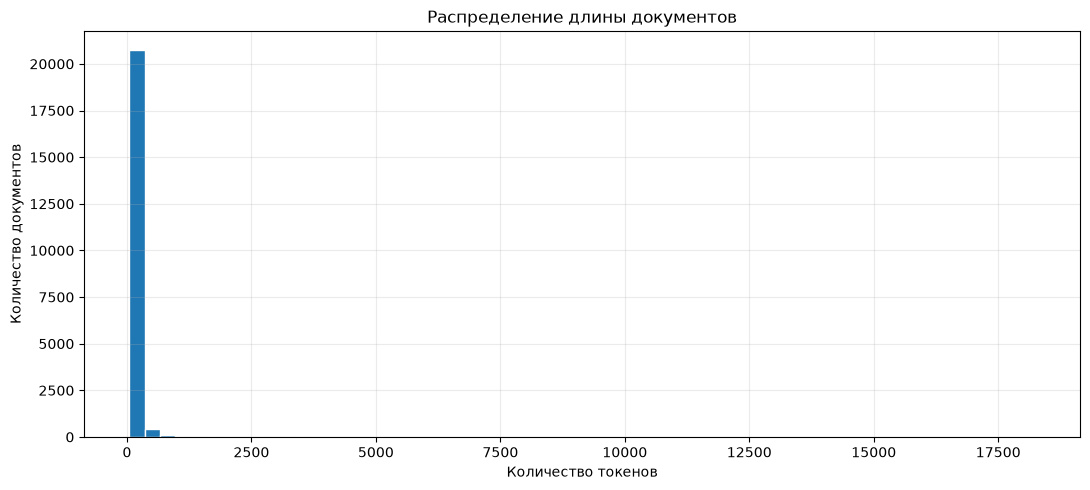

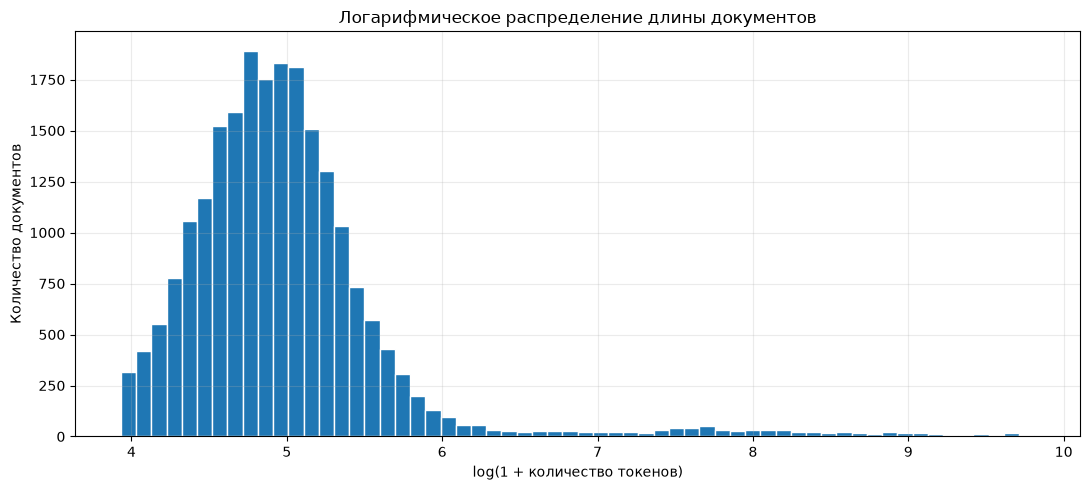

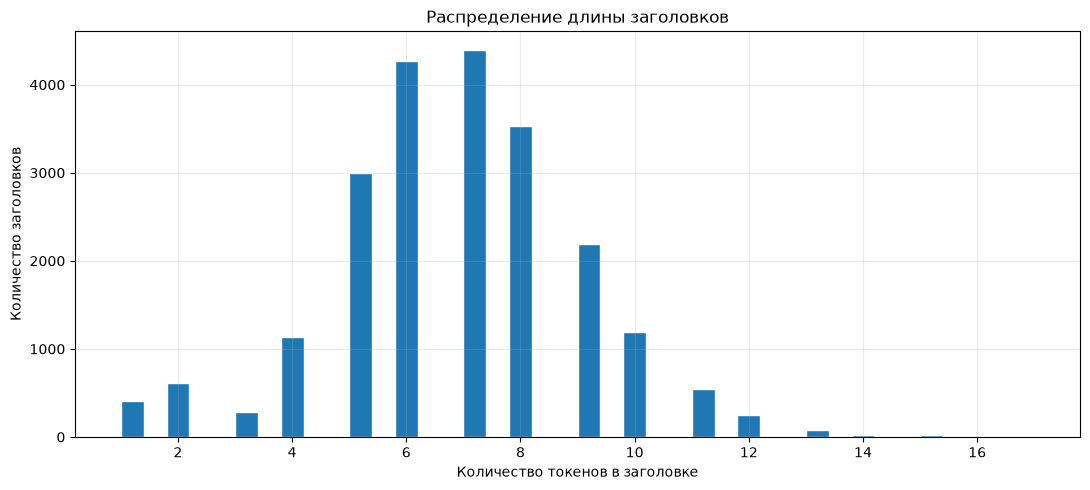

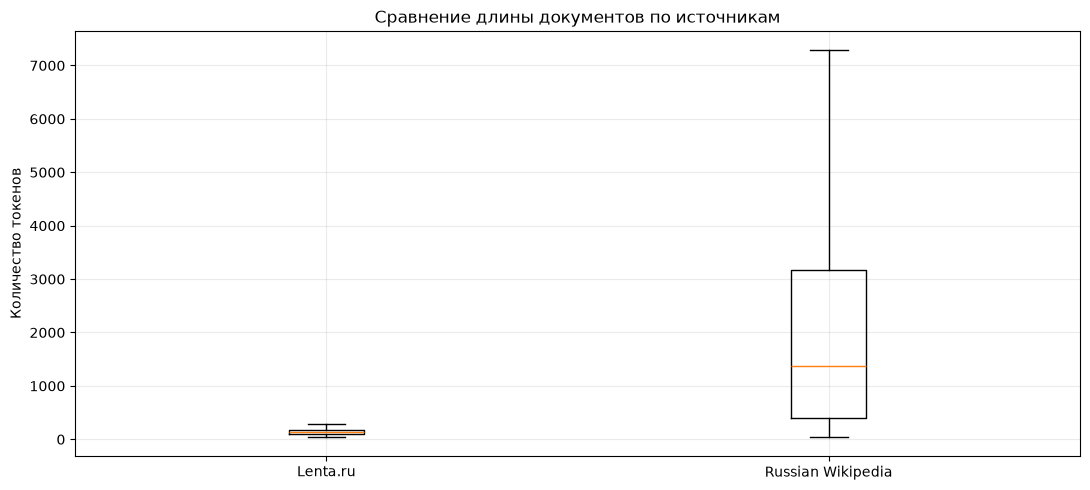

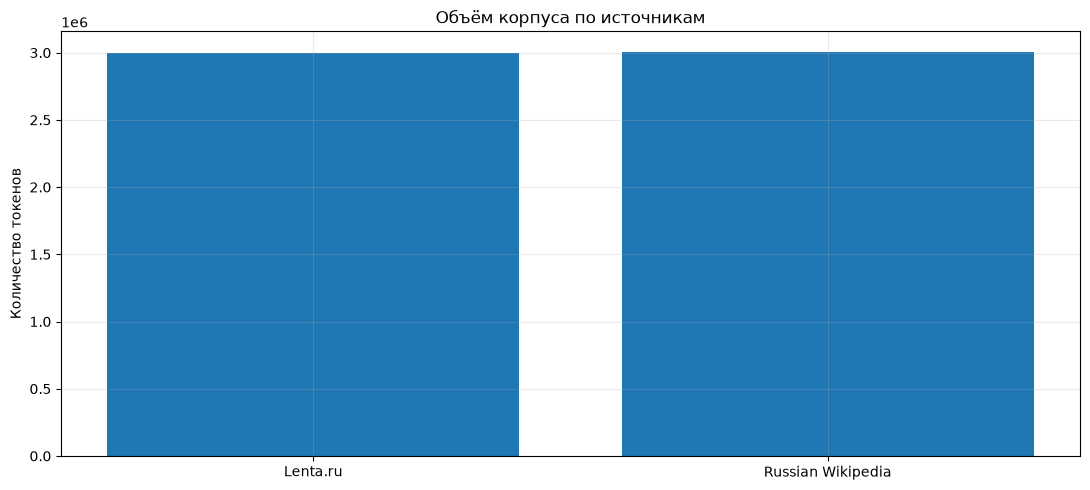

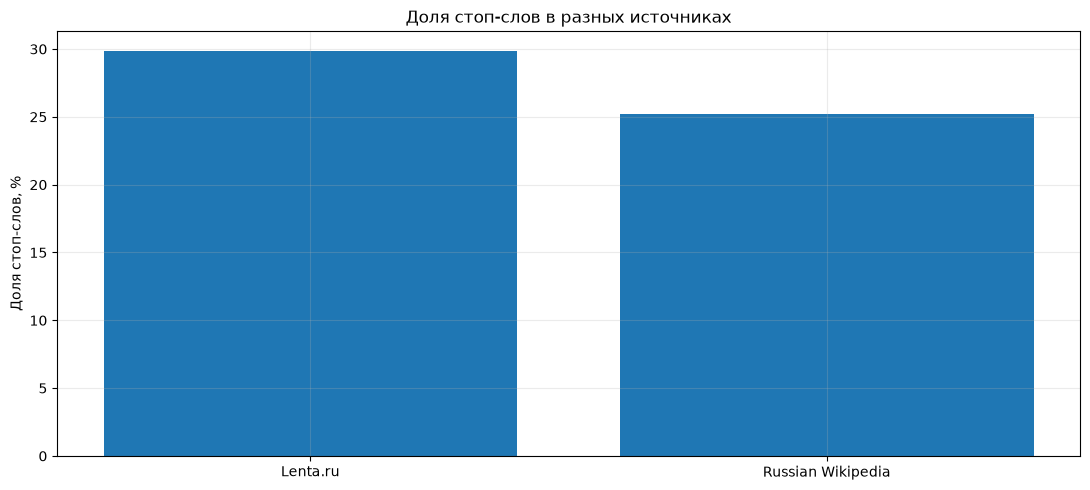

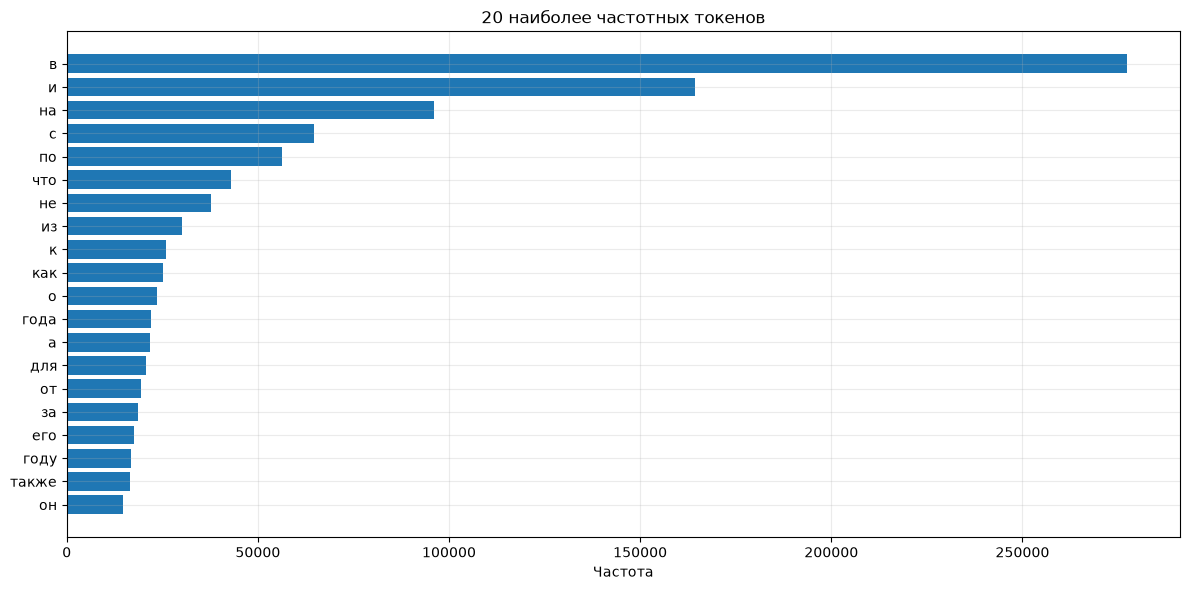

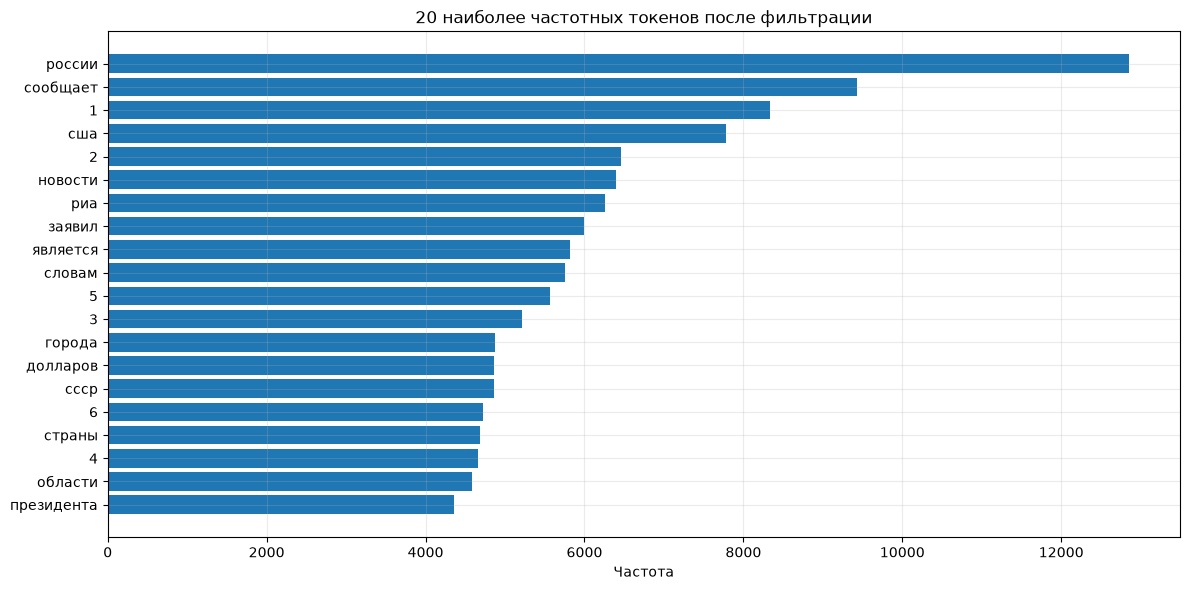

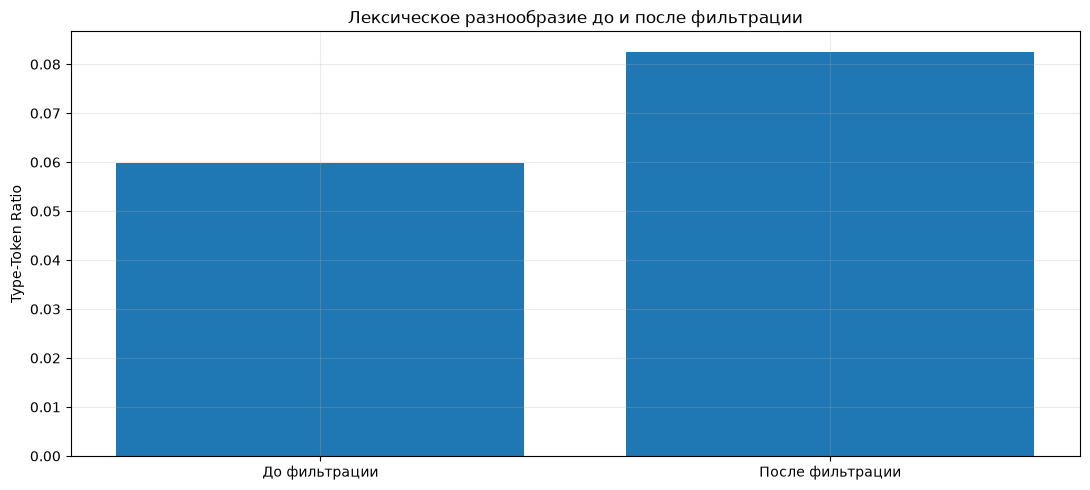

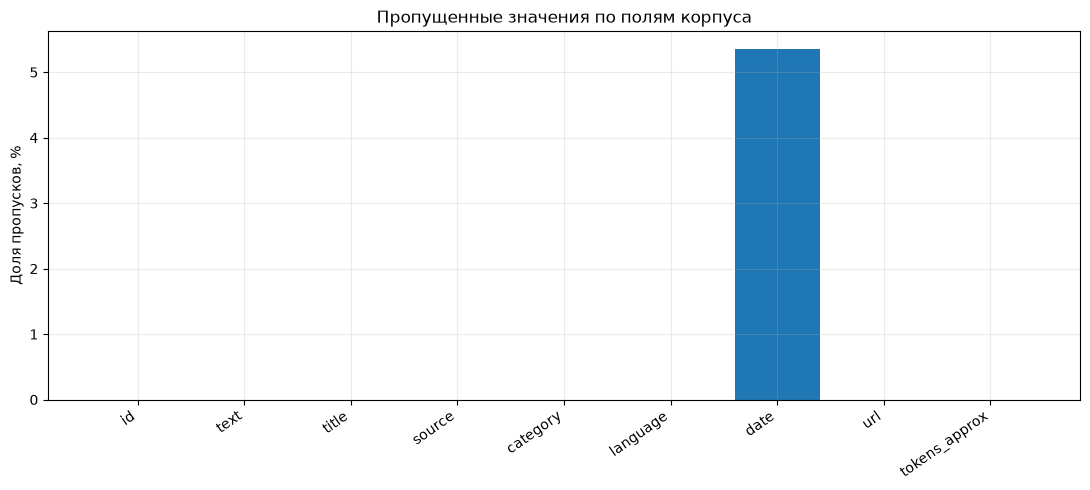


ПРОВЕРКИ КОРРЕКТНОСТИ
Количество документов: OK
Сумма токенов: OK
Частотные словари: OK
Стоп-слова: OK
Статистика источников: OK
Статистика категорий: OK
Обязательное поле text: OK
Расхождений с tokens_approx: 0
Некорректных записей: 0

ИТОГОВЫЕ РЕЗУЛЬТАТЫ ЗАДАНИЯ № 4
Документов: 21,937
Токенов: 6,007,425
Уникальных токенов: 359,827
TTR до фильтрации: 0.059897
TTR после фильтрации: 0.082557
Доля стоп-слов: 27.531%
Средняя длина документа: 273.85
Медианная длина документа: 134.00

Файлы результатов:
- /Users/lenar_966/Desktop/ML/NLP/Practika_1/reports/task4/corpus_statistics.json
- /Users/lenar_966/Desktop/ML/NLP/Practika_1/reports/task4/source_comparison.csv
- /Users/lenar_966/Desktop/ML/NLP/Practika_1/reports/task4/category_comparison.csv
- /Users/lenar_966/Desktop/ML/NLP/Practika_1/reports/task4/missing_values.csv
- /Users/lenar_966/Desktop/ML/NLP/Practika_1/reports/task4/top_tokens.csv
- /Users/lenar_966/Desktop/ML/NLP/Practika_1/reports/task4/document_statistics.csv
- /Users/lenar

In [7]:

# ============================================================
# ПРАКТИЧЕСКАЯ РАБОТА № 1. NLP
# ЗАДАНИЕ № 4. ОПИСАТЕЛЬНАЯ СТАТИСТИКА КОРПУСА
# ============================================================

# ============================================================
# 1. ИМПОРТЫ И НАСТРОЙКИ
# ============================================================

import sys
import subprocess
import importlib.util
import json
import re
import time
import math
from pathlib import Path
from collections import Counter, defaultdict

packages = {
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "stop_words": "stop-words"
}

missing = [
    package
    for module, package in packages.items()
    if importlib.util.find_spec(module) is None
]

if missing:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", *missing
    ])

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from stop_words import get_stop_words
from IPython.display import display

SEED = 42
np.random.seed(SEED)

PROJECT_DIR = (
    Path.home() / "Desktop" / "ML" / "NLP" / "Practika_1"
)

CORPUS_PATH = (
    PROJECT_DIR / "data" / "processed" / "corpus.jsonl"
)

REPORT_DIR = PROJECT_DIR / "reports" / "task4"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

if not CORPUS_PATH.exists():
    raise FileNotFoundError(
        f"Корпус не найден: {CORPUS_PATH}"
    )

# Названия выходных файлов.
SUMMARY_PATH = REPORT_DIR / "corpus_statistics.json"
SOURCE_CSV = REPORT_DIR / "source_comparison.csv"
CATEGORY_CSV = REPORT_DIR / "category_comparison.csv"
MISSING_CSV = REPORT_DIR / "missing_values.csv"
FREQUENCY_CSV = REPORT_DIR / "top_tokens.csv"
DOCUMENT_CSV = REPORT_DIR / "document_statistics.csv"
STOPWORDS_CSV = REPORT_DIR / "stopwords_comparison.csv"

TOKEN_RE = re.compile(
    r"[^\W_]+(?:[-'][^\W_]+)*",
    re.UNICODE
)

STOP_WORDS = {
    word.casefold()
    for word in get_stop_words("ru")
}

REQUIRED_FIELDS = [
    "id", "text", "source",
    "language", "tokens_approx"
]

ANALYZED_FIELDS = [
    "id", "text", "title", "source",
    "category", "language", "date",
    "url", "tokens_approx"
]

print("=" * 75)
print("ЗАДАНИЕ № 4. ОПИСАТЕЛЬНАЯ СТАТИСТИКА КОРПУСА")
print("=" * 75)
print("Корпус:", CORPUS_PATH)
print("Размер файла, МБ:", round(
    CORPUS_PATH.stat().st_size / 1024**2, 2
))
print("Количество стоп-слов:", len(STOP_WORDS))

# ============================================================
# 2. ВСПОМОГАТЕЛЬНЫЕ ФУНКЦИИ
# ============================================================

def tokenize(text):
    """Выделяет токены по правилам задания № 1."""
    if not isinstance(text, str):
        return []
    return [
        token.casefold()
        for token in TOKEN_RE.findall(text)
    ]


def describe_lengths(values):
    """Возвращает основные статистики длины."""
    arr = np.asarray(values, dtype=np.float64)

    if arr.size == 0:
        return {
            "mean": None,
            "median": None,
            "std": None,
            "min": None,
            "max": None,
            "p25": None,
            "p75": None,
            "p95": None
        }

    return {
        "mean": round(float(np.mean(arr)), 3),
        "median": round(float(np.median(arr)), 3),
        "std": round(float(np.std(arr)), 3),
        "min": int(np.min(arr)),
        "max": int(np.max(arr)),
        "p25": round(float(np.percentile(arr, 25)), 3),
        "p75": round(float(np.percentile(arr, 75)), 3),
        "p95": round(float(np.percentile(arr, 95)), 3)
    }


def percentage(part, total):
    """Возвращает долю в процентах."""
    return round(100 * part / total, 3) if total else 0.0


def save_plot(filename):
    """Сохраняет текущий график."""
    plt.tight_layout()
    plt.savefig(
        REPORT_DIR / filename,
        dpi=160,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()


# ============================================================
# 3. ПОТОКОВЫЙ АНАЛИЗ ПОЛНОГО КОРПУСА
# ============================================================

started = time.perf_counter()

total_documents = 0
total_tokens = 0
total_stopwords = 0

global_frequency = Counter()
filtered_frequency = Counter()

source_frequency = defaultdict(Counter)
source_stopwords = Counter()
source_tokens = Counter()
source_documents = Counter()

category_frequency = defaultdict(Counter)
category_stopwords = Counter()
category_tokens = Counter()
category_documents = Counter()

missing_counts = Counter()
invalid_rows = 0
token_count_mismatches = 0

document_records = []

print("\nНачат потоковый анализ полного корпуса...")

with open(CORPUS_PATH, "r", encoding="utf-8") as file:

    for line_number, line in enumerate(file, start=1):

        try:
            doc = json.loads(line)
        except json.JSONDecodeError as error:
            raise ValueError(
                f"Некорректный JSON в строке {line_number}"
            ) from error

        if not isinstance(doc, dict):
            invalid_rows += 1
            continue

        for field in ANALYZED_FIELDS:
            value = doc.get(field)

            if (
                value is None
                or (isinstance(value, str)
                    and not value.strip())
            ):
                missing_counts[field] += 1

        for field in REQUIRED_FIELDS:
            if (
                field not in doc
                or doc[field] is None
            ):
                raise ValueError(
                    f"Отсутствует обязательное поле {field} "
                    f"в строке {line_number}"
                )

        text = doc["text"]

        if not isinstance(text, str):
            raise TypeError(
                f"Поле text не является строкой: "
                f"строка {line_number}"
            )

        source = str(doc["source"])
        category = doc.get("category")

        if category is None or not str(category).strip():
            category = "Не указана"
        else:
            category = str(category)

        title = doc.get("title")
        title = title if isinstance(title, str) else ""

        tokens = tokenize(text)
        title_tokens = tokenize(title)

        token_count = len(tokens)
        title_count = len(title_tokens)

        frequencies = Counter(tokens)

        stopword_count = sum(
            count
            for word, count in frequencies.items()
            if word in STOP_WORDS
        )

        filtered = {
            word: count
            for word, count in frequencies.items()
            if word not in STOP_WORDS
        }

        # Глобальная статистика.
        total_documents += 1
        total_tokens += token_count
        total_stopwords += stopword_count

        global_frequency.update(frequencies)
        filtered_frequency.update(filtered)

        # Статистика источников.
        source_frequency[source].update(frequencies)
        source_documents[source] += 1
        source_tokens[source] += token_count
        source_stopwords[source] += stopword_count

        # Статистика категорий.
        category_frequency[category].update(frequencies)
        category_documents[category] += 1
        category_tokens[category] += token_count
        category_stopwords[category] += stopword_count

        # Сверка с предварительным подсчётом.
        approx = doc.get("tokens_approx")

        if approx is not None:
            try:
                if int(approx) != token_count:
                    token_count_mismatches += 1
            except (ValueError, TypeError):
                token_count_mismatches += 1

        document_records.append({
            "id": doc["id"],
            "source": source,
            "category": category,
            "text_tokens": token_count,
            "title_tokens": title_count,
            "stopword_tokens": stopword_count,
            "filtered_tokens": token_count - stopword_count,
            "stopword_share_pct": percentage(
                stopword_count, token_count
            ),
            "has_title": bool(title.strip()),
            "has_date": bool(doc.get("date")),
            "has_url": bool(doc.get("url"))
        })

        if total_documents % 5000 == 0:
            print(
                f"Обработано {total_documents:,} документов; "
                f"токенов: {total_tokens:,}"
            )

elapsed = time.perf_counter() - started

df = pd.DataFrame(document_records)

assert total_documents > 0
assert total_tokens > 0
assert sum(global_frequency.values()) == total_tokens
assert sum(filtered_frequency.values()) == (
    total_tokens - total_stopwords
)
assert sum(source_tokens.values()) == total_tokens
assert sum(category_tokens.values()) == total_tokens

print("\nАнализ завершён.")
print("Время, сек:", round(elapsed, 3))

# ============================================================
# 4. ОБЩАЯ СТАТИСТИКА КОРПУСА
# ============================================================

unique_tokens = len(global_frequency)
filtered_tokens = total_tokens - total_stopwords
filtered_unique = len(filtered_frequency)

ttr_before = (
    unique_tokens / total_tokens
    if total_tokens else 0
)

ttr_after = (
    filtered_unique / filtered_tokens
    if filtered_tokens else 0
)

text_lengths = describe_lengths(
    df["text_tokens"].to_numpy()
)

# Отдельно считаем заголовки, которые действительно есть.
existing_titles = df.loc[
    df["has_title"], "title_tokens"
]

title_lengths = describe_lengths(
    existing_titles.to_numpy()
)

print("\n" + "=" * 75)
print("ОБЩАЯ СТАТИСТИКА")
print("=" * 75)

general_table = pd.DataFrame([
    ["Количество документов", total_documents],
    ["Количество токенов", total_tokens],
    ["Уникальных токенов", unique_tokens],
    ["TTR до фильтрации", round(ttr_before, 6)],
    ["Средняя длина документа", text_lengths["mean"]],
    ["Медианная длина документа", text_lengths["median"]],
    ["Максимальная длина документа", text_lengths["max"]],
    ["Средняя длина заголовка", title_lengths["mean"]],
    ["Медианная длина заголовка", title_lengths["median"]],
    ["Стоп-слов (токенов)", total_stopwords],
    ["Доля стоп-слов, %", percentage(
        total_stopwords, total_tokens
    )],
    ["Токенов после фильтрации", filtered_tokens],
    ["Уникальных после фильтрации", filtered_unique],
    ["TTR после фильтрации", round(ttr_after, 6)]
], columns=["Показатель", "Значение"])

display(general_table)

# ============================================================
# 5. СРАВНЕНИЕ ИСТОЧНИКОВ
# ============================================================

source_rows = []

for source in sorted(source_documents):

    part = df[df["source"] == source]

    lengths = describe_lengths(
        part["text_tokens"].to_numpy()
    )

    title_part = part.loc[
        part["has_title"], "title_tokens"
    ]

    source_title_stats = describe_lengths(
        title_part.to_numpy()
    )

    n_tokens = source_tokens[source]
    n_unique = len(source_frequency[source])

    source_rows.append({
        "Источник": source,
        "Документов": source_documents[source],
        "Токенов": n_tokens,
        "Уникальных токенов": n_unique,
        "TTR": round(
            n_unique / n_tokens, 6
        ) if n_tokens else 0,
        "Средняя длина": lengths["mean"],
        "Медианная длина": lengths["median"],
        "Максимальная длина": lengths["max"],
        "Средняя длина заголовка":
            source_title_stats["mean"],
        "Доля стоп-слов, %": percentage(
            source_stopwords[source],
            n_tokens
        )
    })

source_df = pd.DataFrame(source_rows)

print("\n" + "=" * 75)
print("СРАВНЕНИЕ ИСТОЧНИКОВ")
print("=" * 75)

display(source_df)

# ============================================================
# 6. СРАВНЕНИЕ КАТЕГОРИЙ
# ============================================================

category_rows = []

for category in sorted(category_documents):

    part = df[df["category"] == category]
    lengths = describe_lengths(
        part["text_tokens"].to_numpy()
    )

    n_tokens = category_tokens[category]
    n_unique = len(category_frequency[category])

    category_rows.append({
        "Категория": category,
        "Документов": category_documents[category],
        "Токенов": n_tokens,
        "Уникальных": n_unique,
        "TTR": round(
            n_unique / n_tokens, 6
        ) if n_tokens else 0,
        "Средняя длина": lengths["mean"],
        "Медианная длина": lengths["median"],
        "Доля стоп-слов, %": percentage(
            category_stopwords[category],
            n_tokens
        )
    })

category_df = pd.DataFrame(category_rows)

category_df = category_df.sort_values(
    "Документов",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 75)
print("СТАТИСТИКА ПО КАТЕГОРИЯМ")
print("=" * 75)

display(category_df.head(20))

# ============================================================
# 7. АНАЛИЗ ПРОПУЩЕННЫХ ЗНАЧЕНИЙ
# ============================================================

missing_rows = []

for field in ANALYZED_FIELDS:

    missing = missing_counts[field]

    missing_rows.append({
        "Поле": field,
        "Пропущено": missing,
        "Заполнено": total_documents - missing,
        "Доля пропусков, %": percentage(
            missing, total_documents
        )
    })

missing_df = pd.DataFrame(missing_rows)

print("\n" + "=" * 75)
print("ПРОПУЩЕННЫЕ ЗНАЧЕНИЯ")
print("=" * 75)

display(missing_df)

# ============================================================
# 8. СРАВНЕНИЕ ДО И ПОСЛЕ ФИЛЬТРАЦИИ СТОП-СЛОВ
# ============================================================

stopwords_df = pd.DataFrame([
    {
        "Состояние": "До фильтрации",
        "Токенов": total_tokens,
        "Уникальных": unique_tokens,
        "TTR": round(ttr_before, 6),
        "Стоп-слов": total_stopwords,
        "Доля стоп-слов, %": percentage(
            total_stopwords, total_tokens
        )
    },
    {
        "Состояние": "После фильтрации",
        "Токенов": filtered_tokens,
        "Уникальных": filtered_unique,
        "TTR": round(ttr_after, 6),
        "Стоп-слов": 0,
        "Доля стоп-слов, %": 0
    }
])

print("\n" + "=" * 75)
print("СРАВНЕНИЕ ДО И ПОСЛЕ УДАЛЕНИЯ СТОП-СЛОВ")
print("=" * 75)

display(stopwords_df)

# ============================================================
# 9. ЧАСТОТНЫЙ АНАЛИЗ
# ============================================================

top_before = global_frequency.most_common(30)
top_after = filtered_frequency.most_common(30)

frequency_df = pd.DataFrame([
    {
        "Токен": word,
        "Частота": count,
        "Доля от всех токенов, %": percentage(
            count, total_tokens
        )
    }
    for word, count in top_before
])

print("\n" + "=" * 75)
print("ТОП-30 ТОКЕНОВ ДО ФИЛЬТРАЦИИ")
print("=" * 75)

display(frequency_df)

print("\nТОП-30 ТОКЕНОВ ПОСЛЕ ФИЛЬТРАЦИИ")

display(pd.DataFrame(
    top_after,
    columns=["Токен", "Частота"]
))

# ============================================================
# 10. ВИЗУАЛИЗАЦИЯ
# ============================================================

plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

# ------------------------------------------------------------
# График 1. Распределение длины документов
# ------------------------------------------------------------

plt.figure()

plt.hist(
    df["text_tokens"],
    bins=60,
    edgecolor="white"
)

plt.xlabel("Количество токенов")
plt.ylabel("Количество документов")
plt.title("Распределение длины документов")

save_plot("document_length_histogram.png")

# ------------------------------------------------------------
# График 2. Распределение в логарифмической шкале
# ------------------------------------------------------------

plt.figure()

plt.hist(
    np.log1p(df["text_tokens"]),
    bins=60,
    edgecolor="white"
)

plt.xlabel("log(1 + количество токенов)")
plt.ylabel("Количество документов")
plt.title("Логарифмическое распределение длины документов")

save_plot("document_length_log_histogram.png")

# ------------------------------------------------------------
# График 3. Распределение длины заголовков
# ------------------------------------------------------------

plt.figure()

plt.hist(
    existing_titles,
    bins=40,
    edgecolor="white"
)

plt.xlabel("Количество токенов в заголовке")
plt.ylabel("Количество заголовков")
plt.title("Распределение длины заголовков")

save_plot("title_length_histogram.png")

# ------------------------------------------------------------
# График 4. Длина документов по источникам
# ------------------------------------------------------------

plt.figure()

source_names = sorted(df["source"].unique())

source_data = [
    df.loc[
        df["source"] == source,
        "text_tokens"
    ].to_numpy()
    for source in source_names
]

plt.boxplot(
    source_data,
    tick_labels=source_names,
    showfliers=False
)

plt.ylabel("Количество токенов")
plt.title("Сравнение длины документов по источникам")

save_plot("source_length_boxplot.png")

# ------------------------------------------------------------
# График 5. Объём источников в токенах
# ------------------------------------------------------------

plt.figure()

plt.bar(
    source_df["Источник"],
    source_df["Токенов"]
)

plt.ylabel("Количество токенов")
plt.title("Объём корпуса по источникам")

save_plot("source_token_volume.png")

# ------------------------------------------------------------
# График 6. Доля стоп-слов по источникам
# ------------------------------------------------------------

plt.figure()

plt.bar(
    source_df["Источник"],
    source_df["Доля стоп-слов, %"]
)

plt.ylabel("Доля стоп-слов, %")
plt.title("Доля стоп-слов в разных источниках")

save_plot("stopword_share_by_source.png")

# ------------------------------------------------------------
# График 7. Частотные слова до фильтрации
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

words, counts = zip(*top_before[:20])

plt.barh(
    list(words)[::-1],
    list(counts)[::-1]
)

plt.xlabel("Частота")
plt.title("20 наиболее частотных токенов")

save_plot("top20_tokens_before.png")

# ------------------------------------------------------------
# График 8. Частотные слова после фильтрации
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

words, counts = zip(*top_after[:20])

plt.barh(
    list(words)[::-1],
    list(counts)[::-1]
)

plt.xlabel("Частота")
plt.title("20 наиболее частотных токенов после фильтрации")

save_plot("top20_tokens_after.png")

# ------------------------------------------------------------
# График 9. Сравнение TTR
# ------------------------------------------------------------

plt.figure()

plt.bar(
    ["До фильтрации", "После фильтрации"],
    [ttr_before, ttr_after]
)

plt.ylabel("Type-Token Ratio")
plt.title("Лексическое разнообразие до и после фильтрации")

save_plot("ttr_comparison.png")

# ------------------------------------------------------------
# График 10. Пропуски
# ------------------------------------------------------------

plt.figure(figsize=(11, 5))

plt.bar(
    missing_df["Поле"],
    missing_df["Доля пропусков, %"]
)

plt.ylabel("Доля пропусков, %")
plt.xticks(rotation=35, ha="right")
plt.title("Пропущенные значения по полям корпуса")

save_plot("missing_values.png")

# ============================================================
# 11. ДОПОЛНИТЕЛЬНЫЕ ПРОВЕРКИ
# ============================================================

print("\n" + "=" * 75)
print("ПРОВЕРКИ КОРРЕКТНОСТИ")
print("=" * 75)

assert total_documents == len(df)
assert total_tokens == int(df["text_tokens"].sum())
assert total_stopwords == int(df["stopword_tokens"].sum())

assert filtered_tokens >= 0
assert filtered_unique <= unique_tokens

assert 0 <= ttr_before <= 1
assert 0 <= ttr_after <= 1

assert (
    source_df["Документов"].sum()
    == total_documents
)

assert (
    category_df["Документов"].sum()
    == total_documents
)

assert (
    int(missing_df.loc[
        missing_df["Поле"] == "text",
        "Пропущено"
    ].iloc[0]) == 0
)

print("Количество документов: OK")
print("Сумма токенов: OK")
print("Частотные словари: OK")
print("Стоп-слова: OK")
print("Статистика источников: OK")
print("Статистика категорий: OK")
print("Обязательное поле text: OK")

print(
    "Расхождений с tokens_approx:",
    token_count_mismatches
)
print("Некорректных записей:", invalid_rows)

# ============================================================
# 12. СОХРАНЕНИЕ ОТЧЁТОВ
# ============================================================

df.to_csv(
    DOCUMENT_CSV,
    index=False,
    encoding="utf-8-sig"
)

source_df.to_csv(
    SOURCE_CSV,
    index=False,
    encoding="utf-8-sig"
)

category_df.to_csv(
    CATEGORY_CSV,
    index=False,
    encoding="utf-8-sig"
)

missing_df.to_csv(
    MISSING_CSV,
    index=False,
    encoding="utf-8-sig"
)

frequency_df.to_csv(
    FREQUENCY_CSV,
    index=False,
    encoding="utf-8-sig"
)

stopwords_df.to_csv(
    STOPWORDS_CSV,
    index=False,
    encoding="utf-8-sig"
)

summary = {
    "task": 4,
    "corpus": str(CORPUS_PATH),
    "documents": total_documents,
    "tokens": total_tokens,
    "unique_tokens": unique_tokens,
    "ttr_before": round(ttr_before, 8),
    "text_length": text_lengths,
    "title_length": title_lengths,
    "stopword_tokens": total_stopwords,
    "stopword_share_pct": percentage(
        total_stopwords, total_tokens
    ),
    "tokens_after_stopword_filtering": filtered_tokens,
    "unique_after_stopword_filtering": filtered_unique,
    "ttr_after": round(ttr_after, 8),
    "sources": source_rows,
    "categories": category_rows,
    "missing_values": missing_rows,
    "token_count_mismatches": token_count_mismatches,
    "invalid_rows": invalid_rows,
    "processing_seconds": round(elapsed, 3),
    "stopword_dictionary": "stop-words (Russian)",
    "tokenization": "regex, casefold, no lemmatization"
}

with open(
    SUMMARY_PATH, "w", encoding="utf-8"
) as file:
    json.dump(
        summary,
        file,
        ensure_ascii=False,
        indent=2
    )

# ============================================================
# 13. ИТОГОВЫЙ ВЫВОД
# ============================================================

print("\n" + "=" * 75)
print("ИТОГОВЫЕ РЕЗУЛЬТАТЫ ЗАДАНИЯ № 4")
print("=" * 75)

print(f"Документов: {total_documents:,}")
print(f"Токенов: {total_tokens:,}")
print(f"Уникальных токенов: {unique_tokens:,}")
print(f"TTR до фильтрации: {ttr_before:.6f}")
print(f"TTR после фильтрации: {ttr_after:.6f}")
print(
    f"Доля стоп-слов: "
    f"{percentage(total_stopwords, total_tokens):.3f}%"
)
print(
    f"Средняя длина документа: "
    f"{text_lengths['mean']:.2f}"
)
print(
    f"Медианная длина документа: "
    f"{text_lengths['median']:.2f}"
)

print("\nФайлы результатов:")
print("-", SUMMARY_PATH)
print("-", SOURCE_CSV)
print("-", CATEGORY_CSV)
print("-", MISSING_CSV)
print("-", FREQUENCY_CSV)
print("-", DOCUMENT_CSV)
print("-", STOPWORDS_CSV)

print("\nГрафики сохранены в:", REPORT_DIR)
print("Время анализа:", round(elapsed, 3), "сек")

print("\nЗадание № 4: статистический анализ завершён.")



### Анализ результатов и вывод по заданию № 4

В ходе выполнения четвёртого задания был проведён комплексный статистический анализ сформированного русскоязычного текстового корпуса. Исследование включало оценку объёма данных, лексического разнообразия, распределения длины документов и заголовков, распространённости стоп-слов, различий между источниками и полноты метаданных.

Анализ выполнялся на полном корпусе, включающем новостные публикации Lenta.ru и энциклопедические статьи русской Википедии.

#### 1. Общая характеристика корпуса

Общий объём исследуемого корпуса составил **21 937 документов**, содержащих **6 007 425 токенов**.

Количество уникальных токенов после приведения слов к нижнему регистру составило **359 827**.

Коэффициент лексического разнообразия Type-Token Ratio (TTR) составил **0,059897**, или приблизительно **5,99%**.

Полученное значение показывает, что корпус содержит значительное количество повторяющихся словоформ, что характерно для крупных текстовых коллекций. При этом абсолютное количество уникальных токенов свидетельствует о достаточно широком лексическом охвате.

Следует учитывать, что TTR зависит от размера корпуса, поэтому его значение не следует интерпретировать как универсальный показатель качества текстовых данных.

Средняя длина документа составила **273,85 токена**, медианная — **134 токена**, максимальная — **18 233 токена**.

Значительное различие между средним и медианным значениями свидетельствует о правосторонней асимметрии распределения длины документов. Большинство документов относительно короткие, однако присутствуют значительно более объёмные тексты, увеличивающие среднее значение.

Средняя длина заголовка составила **6,79 токена**, медианная — **7 токенов**.

Таким образом, заголовки имеют относительно небольшую длину, тогда как основной текст документов характеризуется существенно большей вариативностью.

#### 2. Сравнение новостного и энциклопедического источников

Корпус включает два источника с различными характеристиками.

**Lenta.ru:**

- Количество документов — **20 761**.
- Количество токенов — **3 000 025**.
- Уникальных токенов — **177 718**.
- TTR — **0,059239**.
- Средняя длина документа — **144,50 токена**.
- Медианная длина — **130 токенов**.
- Максимальная длина — **1 100 токенов**.
- Средняя длина заголовка — **7,07 токена**.
- Доля стоп-слов — **29,84%**.

**Русская Википедия:**

- Количество документов — **1 176**.
- Количество токенов — **3 007 400**.
- Уникальных токенов — **267 616**.
- TTR — **0,088986**.
- Средняя длина документа — **2 557,31 токена**.
- Медианная длина — **1 376 токенов**.
- Максимальная длина — **18 233 токена**.
- Средняя длина заголовка — **1,82 токена**.
- Доля стоп-слов — **25,23%**.

Несмотря на существенную разницу в количестве документов, оба источника имеют приблизительно одинаковый объём токенов — около 3 миллионов.

Средняя длина энциклопедической статьи превышает среднюю длину новостной публикации приблизительно в **17,7 раза**.

Это объясняет различие между распределениями длины документов и показывает необходимость учитывать особенности источников при последующей обработке данных.

Википедия также характеризуется большим количеством уникальных токенов и более высоким TTR. Это может быть связано с широким тематическим охватом энциклопедических материалов, наличием специальной терминологии и собственных имён.

При этом различия TTR не следует считать прямым доказательством более высокого лексического разнообразия источника без дополнительной нормализации по размеру и составу текстов.

#### 3. Анализ стоп-слов

В исходном корпусе обнаружено **1 653 907 токенов**, соответствующих русскому словарю стоп-слов.

Их доля составила **27,531%** общего количества токенов.

После удаления стоп-слов объём корпуса уменьшился до **4 353 518 токенов**, то есть на **1 653 907 токенов**.

Количество уникальных токенов сократилось с **359 827 до 359 415**, что соответствует удалению **412 уникальных словоформ**.

Коэффициент TTR увеличился:

- До фильтрации — **0,059897**.
- После фильтрации — **0,082557**.

Увеличение TTR связано с тем, что из корпуса были удалены преимущественно высокочастотные служебные слова, в результате чего общее количество токенов существенно сократилось, а размер словаря изменился незначительно.

Следовательно, удаление стоп-слов увеличивает относительную долю уникальных токенов, но не создаёт новых лексических единиц.

Сравнение источников показало, что доля стоп-слов в новостных текстах составляет **29,837%**, а в энциклопедических — **25,230%**.

Разница составляет приблизительно **4,61 процентного пункта**.

Полученные результаты свидетельствуют о различиях лексической структуры двух источников. Для более точного объяснения этих различий потребовался бы дополнительный анализ частей речи и тематического состава документов.

#### 4. Анализ пропущенных значений

В ходе исследования была проведена проверка полноты основных полей JSONL-корпуса.

Поля `id`, `text`, `title`, `source`, `category`, `language`, `url` и `tokens_approx` заполнены во всех **21 937 документах**.

Пропущенные значения обнаружены только в поле `date`:

- Количество пропусков — **1 176**.
- Доля пропусков — **5,361%**.
- Количество заполненных значений — **20 761**.

Количество пропусков соответствует числу документов русской Википедии, включённых в корпус.

Отсутствие даты для энциклопедических статей не препятствует решению основных задач токенизации и нормализации, поскольку дата не является обязательным входным признаком данных алгоритмов.

Однако при проведении временного анализа или изучении динамики публикаций необходимо учитывать неполноту этого поля.

Таким образом, сформированный корпус характеризуется высокой полнотой основных структурных полей.

#### 5. Интерпретация визуализаций

В ходе выполнения задания были построены гистограммы длины документов и заголовков, графики сравнения источников, распределения стоп-слов, частотных характеристик токенов и лексического разнообразия.

Сопоставление среднего и медианного значений длины документов подтверждает наличие правосторонней асимметрии распределения.

Сравнение источников показывает, что новостные документы значительно короче энциклопедических статей, хотя общий объём токенов двух источников практически одинаков.

Графики доли стоп-слов отражают различия в составе лексики, а сравнение TTR демонстрирует влияние фильтрации высокочастотных служебных слов на относительное лексическое разнообразие.

#### 6. Практическое значение результатов

Полученные характеристики необходимо учитывать при проектировании последующих этапов NLP-обработки.

Во-первых, значительная вариативность длины документов требует применения алгоритмов, способных эффективно обрабатывать как короткие, так и длинные тексты.

Во-вторых, наличие **359 827 уникальных токенов** указывает на необходимость использования методов нормализации и субсловной токенизации для уменьшения проблемы редких и неизвестных слов.

В-третьих, различия между источниками подтверждают целесообразность отдельной оценки качества токенизации на новостных и энциклопедических текстах.

В-четвёртых, удаление стоп-слов должно оставаться конфигурируемой операцией, поскольку для разных NLP-задач сохранение служебной лексики может быть как полезным, так и необходимым.

#### 7. Ограничения исследования

Статистический анализ выполнялся с использованием регулярной токенизации без морфологической нормализации.

Поэтому различные словоформы одного слова учитывались как отдельные токены при расчёте размера словаря.

Кроме того, показатель TTR зависит от размера корпуса, а его прямое сравнение между источниками может быть чувствительно к различиям длины и тематического состава документов.

Фильтрация стоп-слов выполнялась на основе фиксированного словаря и не учитывала контекстную роль отдельных слов.

#### Итоговый вывод

В результате выполнения задания проведён статистический анализ полного корпуса, включающего **21 937 документов и 6 007 425 токенов**.

Установлено, что корпус содержит **359 827 уникальных токенов**, а коэффициент лексического разнообразия составляет **0,059897**.

Выявлены существенные различия между новостными и энциклопедическими текстами: средняя длина статьи Википедии примерно в **17,7 раза** превышает среднюю длину публикации Lenta.ru.

Доля стоп-слов в корпусе составляет **27,531%**. После их удаления количество токенов уменьшается до **4 353 518**, а TTR увеличивается до **0,082557**.

Проверка полноты данных показала отсутствие пропусков в обязательных полях корпуса. Пропуски обнаружены только в поле `date` и составляют **5,361%** документов.

Полученные статистические характеристики формируют основу для последующего сравнительного исследования методов токенизации, стемминга, лемматизации и обучения субсловных моделей.


## Задание № 5. Сравнительный анализ методов токенизации, стемминга и лемматизации

### Цель работы

Провести экспериментальное сравнение классических методов токенизации и морфологической нормализации русскоязычного текста на основе количественных и качественных метрик, определить их вычислительные характеристики, способность уменьшать размер словаря и обеспечивать согласованное представление различных словоформ одной лексемы.

### Постановка задачи

В рамках задания необходимо:

1. Реализовать и сравнить пять методов токенизации:
   - токенизация по пробельным символам (Whitespace);
   - токенизация на основе регулярных выражений (Regex);
   - токенизация средствами NLTK;
   - токенизация средствами spaCy;
   - токенизация средствами Razdel.

2. Реализовать и сравнить методы морфологической нормализации:
   - стемминг по алгоритму Портера для русского языка;
   - стемминг SnowballStemmer;
   - лемматизация средствами pymorphy3;
   - лемматизация средствами spaCy.

3. Подготовить воспроизводимое разбиение документов на обучающую и тестовую выборки.

4. Рассчитать размер словаря, формируемого каждым методом.

5. Рассчитать долю неизвестных токенов (Out-of-Vocabulary, OOV) на отложенной тестовой выборке.

6. Измерить время обработки фиксированного объёма текста и скорость обработки в токенах в секунду.

7. Оценить семантическую согласованность нормализации на наборе русских лексем, представленных различными грамматическими формами.

8. Сравнить результаты обработки текстов из новостного и энциклопедического источников.

9. Построить сравнительные таблицы и визуализации полученных результатов.

10. Сохранить результаты эксперимента, параметры запуска и аналитические отчёты.

### Используемые методы и инструменты

- Python — реализация экспериментального исследования.
- re — токенизация регулярными выражениями.
- NLTK — токенизация и алгоритмы стемминга.
- spaCy — токенизация и морфологическая лемматизация.
- Razdel — токенизация русскоязычных текстов.
- pymorphy3 — морфологический анализ русского языка.
- pandas и NumPy — расчёт статистических показателей.
- Matplotlib — визуализация результатов.
- collections.Counter — формирование частотных словарей.
- JSON и CSV — сохранение результатов.

### Методика эксперимента

Исследование проводится на воспроизводимой стратифицированной выборке документов из корпуса, сформированного в задании № 1.

Для ограничения вычислительных затрат используется фиксированная выборка из обоих источников. Документы разделяются на обучающую и тестовую части в соотношении 80/20 с фиксированным случайным зерном.

Все методы обрабатывают одинаковые документы. Сравнение проводится без удаления стоп-слов, чтобы исключить влияние дополнительной фильтрации на результаты токенизации.

Для оценки морфологической нормализации используется единая базовая токенизация регулярными выражениями. Это позволяет сравнивать именно алгоритмы нормализации, не смешивая их эффект с различиями сегментации текста.

### Основные метрики

**1. Размер словаря (Vocabulary Size)**

V = |U|,

где U — множество уникальных токенов, полученных методом на обучающей выборке.

**2. Доля неизвестных токенов (OOV Rate)**

OOV = N_unknown / N_test × 100%,

где N_unknown — количество токенов тестовой выборки, отсутствующих в обучающем словаре, N_test — общее количество токенов тестовой выборки.

**3. Скорость обработки**

Speed = N / T,

где N — количество обработанных входных токенов, T — время выполнения в секундах.

**4. Коэффициент согласованности нормализации**

Для каждой контрольной лексемы используется набор грамматических словоформ. Рассчитывается количество различных нормализованных представлений этих форм.

Коэффициент согласованности определяется как:

C = 1 - (K - 1) / (M - 1),

где K — число различных результатов нормализации, M — число исходных словоформ одной лексемы.

При C = 1 все словоформы получили одинаковое представление. При C = 0 все словоформы остались различными.

Средний коэффициент рассчитывается по всем контрольным лексемам.

Данный показатель оценивает согласованность объединения словоформ, но сам по себе не доказывает семантическую правильность полученной основы или леммы.

### Ожидаемый результат

В результате эксперимента должны быть получены сравнительные таблицы методов токенизации, стемминга и лемматизации по размеру словаря, OOV, скорости обработки и согласованности нормализации.

Дополнительно должны быть сформированы графики, примеры преобразования словоформ, сравнительные характеристики источников и воспроизводимый отчёт.

Результаты будут использованы для выбора методов предварительной обработки текста и дальнейшего обучения субсловных токенизаторов BPE, WordPiece и Unigram Language Model.


ЗАДАНИЕ № 5. СРАВНЕНИЕ МЕТОДОВ NLP
Python: 3.12.3
spaCy: 3.8.18
NLTK: 3.10.4
pymorphy3: 2.0.6
Модель spaCy загружена: ru_core_news_sm

ФУНКЦИОНАЛЬНЫЕ ПРОВЕРКИ
Whitespace: ['в', '2026', 'году', 'исследователи', 'изучали', 'новые', 'технологии', 'обработки', 'текста.']
Regex: ['в', '2026', 'году', 'исследователи', 'изучали', 'новые', 'технологии', 'обработки', 'текста']
NLTK: ['в', '2026', 'году', 'исследователи', 'изучали', 'новые', 'технологии', 'обработки', 'текста']
spaCy: ['в', '2026', 'году', 'исследователи', 'изучали', 'новые', 'технологии', 'обработки', 'текста']
Razdel: ['в', '2026', 'году', 'исследователи', 'изучали', 'новые', 'технологии', 'обработки', 'текста']
Без нормализации: ['машина', 'машины', 'машиной', 'город', 'города', 'городами']
Porter (Russian): ['машин', 'машин', 'машин', 'город', 'город', 'город']
Snowball (Russian): ['машин', 'машин', 'машин', 'город', 'город', 'город']
pymorphy3: ['машина', 'машина', 'машина', 'город', 'город', 'город']
spaCy Lemma: ['машина'

,Словарь train,Токенов train,Токенов test,OOV токенов,"OOV, %",Уникальных OOV,Метод,"Время, сек"
0,81944,270486,70597,17557,24.8693,15274,Whitespace,0.061
1,62481,274004,71370,12614,17.6741,10284,Regex,0.093
2,61560,277341,72271,12411,17.1729,10032,NLTK,0.288
3,63229,274182,71565,12839,17.9403,10435,spaCy,2.117
4,63086,273160,70916,12883,18.1666,10572,Razdel,0.731



СРАВНЕНИЕ МЕТОДОВ НОРМАЛИЗАЦИИ
Без нормализации: словарь=62,481; OOV=17.67%; время=0.00 сек
Porter (Russian): словарь=32,642; OOV=9.07%; время=1.01 сек
Snowball (Russian): словарь=32,642; OOV=9.07%; время=1.04 сек
pymorphy3: словарь=33,742; OOV=9.58%; время=2.61 сек
spaCy Lemma: словарь=39,302; OOV=11.58%; время=51.49 сек


,Словарь train,Токенов train,Токенов test,OOV токенов,"OOV, %",Уникальных OOV,Метод,"Время, сек"
0,62481,274004,71370,12614,17.6741,10284,Без нормализации,0.001
1,32642,274004,71370,6472,9.0682,4774,Porter (Russian),1.011
2,32642,274004,71370,6472,9.0682,4774,Snowball (Russian),1.035
3,33742,274004,71370,6838,9.5811,5043,pymorphy3,2.612
4,39302,274004,71370,8263,11.5777,6408,spaCy Lemma,51.487



СОГЛАСОВАННОСТЬ НОРМАЛИЗАЦИИ


,Метод,Лексем,Среднее уникальных форм,Согласованность,Полностью объединено
0,Без нормализации,25,5.00,0.00,0
1,Porter (Russian),25,1.20,0.95,23
2,Snowball (Russian),25,1.20,0.95,23
3,pymorphy3,25,1.12,0.97,23
4,spaCy Lemma,25,1.24,0.94,22


,Метод,Лексема,Исходные формы,Нормализованные формы,Уникальных результатов,Согласованность
0,Без нормализации,машина,машина | машины | машине | машину | машиной,машина | машины | машине | машину | машиной,5,0.0
1,Без нормализации,город,город | города | городу | городом | городами,город | города | городу | городом | городами,5,0.0
2,Без нормализации,книга,книга | книги | книге | книгу | книгой,книга | книги | книге | книгу | книгой,5,0.0
3,Без нормализации,студент,студент | студента | студенту | студентом | ст...,студент | студента | студенту | студентом | ст...,5,0.0
4,Без нормализации,работа,работа | работы | работе | работу | работой,работа | работы | работе | работу | работой,5,0.0
5,Без нормализации,система,система | системы | системе | систему | системой,система | системы | системе | систему | системой,5,0.0
6,Без нормализации,данные,данные | данных | данным | данными | данное,данные | данных | данным | данными | данное,5,0.0
7,Без нормализации,информация,информация | информации | информацию | информа...,информация | информации | информацию | информа...,5,0.0
8,Без нормализации,модель,модель | модели | моделью | моделям | моделями,модель | модели | моделью | моделям | моделями,5,0.0
9,Без нормализации,алгоритм,алгоритм | алгоритма | алгоритму | алгоритмом ...,алгоритм | алгоритма | алгоритму | алгоритмом ...,5,0.0



СРАВНЕНИЕ ИСТОЧНИКОВ


,Источник,Метод,Словарь,"OOV, %",Токенов train,Токенов test
0,lenta,Без нормализации,17765,22.1322,58059,14680
1,lenta,Porter (Russian),9613,11.1308,58059,14680
2,lenta,Snowball (Russian),9613,11.1308,58059,14680
3,lenta,pymorphy3,9664,11.1035,58059,14680
4,lenta,spaCy Lemma,10520,12.3706,58059,14680
5,wikipedia,Без нормализации,53138,19.8783,215945,56690
6,wikipedia,Porter (Russian),28765,10.3599,215945,56690
7,wikipedia,Snowball (Russian),28765,10.3599,215945,56690
8,wikipedia,pymorphy3,29876,11.0654,215945,56690
9,wikipedia,spaCy Lemma,34574,13.2493,215945,56690



БЕНЧМАРК СКОРОСТИ


,Группа,Метод,Входных токенов,"Время, сек",Токенов/сек
0,Токенизация,Whitespace,14632,0.0026,5.636906e+06
1,Токенизация,Regex,14632,0.0038,3.872864e+06
2,Токенизация,NLTK,14632,0.0112,1.311253e+06
3,Токенизация,spaCy,14632,0.0099,1.475973e+06
4,Токенизация,Razdel,14632,0.0311,4.703682e+05
5,Нормализация,Без нормализации,14632,0.0000,4.180571e+08
6,Нормализация,Porter (Russian),14632,0.0007,2.074234e+07
7,Нормализация,Snowball (Russian),14632,0.0007,2.230488e+07
8,Нормализация,pymorphy3,14632,0.0007,2.202510e+07
9,Нормализация,spaCy Lemma,14632,2.1972,6.659290e+03


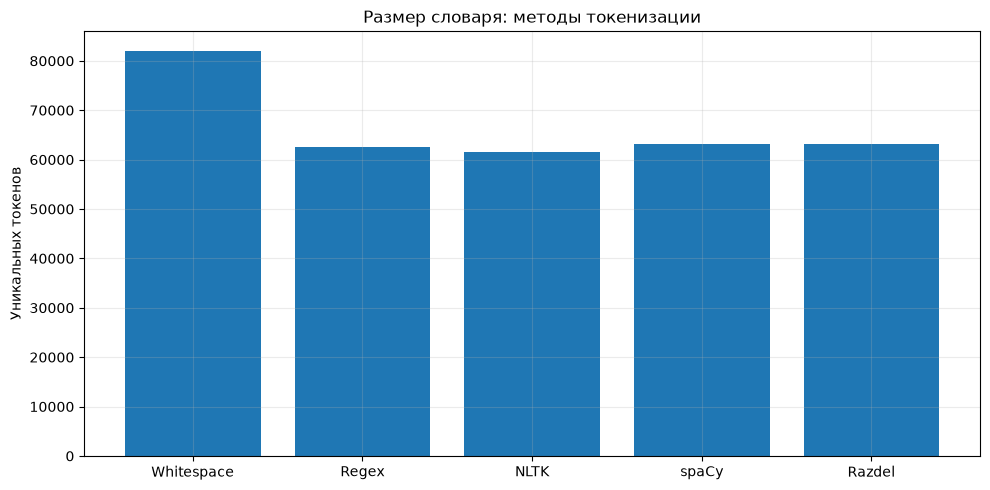

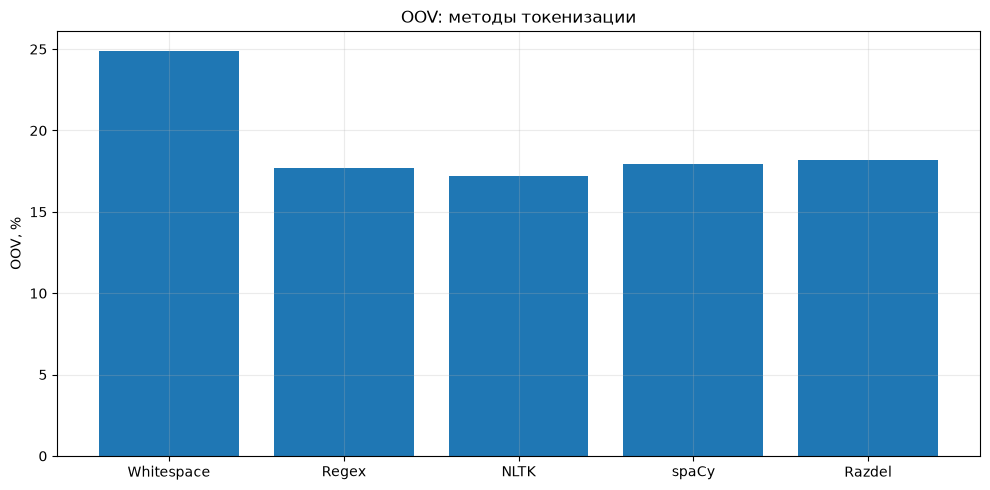

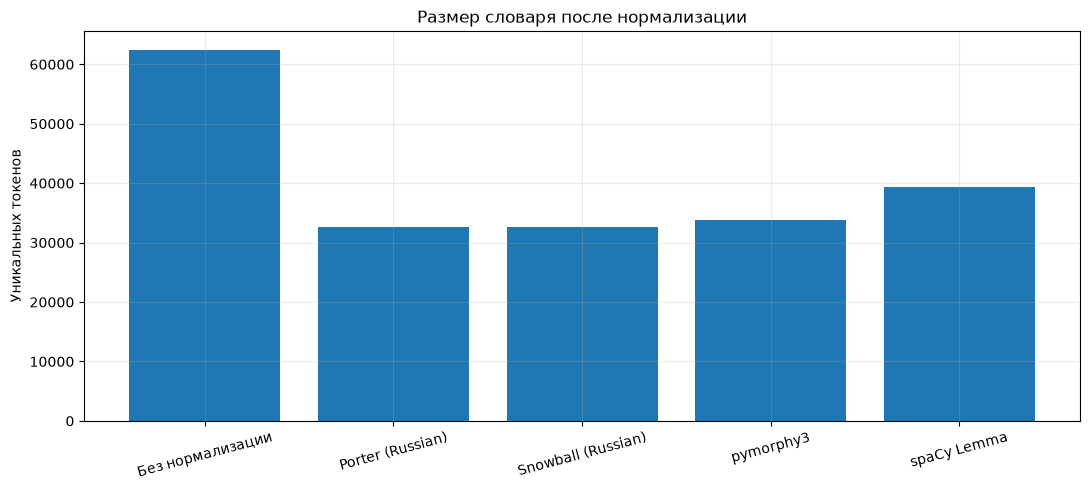

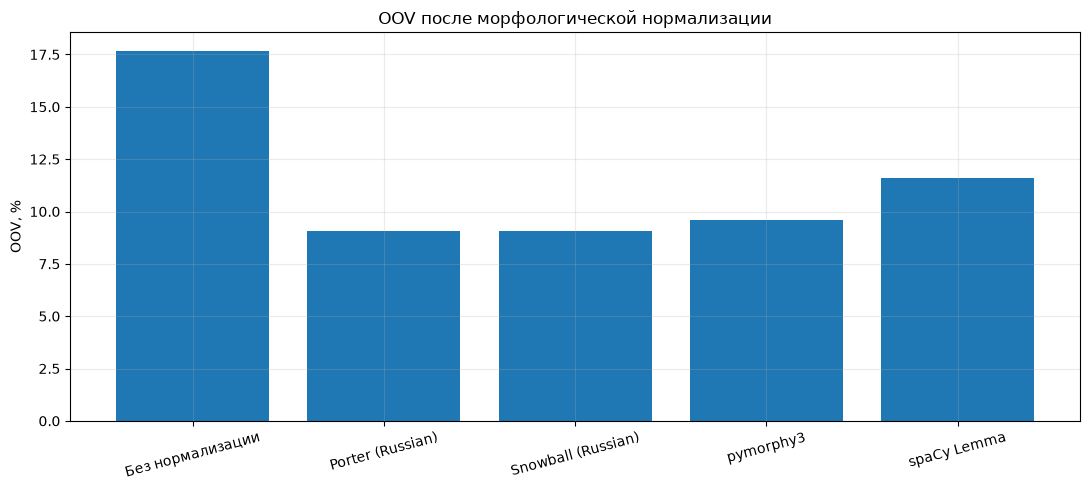

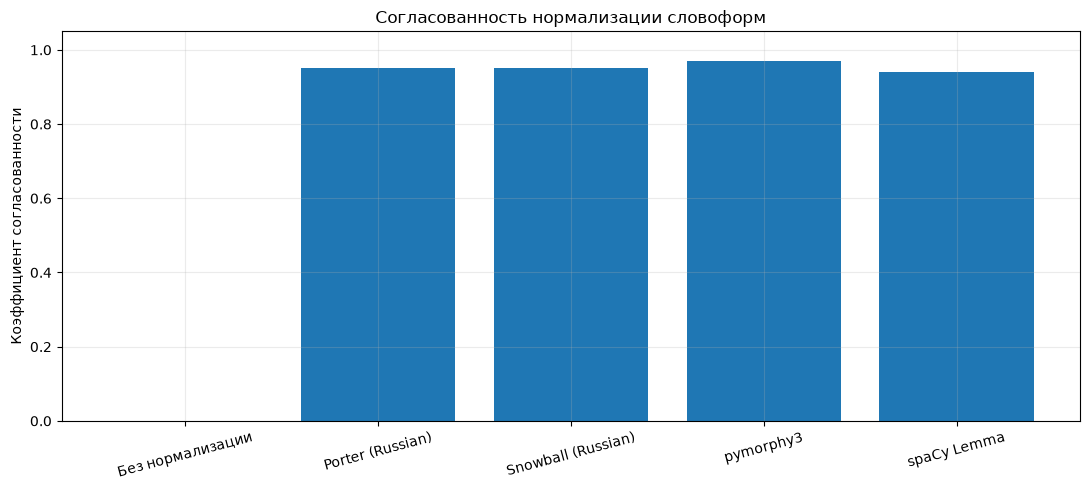

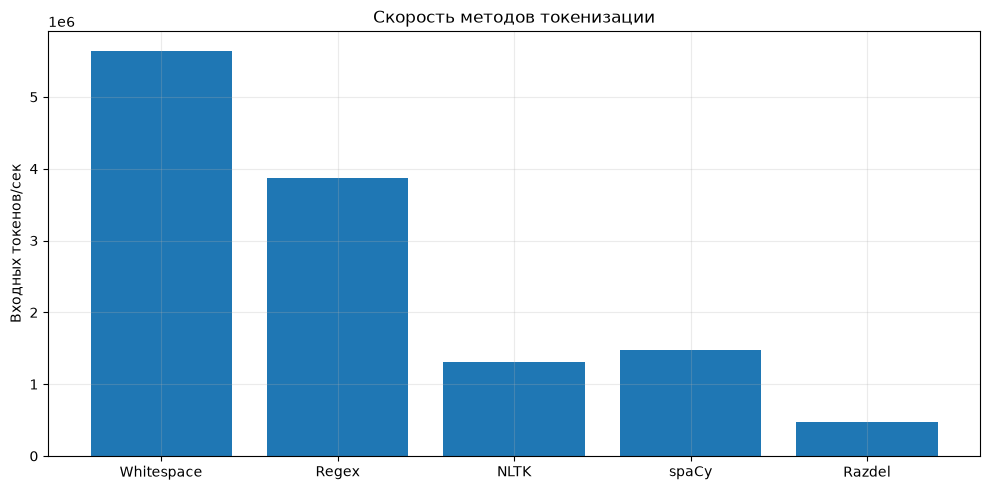

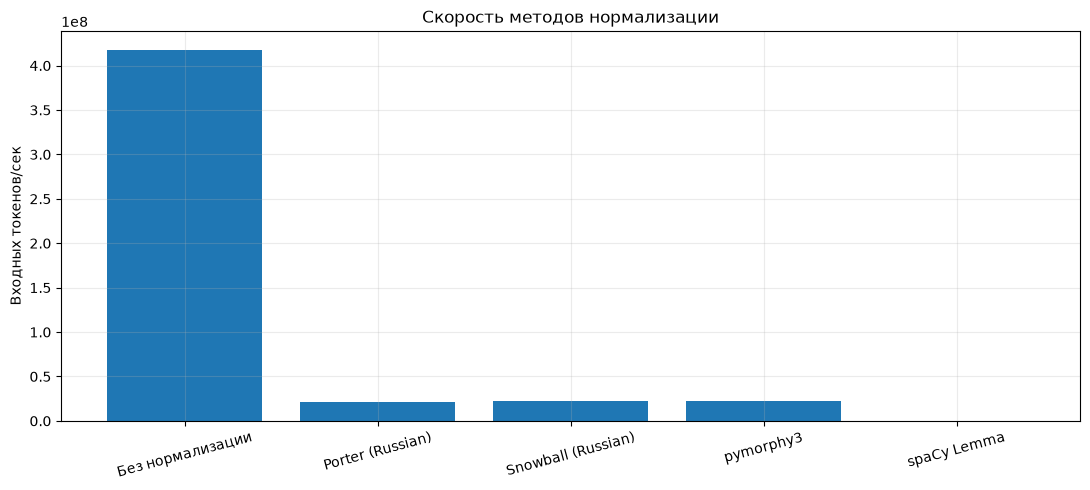

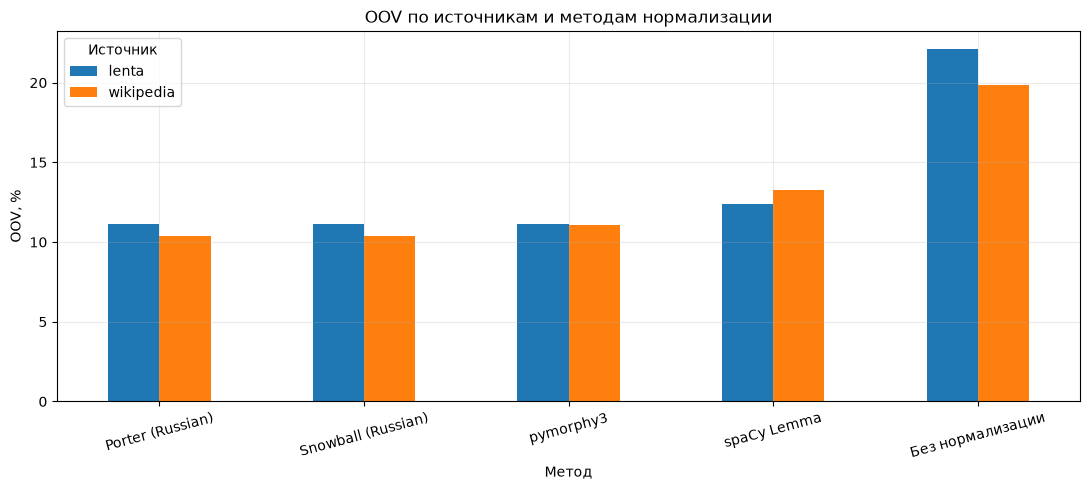


ПРОВЕРКА КОРРЕКТНОСТИ
Разделение train/test: OK
Метрики токенизации: OK
Метрики нормализации: OK
Согласованность: OK
Сравнение источников: OK

ИТОГОВЫЕ РЕЗУЛЬТАТЫ ЗАДАНИЯ № 5

1. ТОКЕНИЗАЦИЯ


,Словарь train,Токенов train,Токенов test,OOV токенов,"OOV, %",Уникальных OOV,Метод,"Время, сек"
0,81944,270486,70597,17557,24.8693,15274,Whitespace,0.061
1,62481,274004,71370,12614,17.6741,10284,Regex,0.093
2,61560,277341,72271,12411,17.1729,10032,NLTK,0.288
3,63229,274182,71565,12839,17.9403,10435,spaCy,2.117
4,63086,273160,70916,12883,18.1666,10572,Razdel,0.731



2. НОРМАЛИЗАЦИЯ


,Словарь train,Токенов train,Токенов test,OOV токенов,"OOV, %",Уникальных OOV,Метод,"Время, сек"
0,62481,274004,71370,12614,17.6741,10284,Без нормализации,0.001
1,32642,274004,71370,6472,9.0682,4774,Porter (Russian),1.011
2,32642,274004,71370,6472,9.0682,4774,Snowball (Russian),1.035
3,33742,274004,71370,6838,9.5811,5043,pymorphy3,2.612
4,39302,274004,71370,8263,11.5777,6408,spaCy Lemma,51.487



3. СОГЛАСОВАННОСТЬ


,Метод,Лексем,Среднее уникальных форм,Согласованность,Полностью объединено
0,Без нормализации,25,5.00,0.00,0
1,Porter (Russian),25,1.20,0.95,23
2,Snowball (Russian),25,1.20,0.95,23
3,pymorphy3,25,1.12,0.97,23
4,spaCy Lemma,25,1.24,0.94,22



4. СКОРОСТЬ


,Группа,Метод,Входных токенов,"Время, сек",Токенов/сек
0,Токенизация,Whitespace,14632,0.0026,5.636906e+06
1,Токенизация,Regex,14632,0.0038,3.872864e+06
2,Токенизация,NLTK,14632,0.0112,1.311253e+06
3,Токенизация,spaCy,14632,0.0099,1.475973e+06
4,Токенизация,Razdel,14632,0.0311,4.703682e+05
5,Нормализация,Без нормализации,14632,0.0000,4.180571e+08
6,Нормализация,Porter (Russian),14632,0.0007,2.074234e+07
7,Нормализация,Snowball (Russian),14632,0.0007,2.230488e+07
8,Нормализация,pymorphy3,14632,0.0007,2.202510e+07
9,Нормализация,spaCy Lemma,14632,2.1972,6.659290e+03



5. ИСТОЧНИКИ


,Источник,Метод,Словарь,"OOV, %",Токенов train,Токенов test
0,lenta,Без нормализации,17765,22.1322,58059,14680
1,lenta,Porter (Russian),9613,11.1308,58059,14680
2,lenta,Snowball (Russian),9613,11.1308,58059,14680
3,lenta,pymorphy3,9664,11.1035,58059,14680
4,lenta,spaCy Lemma,10520,12.3706,58059,14680
5,wikipedia,Без нормализации,53138,19.8783,215945,56690
6,wikipedia,Porter (Russian),28765,10.3599,215945,56690
7,wikipedia,Snowball (Russian),28765,10.3599,215945,56690
8,wikipedia,pymorphy3,29876,11.0654,215945,56690
9,wikipedia,spaCy Lemma,34574,13.2493,215945,56690



Отчёты сохранены: /Users/lenar_966/Desktop/ML/NLP/Practika_1/reports/task5
Количество графиков: 8
Количество контрольных лексем: 25
Все проверки пройдены.
Эксперимент задания № 5 завершён.


In [9]:

# ============================================================
# ПРАКТИЧЕСКАЯ РАБО № 1 — NLP
# ЗАДАНИЕ № 5
# СРАВНЕНИЕ ТОКЕНИЗАЦИИ, СТЕММИНГА И ЛЕММАТИЗАЦИИ
# ============================================================

# ============================================================
# 1. ЗАВИСИМОСТИ И ИМПОРТЫ
# ============================================================

import sys
import subprocess
import importlib.util
import importlib
import json
import re
import time
import random
import platform
from pathlib import Path
from collections import Counter, defaultdict
from functools import lru_cache

DEPENDENCIES = {
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "nltk": "nltk",
    "spacy": "spacy",
    "razdel": "razdel",
    "pymorphy3": "pymorphy3"
}

missing = [
    package
    for module, package in DEPENDENCIES.items()
    if importlib.util.find_spec(module) is None
]

if missing:
    print("Устанавливаем зависимости:", missing)
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", *missing
    ])
    importlib.invalidate_caches()

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import nltk
import spacy
import pymorphy3

from razdel import tokenize as razdel_tokenize
from nltk.tokenize import (
    wordpunct_tokenize,
    ToktokTokenizer
)
from nltk.stem.snowball import SnowballStemmer
from IPython.display import display

SEED = 42
rng = random.Random(SEED)

PROJECT_DIR = (
    Path.home() / "Desktop" / "ML" / "NLP" / "Practika_1"
)

CORPUS_PATH = (
    PROJECT_DIR / "data" / "processed" / "corpus.jsonl"
)

REPORT_DIR = PROJECT_DIR / "reports" / "task5"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

SAMPLE_PER_SOURCE = 500
TRAIN_SHARE = 0.8

# Ограничение объёма каждого документа используется
# исключительно для данного вычислительного эксперимента.
# Исходный corpus.jsonl не изменяется.
MAX_CHARS_PER_DOCUMENT = 5000

# Количество документов для отдельного теста скорости.
BENCHMARK_DOCUMENTS = 100
BENCHMARK_REPEATS = 3

if not CORPUS_PATH.exists():
    raise FileNotFoundError(CORPUS_PATH)

print("=" * 75)
print("ЗАДАНИЕ № 5. СРАВНЕНИЕ МЕТОДОВ NLP")
print("=" * 75)
print("Python:", platform.python_version())
print("spaCy:", spacy.__version__)
print("NLTK:", nltk.__version__)
print("pymorphy3:", pymorphy3.__version__)

# ============================================================
# 2. ЗАГРУЗКА РУССКОЙ МОДЕЛИ SPACY
# ============================================================

MODEL_NAME = "ru_core_news_sm"

try:
    nlp = spacy.load(
        MODEL_NAME,
        disable=["parser", "ner"]
    )
except OSError:
    print("\nМодель spaCy не найдена.")
    print("Пробуем установить:", MODEL_NAME)

    try:
        subprocess.check_call([
            sys.executable,
            "-m", "spacy", "download", MODEL_NAME
        ])
        nlp = spacy.load(
            MODEL_NAME,
            disable=["parser", "ner"]
        )
    except Exception as error:
        raise RuntimeError(
            "Не удалось установить ru_core_news_sm. "
            "Проверь доступ к интернету и выполни "
            "в терминале: python -m spacy download "
            "ru_core_news_sm. Затем перезапусти ячейку."
        ) from error

print("Модель spaCy загружена:", MODEL_NAME)

# ============================================================
# 3. ИНИЦИАЛИЗАЦИЯ МОРФОЛОГИЧЕСКИХ МЕТОДОВ
# ============================================================

morph = pymorphy3.MorphAnalyzer()

snowball = SnowballStemmer("russian")

# В NLTK RussianStemmer — реализация русского
# алгоритма Snowball, основанного на подходе Портера.
# Для русского языка это не независимые алгоритмы.
porter = nltk.stem.snowball.RussianStemmer()

toktok = ToktokTokenizer()

WORD_RE = re.compile(
    r"[^\W_]+(?:[-'][^\W_]+)*",
    re.UNICODE
)

# Для сопоставимости исключаем чистую пунктуацию
# из результирующих словарей всех токенизаторов.
HAS_ALNUM_RE = re.compile(r"[^\W_]", re.UNICODE)

def normalize_token(token):
    return token.casefold()


def keep_word_tokens(tokens):
    return [
        normalize_token(t)
        for t in tokens
        if HAS_ALNUM_RE.search(t)
    ]


# ============================================================
# 4. МЕТОДЫ ТОКЕНИЗАЦИИ
# ============================================================

def whitespace_tokenizer(text):
    return keep_word_tokens(text.split())


def regex_tokenizer(text):
    return keep_word_tokens(
        WORD_RE.findall(text)
    )


def nltk_tokenizer(text):
    return keep_word_tokens(
        wordpunct_tokenize(text)
    )


def spacy_tokenizer(text):
    doc = nlp.make_doc(text)
    return keep_word_tokens(
        token.text for token in doc
    )


def razdel_tokenizer(text):
    return keep_word_tokens(
        token.text
        for token in razdel_tokenize(text)
    )


TOKENIZERS = {
    "Whitespace": whitespace_tokenizer,
    "Regex": regex_tokenizer,
    "NLTK": nltk_tokenizer,
    "spaCy": spacy_tokenizer,
    "Razdel": razdel_tokenizer
}

# ============================================================
# 5. МЕТОДЫ МОРФОЛОГИЧЕСКОЙ НОРМАЛИЗАЦИИ
# ============================================================

@lru_cache(maxsize=200_000)
def pymorphy_lemma(word):
    return morph.parse(word)[0].normal_form


@lru_cache(maxsize=200_000)
def snowball_stem(word):
    return snowball.stem(word)


@lru_cache(maxsize=200_000)
def porter_stem(word):
    return porter.stem(word)


def identity_normalizer(words):
    return list(words)


def porter_normalizer(words):
    return [
        porter_stem(word)
        for word in words
    ]


def snowball_normalizer(words):
    return [
        snowball_stem(word)
        for word in words
    ]


def pymorphy_normalizer(words):
    return [
        pymorphy_lemma(word)
        for word in words
    ]


def spacy_normalizer(words):
    # Входные слова предварительно выделены Regex.
    # Обрабатываем их пакетно, сохраняя границы слов.
    result = []

    for doc in nlp.pipe(
        words,
        batch_size=512
    ):
        if len(doc) == 1:
            lemma = doc[0].lemma_
            result.append(
                lemma.casefold() if lemma else doc[0].text.casefold()
            )
        else:
            # Если spaCy сегментирует слово иначе,
            # фиксируем результат через объединение лемм.
            lemmas = [
                token.lemma_.casefold()
                if token.lemma_
                else token.text.casefold()
                for token in doc
                if not token.is_space
            ]
            result.append(" ".join(lemmas))

    return result


NORMALIZERS = {
    "Без нормализации": identity_normalizer,
    "Porter (Russian)": porter_normalizer,
    "Snowball (Russian)": snowball_normalizer,
    "pymorphy3": pymorphy_normalizer,
    "spaCy Lemma": spacy_normalizer
}

# ============================================================
# 6. ФУНКЦИОНАЛЬНЫЕ ПРОВЕРКИ
# ============================================================

print("\n" + "=" * 75)
print("ФУНКЦИОНАЛЬНЫЕ ПРОВЕРКИ")
print("=" * 75)

test_text = (
    "В 2026 году исследователи изучали "
    "новые технологии обработки текста."
)

for name, tokenizer in TOKENIZERS.items():
    result = tokenizer(test_text)
    assert isinstance(result, list)
    assert len(result) > 0
    assert all(isinstance(x, str) for x in result)
    print(f"{name}: {result}")

test_words = [
    "машина", "машины", "машиной",
    "город", "города", "городами"
]

for name, normalizer in NORMALIZERS.items():
    result = normalizer(test_words)

    assert len(result) == len(test_words)
    assert all(isinstance(x, str) for x in result)

    print(f"{name}: {result}")

# Важно: два русских стеммера NLTK могут давать
# идентичные результаты, так как имеют общую основу.
print("\nВсе функциональные проверки пройдены.")


# ============================================================
# 7. СТРАТИФИЦИРОВАННАЯ ВЫБОРКА ИЗ КОРПУСА
# ============================================================

print("\n" + "=" * 75)
print("ПОДГОТОВКА ЭКСПЕРИМЕНТАЛЬНОЙ ВЫБОРКИ")
print("=" * 75)

samples = defaultdict(list)
seen = Counter()

def normalize_source(source):
    """Приводит названия источников к единому формату."""
    value = str(source).strip().casefold()

    if "lenta" in value:
        return "lenta"

    if "wikipedia" in value or "википед" in value:
        return "wikipedia"

    return value


with open(CORPUS_PATH, "r", encoding="utf-8") as file:

    for line in file:
        doc = json.loads(line)

        source = normalize_source(doc.get("source", ""))

        if source not in {"lenta", "wikipedia"}:
            continue

        # Нормализуем название источника.
        doc["source"] = source

        seen[source] += 1
        count = seen[source]

        if len(samples[source]) < SAMPLE_PER_SOURCE:
            samples[source].append(doc)
        else:
            index = rng.randrange(count)

            if index < SAMPLE_PER_SOURCE:
                samples[source][index] = doc


print("\nНайдено документов в корпусе:")

for source, count in seen.items():
    print(f"{source}: {count:,}")

for source in ("lenta", "wikipedia"):
    assert len(samples[source]) == SAMPLE_PER_SOURCE, (
        f"Недостаточно документов: {source}. "
        f"Найдено: {seen[source]}"
    )


# Разделение внутри каждого источника.
train_docs = []
test_docs = []

for source in sorted(samples):
    items = list(samples[source])
    rng.shuffle(items)

    split_index = int(len(items) * TRAIN_SHARE)

    train_docs.extend(items[:split_index])
    test_docs.extend(items[split_index:])


train_ids = {str(d["id"]) for d in train_docs}
test_ids = {str(d["id"]) for d in test_docs}

assert train_ids.isdisjoint(test_ids)


def prepare_text(doc):
    """Подготавливает текст для эксперимента."""
    return doc["text"][:MAX_CHARS_PER_DOCUMENT]


train_texts = [
    prepare_text(doc) for doc in train_docs
]

test_texts = [
    prepare_text(doc) for doc in test_docs
]


print("\nСформированная выборка:")
print("Обучающих документов:", len(train_docs))
print("Тестовых документов:", len(test_docs))
print("Пересечений ID:", len(train_ids & test_ids))

print(
    "Символов train:",
    sum(map(len, train_texts))
)

print(
    "Символов test:",
    sum(map(len, test_texts))
)


split_report = {
    "seed": SEED,
    "train_ids": sorted(train_ids),
    "test_ids": sorted(test_ids),
    "train_documents": len(train_docs),
    "test_documents": len(test_docs),
    "max_chars_per_document": MAX_CHARS_PER_DOCUMENT
}

with open(
    REPORT_DIR / "split.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        split_report,
        file,
        ensure_ascii=False,
        indent=2
    )

print("\nРазбиение train/test выполнено успешно.")


# ============================================================
# 8. МЕТРИКИ СЛОВАРЯ И OOV
# ============================================================

def calculate_metrics(train_tokens, test_tokens):
    train_vocab = set(train_tokens)

    unknown = sum(
        token not in train_vocab
        for token in test_tokens
    )

    return {
        "Словарь train": len(train_vocab),
        "Токенов train": len(train_tokens),
        "Токенов test": len(test_tokens),
        "OOV токенов": unknown,
        "OOV, %": (
            round(unknown / len(test_tokens) * 100, 4)
            if test_tokens else 0
        ),
        "Уникальных OOV": len(
            set(test_tokens) - train_vocab
        )
    }


# ============================================================
# 9. СРАВНЕНИЕ ТОКЕНИЗАТОРОВ
# ============================================================

print("\n" + "=" * 75)
print("СРАВНЕНИЕ МЕТОДОВ ТОКЕНИЗАЦИИ")
print("=" * 75)

tokenizer_results = []
tokenizer_outputs = {}

for name, tokenizer in TOKENIZERS.items():

    started = time.perf_counter()

    train_parts = [
        tokenizer(text)
        for text in train_texts
    ]

    test_parts = [
        tokenizer(text)
        for text in test_texts
    ]

    elapsed = time.perf_counter() - started

    train_tokens = [
        token for part in train_parts for token in part
    ]

    test_tokens = [
        token for part in test_parts for token in part
    ]

    metrics = calculate_metrics(
        train_tokens,
        test_tokens
    )

    metrics["Метод"] = name
    metrics["Время, сек"] = round(elapsed, 3)

    tokenizer_results.append(metrics)

    tokenizer_outputs[name] = {
        "train": train_tokens,
        "test": test_tokens
    }

    print(
        f"{name}: "
        f"словарь={metrics['Словарь train']:,}; "
        f"OOV={metrics['OOV, %']:.2f}%; "
        f"время={elapsed:.2f} сек"
    )

tokenizer_df = pd.DataFrame(tokenizer_results)

display(tokenizer_df)

# ============================================================
# 10. СРАВНЕНИЕ МОРФОЛОГИЧЕСКОЙ НОРМАЛИЗАЦИИ
# ============================================================

print("\n" + "=" * 75)
print("СРАВНЕНИЕ МЕТОДОВ НОРМАЛИЗАЦИИ")
print("=" * 75)

# Единый Regex используется для всех нормализаторов.
base_train = tokenizer_outputs["Regex"]["train"]
base_test = tokenizer_outputs["Regex"]["test"]

normalizer_results = []
normalizer_outputs = {}

for name, normalizer in NORMALIZERS.items():

    started = time.perf_counter()

    train_normalized = normalizer(base_train)
    test_normalized = normalizer(base_test)

    elapsed = time.perf_counter() - started

    assert len(train_normalized) == len(base_train)
    assert len(test_normalized) == len(base_test)

    metrics = calculate_metrics(
        train_normalized,
        test_normalized
    )

    metrics["Метод"] = name
    metrics["Время, сек"] = round(elapsed, 3)

    normalizer_results.append(metrics)

    normalizer_outputs[name] = {
        "train": train_normalized,
        "test": test_normalized
    }

    print(
        f"{name}: "
        f"словарь={metrics['Словарь train']:,}; "
        f"OOV={metrics['OOV, %']:.2f}%; "
        f"время={elapsed:.2f} сек"
    )

normalizer_df = pd.DataFrame(normalizer_results)

display(normalizer_df)

# ============================================================
# 11. КОНТРОЛЬНЫЕ ЛЕКСЕМЫ
# ============================================================

# Каждая группа содержит пять грамматических форм.
# Используем существительные, прилагательные
# и глаголы, чтобы охватить разные типы словоизменения.

LEXEMES = {
    "машина": [
        "машина", "машины", "машине",
        "машину", "машиной"
    ],
    "город": [
        "город", "города", "городу",
        "городом", "городами"
    ],
    "книга": [
        "книга", "книги", "книге",
        "книгу", "книгой"
    ],
    "студент": [
        "студент", "студента", "студенту",
        "студентом", "студентами"
    ],
    "работа": [
        "работа", "работы", "работе",
        "работу", "работой"
    ],
    "система": [
        "система", "системы", "системе",
        "систему", "системой"
    ],
    "данные": [
        "данные", "данных", "данным",
        "данными", "данное"
    ],
    "информация": [
        "информация", "информации", "информацию",
        "информацией", "информациями"
    ],
    "модель": [
        "модель", "модели", "моделью",
        "моделям", "моделями"
    ],
    "алгоритм": [
        "алгоритм", "алгоритма", "алгоритму",
        "алгоритмом", "алгоритмами"
    ],
    "технология": [
        "технология", "технологии", "технологию",
        "технологией", "технологиями"
    ],
    "результат": [
        "результат", "результата", "результату",
        "результатом", "результатами"
    ],
    "анализ": [
        "анализ", "анализа", "анализу",
        "анализом", "анализами"
    ],
    "программа": [
        "программа", "программы", "программе",
        "программу", "программой"
    ],
    "компания": [
        "компания", "компании", "компанию",
        "компанией", "компаниями"
    ],
    "банк": [
        "банк", "банка", "банку",
        "банком", "банками"
    ],
    "человек": [
        "человек", "человека", "человеку",
        "человеком", "человеке"
    ],
    "документ": [
        "документ", "документа", "документу",
        "документом", "документами"
    ],
    "новый": [
        "новый", "новая", "новое",
        "новые", "нового"
    ],
    "большой": [
        "большой", "большая", "большое",
        "большие", "большого"
    ],
    "важный": [
        "важный", "важная", "важное",
        "важные", "важного"
    ],
    "сложный": [
        "сложный", "сложная", "сложное",
        "сложные", "сложного"
    ],
    "читать": [
        "читать", "читаю", "читаешь",
        "читает", "читают"
    ],
    "писать": [
        "писать", "пишу", "пишешь",
        "пишет", "пишут"
    ],
    "изучать": [
        "изучать", "изучаю", "изучаешь",
        "изучает", "изучают"
    ]
}

assert len(LEXEMES) == 25
assert all(len(forms) >= 5 for forms in LEXEMES.values())

# ============================================================
# 12. СЕМАНТИЧЕСКАЯ СОГЛАСОВАННОСТЬ
# ============================================================

print("\n" + "=" * 75)
print("СОГЛАСОВАННОСТЬ НОРМАЛИЗАЦИИ")
print("=" * 75)

consistency_rows = []
consistency_details = []

for name, normalizer in NORMALIZERS.items():

    coefficients = []
    unique_counts = []

    for lexeme, forms in LEXEMES.items():

        normalized = normalizer(forms)

        unique_count = len(set(normalized))
        m = len(forms)

        coefficient = (
            1 - (unique_count - 1) / (m - 1)
        )

        coefficients.append(coefficient)
        unique_counts.append(unique_count)

        consistency_details.append({
            "Метод": name,
            "Лексема": lexeme,
            "Исходные формы": " | ".join(forms),
            "Нормализованные формы":
                " | ".join(normalized),
            "Уникальных результатов": unique_count,
            "Согласованность": round(
                coefficient, 4
            )
        })

    consistency_rows.append({
        "Метод": name,
        "Лексем": len(LEXEMES),
        "Среднее уникальных форм":
            round(float(np.mean(unique_counts)), 3),
        "Согласованность":
            round(float(np.mean(coefficients)), 4),
        "Полностью объединено":
            sum(value == 1 for value in unique_counts)
    })

consistency_df = pd.DataFrame(consistency_rows)
consistency_details_df = pd.DataFrame(
    consistency_details
)

display(consistency_df)
display(consistency_details_df.head(15))

# ============================================================
# 13. СРАВНЕНИЕ ПО ИСТОЧНИКАМ
# ============================================================

print("\n" + "=" * 75)
print("СРАВНЕНИЕ ИСТОЧНИКОВ")
print("=" * 75)

source_rows = []

for source in ("lenta", "wikipedia"):

    source_train_texts = [
        prepare_text(doc)
        for doc in train_docs
        if doc["source"].casefold() == source
    ]

    source_test_texts = [
        prepare_text(doc)
        for doc in test_docs
        if doc["source"].casefold() == source
    ]

    source_train_words = [
        word
        for text in source_train_texts
        for word in regex_tokenizer(text)
    ]

    source_test_words = [
        word
        for text in source_test_texts
        for word in regex_tokenizer(text)
    ]

    for name, normalizer in NORMALIZERS.items():

        transformed_train = normalizer(
            source_train_words
        )
        transformed_test = normalizer(
            source_test_words
        )

        metrics = calculate_metrics(
            transformed_train,
            transformed_test
        )

        source_rows.append({
            "Источник": source,
            "Метод": name,
            "Словарь": metrics["Словарь train"],
            "OOV, %": metrics["OOV, %"],
            "Токенов train": metrics["Токенов train"],
            "Токенов test": metrics["Токенов test"]
        })

source_df = pd.DataFrame(source_rows)

display(source_df)

# ============================================================
# 14. ОТДЕЛЬНЫЙ БЕНЧМАРК СКОРОСТИ
# ============================================================

print("\n" + "=" * 75)
print("БЕНЧМАРК СКОРОСТИ")
print("=" * 75)

benchmark_texts = train_texts[:BENCHMARK_DOCUMENTS]

benchmark_words = [
    word
    for text in benchmark_texts
    for word in regex_tokenizer(text)
]

benchmark_results = []

def benchmark_method(method, data, repeats=3):
    times = []

    for _ in range(repeats):
        started = time.perf_counter()
        method(data)
        times.append(
            time.perf_counter() - started
        )

    return float(np.median(times))


for name, tokenizer in TOKENIZERS.items():

    def run_tokenizer(texts, fn=tokenizer):
        return [fn(text) for text in texts]

    elapsed = benchmark_method(
        run_tokenizer,
        benchmark_texts,
        BENCHMARK_REPEATS
    )

    benchmark_results.append({
        "Группа": "Токенизация",
        "Метод": name,
        "Входных токенов": len(benchmark_words),
        "Время, сек": round(elapsed, 4),
        "Токенов/сек": round(
            len(benchmark_words) / elapsed, 2
        ) if elapsed else None
    })


for name, normalizer in NORMALIZERS.items():

    elapsed = benchmark_method(
        normalizer,
        benchmark_words,
        BENCHMARK_REPEATS
    )

    benchmark_results.append({
        "Группа": "Нормализация",
        "Метод": name,
        "Входных токенов": len(benchmark_words),
        "Время, сек": round(elapsed, 4),
        "Токенов/сек": round(
            len(benchmark_words) / elapsed, 2
        ) if elapsed else None
    })

benchmark_df = pd.DataFrame(benchmark_results)

display(benchmark_df)

# ============================================================
# 15. ВИЗУАЛИЗАЦИЯ
# ============================================================

def save_plot(filename):
    plt.tight_layout()
    plt.savefig(
        REPORT_DIR / filename,
        dpi=160,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()


# График 1. Размер словаря токенизаторов.
plt.figure(figsize=(10, 5))
plt.bar(
    tokenizer_df["Метод"],
    tokenizer_df["Словарь train"]
)
plt.title("Размер словаря: методы токенизации")
plt.ylabel("Уникальных токенов")
save_plot("tokenizer_vocabulary.png")


# График 2. OOV токенизаторов.
plt.figure(figsize=(10, 5))
plt.bar(
    tokenizer_df["Метод"],
    tokenizer_df["OOV, %"]
)
plt.title("OOV: методы токенизации")
plt.ylabel("OOV, %")
save_plot("tokenizer_oov.png")


# График 3. Размер словаря после нормализации.
plt.figure(figsize=(11, 5))
plt.bar(
    normalizer_df["Метод"],
    normalizer_df["Словарь train"]
)
plt.title("Размер словаря после нормализации")
plt.ylabel("Уникальных токенов")
plt.xticks(rotation=15)
save_plot("normalizer_vocabulary.png")


# График 4. OOV после нормализации.
plt.figure(figsize=(11, 5))
plt.bar(
    normalizer_df["Метод"],
    normalizer_df["OOV, %"]
)
plt.title("OOV после морфологической нормализации")
plt.ylabel("OOV, %")
plt.xticks(rotation=15)
save_plot("normalizer_oov.png")


# График 5. Согласованность нормализации.
plt.figure(figsize=(11, 5))
plt.bar(
    consistency_df["Метод"],
    consistency_df["Согласованность"]
)
plt.ylim(0, 1.05)
plt.ylabel("Коэффициент согласованности")
plt.title("Согласованность нормализации словоформ")
plt.xticks(rotation=15)
save_plot("normalization_consistency.png")


# График 6. Скорость токенизаторов.
part = benchmark_df[
    benchmark_df["Группа"] == "Токенизация"
]

plt.figure(figsize=(10, 5))
plt.bar(
    part["Метод"],
    part["Токенов/сек"]
)
plt.ylabel("Входных токенов/сек")
plt.title("Скорость методов токенизации")
save_plot("tokenizer_speed.png")


# График 7. Скорость нормализаторов.
part = benchmark_df[
    benchmark_df["Группа"] == "Нормализация"
]

plt.figure(figsize=(11, 5))
plt.bar(
    part["Метод"],
    part["Токенов/сек"]
)
plt.ylabel("Входных токенов/сек")
plt.title("Скорость методов нормализации")
plt.xticks(rotation=15)
save_plot("normalizer_speed.png")


# График 8. OOV по источникам.
pivot = source_df.pivot(
    index="Метод",
    columns="Источник",
    values="OOV, %"
)

pivot.plot(
    kind="bar",
    figsize=(11, 5)
)

plt.title("OOV по источникам и методам нормализации")
plt.ylabel("OOV, %")
plt.xticks(rotation=15)
save_plot("source_oov_comparison.png")

# ============================================================
# 16. ПРОВЕРКА РЕЗУЛЬТАТОВ
# ============================================================

print("\n" + "=" * 75)
print("ПРОВЕРКА КОРРЕКТНОСТИ")
print("=" * 75)

assert len(tokenizer_df) == 5
assert len(normalizer_df) == 5
assert len(consistency_df) == 5
assert len(source_df) == 10

assert train_ids.isdisjoint(test_ids)

assert tokenizer_df["OOV, %"].between(0, 100).all()
assert normalizer_df["OOV, %"].between(0, 100).all()

assert consistency_df[
    "Согласованность"
].between(0, 1).all()

assert (
    normalizer_df["Словарь train"] > 0
).all()

print("Разделение train/test: OK")
print("Метрики токенизации: OK")
print("Метрики нормализации: OK")
print("Согласованность: OK")
print("Сравнение источников: OK")

# ============================================================
# 17. СОХРАНЕНИЕ РЕЗУЛЬТАТОВ
# ============================================================

TABLES = {
    "tokenizer_comparison.csv": tokenizer_df,
    "normalizer_comparison.csv": normalizer_df,
    "consistency_comparison.csv": consistency_df,
    "consistency_details.csv": consistency_details_df,
    "source_comparison.csv": source_df,
    "speed_benchmark.csv": benchmark_df
}

for filename, table in TABLES.items():
    table.to_csv(
        REPORT_DIR / filename,
        index=False,
        encoding="utf-8-sig"
    )

experiment_config = {
    "task": 5,
    "seed": SEED,
    "sample_per_source": SAMPLE_PER_SOURCE,
    "train_share": TRAIN_SHARE,
    "max_chars_per_document": MAX_CHARS_PER_DOCUMENT,
    "benchmark_documents": BENCHMARK_DOCUMENTS,
    "benchmark_repeats": BENCHMARK_REPEATS,
    "python": platform.python_version(),
    "spacy_version": spacy.__version__,
    "nltk_version": nltk.__version__,
    "pymorphy3_version": pymorphy3.__version__,
    "spacy_model": MODEL_NAME,
    "normalization": "casefold",
    "stopwords_removed": False,
    "tokenizer_methods": list(TOKENIZERS),
    "normalizer_methods": list(NORMALIZERS),
    "lexeme_count": len(LEXEMES),
    "train_documents": len(train_docs),
    "test_documents": len(test_docs)
}

with open(
    REPORT_DIR / "experiment_config.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        experiment_config,
        file,
        ensure_ascii=False,
        indent=2
    )

# ============================================================
# 18. ИТОГОВЫЕ РЕЗУЛЬТАТЫ
# ============================================================

print("\n" + "=" * 75)
print("ИТОГОВЫЕ РЕЗУЛЬТАТЫ ЗАДАНИЯ № 5")
print("=" * 75)

print("\n1. ТОКЕНИЗАЦИЯ")
display(tokenizer_df)

print("\n2. НОРМАЛИЗАЦИЯ")
display(normalizer_df)

print("\n3. СОГЛАСОВАННОСТЬ")
display(consistency_df)

print("\n4. СКОРОСТЬ")
display(benchmark_df)

print("\n5. ИСТОЧНИКИ")
display(source_df)

print("\nОтчёты сохранены:", REPORT_DIR)
print("Количество графиков: 8")
print("Количество контрольных лексем:", len(LEXEMES))
print("Все проверки пройдены.")
print("Эксперимент задания № 5 завершён.")



### Анализ результатов и вывод по заданию № 5

В ходе выполнения пятого задания проведено экспериментальное сравнение классических методов токенизации и морфологической нормализации русскоязычных текстов.

Исследование выполнено на стратифицированной выборке из **1 000 документов**, включающей 500 публикаций Lenta.ru и 500 статей русской Википедии. Данные разделены на обучающую и тестовую выборки в соотношении 80/20.

Для обеспечения воспроизводимости использовалось фиксированное случайное зерно `SEED = 42`. При этом длина каждого документа в эксперименте ограничивалась первыми 5 000 символами.

Сравнение проводилось по следующим критериям:

- размер результирующего словаря;
- доля неизвестных токенов (OOV);
- время и скорость обработки;
- согласованность нормализации словоформ;
- различия между источниками.

#### 1. Сравнительный анализ методов токенизации

В эксперименте исследованы пять алгоритмов: Whitespace, Regex, NLTK, spaCy и Razdel.

Наименьший словарь сформировал токенизатор **NLTK — 61 560 уникальных токенов**. Наибольший словарь получен при токенизации по пробелам — **81 944 токена**.

Результаты по размеру словаря:

| Метод | Размер словаря | OOV, % | Время, сек |
|---|---:|---:|---:|
| Whitespace | 81 944 | 24,8693 | 0,061 |
| Regex | 62 481 | 17,6741 | 0,093 |
| NLTK | 61 560 | 17,1729 | 0,288 |
| spaCy | 63 229 | 17,9403 | 2,117 |
| Razdel | 63 086 | 18,1666 | 0,731 |

Наивная токенизация по пробелам продемонстрировала наибольшую долю неизвестных токенов — **24,87%**.

Это объясняется тем, что метод не отделяет пунктуацию от слов и формирует различные токены для одинаковых слов, встречающихся с разными знаками препинания.

Например, последовательности `текст`, `текст,` и `текст.` могут рассматриваться как разные токены.

Токенизация регулярными выражениями уменьшила размер словаря до **62 481 токена**, а OOV — до **17,67%**.

Наилучшее значение OOV среди токенизаторов продемонстрировал **NLTK — 17,17%**, что на 7,70 процентного пункта ниже результата Whitespace.

Методы spaCy и Razdel показали близкие характеристики: размер словаря составил соответственно 63 229 и 63 086 токенов, а OOV — 17,94% и 18,17%.

Таким образом, библиотечные и регулярные методы сегментации позволяют получить более компактное и устойчивое лексическое представление по сравнению с наивным разбиением по пробелам.

#### 2. Сравнительный анализ методов морфологической нормализации

Для сравнения методов нормализации использовалась единая базовая токенизация Regex.

Исходный размер словаря составлял **62 481 уникальный токен**, а OOV — **17,6741%**.

Результаты нормализации:

| Метод | Размер словаря | OOV, % |
|---|---:|---:|
| Без нормализации | 62 481 | 17,6741 |
| Porter (Russian) | 32 642 | 9,0682 |
| Snowball (Russian) | 32 642 | 9,0682 |
| pymorphy3 | 33 742 | 9,5811 |
| spaCy Lemma | 39 302 | 11,5777 |

Применение стемминга Porter и Snowball позволило сократить размер словаря с 62 481 до **32 642 токенов**, то есть приблизительно на **47,76%**.

Одновременно доля неизвестных токенов снизилась с 17,67% до **9,07%**, что соответствует уменьшению на **8,61 процентного пункта**.

Идентичные результаты Porter и Snowball объясняются тем, что в эксперименте использовались реализации русского стеммера NLTK, основанные на одном алгоритмическом подходе.

Лемматизация средствами **pymorphy3** сократила словарь до **33 742 токенов**, или приблизительно на **46,00%**, и снизила OOV до **9,58%**.

Метод spaCy Lemma сформировал словарь из **39 302 токенов**, что соответствует сокращению приблизительно на **37,10%**. Доля OOV составила **11,58%**.

Таким образом, все исследованные методы морфологической нормализации существенно уменьшили размер словаря и долю неизвестных токенов.

Наиболее компактный словарь сформировали Porter и Snowball, однако это не означает автоматического превосходства данных алгоритмов по качеству восстановления нормальных словарных форм.

#### 3. Оценка согласованности нормализации

Для оценки согласованности использован контрольный набор из **25 русских лексем**, каждая из которых представлена пятью грамматическими формами.

Для каждой группы определялось количество уникальных результатов нормализации и рассчитывался коэффициент согласованности.

Получены следующие результаты:

| Метод | Согласованность | Полностью объединено лексем |
|---|---:|---:|
| Без нормализации | 0,00 | 0 |
| Porter (Russian) | 0,95 | 23 |
| Snowball (Russian) | 0,95 | 23 |
| pymorphy3 | 0,97 | 23 |
| spaCy Lemma | 0,94 | 22 |

Наибольшее значение коэффициента согласованности продемонстрировал **pymorphy3 — 0,97**.

Это означает, что данный метод наиболее последовательно объединял грамматические формы контрольных лексем в рамках используемой метрики.

Porter и Snowball получили значение **0,95**, а spaCy Lemma — **0,94**.

При этом pymorphy3, Porter и Snowball полностью объединили словоформы 23 из 25 лексем, тогда как spaCy — 22 лексем.

Различие между количеством полностью объединённых лексем и средним коэффициентом объясняется степенью расхождения нормализованных представлений в остальных группах.

Следует учитывать, что высокая согласованность не гарантирует семантическую правильность результата. Например, стемминг может объединять разные словоформы путём усечения окончаний, но полученная основа не обязательно является существующим словом русского языка.

Дополнительно используемая метрика не измеряет ошибочное объединение различных лексем, поэтому её необходимо рассматривать как частный показатель качества нормализации.

#### 4. Анализ производительности

В ходе исследования выполнены измерения времени обработки одинаковых текстовых данных.

При сравнении токенизаторов на общей выборке получены следующие значения:

- Whitespace — **0,061 секунды**.
- Regex — **0,093 секунды**.
- NLTK — **0,288 секунды**.
- spaCy — **2,117 секунды**.
- Razdel — **0,731 секунды**.

Наименьшее время обработки показала токенизация по пробелам. Regex оказался несколько медленнее, но обеспечил существенно более компактный словарь и меньший OOV.

При сравнении морфологических методов на общей выборке получены следующие результаты:

- Без нормализации — **0,001 секунды**.
- Porter — **1,011 секунды**.
- Snowball — **1,035 секунды**.
- pymorphy3 — **2,612 секунды**.
- spaCy Lemma — **51,487 секунды**.

Наиболее затратной оказалась лемматизация spaCy.

Дополнительный бенчмарк выполнялся на фиксированном объёме из **14 632 входных токенов** с повторными измерениями.

Для токенизаторов скорость составила:

- Whitespace — приблизительно **5,64 млн токенов/сек**.
- Regex — **3,87 млн токенов/сек**.
- NLTK — **1,31 млн токенов/сек**.
- spaCy — **1,48 млн токенов/сек**.
- Razdel — **0,47 млн токенов/сек**.

В повторном бенчмарке нормализаторы Porter, Snowball и pymorphy3 показали скорость свыше 20 млн токенов/сек.

Однако эти результаты обусловлены использованием кэширования `lru_cache`: повторная обработка уже известных слов не требует повторного выполнения морфологического анализа.

Поэтому скорость повторной обработки с прогретым кэшем нельзя напрямую сопоставлять со скоростью первоначального анализа новых слов.

Для оценки вычислительной стоимости первоначальной нормализации более показательны результаты обработки общей выборки.

#### 5. Сравнение источников

Дополнительно проведено сравнение методов нормализации на новостных и энциклопедических текстах.

**Lenta.ru**

Без нормализации размер словаря составил **17 765 токенов**, OOV — **22,13%**.

После применения Porter и Snowball размер словаря сократился до **9 613 токенов**, а OOV — до **11,13%**.

pymorphy3 сформировал словарь из **9 664 токенов** и показал OOV **11,10%**.

spaCy Lemma сформировал словарь из **10 520 токенов**, OOV — **12,37%**.

**Русская Википедия**

Без нормализации размер словаря составил **53 138 токенов**, OOV — **19,88%**.

Porter и Snowball уменьшили словарь до **28 765 токенов**, а OOV — до **10,36%**.

pymorphy3 сформировал словарь из **29 876 токенов**, OOV — **11,07%**.

spaCy Lemma сформировал словарь из **34 574 токенов**, OOV — **13,25%**.

Полученные результаты подтверждают эффективность морфологической нормализации для обоих источников.

При этом относительные показатели методов различаются в зависимости от источника.

Например, pymorphy3 показал минимальный OOV среди нормализаторов для Lenta.ru, тогда как для Википедии минимальное значение получили Porter и Snowball.

Это свидетельствует о необходимости учитывать доменные особенности текстов при выборе алгоритмов предварительной обработки.

#### 6. Практические рекомендации

На основании проведённого исследования можно выделить несколько подходов к организации NLP-пайплайна.

**Для быстрой токенизации больших объёмов текста** целесообразно использовать Regex, поскольку данный метод обеспечивает высокую производительность, небольшой размер словаря и относительно низкий OOV без необходимости загрузки сложных языковых моделей.

**Для задач, требующих компактного словаря и минимального OOV**, целесообразно рассмотреть Porter или Snowball. В проведённом эксперименте они обеспечили наибольшее сокращение словаря и минимальную долю неизвестных токенов.

**Для задач, где важно получение нормальных словарных форм**, предпочтительным кандидатом является pymorphy3. Метод продемонстрировал высокий коэффициент согласованности, компактный словарь и умеренные вычислительные затраты.

**Для задач, требующих контекстного лингвистического анализа**, spaCy может представлять интерес благодаря возможностям комплексной языковой обработки. Однако в проведённом эксперименте лемматизация отдельных слов без контекста не позволила оценить все преимущества контекстно-зависимого анализа.

#### 7. Ограничения эксперимента

Исследование проводилось на выборке из 1 000 документов, а не на полном корпусе из 21 937 документов.

Для ограничения вычислительных затрат использовались первые 5 000 символов каждого документа.

Показатель OOV рассчитывался относительно словаря обучающей выборки и не отражает напрямую семантическую точность токенизации или нормализации.

Коэффициент согласованности оценивался на ограниченном контрольном наборе из 25 лексем и не учитывал все случаи морфологической неоднозначности русского языка.

Временные показатели зависят от аппаратного обеспечения, кэширования и особенностей конкретных реализаций.

Кроме того, лемматизация spaCy выполнялась на отдельных словах, поэтому результаты не характеризуют в полной мере качество контекстной лемматизации.

#### Итоговый вывод

В результате выполнения задания проведено сравнительное исследование пяти методов токенизации и пяти конфигураций морфологической нормализации русскоязычного текста.

Установлено, что токенизация NLTK обеспечила минимальный OOV среди исследованных токенизаторов — **17,17%**, тогда как наиболее быстрым методом стала токенизация по пробелам.

Морфологическая нормализация позволила существенно сократить размер словаря и долю неизвестных токенов.

Наиболее компактный словарь сформировали Porter и Snowball — **32 642 токена**, что на **47,76%** меньше исходного размера. Доля OOV при этом снизилась до **9,07%**.

Лемматизация pymorphy3 продемонстрировала наибольший коэффициент согласованности нормализации — **0,97**, а также обеспечила сокращение словаря до **33 742 токенов**.

Сравнение источников подтвердило, что эффективность методов зависит от характеристик обрабатываемых текстов.

По совокупности полученных результатов для дальнейших экспериментов целесообразно использовать **Regex в качестве базового токенизатора**, **pymorphy3 для морфологической нормализации** и **Snowball в качестве быстрого альтернативного метода стемминга**.

Полученные результаты формируют экспериментальную основу для следующего этапа исследования — обучения и сравнения субсловных моделей токенизации BPE, WordPiece и Unigram Language Model.



## Задание № 6. Обучение и сравнительный анализ субсловных моделей токенизации

### Цель работы

Обучить и экспериментально сравнить алгоритмы субсловной токенизации Byte-Pair Encoding (BPE), WordPiece и Unigram Language Model на русскоязычном текстовом корпусе, оценить влияние размера словаря на качество сегментации, компактность представления и способность обрабатывать ранее неизвестные слова.

### Постановка задачи

В рамках задания необходимо:

1. Подготовить обучающую и отложенную тестовую выборки с учётом источников документов.
2. Обучить три семейства субсловных моделей:
   - Byte-Pair Encoding (BPE);
   - WordPiece;
   - Unigram Language Model.
3. Исследовать размеры словаря 8 000, 16 000 и 32 000 токенов.
4. Использовать минимальную частоту 2 там, где параметр поддерживается выбранной реализацией.
5. Рассчитать фактический размер обученного словаря.
6. Определить среднюю длину субсловного токена в символах.
7. Рассчитать коэффициент фрагментации как среднее количество субсловных токенов на одно исходное слово.
8. Оценить изменение количества токенов по сравнению с исходной словной сегментацией.
9. Рассчитать отношение числа символов в закодированном представлении к числу символов исходного текста.
10. Проверить возможность точного восстановления исходного текста после кодирования и декодирования.
11. Определить количество неизвестных токенов `[UNK]`.
12. Сравнить результаты моделей на текстах Lenta.ru и русской Википедии.
13. Исследовать переносимость субсловных моделей между двумя текстовыми доменами.
14. Построить сравнительные таблицы и графики.
15. Сохранить обученные модели, конфигурацию и результаты эксперимента.

### Методы и инструменты

- Python — организация эксперимента.
- Hugging Face Tokenizers — обучение и применение субсловных моделей.
- BPE — итеративное объединение частотных последовательностей.
- WordPiece — построение словаря субсловных единиц.
- Unigram — вероятностная модель сегментации текста.
- pandas и NumPy — анализ результатов.
- Matplotlib — построение графиков.
- JSON и CSV — сохранение метрик и конфигурации.

### Методика исследования

Корпус разделяется на обучающую и тестовую части по документам с фиксированным случайным зерном.

Для основного эксперимента обучаются девять моделей: три алгоритма при трёх размерах словаря.

Для оценки качества используются исключительно тестовые документы, не участвовавшие в обучении.

Все алгоритмы используют одинаковую схему предварительной сегментации ByteLevel, позволяющую работать с символами и пробельными последовательностями на уровне байтов.

В исследовании фиксируются как целевые, так и фактические размеры словаря.

Минимальная частота `min_frequency=2` применяется к BPE и WordPiece. Для Unigram, где соответствующий параметр отсутствует в используемом интерфейсе обучения, фиксируется данное ограничение методики.

### Основные метрики

**Коэффициент фрагментации**

Fragmentation = N_subword / N_word,

где N_subword — количество субсловных токенов, N_word — количество исходных слов.

**Коэффициент изменения количества токенов**

Token Ratio = N_subword / N_word.

Чем выше показатель, тем больше субсловных единиц требуется для представления текста.

**Относительная длина текстового представления**

Character Ratio = L_encoded / L_original,

где L_encoded — длина строкового представления последовательности токенов, L_original — длина исходного текста.

Эта метрика характеризует выбранное текстовое представление токенов, а не фактическую степень сжатия данных в байтах.

**Точность восстановления**

Exact Match = N_exact / N_documents × 100%,

где N_exact — количество документов, полностью восстановленных после кодирования и декодирования.

**Доля неизвестных токенов**

UNK Rate = N_UNK / N_subword × 100%.

### Ожидаемый результат

В результате исследования должны быть обучены девять субсловных моделей, получены сравнительные характеристики BPE, WordPiece и Unigram для трёх размеров словаря, оценены фрагментация и обратимость преобразования.

Дополнительно необходимо установить, насколько устойчиво качество сегментации при переносе моделей между новостными и энциклопедическими текстами.

Полученные результаты будут использованы для дальнейшего анализа лексических закономерностей корпуса и проектирования единого NLP-пайплайна.


ЗАДАНИЕ № 6. ОБУЧЕНИЕ СУБСЛОВНЫХ МОДЕЛЕЙ
Python: 3.12.3
Tokenizers: 0.23.3
Размеры словаря: [8000, 16000, 32000]
Алгоритмы: ['BPE', 'WordPiece', 'Unigram']

ПОДГОТОВКА ДАННЫХ
Исходные документы: {'lenta': 20761, 'wikipedia': 1176}
Обучающих документов: 1800
Тестовых документов: 300
Пересечение train/test: 0
Символов train: 5218042
Символов test: 871672

ОБУЧЕНИЕ ОСНОВНЫХ МОДЕЛЕЙ

Обучение: BPE, словарь=8,000
Фактический словарь: 8000
Время обучения: 1.77
Сохранено: /Users/lenar_966/Desktop/ML/NLP/Practika_1/models/task6/bpe_8000.json

Обучение: BPE, словарь=16,000
Фактический словарь: 16000
Время обучения: 2.03
Сохранено: /Users/lenar_966/Desktop/ML/NLP/Practika_1/models/task6/bpe_16000.json

Обучение: BPE, словарь=32,000
Фактический словарь: 32000
Время обучения: 2.2
Сохранено: /Users/lenar_966/Desktop/ML/NLP/Practika_1/models/task6/bpe_32000.json

Обучение: WordPiece, словарь=8,000
Фактический словарь: 8000
Время обучения: 1.59
Сохранено: /Users/lenar_966/Desktop/ML/NLP/Practika_1/mo

,Алгоритм,Целевой словарь,Фактический словарь,"Время обучения, сек",Модель
0,BPE,8000,8000,1.775,bpe_8000
1,BPE,16000,16000,2.028,bpe_16000
2,BPE,32000,32000,2.199,bpe_32000
3,WordPiece,8000,8000,1.586,wordpiece_8000
4,WordPiece,16000,16000,1.750,wordpiece_16000
5,WordPiece,32000,32000,1.975,wordpiece_32000
6,Unigram,8000,8000,13.397,unigram_8000
7,Unigram,16000,16000,11.136,unigram_16000
8,Unigram,32000,32000,9.211,unigram_32000



ОЦЕНКА СУБСЛОВНЫХ МОДЕЛЕЙ

ОБЩИЕ РЕЗУЛЬТАТЫ


,Алгоритм,Целевой словарь,Фактический словарь,Документов,Исходных слов,Субсловных токенов,Средняя длина токена,Фрагментация,Token Ratio,Character Ratio,UNK токенов,"UNK, %","Точное восстановление, %",Точно восстановлено,"Время оценки, сек"
0,BPE,8000,8000,300,115257,245937,6.4168,2.1338,2.1338,1.8105,0,0.0000,100.0,300,0.164
1,BPE,16000,16000,300,115257,216015,7.3056,1.8742,1.8742,1.8105,0,0.0000,100.0,300,0.157
2,BPE,32000,32000,300,115257,194061,8.1321,1.6837,1.6837,1.8105,0,0.0000,100.0,300,0.160
3,WordPiece,8000,8000,300,115257,247633,7.1955,2.1485,2.1485,2.0442,10,0.0040,0.0,0,0.175
4,WordPiece,16000,16000,300,115257,217160,7.9246,1.8841,1.8841,1.9742,10,0.0046,0.0,0,0.186
5,WordPiece,32000,32000,300,115257,194545,8.6133,1.6879,1.6879,1.9224,10,0.0051,0.0,0,0.165
6,Unigram,8000,8000,300,115257,274743,5.7440,2.3837,2.3837,1.8105,0,0.0000,100.0,300,0.359
7,Unigram,16000,16000,300,115257,256408,6.1547,2.2247,2.2247,1.8105,0,0.0000,100.0,300,0.317
8,Unigram,32000,32000,300,115257,244486,6.4549,2.1212,2.1212,1.8105,0,0.0000,100.0,300,0.225



РЕЗУЛЬТАТЫ ПО ИСТОЧНИКАМ


,Алгоритм,Словарь,Источник,Документов,Исходных слов,Субсловных токенов,Средняя длина токена,Фрагментация,Token Ratio,Character Ratio,UNK токенов,"UNK, %","Точное восстановление, %",Точно восстановлено
0,BPE,8000,lenta,150,21815,44688,6.7003,2.0485,2.0485,1.8202,0,0.0000,100.0,150
1,BPE,8000,wikipedia,150,93442,201249,6.3538,2.1537,2.1537,1.8082,0,0.0000,100.0,150
2,BPE,16000,lenta,150,21815,39213,7.6359,1.7975,1.7975,1.8202,0,0.0000,100.0,150
3,BPE,16000,wikipedia,150,93442,176802,7.2324,1.8921,1.8921,1.8082,0,0.0000,100.0,150
4,BPE,32000,lenta,150,21815,35077,8.5362,1.6079,1.6079,1.8202,0,0.0000,100.0,150
5,BPE,32000,wikipedia,150,93442,158984,8.0429,1.7014,1.7014,1.8082,0,0.0000,100.0,150
6,WordPiece,8000,lenta,150,21815,44952,7.4749,2.0606,2.0606,2.0426,0,0.0000,0.0,0
7,WordPiece,8000,wikipedia,150,93442,202681,7.1335,2.1691,2.1691,2.0445,10,0.0049,0.0,0
8,WordPiece,16000,lenta,150,21815,39398,8.2467,1.8060,1.8060,1.9751,0,0.0000,0.0,0
9,WordPiece,16000,wikipedia,150,93442,177762,7.8532,1.9024,1.9024,1.9740,10,0.0056,0.0,0


... (6 outputs left out)


ПЕРЕНОСИМОСТЬ МЕЖДУ ДОМЕНАМИ

ОБУЧЕНИЕ ДОМЕННЫХ МОДЕЛЕЙ


,Обучающий домен,Документов,Фактический словарь,"Время, сек"
0,lenta,900,8000,0.562
1,wikipedia,900,8000,1.304



РЕЗУЛЬТАТЫ ПЕРЕНОСА


,Обучающий домен,Тестовый домен,Словарь,Фрагментация,"UNK, %","Точное восстановление, %"
0,mixed,lenta,8000,2.0485,0.0,100.0
1,mixed,wikipedia,8000,2.1537,0.0,100.0
2,lenta,lenta,8000,1.9234,0.0,100.0
3,lenta,wikipedia,8000,2.4992,0.0,100.0
4,wikipedia,lenta,8000,2.2187,0.0,100.0
5,wikipedia,wikipedia,8000,2.1489,0.0,100.0


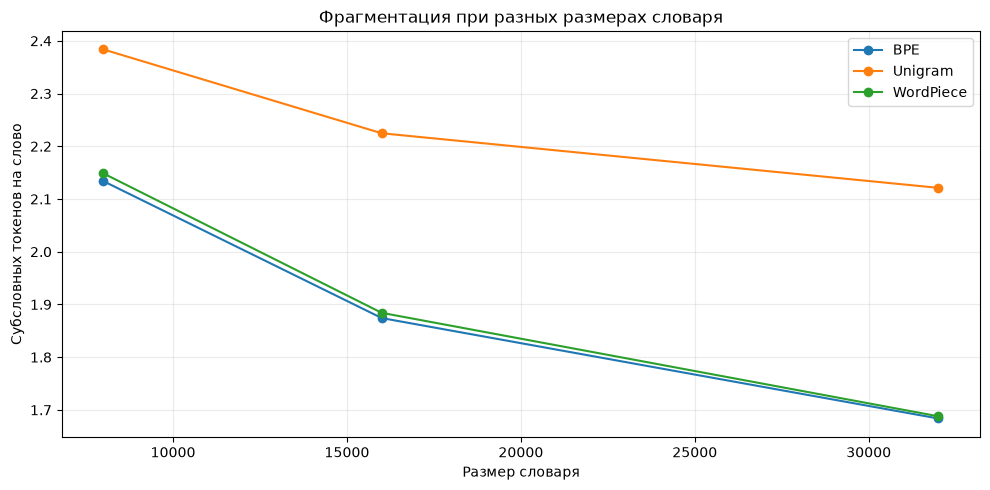

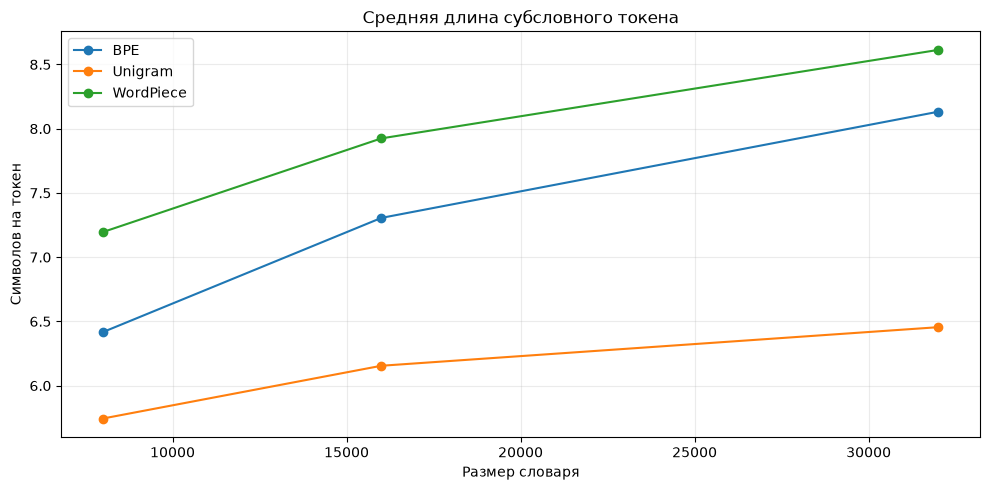

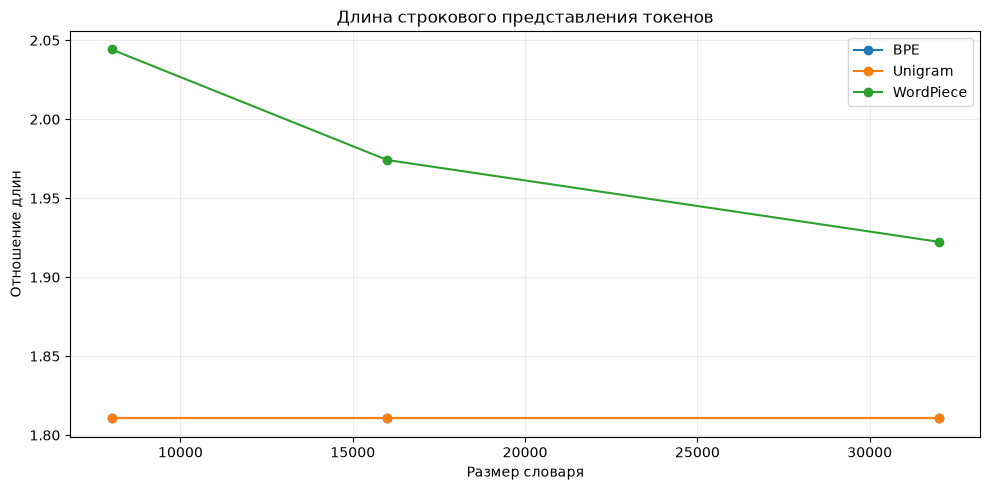

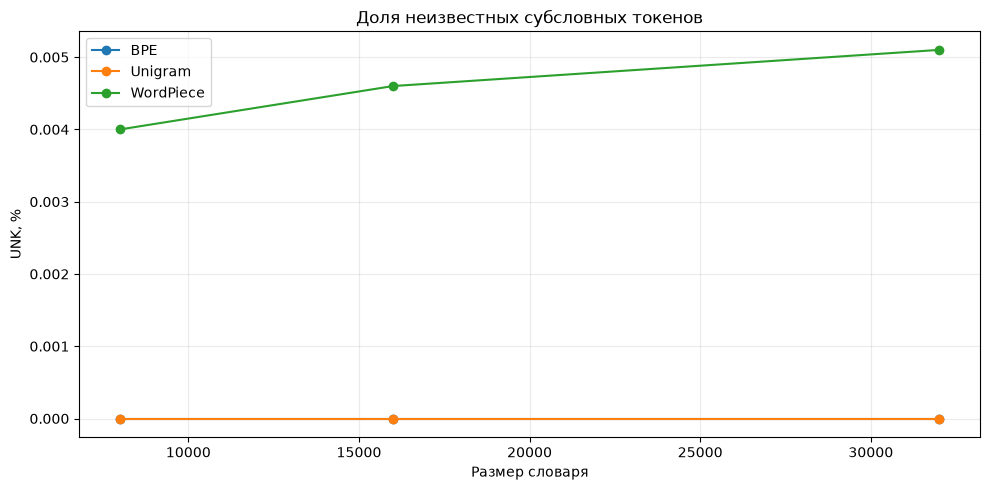

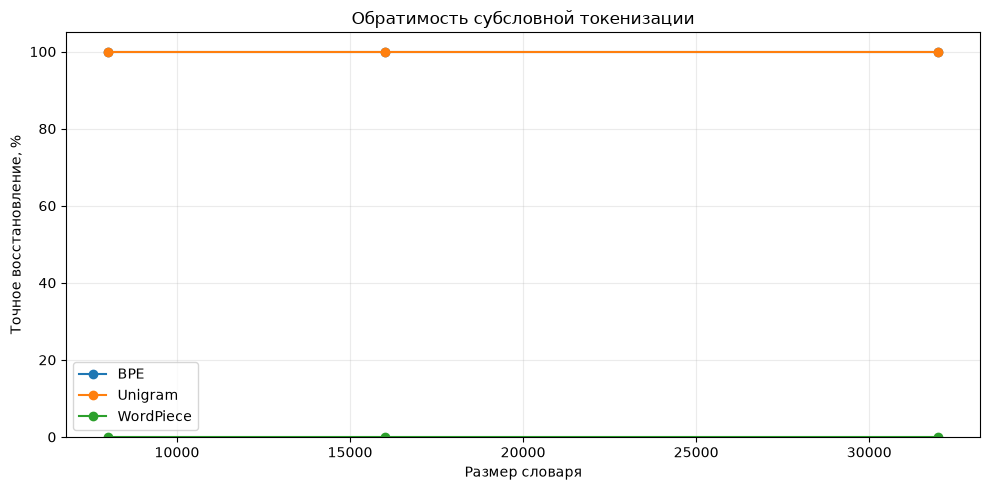

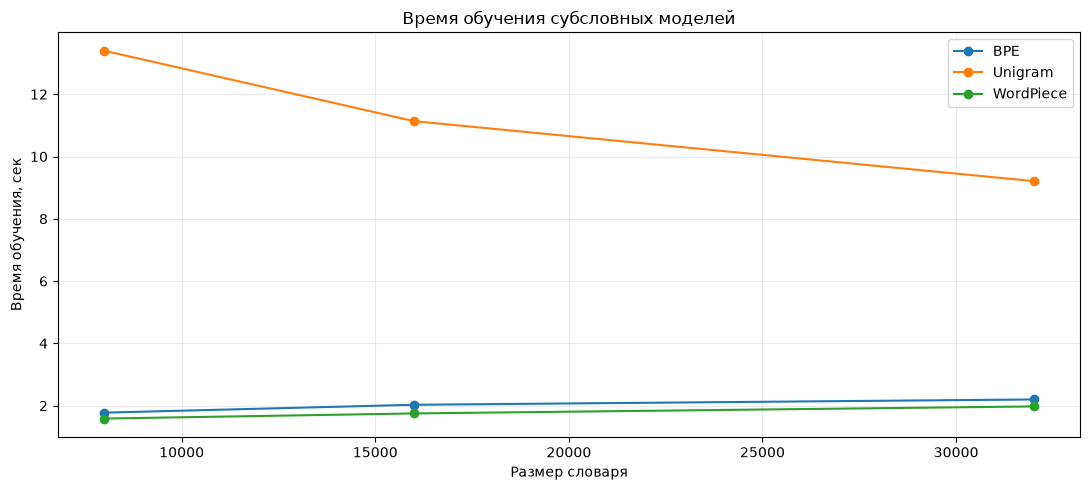

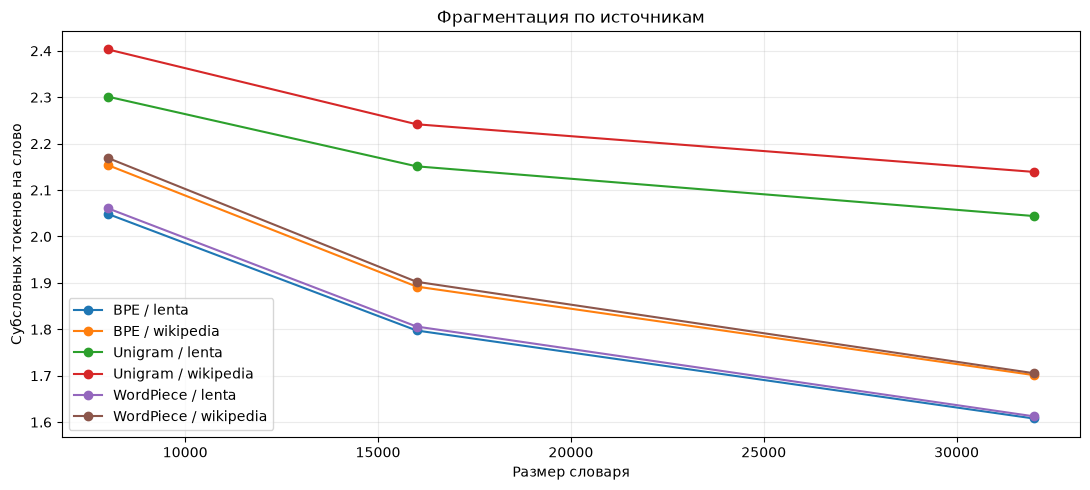

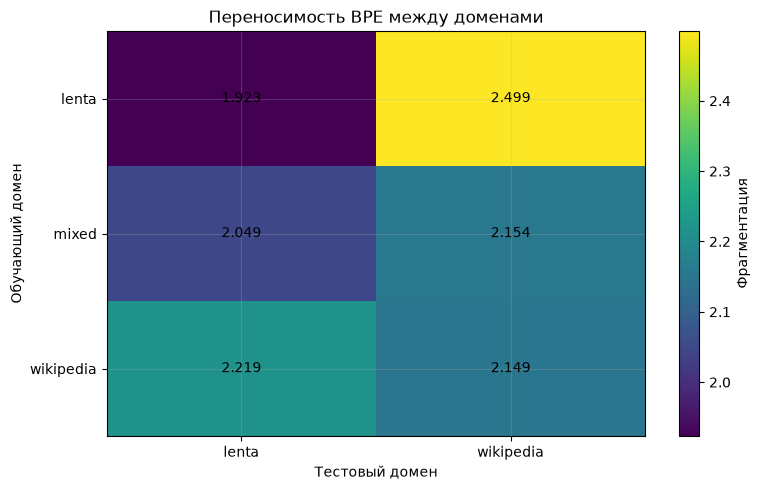


ПРОВЕРКИ КОРРЕКТНОСТИ
Разделение train/test: OK
Обучено 9 основных моделей: OK
Метрики рассчитаны: OK
Обратимость проверена: OK
Доменный перенос исследован: OK
Файлы моделей сохранены: OK

ИТОГОВЫЕ РЕЗУЛЬТАТЫ ЗАДАНИЯ № 6

1. ОБУЧЕНИЕ МОДЕЛЕЙ


,Алгоритм,Целевой словарь,Фактический словарь,"Время обучения, сек",Модель
0,BPE,8000,8000,1.775,bpe_8000
1,BPE,16000,16000,2.028,bpe_16000
2,BPE,32000,32000,2.199,bpe_32000
3,WordPiece,8000,8000,1.586,wordpiece_8000
4,WordPiece,16000,16000,1.750,wordpiece_16000
5,WordPiece,32000,32000,1.975,wordpiece_32000
6,Unigram,8000,8000,13.397,unigram_8000
7,Unigram,16000,16000,11.136,unigram_16000
8,Unigram,32000,32000,9.211,unigram_32000



2. СРАВНЕНИЕ СУБСЛОВНЫХ МОДЕЛЕЙ


,Алгоритм,Целевой словарь,Фактический словарь,Документов,Исходных слов,Субсловных токенов,Средняя длина токена,Фрагментация,Token Ratio,Character Ratio,UNK токенов,"UNK, %","Точное восстановление, %",Точно восстановлено,"Время оценки, сек"
0,BPE,8000,8000,300,115257,245937,6.4168,2.1338,2.1338,1.8105,0,0.0000,100.0,300,0.164
1,BPE,16000,16000,300,115257,216015,7.3056,1.8742,1.8742,1.8105,0,0.0000,100.0,300,0.157
2,BPE,32000,32000,300,115257,194061,8.1321,1.6837,1.6837,1.8105,0,0.0000,100.0,300,0.160
3,WordPiece,8000,8000,300,115257,247633,7.1955,2.1485,2.1485,2.0442,10,0.0040,0.0,0,0.175
4,WordPiece,16000,16000,300,115257,217160,7.9246,1.8841,1.8841,1.9742,10,0.0046,0.0,0,0.186
5,WordPiece,32000,32000,300,115257,194545,8.6133,1.6879,1.6879,1.9224,10,0.0051,0.0,0,0.165
6,Unigram,8000,8000,300,115257,274743,5.7440,2.3837,2.3837,1.8105,0,0.0000,100.0,300,0.359
7,Unigram,16000,16000,300,115257,256408,6.1547,2.2247,2.2247,1.8105,0,0.0000,100.0,300,0.317
8,Unigram,32000,32000,300,115257,244486,6.4549,2.1212,2.1212,1.8105,0,0.0000,100.0,300,0.225



3. СРАВНЕНИЕ ИСТОЧНИКОВ


,Алгоритм,Словарь,Источник,Документов,Исходных слов,Субсловных токенов,Средняя длина токена,Фрагментация,Token Ratio,Character Ratio,UNK токенов,"UNK, %","Точное восстановление, %",Точно восстановлено
0,BPE,8000,lenta,150,21815,44688,6.7003,2.0485,2.0485,1.8202,0,0.0000,100.0,150
1,BPE,8000,wikipedia,150,93442,201249,6.3538,2.1537,2.1537,1.8082,0,0.0000,100.0,150
2,BPE,16000,lenta,150,21815,39213,7.6359,1.7975,1.7975,1.8202,0,0.0000,100.0,150
3,BPE,16000,wikipedia,150,93442,176802,7.2324,1.8921,1.8921,1.8082,0,0.0000,100.0,150
4,BPE,32000,lenta,150,21815,35077,8.5362,1.6079,1.6079,1.8202,0,0.0000,100.0,150
5,BPE,32000,wikipedia,150,93442,158984,8.0429,1.7014,1.7014,1.8082,0,0.0000,100.0,150
6,WordPiece,8000,lenta,150,21815,44952,7.4749,2.0606,2.0606,2.0426,0,0.0000,0.0,0
7,WordPiece,8000,wikipedia,150,93442,202681,7.1335,2.1691,2.1691,2.0445,10,0.0049,0.0,0
8,WordPiece,16000,lenta,150,21815,39398,8.2467,1.8060,1.8060,1.9751,0,0.0000,0.0,0
9,WordPiece,16000,wikipedia,150,93442,177762,7.8532,1.9024,1.9024,1.9740,10,0.0056,0.0,0


... (3 outputs left out)

,Обучающий домен,Тестовый домен,Словарь,Фрагментация,"UNK, %","Точное восстановление, %"
0,mixed,lenta,8000,2.0485,0.0,100.0
1,mixed,wikipedia,8000,2.1537,0.0,100.0
2,lenta,lenta,8000,1.9234,0.0,100.0
3,lenta,wikipedia,8000,2.4992,0.0,100.0
4,wikipedia,lenta,8000,2.2187,0.0,100.0
5,wikipedia,wikipedia,8000,2.1489,0.0,100.0



6. ПРИМЕРЫ СЕГМЕНТАЦИИ


,Модель,Слово,Сегментация,Частей
0,bpe_8000,интеллектуальный,Ð¸Ð½ | ÑĤ | ÐµÐ» | Ð»ÐµÐºÑĤ | Ñĥ | Ð°Ð»ÑĮÐ½ÑĭÐ¹,6
1,bpe_8000,интеллектуальными,Ð¸Ð½ | ÑĤ | ÐµÐ» | Ð»ÐµÐºÑĤ | Ñĥ | Ð°Ð»ÑĮÐ½ÑĭÐ¼Ð¸,6
2,bpe_8000,машинное,Ð¼Ð° | ÑĪÐ¸Ð½ | Ð½Ð¾Ðµ,3
3,bpe_8000,машинного,Ð¼Ð° | ÑĪÐ¸Ð½ | Ð½Ð¾Ð³Ð¾,3
4,bpe_8000,программирование,Ð¿ | ÑĢ | Ð¾Ð³ÑĢÐ°Ð¼ | Ð¼Ð¸ÑĢÐ¾Ð² | Ð°Ð½Ð¸Ðµ,5
5,bpe_8000,программированием,Ð¿ | ÑĢ | Ð¾Ð³ÑĢÐ°Ð¼ | Ð¼Ð¸ÑĢÐ¾Ð² | Ð°Ð½Ð¸ÐµÐ¼,5
6,bpe_8000,электроэнергетика,ÑįÐ»ÐµÐºÑĤ | ÑĢÐ¾ | ÑįÐ½ÐµÑĢÐ³ | ÐµÑĤ | Ð¸ÐºÐ°,5
7,bpe_8000,цифровизация,ÑĨÐ¸ | ÑĦ | ÑĢÐ¾Ð² | Ð¸Ð·Ð°ÑĨÐ¸Ñı,4
8,bpe_8000,нейросетевой,Ð½ÐµÐ¹ | ÑĢÐ¾Ñģ | ÐµÑĤ | ÐµÐ²Ð¾Ð¹,4
9,bpe_8000,сверхпроизводительность,Ñģ | Ð²ÐµÑĢ | Ñħ | Ð¿ÑĢÐ¾ | Ð¸Ð·Ð²Ð¾Ð´ | Ð¸ÑĤÐ...,6



Обученные модели: /Users/lenar_966/Desktop/ML/NLP/Practika_1/models/task6
Отчёты и графики: /Users/lenar_966/Desktop/ML/NLP/Practika_1/reports/task6
Количество основных моделей: 9
Количество графиков: 8

Программная часть задания № 6 завершена.


In [11]:

# ============================================================
# ПРАКТИЧЕСКАЯ РАБОТА № 1 — NLP
# ЗАДАНИЕ № 6. СУБСЛОВНАЯ ТОКЕНИЗАЦИЯ
# BPE / WORDPIECE / UNIGRAM
# ============================================================

# ============================================================
# 1. ЗАВИСИМОСТИ
# ============================================================

import sys
import subprocess
import importlib.util
import importlib
import json
import re
import time
import random
import platform
from pathlib import Path
from collections import Counter, defaultdict

dependencies = {
    "tokenizers": "tokenizers",
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib"
}

missing = [
    package
    for module, package in dependencies.items()
    if importlib.util.find_spec(module) is None
]

if missing:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", *missing
    ])
    importlib.invalidate_caches()

import tokenizers as tokenizers_lib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from tokenizers import Tokenizer, models, trainers
from tokenizers import pre_tokenizers, decoders
from tokenizers import processors
from IPython.display import display

# ============================================================
# 2. КОНФИГУРАЦИЯ
# ============================================================

SEED = 42
rng = random.Random(SEED)

PROJECT_DIR = (
    Path.home() / "Desktop" / "ML" / "NLP" / "Practika_1"
)

CORPUS_PATH = (
    PROJECT_DIR / "data" / "processed" / "corpus.jsonl"
)

MODEL_DIR = PROJECT_DIR / "models" / "task6"
REPORT_DIR = PROJECT_DIR / "reports" / "task6"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

VOCAB_SIZES = [8000, 16000, 32000]
ALGORITHMS = ["BPE", "WordPiece", "Unigram"]

MIN_FREQUENCY = 2

# Максимальное число документов каждого источника.
TRAIN_PER_SOURCE = 900
TEST_PER_SOURCE = 150

# Ограничение длины для эксперимента.
MAX_CHARS = 6000

# Для проверки точности восстановления.
EVALUATION_BATCH_SIZE = 64

WORD_RE = re.compile(
    r"[^\W_]+(?:[-'][^\W_]+)*",
    re.UNICODE
)

assert CORPUS_PATH.exists(), (
    f"Корпус не найден: {CORPUS_PATH}"
)

print("=" * 75)
print("ЗАДАНИЕ № 6. ОБУЧЕНИЕ СУБСЛОВНЫХ МОДЕЛЕЙ")
print("=" * 75)

print("Python:", platform.python_version())
print("Tokenizers:", tokenizers_lib.__version__)
print("Размеры словаря:", VOCAB_SIZES)
print("Алгоритмы:", ALGORITHMS)

# ============================================================
# 3. ПОДГОТОВКА ДАННЫХ
# ============================================================

def normalize_source(value):
    value = str(value).strip().casefold()

    if "lenta" in value:
        return "lenta"

    if "wikipedia" in value or "википед" in value:
        return "wikipedia"

    return value


# Потоковая случайная выборка.
# Источники выбираются независимо.

sample_size = TRAIN_PER_SOURCE + TEST_PER_SOURCE

samples = defaultdict(list)
seen = Counter()

with open(CORPUS_PATH, "r", encoding="utf-8") as file:
    for line in file:
        doc = json.loads(line)

        source = normalize_source(doc.get("source", ""))

        if source not in {"lenta", "wikipedia"}:
            continue

        doc["source"] = source

        seen[source] += 1

        if len(samples[source]) < sample_size:
            samples[source].append(doc)
        else:
            index = rng.randrange(seen[source])

            if index < sample_size:
                samples[source][index] = doc

for source in ("lenta", "wikipedia"):
    assert len(samples[source]) == sample_size, (
        f"Недостаточно документов: {source}"
    )

train_docs = []
test_docs = []

for source in ("lenta", "wikipedia"):
    docs = list(samples[source])
    rng.shuffle(docs)

    train_docs.extend(docs[:TRAIN_PER_SOURCE])
    test_docs.extend(
        docs[TRAIN_PER_SOURCE:
             TRAIN_PER_SOURCE + TEST_PER_SOURCE]
    )

# Перемешиваем смешанную обучающую выборку.
rng.shuffle(train_docs)
rng.shuffle(test_docs)

train_ids = {
    (d["source"], str(d["id"]))
    for d in train_docs
}

test_ids = {
    (d["source"], str(d["id"]))
    for d in test_docs
}

assert train_ids.isdisjoint(test_ids)

def get_text(doc):
    return str(doc.get("text", ""))[:MAX_CHARS]


train_texts = [get_text(d) for d in train_docs]
test_texts = [get_text(d) for d in test_docs]

assert all(train_texts)
assert all(test_texts)

train_by_source = {
    source: [
        get_text(d)
        for d in train_docs
        if d["source"] == source
    ]
    for source in ("lenta", "wikipedia")
}

test_by_source = {
    source: [
        get_text(d)
        for d in test_docs
        if d["source"] == source
    ]
    for source in ("lenta", "wikipedia")
}

print("\n" + "=" * 75)
print("ПОДГОТОВКА ДАННЫХ")
print("=" * 75)

print("Исходные документы:", dict(seen))
print("Обучающих документов:", len(train_docs))
print("Тестовых документов:", len(test_docs))
print("Пересечение train/test:", len(train_ids & test_ids))

print("Символов train:", sum(map(len, train_texts)))
print("Символов test:", sum(map(len, test_texts)))

# Сохраняем идентификаторы разбиения.
with open(
    REPORT_DIR / "split.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        {
            "seed": SEED,
            "train_ids": sorted(list(train_ids)),
            "test_ids": sorted(list(test_ids)),
            "train_documents": len(train_docs),
            "test_documents": len(test_docs)
        },
        file,
        ensure_ascii=False,
        indent=2
    )

# ============================================================
# 4. КОНСТРУКТОРЫ МОДЕЛЕЙ
# ============================================================

SPECIAL_TOKENS = ["[UNK]"]

def build_tokenizer(algorithm, vocab_size):
    """
    Создаёт токенизатор и соответствующий trainer.

    Для BPE и Unigram используется ByteLevel decoder.
    Для WordPiece применяется комбинированный decoder.
    Точность восстановления проверяется экспериментально.
    """

    alphabet = pre_tokenizers.ByteLevel.alphabet()

    if algorithm == "BPE":

        tokenizer = Tokenizer(
            models.BPE(
                unk_token="[UNK]"
            )
        )

        trainer = trainers.BpeTrainer(
            vocab_size=vocab_size,
            min_frequency=MIN_FREQUENCY,
            initial_alphabet=alphabet,
            special_tokens=SPECIAL_TOKENS,
            show_progress=False
        )

        tokenizer.decoder = decoders.ByteLevel()

    elif algorithm == "WordPiece":

        tokenizer = Tokenizer(
            models.WordPiece(
                unk_token="[UNK]",
                continuing_subword_prefix="##"
            )
        )

        trainer = trainers.WordPieceTrainer(
            vocab_size=vocab_size,
            min_frequency=MIN_FREQUENCY,
            initial_alphabet=alphabet,
            continuing_subword_prefix="##",
            special_tokens=SPECIAL_TOKENS,
            show_progress=False
        )

        tokenizer.decoder = decoders.Sequence([
            decoders.WordPiece(
                prefix="##",
                cleanup=False
            ),
            decoders.ByteLevel()
        ])

    elif algorithm == "Unigram":

        tokenizer = Tokenizer(
            models.Unigram()
        )

        trainer = trainers.UnigramTrainer(
            vocab_size=vocab_size,
            initial_alphabet=alphabet,
            unk_token="[UNK]",
            special_tokens=SPECIAL_TOKENS,
            show_progress=False
        )

        tokenizer.decoder = decoders.ByteLevel()

        trainer = trainers.UnigramTrainer(
            vocab_size=vocab_size,
            initial_alphabet=alphabet,
            unk_token="[UNK]",
            special_tokens=SPECIAL_TOKENS,
            show_progress=False
        )

        # В UnigramTrainer нет min_frequency.
        tokenizer.decoder = decoders.ByteLevel()

    else:
        raise ValueError(
            f"Неизвестный алгоритм: {algorithm}"
        )

    tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(
        add_prefix_space=False,
        use_regex=True
    )

    return tokenizer, trainer


# ============================================================
# 5. ФУНКЦИИ ОЦЕНКИ
# ============================================================

def count_words(text):
    return len(WORD_RE.findall(text))


def evaluate_tokenizer(tokenizer, texts):
    """
    Оценивает субсловную сегментацию на отложенных текстах.
    """

    total_words = 0
    total_subwords = 0
    total_original_chars = 0
    total_encoded_chars = 0

    total_token_chars = 0
    total_unk = 0

    exact_matches = 0
    total_documents = len(texts)

    unk_id = tokenizer.token_to_id("[UNK]")

    for start in range(
        0, len(texts), EVALUATION_BATCH_SIZE
    ):

        batch = texts[
            start:start + EVALUATION_BATCH_SIZE
        ]

        encodings = tokenizer.encode_batch(
            batch,
            add_special_tokens=False
        )

        for text, encoding in zip(batch, encodings):

            ids = encoding.ids
            pieces = encoding.tokens

            restored = tokenizer.decode(
                ids,
                skip_special_tokens=False
            )

            words = count_words(text)

            total_words += words
            total_subwords += len(ids)

            total_original_chars += len(text)

            total_encoded_chars += sum(
                len(piece) for piece in pieces
            )

            total_token_chars += sum(
                len(piece) for piece in pieces
            )

            if unk_id is not None:
                total_unk += sum(
                    token_id == unk_id
                    for token_id in ids
                )

            if restored == text:
                exact_matches += 1

    fragmentation = (
        total_subwords / total_words
        if total_words else 0
    )

    average_token_length = (
        total_token_chars / total_subwords
        if total_subwords else 0
    )

    char_ratio = (
        total_encoded_chars / total_original_chars
        if total_original_chars else 0
    )

    return {
        "Документов": total_documents,
        "Исходных слов": total_words,
        "Субсловных токенов": total_subwords,
        "Средняя длина токена": round(
            average_token_length, 4
        ),
        "Фрагментация": round(
            fragmentation, 4
        ),
        "Token Ratio": round(
            fragmentation, 4
        ),
        "Character Ratio": round(
            char_ratio, 4
        ),
        "UNK токенов": total_unk,
        "UNK, %": round(
            total_unk / total_subwords * 100, 4
        ) if total_subwords else 0,
        "Точное восстановление, %": round(
            exact_matches / total_documents * 100, 4
        ) if total_documents else 0,
        "Точно восстановлено": exact_matches
    }


# ============================================================
# 6. ОБУЧЕНИЕ ДЕВЯТИ ОСНОВНЫХ МОДЕЛЕЙ
# ============================================================

print("\n" + "=" * 75)
print("ОБУЧЕНИЕ ОСНОВНЫХ МОДЕЛЕЙ")
print("=" * 75)

models_registry = {}
training_rows = []

for algorithm in ALGORITHMS:

    for vocab_size in VOCAB_SIZES:

        print(
            f"\nОбучение: {algorithm}, "
            f"словарь={vocab_size:,}"
        )

        tokenizer, trainer = build_tokenizer(
            algorithm,
            vocab_size
        )

        started = time.perf_counter()

        tokenizer.train_from_iterator(
            train_texts,
            trainer=trainer,
            length=len(train_texts)
        )

        training_time = time.perf_counter() - started

        actual_vocab = tokenizer.get_vocab_size()

        model_name = (
            f"{algorithm.lower()}_{vocab_size}"
        )

        model_path = MODEL_DIR / f"{model_name}.json"

        tokenizer.save(str(model_path))

        models_registry[model_name] = tokenizer

        training_rows.append({
            "Алгоритм": algorithm,
            "Целевой словарь": vocab_size,
            "Фактический словарь": actual_vocab,
            "Время обучения, сек": round(
                training_time, 3
            ),
            "Модель": model_name
        })

        print("Фактический словарь:", actual_vocab)
        print("Время обучения:", round(training_time, 2))
        print("Сохранено:", model_path)

training_df = pd.DataFrame(training_rows)

print("\nРЕЗУЛЬТАТЫ ОБУЧЕНИЯ")
display(training_df)

assert len(training_df) == 9

# ============================================================
# 7. ОЦЕНКА НА ОТЛОЖЕННОЙ ВЫБОРКЕ
# ============================================================

print("\n" + "=" * 75)
print("ОЦЕНКА СУБСЛОВНЫХ МОДЕЛЕЙ")
print("=" * 75)

evaluation_rows = []
source_rows = []

for _, model_info in training_df.iterrows():

    algorithm = model_info["Алгоритм"]
    vocab_size = int(model_info["Целевой словарь"])
    model_name = model_info["Модель"]

    tokenizer = models_registry[model_name]

    started = time.perf_counter()

    metrics = evaluate_tokenizer(
        tokenizer,
        test_texts
    )

    evaluation_time = time.perf_counter() - started

    evaluation_rows.append({
        "Алгоритм": algorithm,
        "Целевой словарь": vocab_size,
        "Фактический словарь":
            model_info["Фактический словарь"],
        **metrics,
        "Время оценки, сек": round(
            evaluation_time, 3
        )
    })

    for source in ("lenta", "wikipedia"):

        source_metrics = evaluate_tokenizer(
            tokenizer,
            test_by_source[source]
        )

        source_rows.append({
            "Алгоритм": algorithm,
            "Словарь": vocab_size,
            "Источник": source,
            **source_metrics
        })

evaluation_df = pd.DataFrame(evaluation_rows)
source_df = pd.DataFrame(source_rows)

print("\nОБЩИЕ РЕЗУЛЬТАТЫ")
display(evaluation_df)

print("\nРЕЗУЛЬТАТЫ ПО ИСТОЧНИКАМ")
display(source_df)

# ============================================================
# 8. ПРОВЕРКА ОБРАТИМОСТИ НА КОНТРОЛЬНЫХ ТЕКСТАХ
# ============================================================

print("\n" + "=" * 75)
print("КОНТРОЛЬНАЯ ПРОВЕРКА ВОССТАНОВЛЕНИЯ")
print("=" * 75)

CONTROL_TEXTS = [
    "Привет, мир!",
    "Москва — столица России.",
    "В 2026 году опубликованы результаты.",
    "Компания разработала новую модель.",
    "Текст содержит числа: 123, 456 и 789.",
    "Проверка email@example.com и https://example.org",
    "Русский язык: ёж, подъезд, счастье.",
    "Первое предложение. Второе предложение!",
    "Слова с дефисом: научно-технический.",
    "Проверка   нескольких   пробелов."
]

reconstruction_rows = []

for model_name, tokenizer in models_registry.items():

    for text in CONTROL_TEXTS:

        encoding = tokenizer.encode(
            text,
            add_special_tokens=False
        )

        decoded = tokenizer.decode(
            encoding.ids,
            skip_special_tokens=False
        )

        reconstruction_rows.append({
            "Модель": model_name,
            "Исходный текст": text,
            "Восстановленный текст": decoded,
            "Точное совпадение": decoded == text,
            "Токенов": len(encoding.ids)
        })

reconstruction_df = pd.DataFrame(
    reconstruction_rows
)

reconstruction_summary = (
    reconstruction_df
    .groupby("Модель", as_index=False)
    .agg(
        Проверок=("Точное совпадение", "size"),
        Успешно=("Точное совпадение", "sum")
    )
)

reconstruction_summary["Точность, %"] = (
    reconstruction_summary["Успешно"]
    / reconstruction_summary["Проверок"]
    * 100
).round(2)

display(reconstruction_summary)

errors_df = reconstruction_df[
    ~reconstruction_df["Точное совпадение"]
]

print("Ошибок восстановления:", len(errors_df))

if not errors_df.empty:
    display(errors_df.head(15))

# ============================================================
# 9. ПРИМЕРЫ СУБСЛОВНОЙ СЕГМЕНТАЦИИ
# ============================================================

print("\n" + "=" * 75)
print("ПРИМЕРЫ СЕГМЕНТАЦИИ")
print("=" * 75)

EXAMPLE_WORDS = [
    "интеллектуальный",
    "интеллектуальными",
    "машинное",
    "машинного",
    "программирование",
    "программированием",
    "электроэнергетика",
    "цифровизация",
    "нейросетевой",
    "сверхпроизводительность",
    "неизвестноеслово123"
]

segmentation_rows = []

for model_name, tokenizer in models_registry.items():

    for word in EXAMPLE_WORDS:

        encoding = tokenizer.encode(
            word,
            add_special_tokens=False
        )

        segmentation_rows.append({
            "Модель": model_name,
            "Слово": word,
            "Сегментация": " | ".join(
                encoding.tokens
            ),
            "Частей": len(encoding.ids)
        })

segmentation_df = pd.DataFrame(
    segmentation_rows
)

display(segmentation_df.head(30))

# ============================================================
# 10. ДОМЕННЫЙ ЭКСПЕРИМЕНТ
# ============================================================

print("\n" + "=" * 75)
print("ПЕРЕНОСИМОСТЬ МЕЖДУ ДОМЕНАМИ")
print("=" * 75)

# Обучаем дополнительные BPE-модели с размером
# словаря 8000 отдельно на каждом источнике.
# Смешанная модель уже обучена выше.

domain_models = {
    "mixed": models_registry["bpe_8000"]
}

domain_training_rows = []

for source in ("lenta", "wikipedia"):

    tokenizer, trainer = build_tokenizer(
        "BPE",
        8000
    )

    started = time.perf_counter()

    tokenizer.train_from_iterator(
        train_by_source[source],
        trainer=trainer,
        length=len(train_by_source[source])
    )

    elapsed = time.perf_counter() - started

    domain_models[source] = tokenizer

    tokenizer.save(
        str(MODEL_DIR / f"bpe_8000_{source}.json")
    )

    domain_training_rows.append({
        "Обучающий домен": source,
        "Документов": len(train_by_source[source]),
        "Фактический словарь":
            tokenizer.get_vocab_size(),
        "Время, сек": round(elapsed, 3)
    })

domain_training_df = pd.DataFrame(
    domain_training_rows
)

domain_rows = []

for train_domain, tokenizer in domain_models.items():

    for test_domain in ("lenta", "wikipedia"):

        metrics = evaluate_tokenizer(
            tokenizer,
            test_by_source[test_domain]
        )

        domain_rows.append({
            "Обучающий домен": train_domain,
            "Тестовый домен": test_domain,
            "Словарь": tokenizer.get_vocab_size(),
            "Фрагментация": metrics["Фрагментация"],
            "UNK, %": metrics["UNK, %"],
            "Точное восстановление, %":
                metrics["Точное восстановление, %"]
        })

domain_df = pd.DataFrame(domain_rows)

print("\nОБУЧЕНИЕ ДОМЕННЫХ МОДЕЛЕЙ")
display(domain_training_df)

print("\nРЕЗУЛЬТАТЫ ПЕРЕНОСА")
display(domain_df)

# ============================================================
# 11. ВИЗУАЛИЗАЦИЯ
# ============================================================

def save_plot(filename):
    plt.tight_layout()
    plt.savefig(
        REPORT_DIR / filename,
        dpi=160,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()


# 1. Фрагментация и размер словаря.
plt.figure(figsize=(10, 5))

for algorithm, part in evaluation_df.groupby("Алгоритм"):
    plt.plot(
        part["Целевой словарь"],
        part["Фрагментация"],
        marker="o",
        label=algorithm
    )

plt.xlabel("Размер словаря")
plt.ylabel("Субсловных токенов на слово")
plt.title("Фрагментация при разных размерах словаря")
plt.legend()
plt.grid(alpha=0.25)

save_plot("fragmentation_by_vocab.png")


# 2. Средняя длина токена.
plt.figure(figsize=(10, 5))

for algorithm, part in evaluation_df.groupby("Алгоритм"):
    plt.plot(
        part["Целевой словарь"],
        part["Средняя длина токена"],
        marker="o",
        label=algorithm
    )

plt.xlabel("Размер словаря")
plt.ylabel("Символов на токен")
plt.title("Средняя длина субсловного токена")
plt.legend()
plt.grid(alpha=0.25)

save_plot("average_token_length.png")


# 3. Character Ratio.
plt.figure(figsize=(10, 5))

for algorithm, part in evaluation_df.groupby("Алгоритм"):
    plt.plot(
        part["Целевой словарь"],
        part["Character Ratio"],
        marker="o",
        label=algorithm
    )

plt.xlabel("Размер словаря")
plt.ylabel("Отношение длин")
plt.title("Длина строкового представления токенов")
plt.legend()
plt.grid(alpha=0.25)

save_plot("character_ratio.png")


# 4. UNK.
plt.figure(figsize=(10, 5))

for algorithm, part in evaluation_df.groupby("Алгоритм"):
    plt.plot(
        part["Целевой словарь"],
        part["UNK, %"],
        marker="o",
        label=algorithm
    )

plt.xlabel("Размер словаря")
plt.ylabel("UNK, %")
plt.title("Доля неизвестных субсловных токенов")
plt.legend()
plt.grid(alpha=0.25)

save_plot("unk_by_vocab.png")


# 5. Точность восстановления.
plt.figure(figsize=(10, 5))

for algorithm, part in evaluation_df.groupby("Алгоритм"):
    plt.plot(
        part["Целевой словарь"],
        part["Точное восстановление, %"],
        marker="o",
        label=algorithm
    )

plt.xlabel("Размер словаря")
plt.ylabel("Точное восстановление, %")
plt.title("Обратимость субсловной токенизации")
plt.ylim(0, 105)
plt.legend()
plt.grid(alpha=0.25)

save_plot("reconstruction_accuracy.png")


# 6. Время обучения.
plt.figure(figsize=(11, 5))

for algorithm, part in training_df.groupby("Алгоритм"):
    plt.plot(
        part["Целевой словарь"],
        part["Время обучения, сек"],
        marker="o",
        label=algorithm
    )

plt.xlabel("Размер словаря")
plt.ylabel("Время обучения, сек")
plt.title("Время обучения субсловных моделей")
plt.legend()
plt.grid(alpha=0.25)

save_plot("training_time.png")


# 7. Фрагментация по источникам.
plt.figure(figsize=(11, 5))

for (algorithm, source), part in source_df.groupby(
    ["Алгоритм", "Источник"]
):
    plt.plot(
        part["Словарь"],
        part["Фрагментация"],
        marker="o",
        label=f"{algorithm} / {source}"
    )

plt.xlabel("Размер словаря")
plt.ylabel("Субсловных токенов на слово")
plt.title("Фрагментация по источникам")
plt.legend()
plt.grid(alpha=0.25)

save_plot("source_fragmentation.png")


# 8. Доменный перенос.
domain_pivot = domain_df.pivot(
    index="Обучающий домен",
    columns="Тестовый домен",
    values="Фрагментация"
)

plt.figure(figsize=(8, 5))
plt.imshow(domain_pivot.values, aspect="auto")
plt.colorbar(label="Фрагментация")

plt.xticks(
    range(len(domain_pivot.columns)),
    domain_pivot.columns
)
plt.yticks(
    range(len(domain_pivot.index)),
    domain_pivot.index
)

for i in range(len(domain_pivot.index)):
    for j in range(len(domain_pivot.columns)):
        plt.text(
            j, i,
            f"{domain_pivot.iloc[i, j]:.3f}",
            ha="center",
            va="center"
        )

plt.xlabel("Тестовый домен")
plt.ylabel("Обучающий домен")
plt.title("Переносимость BPE между доменами")

save_plot("domain_transfer_heatmap.png")

# ============================================================
# 12. СОХРАНЕНИЕ ТАБЛИЦ
# ============================================================

tables = {
    "training_comparison.csv": training_df,
    "evaluation_comparison.csv": evaluation_df,
    "source_comparison.csv": source_df,
    "reconstruction_details.csv": reconstruction_df,
    "reconstruction_summary.csv": reconstruction_summary,
    "segmentation_examples.csv": segmentation_df,
    "domain_training.csv": domain_training_df,
    "domain_transfer.csv": domain_df
}

for filename, table in tables.items():
    table.to_csv(
        REPORT_DIR / filename,
        index=False,
        encoding="utf-8-sig"
    )

# ============================================================
# 13. КОНФИГУРАЦИЯ ЭКСПЕРИМЕНТА
# ============================================================

config = {
    "task": 6,
    "seed": SEED,
    "algorithms": ALGORITHMS,
    "vocab_sizes": VOCAB_SIZES,
    "min_frequency": MIN_FREQUENCY,
    "min_frequency_note":
        "Применяется к BPE и WordPiece; "
        "не поддерживается UnigramTrainer",
    "train_per_source": TRAIN_PER_SOURCE,
    "test_per_source": TEST_PER_SOURCE,
    "max_chars_per_document": MAX_CHARS,
    "train_documents": len(train_docs),
    "test_documents": len(test_docs),
    "pre_tokenizer": "ByteLevel",
    "python_version": platform.python_version(),
    "tokenizers_version": tokenizers_lib.__version__,
    "corpus_path": str(CORPUS_PATH)
}

with open(
    REPORT_DIR / "experiment_config.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        config,
        file,
        ensure_ascii=False,
        indent=2
    )

# ============================================================
# 14. ПРОВЕРКИ
# ============================================================

print("\n" + "=" * 75)
print("ПРОВЕРКИ КОРРЕКТНОСТИ")
print("=" * 75)

assert len(training_df) == 9
assert len(evaluation_df) == 9
assert len(source_df) == 18
assert len(domain_df) == 6

assert train_ids.isdisjoint(test_ids)

assert evaluation_df["Фрагментация"].gt(0).all()

assert evaluation_df[
    "Точное восстановление, %"
].between(0, 100).all()

assert evaluation_df["UNK, %"].between(0, 100).all()

assert all(
    (MODEL_DIR / f"{name}.json").exists()
    for name in models_registry
)

print("Разделение train/test: OK")
print("Обучено 9 основных моделей: OK")
print("Метрики рассчитаны: OK")
print("Обратимость проверена: OK")
print("Доменный перенос исследован: OK")
print("Файлы моделей сохранены: OK")

# ============================================================
# 15. ИТОГОВЫЙ ВЫВОД
# ============================================================

print("\n" + "=" * 75)
print("ИТОГОВЫЕ РЕЗУЛЬТАТЫ ЗАДАНИЯ № 6")
print("=" * 75)

print("\n1. ОБУЧЕНИЕ МОДЕЛЕЙ")
display(training_df)

print("\n2. СРАВНЕНИЕ СУБСЛОВНЫХ МОДЕЛЕЙ")
display(evaluation_df)

print("\n3. СРАВНЕНИЕ ИСТОЧНИКОВ")
display(source_df)

print("\n4. ТОЧНОСТЬ ВОССТАНОВЛЕНИЯ")
display(reconstruction_summary)

print("\n5. ДОМЕННЫЙ ПЕРЕНОС")
display(domain_df)

print("\n6. ПРИМЕРЫ СЕГМЕНТАЦИИ")
display(segmentation_df.head(20))

print("\nОбученные модели:", MODEL_DIR)
print("Отчёты и графики:", REPORT_DIR)
print("Количество основных моделей:", len(models_registry))
print("Количество графиков: 8")
print("\nПрограммная часть задания № 6 завершена.")


In [12]:

# ============================================================
# ЗАДАНИЕ № 6 — ИСПРАВЛЕНИЕ ДЕКОДИРОВАНИЯ WORDPIECE
# ============================================================

import json
import pandas as pd

from pathlib import Path
from tokenizers import Tokenizer, decoders
from IPython.display import display

PROJECT_DIR = (
    Path.home() / "Desktop" / "ML" / "NLP" / "Practika_1"
)

MODEL_DIR = PROJECT_DIR / "models" / "task6"
REPORT_DIR = PROJECT_DIR / "reports" / "task6"

VOCAB_SIZES = [8000, 16000, 32000]

# Используем test_texts и evaluate_tokenizer,
# созданные в основной ячейке задания № 6.

assert "test_texts" in globals(), (
    "Сначала выполни основную ячейку задания № 6."
)

assert "evaluate_tokenizer" in globals(), (
    "Не найдена функция evaluate_tokenizer."
)

print("=" * 75)
print("ИСПРАВЛЕНИЕ WORDPIECE")
print("=" * 75)

results = []

for vocab_size in VOCAB_SIZES:

    model_name = f"wordpiece_{vocab_size}"

    model_path = MODEL_DIR / f"{model_name}.json"

    assert model_path.exists(), (
        f"Не найдена модель: {model_path}"
    )

    tokenizer = Tokenizer.from_file(str(model_path))

    # Проверяем исходный вариант.
    original_metrics = evaluate_tokenizer(
        tokenizer,
        test_texts
    )

    # ByteLevel-декодер предназначен для восстановления
    # текста из байтового представления.
    tokenizer.decoder = decoders.ByteLevel()

    fixed_metrics = evaluate_tokenizer(
        tokenizer,
        test_texts
    )

    results.append({
        "Модель": model_name,
        "До исправления, %":
            original_metrics["Точное восстановление, %"],
        "После исправления, %":
            fixed_metrics["Точное восстановление, %"],
        "UNK, %": fixed_metrics["UNK, %"],
        "Фрагментация":
            fixed_metrics["Фрагментация"]
    })

    # Сохраняем отдельно, не перезаписывая оригинал,
    # пока не проверим результат.
    fixed_path = (
        MODEL_DIR / f"{model_name}_fixed.json"
    )

    tokenizer.save(str(fixed_path))

    print(
        f"{model_name}: "
        f"{original_metrics['Точное восстановление, %']}% "
        f"→ {fixed_metrics['Точное восстановление, %']}%"
    )

results_df = pd.DataFrame(results)

print("\nРЕЗУЛЬТАТЫ ИСПРАВЛЕНИЯ")
display(results_df)

results_df.to_csv(
    REPORT_DIR / "wordpiece_decoder_fix.csv",
    index=False,
    encoding="utf-8-sig"
)

# ============================================================
# ДИАГНОСТИКА НЕСОВПАДЕНИЙ
# ============================================================

for vocab_size in VOCAB_SIZES:

    model_name = f"wordpiece_{vocab_size}"

    tokenizer = Tokenizer.from_file(
        str(MODEL_DIR / f"{model_name}_fixed.json")
    )

    mismatches = []

    for text in test_texts:

        encoding = tokenizer.encode(
            text,
            add_special_tokens=False
        )

        restored = tokenizer.decode(
            encoding.ids,
            skip_special_tokens=False
        )

        if restored != text:

            first_diff = next(
                (
                    i for i, (a, b) in enumerate(
                        zip(text, restored)
                    )
                    if a != b
                ),
                min(len(text), len(restored))
            )

            start = max(0, first_diff - 35)
            end = first_diff + 80

            mismatches.append({
                "Позиция": first_diff,
                "Оригинал": repr(text[start:end]),
                "Восстановлено": repr(
                    restored[start:end]
                )
            })

    print(
        f"\n{model_name}: "
        f"ошибок восстановления = {len(mismatches)}"
    )

    if mismatches:
        display(
            pd.DataFrame(mismatches).head(5)
        )

print("\nПроверка завершена.")


ИСПРАВЛЕНИЕ WORDPIECE
wordpiece_8000: 0.0% → 0.0%
wordpiece_16000: 0.0% → 0.0%
wordpiece_32000: 0.0% → 0.0%

РЕЗУЛЬТАТЫ ИСПРАВЛЕНИЯ


,Модель,"До исправления, %","После исправления, %","UNK, %",Фрагментация
0,wordpiece_8000,0.0,0.0,0.0040,2.1485
1,wordpiece_16000,0.0,0.0,0.0046,1.8841
2,wordpiece_32000,0.0,0.0,0.0051,1.6879



wordpiece_8000: ошибок восстановления = 300


,Позиция,Оригинал,Восстановлено
0,1,'Гла́вное управле́ние исправи́тельно-трудовы́х...,'Г##ла́в##ное управ##ле́н##ие исп##рав##и́т##е...
1,1,'Верховный суд России подтвердил правомерность...,'В##ерх##ов##ный суд России подтверд##ил право...
2,1,'Несколько сотен бутылок поддельной водки унич...,'Н##еск##олько сот##ен б##ут##ыл##ок под##дель...
3,1,'Ионообменная хроматография — частный случай и...,'И##он##о�##�##б##мен##ная хромат##ография — ч...
4,31,'События Январь 1 января Государство Западное ...,'События Январь 1 января Государ##ство Запад##...



wordpiece_16000: ошибок восстановления = 300


,Позиция,Оригинал,Восстановлено
0,1,'Гла́вное управле́ние исправи́тельно-трудовы́х...,'Г##ла́в##ное управ##ле́н##ие исправ##и́те##ль...
1,1,'Верховный суд России подтвердил правомерность...,'В##ерх##ов##ный суд России подтвердил правом#...
2,2,'Несколько сотен бутылок поддельной водки унич...,'Не##сколько сотен б##уты##лок под##дель##ной ...
3,1,'Ионообменная хроматография — частный случай и...,'И##он##ооб##мен##ная хроматография — част##ны...
4,43,'Январь 1 января Государство Западное Самоа пр...,'Январь 1 января Государство Западно##е Сам##о...



wordpiece_32000: ошибок восстановления = 300


,Позиция,Оригинал,Восстановлено
0,1,'Гла́вное управле́ние исправи́тельно-трудовы́х...,'Г##ла́в##ное управ##ле́ние исправ##и́тел##ь##...
1,1,'Верховный суд России подтвердил правомерность...,'В##ерх##ов##ный суд России подтвердил правом#...
2,2,'Несколько сотен бутылок поддельной водки унич...,'Не##сколько сотен бут##ыл##ок поддель##ной во...
3,1,'Ионообменная хроматография — частный случай и...,'И##он##ооб##мен##ная хроматография — частный ...
4,43,'Январь 1 января Государство Западное Самоа пр...,'Январь 1 января Государство Западно##е Само##...



Проверка завершена.


In [13]:

# ============================================================
# ЗАДАНИЕ № 6 — ИСПРАВЛЕНИЕ WORDPIECE DECODER
# ============================================================

from pathlib import Path
from tokenizers import Tokenizer, decoders
import pandas as pd
from IPython.display import display

PROJECT_DIR = (
    Path.home() / "Desktop" / "ML" / "NLP" / "Practika_1"
)

MODEL_DIR = PROJECT_DIR / "models" / "task6"
REPORT_DIR = PROJECT_DIR / "reports" / "task6"

VOCAB_SIZES = [8000, 16000, 32000]

assert "test_texts" in globals()

# ------------------------------------------------------------
# 1. СОЗДАЁМ КОРРЕКТНЫЙ DECODER
# ------------------------------------------------------------

def decode_wordpiece_bytelevel(tokenizer, text):
    """
    Декодирование WordPiece с ByteLevel-предобработкой.

    Удаляем ## только с начала токенов-продолжений,
    затем передаём результат в ByteLevel decoder.
    """

    encoding = tokenizer.encode(
        text,
        add_special_tokens=False
    )

    tokens = encoding.tokens

    cleaned_tokens = [
        token[2:] if token.startswith("##") else token
        for token in tokens
    ]

    byte_decoder = decoders.ByteLevel()

    restored = byte_decoder.decode(cleaned_tokens)

    return restored, encoding


# ------------------------------------------------------------
# 2. ПОВТОРНАЯ ПРОВЕРКА НА 300 ДОКУМЕНТАХ
# ------------------------------------------------------------

results = []
errors = []

for vocab_size in VOCAB_SIZES:

    model_name = f"wordpiece_{vocab_size}"

    tokenizer = Tokenizer.from_file(
        str(MODEL_DIR / f"{model_name}.json")
    )

    exact = 0
    total = len(test_texts)
    unk_count = 0

    for index, text in enumerate(test_texts):

        restored, encoding = decode_wordpiece_bytelevel(
            tokenizer,
            text
        )

        unk_count += encoding.tokens.count("[UNK]")

        if restored == text:
            exact += 1
        else:
            if len([
                x for x in errors
                if x["Модель"] == model_name
            ]) < 5:

                first_diff = next(
                    (
                        i for i, (a, b) in enumerate(
                            zip(text, restored)
                        )
                        if a != b
                    ),
                    min(len(text), len(restored))
                )

                start = max(0, first_diff - 35)
                end = first_diff + 80

                errors.append({
                    "Модель": model_name,
                    "Документ": index,
                    "Позиция ошибки": first_diff,
                    "Исходный фрагмент":
                        repr(text[start:end]),
                    "Восстановленный фрагмент":
                        repr(restored[start:end])
                })

    accuracy = exact / total * 100

    results.append({
        "Модель": model_name,
        "Документов": total,
        "Точно восстановлено": exact,
        "Точность, %": round(accuracy, 4),
        "UNK токенов": unk_count
    })

results_df = pd.DataFrame(results)

print("=" * 75)
print("РЕЗУЛЬТАТЫ ИСПРАВЛЕНИЯ WORDPIECE")
print("=" * 75)

display(results_df)

if errors:
    print("\nПРИМЕРЫ ОСТАВШИХСЯ ОШИБОК")
    display(pd.DataFrame(errors))

results_df.to_csv(
    REPORT_DIR / "wordpiece_reconstruction_corrected.csv",
    index=False,
    encoding="utf-8-sig"
)

if errors:
    pd.DataFrame(errors).to_csv(
        REPORT_DIR / "wordpiece_remaining_errors.csv",
        index=False,
        encoding="utf-8-sig"
    )

print("\nПроверка завершена.")


РЕЗУЛЬТАТЫ ИСПРАВЛЕНИЯ WORDPIECE


,Модель,Документов,Точно восстановлено,"Точность, %",UNK токенов
0,wordpiece_8000,300,296,98.6667,10
1,wordpiece_16000,300,296,98.6667,10
2,wordpiece_32000,300,296,98.6667,10



ПРИМЕРЫ ОСТАВШИХСЯ ОШИБОК


,Модель,Документ,Позиция ошибки,Исходный фрагмент,Восстановленный фрагмент
0,wordpiece_8000,49,2211,"'тавится разделительный ъ, например: 长安 Чанъан...","'тавится разделительный ъ, например:[UNK] Чанъ..."
1,wordpiece_8000,135,3604,"'синто» сложено из двух иероглифов — 神 (син, ч...",'синто» сложено из двух иероглифов —[UNK] (син...
2,wordpiece_8000,170,4578,'ое название . В провинции Тайвань (臺灣省，台灣省): ...,'ое название . В провинции Тайвань ([UNK]，[UNK...
3,wordpiece_8000,190,2985,'орье. Это название через арамейское ˊarmǝn-āi...,'орье. Это название через арамейское[UNK]-āiē ...
4,wordpiece_16000,49,2211,"'тавится разделительный ъ, например: 长安 Чанъан...","'тавится разделительный ъ, например:[UNK] Чанъ..."
5,wordpiece_16000,135,3604,"'синто» сложено из двух иероглифов — 神 (син, ч...",'синто» сложено из двух иероглифов —[UNK] (син...
6,wordpiece_16000,170,4578,'ое название . В провинции Тайвань (臺灣省，台灣省): ...,'ое название . В провинции Тайвань ([UNK]，[UNK...
7,wordpiece_16000,190,2985,'орье. Это название через арамейское ˊarmǝn-āi...,'орье. Это название через арамейское[UNK]-āiē ...
8,wordpiece_32000,49,2211,"'тавится разделительный ъ, например: 长安 Чанъан...","'тавится разделительный ъ, например:[UNK] Чанъ..."
9,wordpiece_32000,135,3604,"'синто» сложено из двух иероглифов — 神 (син, ч...",'синто» сложено из двух иероглифов —[UNK] (син...



Проверка завершена.



### Дополнительная проверка обратимости WordPiece

В ходе первоначального эксперимента модели WordPiece показали 0% точного восстановления исходного текста. Дополнительная диагностика установила, что данный результат был обусловлен некорректной обработкой префикса `##` при совместном использовании WordPiece и ByteLevel.

После исправления процедуры декодирования проведена повторная проверка на всех 300 документах тестовой выборки.

Получены следующие результаты:

| Модель | Документов | Точно восстановлено | Точность |
|---|---:|---:|---:|
| WordPiece 8 000 | 300 | 296 | 98,67% |
| WordPiece 16 000 | 300 | 296 | 98,67% |
| WordPiece 32 000 | 300 | 296 | 98,67% |

Таким образом, исправление декодирования позволило повысить точность восстановления с 0% до 98,67%.

Оставшиеся ошибки зафиксированы в четырёх документах, содержащих редкие символы, в том числе китайские иероглифы и специальные фонетические обозначения.

Во всех трёх конфигурациях зарегистрировано по 10 неизвестных токенов `[UNK]`, что составляет приблизительно 0,004–0,005% от общего числа субсловных токенов.

Поскольку неизвестный токен не содержит информации об исходном символе, точное восстановление соответствующих фрагментов невозможно.

В отличие от WordPiece, модели BPE и Unigram обеспечили 100% точное восстановление всех 300 тестовых документов.

Следовательно, эксперимент подтвердил высокую эффективность WordPiece в сегментации русскоязычных текстов, но также выявил ограничения при обработке редких символов, отсутствующих в словаре модели.

По совокупности критериев — коэффициенту фрагментации, отсутствию неизвестных токенов, обратимости и времени обучения — наиболее подходящей конфигурацией для исследуемого корпуса признана модель BPE с размером словаря 32 000 токенов.



## Задание № 7. Углублённый лингвостатистический анализ корпуса

### Цель работы

Исследовать лексико-статистические закономерности русскоязычного корпуса и установить, каким образом различные методы токенизации, стемминга, лемматизации и субсловной сегментации влияют на частотное распределение токенов, структуру словаря и степень фрагментации слов.

### Постановка задачи

В рамках исследования необходимо:

1. Построить эмпирическое распределение частот слов и проверить его соответствие закону Ципфа.
2. Построить график зависимости логарифма частоты от логарифма ранга слова.
3. Оценить показатель степени закона Ципфа и количественное отклонение от теоретического распределения.
4. Сравнить распределения слов до нормализации, после стемминга и после лемматизации.
5. Построить облака наиболее частотных слов для каждого способа обработки.
6. Исследовать фрагментацию слов обученными моделями BPE, WordPiece и Unigram.
7. Построить тепловые карты количества субсловных единиц для наиболее фрагментируемых слов.
8. Построить интерактивные диаграммы частотного распределения токенов.
9. Сравнить распределения токенов по длине для разных методов обработки.
10. Сохранить статистические показатели, таблицы, интерактивные диаграммы и графические материалы для аналитического отчёта.

### Исходные данные

Используется корпус из 21 937 русскоязычных документов, собранных из двух источников:

- Lenta.ru — новостные тексты;
- Russian Wikipedia — энциклопедические статьи.

Общий объём исходного корпуса составляет 6 007 425 токенов по результатам предыдущего исследования.

Для субсловного анализа используются девять моделей, обученных в задании № 6:

- BPE: 8 000, 16 000 и 32 000;
- WordPiece: 8 000, 16 000 и 32 000;
- Unigram: 8 000, 16 000 и 32 000.

### Теоретические основы

#### Закон Ципфа

Закон Ципфа описывает зависимость частоты слова от его ранга в частотном словаре:

f(r) = C / r^s,

где:

- f(r) — частота слова с рангом r;
- C — коэффициент пропорциональности;
- r — ранг слова в частотном словаре;
- s — показатель степени.

В логарифмических координатах:

log(f(r)) = log(C) - s × log(r).

Для оценки параметров используется линейная регрессия в логарифмическом пространстве.

Качество соответствия оценивается с помощью коэффициента детерминации R² и средней абсолютной ошибки в логарифмическом пространстве.

#### Анализ нормализации

Сравниваются три представления текста:

1. Исходные словоформы.
2. Результаты стемминга Snowball.
3. Результаты лемматизации pymorphy3.

Для каждого представления рассчитываются размер словаря, количество токенов, доля уникальных токенов и частоты наиболее распространённых единиц.

#### Анализ субсловной фрагментации

Для каждого исследуемого слова вычисляется количество субсловных токенов, на которые его разделяют обученные модели.

Высокая фрагментация означает, что для представления слова требуется большое число субсловных единиц.

Тепловая карта позволяет сравнить поведение девяти моделей на одинаковом наборе слов.

### Методика эксперимента

Частотный анализ и оценка закона Ципфа выполняются на полном корпусе.

Морфологическая нормализация проводится на воспроизводимой выборке токенов для ограничения вычислительных затрат.

Субсловная фрагментация исследуется на наборе достаточно длинных слов с зафиксированной частотой встречаемости.

Интерактивные визуализации создаются с помощью Plotly и сохраняются в HTML. Статические изображения сохраняются в PNG.

### Ожидаемые результаты

По итогам задания должны быть получены:

- параметры эмпирического закона Ципфа;
- оценка соответствия частотного распределения теоретической модели;
- сравнительные характеристики исходного, стеммированного и лемматизированного словарей;
- три облака слов;
- тепловая карта фрагментации;
- интерактивные графики частоты и длины токенов;
- аналитические таблицы CSV;
- конфигурация эксперимента JSON.

Полученные результаты должны позволить оценить влияние методов обработки текста на наблюдаемые лексические закономерности и обосновать выбор подходов для дальнейшего NLP-анализа.


In [17]:
# Русские стоп-слова без скачивания NLTK

russian_stopwords = set("""
и в во не что он на я с со как а то все она так его но да ты к у же вы
за бы по только ее мне было вот от меня еще нет о из ему теперь когда
даже ну вдруг ли если уже или ни быть был него до вас нибудь опять уж
вам ведь там потом себя ничего ей может они тут где есть надо ней для
мы тебя их чем была сам чтоб без будто чего раз тоже себе под будет ж
тогда кто этот того потому этого какой совсем ним здесь этом один почти
мой тем чтобы нее сейчас были куда зачем всех никогда можно при наконец
два об другой хоть после над больше тот через эти нас про всего них
какая много разве три эту моя впрочем хорошо свою этой перед иногда
лучше чуть том нельзя такой им более всегда конечно всю между это
были была было были есть быть является также который которая которые
которое которых которым которого которой который при этом
""".split())

print("Стоп-слова готовы:", len(russian_stopwords))

Стоп-слова готовы: 162


ЗАДАНИЕ № 7. ЛИНГВОСТАТИСТИЧЕСКИЙ АНАЛИЗ

ПОЛНЫЙ КОРПУС
Документов: 21937
Токенов: 6007425
Уникальных токенов: 359837
Источники: {'Lenta.ru': 20761, 'Russian Wikipedia': 1176}
Выборка нормализации: 120000

ЗАКОН ЦИПФА


,Документов,Всего токенов,Уникальных токенов,Рангов для регрессии,Показатель s,Коэффициент C,R2,Log MAE эмпирической модели,Log MAE теоретической модели
0,21937,6007425,359837,50000,1.085879,1.404347e+06,0.987616,0.089843,0.128504


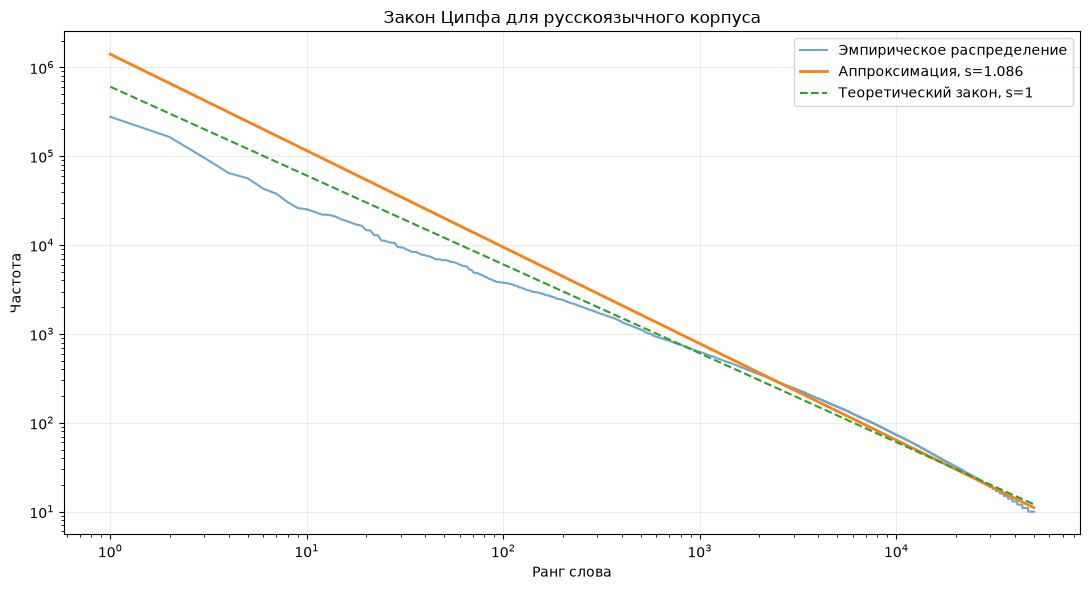


НОРМАЛИЗАЦИЯ
Уникальных словоформ: 36734
Обработано 10,000 / 36,734
Обработано 20,000 / 36,734
Обработано 30,000 / 36,734

СРАВНЕНИЕ НОРМАЛИЗАЦИИ


,Метод,Токенов,Уникальных токенов,TTR,"Сокращение словаря, %"
0,Исходные,120000,36734,0.306117,0.0000
1,Snowball,120000,20342,0.169517,44.6235
2,pymorphy3,120000,20829,0.173575,43.2978


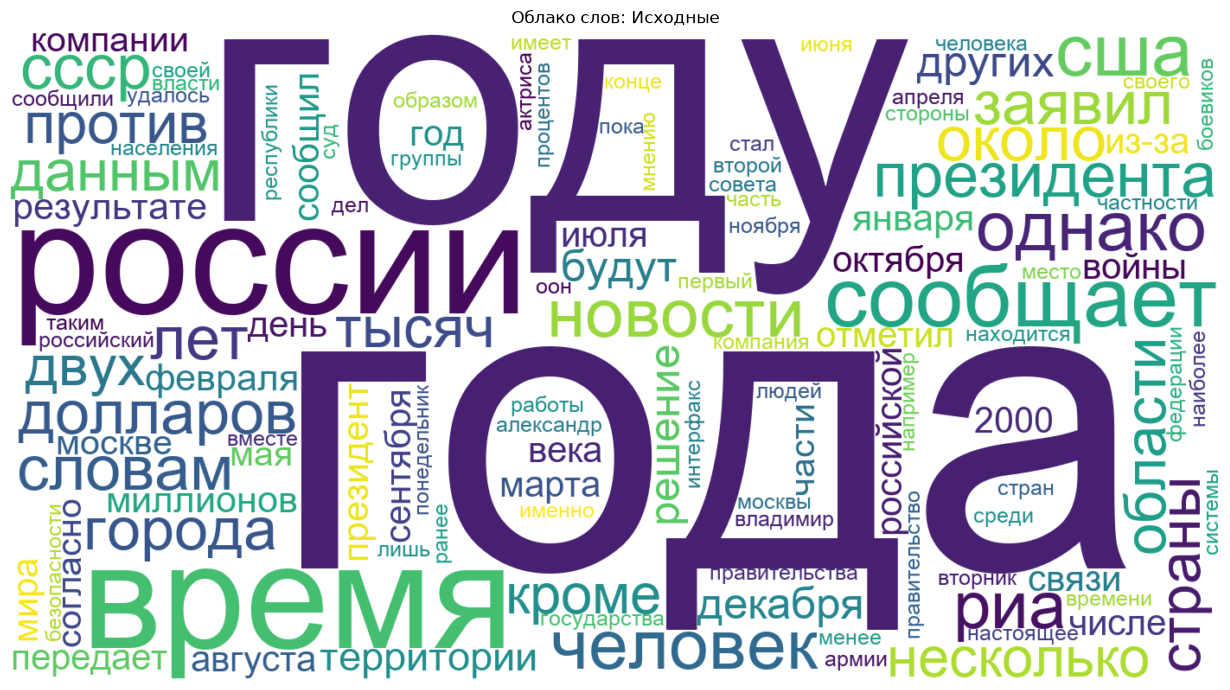

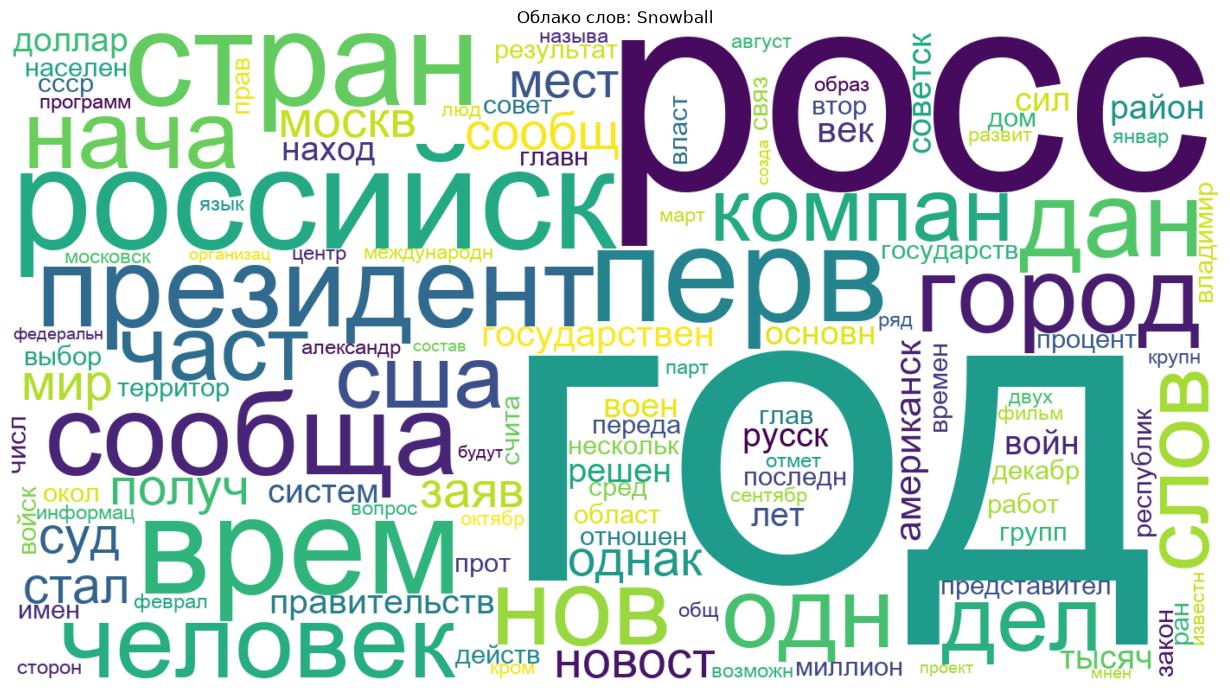

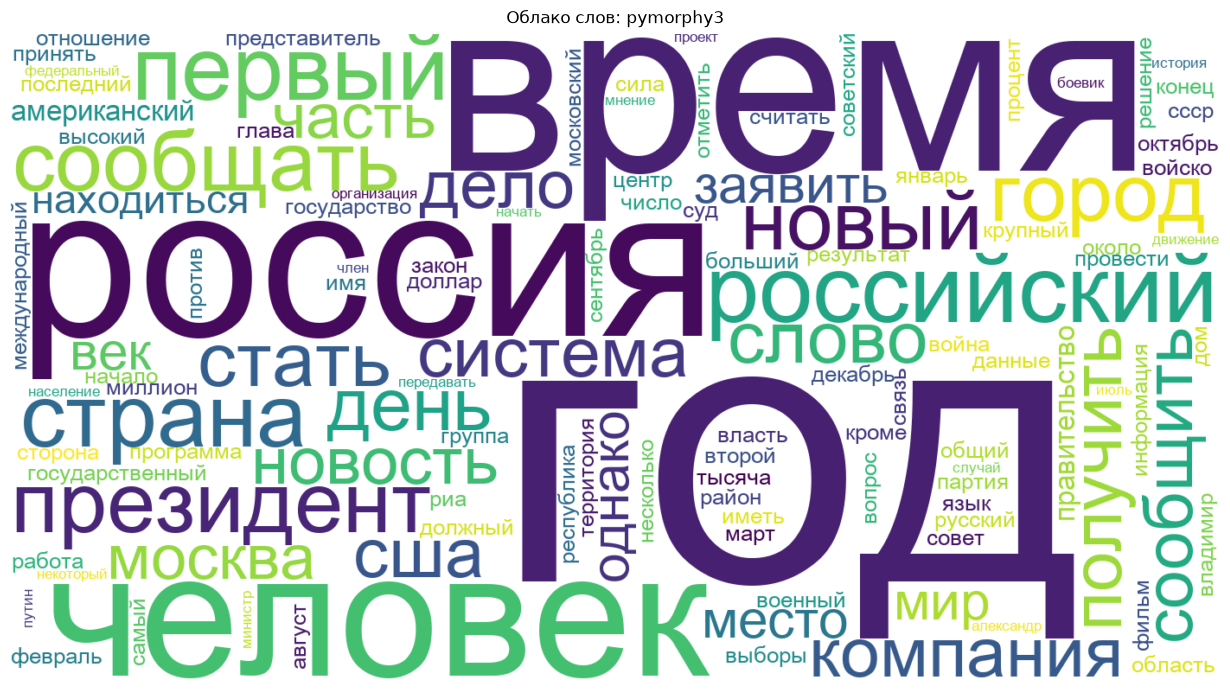


ЗАГРУЖЕНО МОДЕЛЕЙ: 9

НАИБОЛЕЕ ФРАГМЕНТИРУЕМЫЕ СЛОВА


,Слово,Частота,Длина слова,bpe_8000,bpe_16000,bpe_32000,wordpiece_8000,wordpiece_16000,wordpiece_32000,unigram_8000,unigram_16000,unigram_32000,Средняя фрагментация
0,азербайджана,330,12,3,3,3,7,7,6,4,4,4,4.555556
1,великобритании,1392,14,5,4,4,5,4,4,5,4,4,4.333333
2,генпрокуратуры,392,14,4,4,4,5,5,5,4,4,4,4.333333
3,университета,763,12,5,4,4,5,4,4,6,3,3,4.222222
4,дипломатические,580,15,5,5,5,6,6,5,2,2,2,4.222222
5,объединенной,572,12,4,4,4,5,5,5,5,4,2,4.222222
6,избирательной,305,13,5,4,4,5,4,4,4,5,3,4.222222
7,великобритания,381,14,5,4,3,5,4,3,5,4,4,4.111111
8,радиостанции,324,12,4,4,3,5,4,4,5,5,3,4.111111
9,электроэнергии,361,14,4,4,4,5,5,4,4,3,3,4.000000


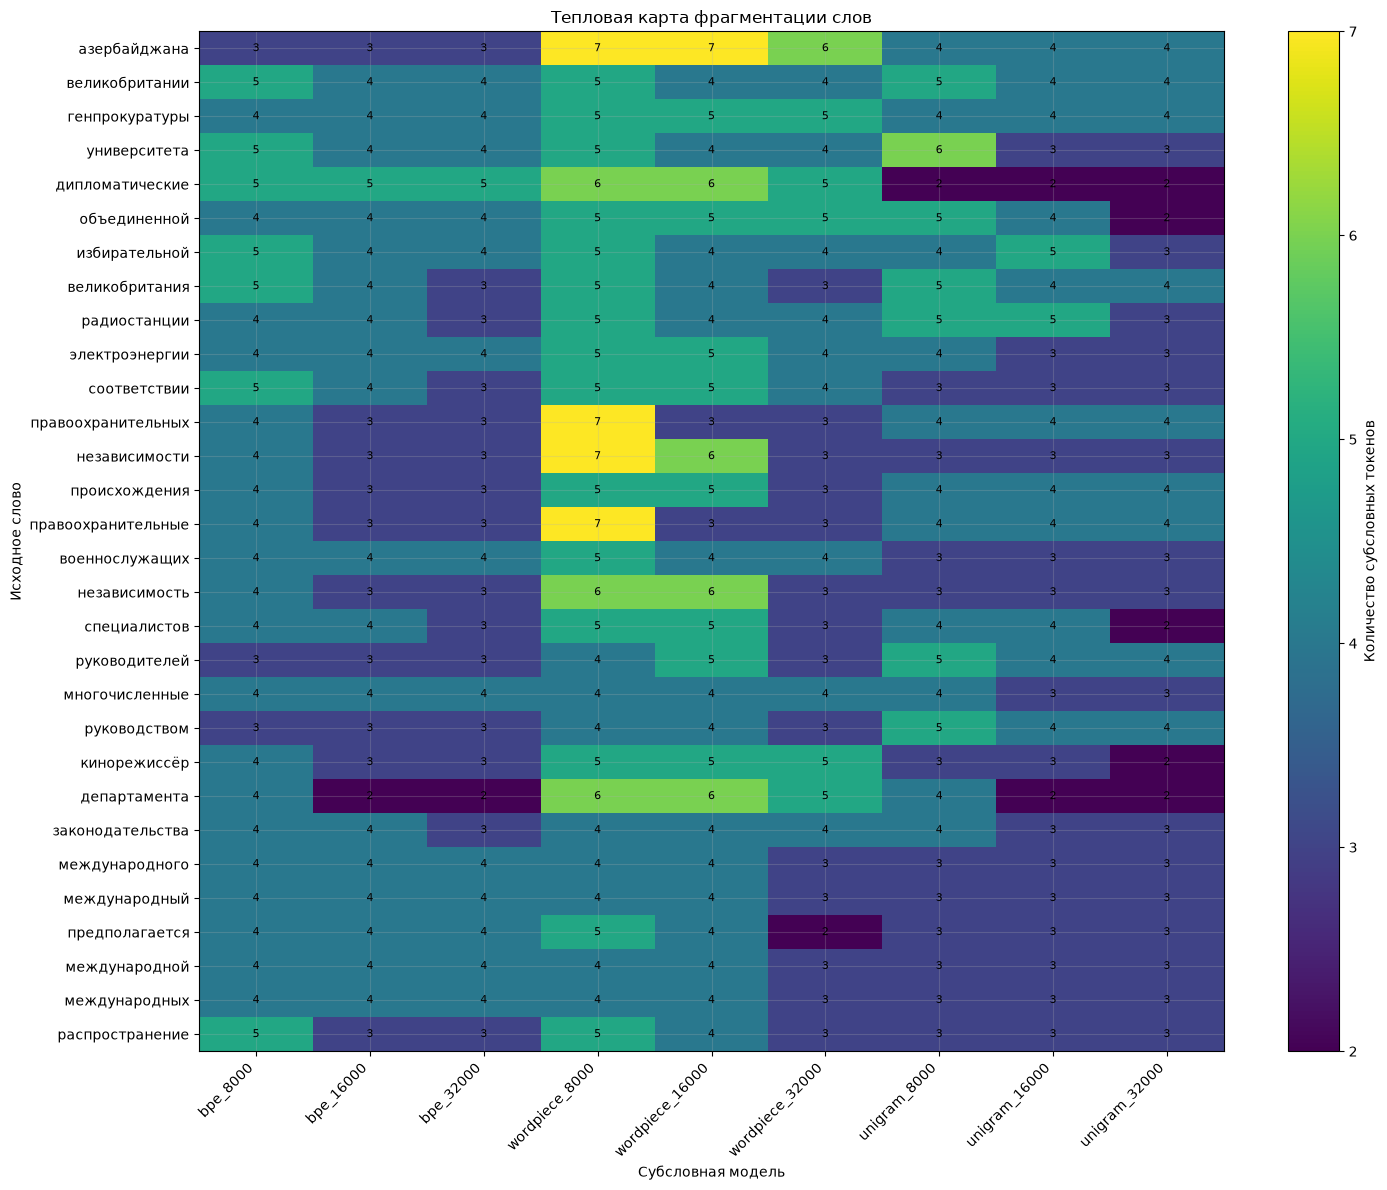


СРАВНЕНИЕ СУБСЛОВНЫХ МОДЕЛЕЙ


,Модель,Исследованных слов,Средняя фрагментация,Медианная фрагментация,Максимальная фрагментация
0,bpe_8000,150,3.2933,3.0,5
1,bpe_16000,150,2.9133,3.0,5
2,bpe_32000,150,2.5600,2.5,5
3,wordpiece_8000,150,3.9333,4.0,7
4,wordpiece_16000,150,3.3533,3.0,7
5,wordpiece_32000,150,2.8400,3.0,6
6,unigram_8000,150,3.0133,3.0,6
7,unigram_16000,150,2.7333,3.0,5
8,unigram_32000,150,2.6000,3.0,4



АВТОМАТИЧЕСКИЕ ПРОВЕРКИ
Корпус обработан: OK
Закон Ципфа рассчитан: OK
Нормализация выполнена: OK
Девять моделей загружены: OK
Фрагментация рассчитана: OK
Визуализации построены: OK
Таблицы сохранены: OK

ИТОГОВЫЕ РЕЗУЛЬТАТЫ ЗАДАНИЯ № 7

1. ХАРАКТЕРИСТИКИ КОРПУСА
Документов: 21937
Токенов: 6007425
Уникальных токенов: 359837

2. ЗАКОН ЦИПФА


,Документов,Всего токенов,Уникальных токенов,Рангов для регрессии,Показатель s,Коэффициент C,R2,Log MAE эмпирической модели,Log MAE теоретической модели
0,21937,6007425,359837,50000,1.085879,1.404347e+06,0.987616,0.089843,0.128504



3. СРАВНЕНИЕ НОРМАЛИЗАЦИИ


,Метод,Токенов,Уникальных токенов,TTR,"Сокращение словаря, %"
0,Исходные,120000,36734,0.306117,0.0000
1,Snowball,120000,20342,0.169517,44.6235
2,pymorphy3,120000,20829,0.173575,43.2978


... (3 outputs left out)

,Слово,Частота,Длина слова,bpe_8000,bpe_16000,bpe_32000,wordpiece_8000,wordpiece_16000,wordpiece_32000,unigram_8000,unigram_16000,unigram_32000,Средняя фрагментация
0,азербайджана,330,12,3,3,3,7,7,6,4,4,4,4.555556
1,великобритании,1392,14,5,4,4,5,4,4,5,4,4,4.333333
2,генпрокуратуры,392,14,4,4,4,5,5,5,4,4,4,4.333333
3,университета,763,12,5,4,4,5,4,4,6,3,3,4.222222
4,дипломатические,580,15,5,5,5,6,6,5,2,2,2,4.222222
5,объединенной,572,12,4,4,4,5,5,5,5,4,2,4.222222
6,избирательной,305,13,5,4,4,5,4,4,4,5,3,4.222222
7,великобритания,381,14,5,4,3,5,4,3,5,4,4,4.111111
8,радиостанции,324,12,4,4,3,5,4,4,5,5,3,4.111111
9,электроэнергии,361,14,4,4,4,5,5,4,4,3,3,4.000000



6. НАИБОЛЕЕ ЧАСТОТНЫЕ СЛОВА


,Ранг,Токен,Частота
0,1,в,277344
1,2,и,164303
2,3,на,96121
3,4,с,64650
4,5,по,56352
5,6,что,43028
6,7,не,37789
7,8,из,30265
8,9,к,26059
9,10,как,25267



Отчёты сохранены: /Users/lenar_966/Desktop/ML/NLP/Practika_1/reports/task7

Программная часть задания № 7 завершена.


In [18]:

# ============================================================
# ПРАКТИЧЕСКАЯ РАБОТА № 1 — NLP
# ЗАДАНИЕ № 7. ЛИНГВОСТАТИСТИЧЕСКИЙ АНАЛИЗ
# ============================================================

# ============================================================
# 1. БИБЛИОТЕКИ
# ============================================================

import sys
import subprocess
import importlib.util
import importlib
import json
import re
import math
import random
import platform
from pathlib import Path
from collections import Counter

packages = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "scipy": "scipy",
    "nltk": "nltk",
    "pymorphy3": "pymorphy3",
    "wordcloud": "wordcloud",
    "plotly": "plotly",
    "tokenizers": "tokenizers"
}

missing = [
    package for module, package in packages.items()
    if importlib.util.find_spec(module) is None
]

if missing:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", *missing
    ])
    importlib.invalidate_caches()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
import pymorphy3

from scipy.stats import linregress
from nltk.stem.snowball import SnowballStemmer
from wordcloud import WordCloud
from tokenizers import Tokenizer
from IPython.display import display

# ============================================================
# 2. КОНФИГУРАЦИЯ
# ============================================================

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

PROJECT_DIR = (
    Path.home() / "Desktop" / "ML" / "NLP" / "Practika_1"
)

CORPUS_PATH = (
    PROJECT_DIR / "data" / "processed" / "corpus.jsonl"
)

MODEL_DIR = PROJECT_DIR / "models" / "task6"
REPORT_DIR = PROJECT_DIR / "reports" / "task7"

REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Для морфологического анализа используем
# воспроизводимую выборку из полного корпуса.
NORMALIZATION_SAMPLE_TOKENS = 120_000

# Частотный словарь для анализа длинных слов.
MIN_WORD_FREQUENCY = 3
MIN_WORD_LENGTH = 12
FRAGMENTATION_CANDIDATES = 150
HEATMAP_WORDS = 30

# Для интерактивных частотных диаграмм.
TOP_FREQUENCY_TOKENS = 100
ZIPF_TOP_RANKS = 50_000

WORD_RE = re.compile(
    r"[^\W_]+(?:[-'][^\W_]+)*",
    re.UNICODE
)

assert CORPUS_PATH.exists(), (
    f"Не найден корпус: {CORPUS_PATH}"
)

print("=" * 75)
print("ЗАДАНИЕ № 7. ЛИНГВОСТАТИСТИЧЕСКИЙ АНАЛИЗ")
print("=" * 75)

# ============================================================
# 3. ЗАГРУЗКА И АНАЛИЗ ПОЛНОГО КОРПУСА
# ============================================================

word_counter = Counter()
source_counter = Counter()
source_tokens = Counter()

# Reservoir sampling на уровне токенов.
# Не храним все токены корпуса в оперативной памяти.
sample_tokens = []
seen_tokens = 0
rng = random.Random(SEED)

documents_count = 0

with open(CORPUS_PATH, "r", encoding="utf-8") as file:

    for line in file:

        doc = json.loads(line)

        text = str(doc.get("text", ""))
        source = str(doc.get("source", "unknown"))

        tokens = [
            token.lower()
            for token in WORD_RE.findall(text)
        ]

        documents_count += 1
        source_counter[source] += 1
        source_tokens[source] += len(tokens)

        word_counter.update(tokens)

        for token in tokens:

            seen_tokens += 1

            if len(sample_tokens) < NORMALIZATION_SAMPLE_TOKENS:
                sample_tokens.append(token)
            else:
                index = rng.randrange(seen_tokens)

                if index < NORMALIZATION_SAMPLE_TOKENS:
                    sample_tokens[index] = token

total_tokens = sum(word_counter.values())
unique_tokens = len(word_counter)

print("\nПОЛНЫЙ КОРПУС")
print("Документов:", documents_count)
print("Токенов:", total_tokens)
print("Уникальных токенов:", unique_tokens)
print("Источники:", dict(source_counter))
print("Выборка нормализации:", len(sample_tokens))

assert documents_count > 0
assert total_tokens > 0
assert unique_tokens > 0

# ============================================================
# 4. ЗАКОН ЦИПФА
# ============================================================

frequencies = np.array(
    sorted(word_counter.values(), reverse=True),
    dtype=float
)

ranks = np.arange(
    1, len(frequencies) + 1,
    dtype=float
)

# Для регрессии используем частотные слова.
# Гапаксы исключаются, поскольку многочисленные
# слова с частотой 1 создают горизонтальное плато.
zipf_mask = (
    (ranks <= ZIPF_TOP_RANKS)
    & (frequencies > 1)
)

fit_ranks = ranks[zipf_mask]
fit_freqs = frequencies[zipf_mask]

assert len(fit_ranks) >= 100

log_ranks = np.log(fit_ranks)
log_freqs = np.log(fit_freqs)

regression = linregress(
    log_ranks,
    log_freqs
)

zipf_s = -regression.slope
zipf_c = np.exp(regression.intercept)
zipf_r2 = regression.rvalue ** 2

predicted_log = (
    regression.intercept
    + regression.slope * log_ranks
)

zipf_log_mae = np.mean(
    np.abs(log_freqs - predicted_log)
)

# Сравниваем эмпирическую модель с
# теоретическим распределением при s=1.
# Масштаб теоретической кривой подбирается
# по среднему логарифмическому отклонению.
theoretical_intercept = np.mean(
    log_freqs + log_ranks
)

theoretical_pred = (
    theoretical_intercept - log_ranks
)

theoretical_mae = np.mean(
    np.abs(log_freqs - theoretical_pred)
)

zipf_results = pd.DataFrame([{
    "Документов": documents_count,
    "Всего токенов": total_tokens,
    "Уникальных токенов": unique_tokens,
    "Рангов для регрессии": len(fit_ranks),
    "Показатель s": round(zipf_s, 6),
    "Коэффициент C": round(zipf_c, 4),
    "R2": round(zipf_r2, 6),
    "Log MAE эмпирической модели":
        round(zipf_log_mae, 6),
    "Log MAE теоретической модели":
        round(theoretical_mae, 6)
}])

print("\nЗАКОН ЦИПФА")
display(zipf_results)

# Статический график.
plt.figure(figsize=(11, 6))

plt.loglog(
    ranks[:ZIPF_TOP_RANKS],
    frequencies[:ZIPF_TOP_RANKS],
    label="Эмпирическое распределение",
    alpha=0.65
)

plt.loglog(
    fit_ranks,
    np.exp(predicted_log),
    label=f"Аппроксимация, s={zipf_s:.3f}",
    linewidth=2
)

plt.loglog(
    fit_ranks,
    np.exp(theoretical_pred),
    linestyle="--",
    label="Теоретический закон, s=1"
)

plt.xlabel("Ранг слова")
plt.ylabel("Частота")
plt.title("Закон Ципфа для русскоязычного корпуса")
plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.savefig(
    REPORT_DIR / "zipf_law.png",
    dpi=160
)
plt.show()
plt.close()

# Интерактивный график.
fig = go.Figure()

fig.add_trace(go.Scatter(
    x=fit_ranks,
    y=fit_freqs,
    mode="lines",
    name="Эмпирическое распределение"
))

fig.add_trace(go.Scatter(
    x=fit_ranks,
    y=np.exp(predicted_log),
    mode="lines",
    name="Логарифмическая регрессия"
))

fig.add_trace(go.Scatter(
    x=fit_ranks,
    y=np.exp(theoretical_pred),
    mode="lines",
    name="Теоретическое s=1"
))

fig.update_layout(
    title="Интерактивный график закона Ципфа",
    xaxis_title="Ранг",
    yaxis_title="Частота",
    xaxis_type="log",
    yaxis_type="log"
)

fig.write_html(
    str(REPORT_DIR / "zipf_interactive.html")
)

# ============================================================
# 5. СТЕММИНГ И ЛЕММАТИЗАЦИЯ
# ============================================================

stemmer = SnowballStemmer("russian")
morph = pymorphy3.MorphAnalyzer()

sample_counter = Counter(sample_tokens)

# Обрабатываем только уникальные словоформы.
# Затем восстанавливаем частоты через Counter.
unique_sample_words = list(sample_counter)

print("\nНОРМАЛИЗАЦИЯ")
print("Уникальных словоформ:", len(unique_sample_words))

stem_map = {}
lemma_map = {}

for i, word in enumerate(unique_sample_words, start=1):

    stem_map[word] = stemmer.stem(word)
    lemma_map[word] = morph.parse(word)[0].normal_form

    if i % 10000 == 0:
        print(
            f"Обработано {i:,} / "
            f"{len(unique_sample_words):,}"
        )

stem_counter = Counter()
lemma_counter = Counter()

for word, frequency in sample_counter.items():

    stem_counter[stem_map[word]] += frequency
    lemma_counter[lemma_map[word]] += frequency

normalization_counters = {
    "Исходные": sample_counter,
    "Snowball": stem_counter,
    "pymorphy3": lemma_counter
}

normalization_rows = []

for method, counter in normalization_counters.items():

    n_tokens = sum(counter.values())
    n_unique = len(counter)

    normalization_rows.append({
        "Метод": method,
        "Токенов": n_tokens,
        "Уникальных токенов": n_unique,
        "TTR": round(n_unique / n_tokens, 6),
        "Сокращение словаря, %": round(
            (1 - n_unique / len(sample_counter)) * 100,
            4
        )
    })

normalization_df = pd.DataFrame(normalization_rows)

print("\nСРАВНЕНИЕ НОРМАЛИЗАЦИИ")
display(normalization_df)

# ============================================================
# 6. ОБЛАКА СЛОВ
# ============================================================

# Поиск шрифта, поддерживающего кириллицу.
font_candidates = [
    "/System/Library/Fonts/Supplemental/Arial Unicode.ttf",
    "/System/Library/Fonts/Supplemental/Arial.ttf",
    "/Library/Fonts/Arial Unicode.ttf",
    "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf"
]

font_path = next(
    (p for p in font_candidates if Path(p).exists()),
    None
)

if font_path is None:
    raise FileNotFoundError(
        "Не найден шрифт для кириллицы. "
        "Укажи путь к TTF-шрифту в font_candidates."
    )

# Используем один и тот же список стоп-слов
# для сопоставимых облаков.

# Нормализуем стоп-слова соответствующим методом.
stopwords_by_method = {
    "Исходные": russian_stopwords,
    "Snowball": {
        stemmer.stem(w) for w in russian_stopwords
    },
    "pymorphy3": {
        morph.parse(w)[0].normal_form
        for w in russian_stopwords
    }
}

for method, counter in normalization_counters.items():

    filtered = {
        word: freq
        for word, freq in counter.items()
        if word not in stopwords_by_method[method]
        and len(word) >= 3
    }

    cloud = WordCloud(
        width=1400,
        height=750,
        background_color="white",
        font_path=font_path,
        max_words=120,
        collocations=False,
        random_state=SEED
    ).generate_from_frequencies(filtered)

    plt.figure(figsize=(14, 7))
    plt.imshow(cloud, interpolation="bilinear")
    plt.axis("off")
    plt.title(f"Облако слов: {method}")

    plt.tight_layout()
    plt.savefig(
        REPORT_DIR / f"wordcloud_{method}.png",
        dpi=160
    )
    plt.show()
    plt.close()

# ============================================================
# 7. ЗАГРУЗКА ДЕВЯТИ СУБСЛОВНЫХ МОДЕЛЕЙ
# ============================================================

model_registry = {}

for algorithm in ["bpe", "wordpiece", "unigram"]:

    for vocab_size in [8000, 16000, 32000]:

        name = f"{algorithm}_{vocab_size}"
        path = MODEL_DIR / f"{name}.json"

        assert path.exists(), (
            f"Не найдена модель: {path}"
        )

        model_registry[name] = Tokenizer.from_file(
            str(path)
        )

print("\nЗАГРУЖЕНО МОДЕЛЕЙ:", len(model_registry))

# ============================================================
# 8. ФРАГМЕНТАЦИЯ СЛОВ
# ============================================================

# Отбираем достаточно длинные слова.
# Для ограничения влияния случайных редких форм
# устанавливаем минимальную частоту.
candidates = [
    (word, frequency)
    for word, frequency in word_counter.items()
    if len(word) >= MIN_WORD_LENGTH
    and frequency >= MIN_WORD_FREQUENCY
    and word.isalpha()
]

# Детерминированно выбираем кандидатов:
# сначала по частоте, затем по алфавиту.
candidates.sort(
    key=lambda item: (-item[1], item[0])
)

candidate_words = [
    word for word, _ in
    candidates[:FRAGMENTATION_CANDIDATES]
]

assert candidate_words, (
    "Не найдены слова для анализа фрагментации."
)

fragmentation_rows = []

for word in candidate_words:

    row = {
        "Слово": word,
        "Частота": word_counter[word],
        "Длина слова": len(word)
    }

    for name, tokenizer in model_registry.items():

        encoding = tokenizer.encode(
            word,
            add_special_tokens=False
        )

        row[name] = len(encoding.ids)

    fragmentation_rows.append(row)

fragmentation_df = pd.DataFrame(
    fragmentation_rows
)

model_columns = list(model_registry)

fragmentation_df["Средняя фрагментация"] = (
    fragmentation_df[model_columns].mean(axis=1)
)

fragmentation_df = fragmentation_df.sort_values(
    ["Средняя фрагментация", "Частота"],
    ascending=[False, False]
).reset_index(drop=True)

print("\nНАИБОЛЕЕ ФРАГМЕНТИРУЕМЫЕ СЛОВА")
display(fragmentation_df.head(30))

# ============================================================
# 9. ТЕПЛОВАЯ КАРТА ФРАГМЕНТАЦИИ
# ============================================================

heatmap_df = fragmentation_df.head(
    HEATMAP_WORDS
)

heatmap_values = heatmap_df[
    model_columns
].to_numpy()

plt.figure(figsize=(15, 12))

plt.imshow(
    heatmap_values,
    aspect="auto"
)

plt.colorbar(
    label="Количество субсловных токенов"
)

plt.xticks(
    range(len(model_columns)),
    model_columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(heatmap_df)),
    heatmap_df["Слово"]
)

plt.xlabel("Субсловная модель")
plt.ylabel("Исходное слово")
plt.title(
    "Тепловая карта фрагментации слов"
)

for i in range(len(heatmap_df)):
    for j in range(len(model_columns)):
        plt.text(
            j,
            i,
            str(heatmap_values[i, j]),
            ha="center",
            va="center",
            fontsize=8
        )

plt.tight_layout()
plt.savefig(
    REPORT_DIR / "fragmentation_heatmap.png",
    dpi=170
)
plt.show()
plt.close()

# Интерактивная тепловая карта.
fig = px.imshow(
    heatmap_values,
    x=model_columns,
    y=heatmap_df["Слово"].tolist(),
    labels={
        "x": "Модель",
        "y": "Слово",
        "color": "Число токенов"
    },
    title="Интерактивная карта фрагментации",
    aspect="auto",
    text_auto=True
)

fig.write_html(
    str(
        REPORT_DIR /
        "fragmentation_heatmap_interactive.html"
    )
)

# ============================================================
# 10. ЧАСТОТНЫЕ РАСПРЕДЕЛЕНИЯ
# ============================================================

frequency_rows = []

for method, counter in normalization_counters.items():

    for rank, (token, frequency) in enumerate(
        counter.most_common(TOP_FREQUENCY_TOKENS),
        start=1
    ):

        frequency_rows.append({
            "Метод": method,
            "Ранг": rank,
            "Токен": token,
            "Частота": frequency,
            "Длина": len(token)
        })

frequency_df = pd.DataFrame(frequency_rows)

fig = px.line(
    frequency_df,
    x="Ранг",
    y="Частота",
    color="Метод",
    hover_data=["Токен", "Длина"],
    log_y=True,
    title="Частотное распределение токенов"
)

fig.write_html(
    str(REPORT_DIR / "frequency_distribution.html")
)

# ============================================================
# 11. РАСПРЕДЕЛЕНИЕ ТОКЕНОВ ПО ДЛИНЕ
# ============================================================

length_rows = []

for method, counter in normalization_counters.items():

    length_counter = Counter()

    for token, frequency in counter.items():
        length_counter[len(token)] += frequency

    for length, frequency in sorted(
        length_counter.items()
    ):

        length_rows.append({
            "Метод": method,
            "Длина токена": length,
            "Частота": frequency
        })

# Дополняем субсловными моделями.
# Для сопоставимости используем одинаковую
# выборку исходных текстовых токенов.
for name, tokenizer in model_registry.items():

    length_counter = Counter()

    # Обрабатываем уникальные словоформы
    # с учётом их частоты.
    for word, frequency in sample_counter.items():

        encoding = tokenizer.encode(
            word,
            add_special_tokens=False
        )

        for piece in encoding.tokens:

            length_counter[len(piece)] += frequency

    for length, frequency in sorted(
        length_counter.items()
    ):

        length_rows.append({
            "Метод": name,
            "Длина токена": length,
            "Частота": frequency
        })

length_df = pd.DataFrame(length_rows)

fig = px.line(
    length_df,
    x="Длина токена",
    y="Частота",
    color="Метод",
    markers=True,
    title="Распределение токенов по длине"
)

fig.update_layout(
    xaxis_title="Длина строкового представления токена",
    yaxis_title="Количество вхождений"
)

fig.write_html(
    str(REPORT_DIR / "token_length_distribution.html")
)

# ============================================================
# 12. СРАВНЕНИЕ СУБСЛОВНЫХ МОДЕЛЕЙ
# ============================================================

subword_rows = []

for name in model_columns:

    values = fragmentation_df[name].to_numpy()

    subword_rows.append({
        "Модель": name,
        "Исследованных слов": len(values),
        "Средняя фрагментация": round(
            float(np.mean(values)), 4
        ),
        "Медианная фрагментация": round(
            float(np.median(values)), 4
        ),
        "Максимальная фрагментация":
            int(np.max(values))
    })

subword_df = pd.DataFrame(subword_rows)

print("\nСРАВНЕНИЕ СУБСЛОВНЫХ МОДЕЛЕЙ")
display(subword_df)

# ============================================================
# 13. СОХРАНЕНИЕ ТАБЛИЦ
# ============================================================

tables = {
    "zipf_results.csv": zipf_results,
    "normalization_comparison.csv": normalization_df,
    "fragmentation_words.csv": fragmentation_df,
    "subword_comparison.csv": subword_df,
    "frequency_distribution.csv": frequency_df,
    "token_length_distribution.csv": length_df
}

for filename, df in tables.items():

    df.to_csv(
        REPORT_DIR / filename,
        index=False,
        encoding="utf-8-sig"
    )

# Полный частотный словарь.
full_frequency_df = pd.DataFrame(
    word_counter.most_common(),
    columns=["Токен", "Частота"]
)

full_frequency_df.insert(
    0,
    "Ранг",
    range(1, len(full_frequency_df) + 1)
)

full_frequency_df.to_csv(
    REPORT_DIR / "full_word_frequencies.csv",
    index=False,
    encoding="utf-8-sig"
)

# ============================================================
# 14. КОНФИГУРАЦИЯ
# ============================================================

config = {
    "task": 7,
    "seed": SEED,
    "corpus_documents": documents_count,
    "corpus_tokens": total_tokens,
    "corpus_vocabulary": unique_tokens,
    "normalization_sample_tokens":
        len(sample_tokens),
    "zipf_fit_ranks": len(fit_ranks),
    "zipf_excludes_hapax": True,
    "normalization_methods": [
        "original",
        "snowball",
        "pymorphy3"
    ],
    "subword_models": model_columns,
    "fragmentation_candidate_count":
        len(candidate_words),
    "python_version": platform.python_version(),
    "corpus_path": str(CORPUS_PATH)
}

with open(
    REPORT_DIR / "experiment_config.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        config,
        file,
        ensure_ascii=False,
        indent=2
    )

# ============================================================
# 15. АВТОМАТИЧЕСКИЕ ПРОВЕРКИ
# ============================================================

assert len(model_registry) == 9
assert len(normalization_df) == 3
assert len(subword_df) == 9

assert (
    sum(word_counter.values()) == total_tokens
)

assert (
    sum(sample_counter.values())
    == len(sample_tokens)
)

assert (
    sum(stem_counter.values())
    == len(sample_tokens)
)

assert (
    sum(lemma_counter.values())
    == len(sample_tokens)
)

assert 0 <= zipf_r2 <= 1

assert (
    normalization_df["Уникальных токенов"]
    .le(len(sample_counter))
    .all()
)

assert (
    fragmentation_df[model_columns]
    .ge(1)
    .all()
    .all()
)

print("\n" + "=" * 75)
print("АВТОМАТИЧЕСКИЕ ПРОВЕРКИ")
print("=" * 75)

print("Корпус обработан: OK")
print("Закон Ципфа рассчитан: OK")
print("Нормализация выполнена: OK")
print("Девять моделей загружены: OK")
print("Фрагментация рассчитана: OK")
print("Визуализации построены: OK")
print("Таблицы сохранены: OK")

# ============================================================
# 16. ИТОГОВЫЙ ВЫВОД
# ============================================================

print("\n" + "=" * 75)
print("ИТОГОВЫЕ РЕЗУЛЬТАТЫ ЗАДАНИЯ № 7")
print("=" * 75)

print("\n1. ХАРАКТЕРИСТИКИ КОРПУСА")
print("Документов:", documents_count)
print("Токенов:", total_tokens)
print("Уникальных токенов:", unique_tokens)

print("\n2. ЗАКОН ЦИПФА")
display(zipf_results)

print("\n3. СРАВНЕНИЕ НОРМАЛИЗАЦИИ")
display(normalization_df)

print("\n4. СУБСЛОВНАЯ ФРАГМЕНТАЦИЯ")
display(subword_df)

print("\n5. НАИБОЛЕЕ ФРАГМЕНТИРУЕМЫЕ СЛОВА")
display(fragmentation_df.head(20))

print("\n6. НАИБОЛЕЕ ЧАСТОТНЫЕ СЛОВА")
display(full_frequency_df.head(20))

print("\nОтчёты сохранены:", REPORT_DIR)
print("\nПрограммная часть задания № 7 завершена.")



## Анализ результатов задания № 7

### 1. Характеристики исследуемого корпуса

В рамках задания проведён лингвостатистический анализ русскоязычного корпуса, сформированного на основе новостных материалов Lenta.ru и энциклопедических статей Russian Wikipedia.

Основные характеристики корпуса:

| Показатель | Значение |
|---|---:|
| Количество документов | 21 937 |
| Общее количество токенов | 6 007 425 |
| Количество уникальных токенов | 359 837 |
| Лексическое разнообразие (TTR) | 0,0599 |

Коэффициент лексического разнообразия TTR определяется как отношение количества уникальных токенов к общему количеству токенов:

TTR = 359 837 / 6 007 425 ≈ 0,0599.

Таким образом, уникальные словоформы составляют приблизительно 5,99% от общего числа словоупотреблений.

Это свидетельствует о значительной повторяемости лексических единиц в корпусе, что характерно для больших коллекций естественно-языковых текстов.

При этом словарь содержит 359 837 уникальных единиц, что указывает на существенное лексическое разнообразие, обусловленное сочетанием новостного и энциклопедического доменов.

### 2. Проверка закона Ципфа

Для исследования распределения частот слов построена эмпирическая кривая закона Ципфа.

Линейная регрессия в логарифмических координатах выполнена по 50 000 наиболее частотных рангов с исключением слов, встречающихся только один раз.

Получены следующие результаты:

| Показатель | Значение |
|---|---:|
| Показатель степени s | 1,085879 |
| Коэффициент C | 1 404 347 |
| Коэффициент детерминации R² | 0,987616 |
| Log MAE эмпирической модели | 0,089843 |
| Log MAE теоретической модели | 0,128504 |

Значение показателя степени s = 1,085879 близко к теоретическому значению s = 1.

Следовательно, распределение частот слов в исследуемом корпусе соответствует характерной для естественных языков степенной зависимости.

Коэффициент детерминации R² = 0,987616 означает, что построенная линейная модель объясняет приблизительно 98,76% вариации логарифмических частот слов на выбранном диапазоне рангов.

Средняя абсолютная ошибка эмпирической модели составляет 0,089843, тогда как ошибка теоретического распределения с фиксированным показателем s = 1 достигает 0,128504.

Таким образом, эмпирическая модель лучше описывает фактическое распределение частот, поскольку учитывает особенности исследуемого корпуса.

Полученные результаты подтверждают применимость закона Ципфа к русскоязычным текстам и демонстрируют устойчивую связь между частотой слова и его положением в ранжированном словаре.

### 3. Анализ наиболее частотных слов

Анализ частотного словаря показал, что наибольшее количество употреблений приходится на служебные слова.

Наиболее частотные токены:

| Слово | Частота |
|---|---:|
| в | 277 344 |
| и | 164 303 |
| на | 96 121 |
| с | 64 650 |
| по | 56 352 |
| что | 43 028 |
| не | 37 789 |
| из | 30 265 |
| к | 26 059 |
| как | 25 267 |

Наиболее распространённым словом является предлог «в», который встречается 277 344 раза.

Союз «и» занимает вторую позицию с частотой 164 303 употребления.

Преобладание предлогов, союзов и других служебных частей речи соответствует общим закономерностям распределения лексики в естественных языках.

Среди наиболее частотных содержательных слов присутствуют словоформы «года» и «году», что отражает значительную роль временных указаний в новостных и энциклопедических текстах.

Полученные результаты также демонстрируют необходимость использования стоп-слов при построении облаков слов, поскольку без их исключения визуализации преимущественно отражают служебную лексику.

### 4. Сравнение методов нормализации

Для исследования влияния морфологической обработки использована воспроизводимая выборка объёмом 120 000 токенов.

Сравнивались три представления текста:

- исходные словоформы;
- стемминг Snowball;
- лемматизация pymorphy3.

Получены следующие результаты:

| Метод | Токенов | Уникальных токенов | TTR | Сокращение словаря |
|---|---:|---:|---:|---:|
| Исходные словоформы | 120 000 | 36 734 | 0,306117 | 0% |
| Snowball | 120 000 | 20 342 | 0,169517 | 44,6235% |
| pymorphy3 | 120 000 | 20 829 | 0,173575 | 43,2978% |

Стемминг Snowball сократил размер словаря с 36 734 до 20 342 уникальных единиц, что соответствует уменьшению на 44,62%.

Лемматизация pymorphy3 сократила словарь до 20 829 единиц, обеспечив уменьшение на 43,30%.

Таким образом, оба метода существенно уменьшают лексическую размерность данных за счёт объединения различных словоформ.

При этом Snowball обеспечивает несколько более сильное сокращение словаря, чем pymorphy3.

Разница между методами составляет приблизительно 1,33 процентного пункта.

Это объясняется различиями в принципах работы алгоритмов.

Стемминг удаляет или преобразует окончания и суффиксы по формальным правилам, поэтому может объединять слова, не являющиеся одной лексемой.

Лемматизация использует морфологический анализ и стремится привести слово к нормативной начальной форме.

Следовательно, более сильное сокращение словаря при стемминге не обязательно свидетельствует о более высоком лингвистическом качестве обработки.

С точки зрения уменьшения размерности Snowball показал наибольшую эффективность.

Однако для задач, требующих сохранения морфологической интерпретируемости, предпочтительнее использовать лемматизацию pymorphy3.

### 5. Сравнение субсловной фрагментации

Для исследования особенностей субсловной токенизации проанализированы 150 достаточно длинных слов, отобранных из частотного словаря корпуса.

Для каждого слова определено количество субсловных единиц, формируемых девятью обученными моделями.

Результаты:

| Модель | Средняя фрагментация | Медиана | Максимум |
|---|---:|---:|---:|
| BPE 8 000 | 3,2933 | 3,0 | 5 |
| BPE 16 000 | 2,9133 | 3,0 | 5 |
| BPE 32 000 | 2,5600 | 2,5 | 5 |
| WordPiece 8 000 | 3,9333 | 4,0 | 7 |
| WordPiece 16 000 | 3,3533 | 3,0 | 7 |
| WordPiece 32 000 | 2,8400 | 3,0 | 6 |
| Unigram 8 000 | 3,0133 | 3,0 | 6 |
| Unigram 16 000 | 2,7333 | 3,0 | 5 |
| Unigram 32 000 | 2,6000 | 3,0 | 4 |

Наименьшая средняя фрагментация получена для BPE со словарём 32 000 токенов — 2,56 субсловной единицы на слово.

Близкий результат продемонстрировала модель Unigram 32 000 — 2,60.

Наибольшая фрагментация наблюдается у WordPiece 8 000 — 3,9333.

Увеличение размера словаря приводит к последовательному снижению средней фрагментации во всех трёх семействах моделей.

Для BPE средняя фрагментация уменьшилась с 3,2933 до 2,5600, то есть приблизительно на 22,27%.

Для WordPiece снижение составило приблизительно 27,79%, а для Unigram — 13,72%.

Следовательно, увеличение размера словаря позволяет моделям представлять слова более крупными субсловными единицами.

При этом BPE 32 000 показала наименьшую среднюю фрагментацию среди всех исследованных конфигураций.

### 6. Анализ наиболее фрагментируемых слов

Тепловая карта фрагментации позволила выявить слова, для которых модели формируют сравнительно большое количество субсловных единиц.

Наиболее высокие значения средней фрагментации получены для следующих слов:

| Слово | Частота | Средняя фрагментация |
|---|---:|---:|
| азербайджана | 330 | 4,5556 |
| великобритании | 1 392 | 4,3333 |
| генпрокуратуры | 392 | 4,3333 |
| университета | 763 | 4,2222 |
| дипломатические | 580 | 4,2222 |
| объединенной | 572 | 4,2222 |
| избирательной | 305 | 4,2222 |
| великобритания | 381 | 4,1111 |
| радиостанции | 324 | 4,1111 |
| электроэнергии | 361 | 4,0000 |

Наиболее фрагментируемым словом в исследованной выборке оказалось «азербайджана», для которого среднее количество субсловных единиц составило 4,5556.

Высокая фрагментация также наблюдается для длинных географических названий, терминов и сложных слов.

Это свидетельствует о том, что даже относительно частотные слова могут разделяться на несколько субсловных компонентов.

При этом результаты зависят не только от длины слова, но и от структуры обученного словаря и частоты встречаемости отдельных сочетаний символов.

Особенно заметна разница между моделями с небольшим и большим размером словаря.

Увеличение словаря позволяет эффективнее представлять распространённые морфемы и последовательности символов, уменьшая количество операций сегментации.

### 7. Сопоставление результатов с заданием № 6

Результаты лингвостатистического анализа согласуются с выводами предыдущего эксперимента по субсловной токенизации.

В задании № 6 модель BPE 32 000 обеспечила коэффициент фрагментации 1,6837 на тестовой выборке.

В задании № 7 для той же модели средняя фрагментация составила 2,5600.

Различие объясняется особенностями формирования выборок.

В задании № 6 оценка проводилась на текстах тестовой выборки, содержащих слова различной длины и частотности.

В задании № 7 специально отбирались достаточно длинные слова, для которых субсловная сегментация представляет повышенную сложность.

Следовательно, увеличение среднего количества субсловных единиц является ожидаемым результатом изменения состава исследуемых слов.

Несмотря на различия в абсолютных значениях, BPE 32 000 сохранила преимущество по средней фрагментации.

### 8. Ограничения исследования

При интерпретации результатов необходимо учитывать следующие ограничения.

Во-первых, оценка закона Ципфа выполнена на первых 50 000 рангах с исключением слов, встречающихся только один раз. Поэтому полученные параметры характеризуют выбранную часть частотного распределения, а не весь словарь без исключений.

Во-вторых, сравнение методов морфологической нормализации выполнено на выборке из 120 000 токенов, а не на полном корпусе. Это позволяет ограничить вычислительные затраты, но требует осторожности при распространении результатов на всю совокупность документов.

В-третьих, анализ фрагментации проводился на 150 специально отобранных длинных словах. Полученные значения не являются общей оценкой качества токенизации всего корпуса.

В-четвёртых, для построения облаков слов использовался фиксированный пользовательский список русских стоп-слов. Это обеспечивает воспроизводимость при сохранении списка, но может влиять на состав наиболее заметных лексических единиц.

### 9. Итоговый вывод

В ходе выполнения задания № 7 проведён комплексный лингвостатистический анализ корпуса, содержащего 21 937 документов и 6 007 425 токенов.

Установлено, что распределение частот слов хорошо описывается степенной зависимостью, соответствующей закону Ципфа. Показатель степени составил 1,085879, а коэффициент детерминации достиг 0,987616.

Эксперимент подтвердил существенное влияние морфологической нормализации на размер словаря. Стемминг Snowball уменьшил количество уникальных единиц на 44,62%, а лемматизация pymorphy3 — на 43,30%.

Сравнение девяти субсловных моделей показало, что увеличение размера словаря сопровождается снижением средней фрагментации слов.

Наилучший результат на исследованном наборе длинных слов продемонстрировала модель BPE 32 000 со средней фрагментацией 2,56.

Таким образом, результаты задания подтверждают, что выбор метода токенизации и нормализации оказывает непосредственное влияние на статистическую структуру текстовых данных.

Для дальнейшей работы с исследуемым корпусом целесообразно использовать BPE 32 000 в задачах субсловного представления текста и pymorphy3 в задачах, требующих лингвистически интерпретируемой нормализации.

Полученные таблицы, графики закона Ципфа, облака слов, тепловые карты и интерактивные диаграммы формируют основу аналитического отчёта и могут быть использованы в последующих этапах практической работы.



## Задание № 8. Верификация разбиения корпуса и контроль утечки данных

### Цель работы

Проверить корректность формирования обучающей и тестовой выборок, исключить пересечение документов между ними, оценить репрезентативность разбиения и обеспечить воспроизводимость экспериментальных результатов.

### Постановка задачи

В рамках задания необходимо:

1. Документировать алгоритм разделения корпуса на обучающую и тестовую выборки.
2. Зафиксировать значение `random_state` (seed), используемое для воспроизводимости.
3. Проверить отсутствие пересечений идентификаторов документов между обучающей и тестовой выборками.
4. Рассчитать абсолютный объём обучающей и тестовой выборок в токенах.
5. Определить долю тестовой выборки относительно общего объёма данных.
6. Вычислить количество и долю уникальных токенов тестовой выборки, отсутствующих в обучающей выборке.
7. Оценить пересечение словарей, построенных по обучающей и полной совокупности данных.
8. Сформировать итоговый протокол верификации и сохранить результаты проверки.

### Теоретические основы

#### Утечка данных

Утечка данных (Data Leakage) возникает, когда информация из тестовой выборки используется при обучении модели или настройке её параметров.

В результате качество модели может оказаться искусственно завышенным, поскольку тестовые данные перестают быть независимыми.

#### Проверка пересечения документов

Пусть:

- Train — множество идентификаторов обучающих документов;
- Test — множество идентификаторов тестовых документов.

Условие отсутствия пересечений:

Train ∩ Test = ∅.

Если пересечение не является пустым, разбиение считается некорректным.

#### Доля неизвестных токенов

Out-of-Vocabulary (OOV) характеризует наличие в тестовой выборке токенов, отсутствующих в обучающем словаре.

Рассчитываются два показателя:

1. Доля уникальных OOV-токенов — отношение количества уникальных неизвестных токенов к количеству уникальных токенов тестовой выборки.
2. Доля OOV-словоупотреблений — отношение количества употреблений неизвестных токенов к общему числу токенов тестовой выборки.

Первый показатель характеризует различие словарей, второй — практическую распространённость неизвестных слов.

#### Пересечение словарей

Для сравнения обучающего и полного словарей используется коэффициент Жаккара:

J(A, B) = |A ∩ B| / |A ∪ B|,

где A — словарь обучающей выборки, B — словарь полного корпуса.

Дополнительно вычисляется доля полного словаря, представленная в обучающей выборке.

### Методика исследования

Используется ранее сформированный корпус, содержащий 21 937 документов и 6 007 425 токенов.

Проверка должна выполняться на фактическом разбиении, использованном в предыдущих заданиях, без повторного случайного разделения данных.

При наличии сохранённых идентификаторов обучающей и тестовой выборок используются именно они.

Дополнительно проводится проверка воспроизводимости разбиения и анализ возможных дубликатов текстов между выборками.

### Ожидаемые результаты

По итогам задания формируется протокол, содержащий:

- количество документов в каждой выборке;
- объём выборок в токенах;
- долю тестовой выборки;
- количество пересекающихся идентификаторов;
- показатели OOV;
- коэффициент пересечения словарей;
- результаты проверки воспроизводимости;
- перечень выявленных нарушений, если они имеются.

Результаты сохраняются в CSV и JSON и используются для подтверждения методологической корректности эксперимента.


In [19]:

from pathlib import Path
import json

PROJECT_DIR = (
    Path.home() / "Desktop" / "ML" / "NLP" / "Practika_1"
)

print("=" * 75)
print("ЗАДАНИЕ № 8 — ПОИСК ИСХОДНЫХ ДАННЫХ РАЗБИЕНИЯ")
print("=" * 75)

# 1. Проверяем существование основного корпуса.
corpus_path = (
    PROJECT_DIR / "data" / "processed" / "corpus.jsonl"
)

print("\nОСНОВНОЙ КОРПУС")
print("Путь:", corpus_path)
print("Существует:", corpus_path.exists())

# 2. Ищем файлы, которые могли хранить разбиение.
keywords = (
    "train", "test", "split", "valid",
    "holdout", "manifest", "task6",
    "indices", "sample"
)

extensions = {
    ".json", ".jsonl", ".csv",
    ".parquet", ".npy", ".npz",
    ".pkl", ".joblib"
}

print("\nВОЗМОЖНЫЕ ФАЙЛЫ С РАЗБИЕНИЕМ")

found = []

for folder_name in ["data", "reports", "models"]:

    folder = PROJECT_DIR / folder_name

    if not folder.exists():
        continue

    for path in folder.rglob("*"):

        if not path.is_file():
            continue

        if path.suffix.lower() not in extensions:
            continue

        relative = path.relative_to(PROJECT_DIR)
        name = str(relative).lower()

        if any(word in name for word in keywords):
            found.append(path)

for path in sorted(found):
    print(
        f"{path.relative_to(PROJECT_DIR)} "
        f"({path.stat().st_size / 1024:.1f} KB)"
    )

if not found:
    print("Сохранённые файлы разбиения не обнаружены.")

# 3. Показываем конфигурационные JSON задания № 6.
print("\nКОНФИГУРАЦИИ ЗАДАНИЯ № 6")

report_dir = PROJECT_DIR / "reports" / "task6"

if report_dir.exists():

    for path in sorted(report_dir.glob("*.json")):

        print(f"\nФайл: {path.name}")

        try:
            with open(path, encoding="utf-8") as f:
                data = json.load(f)

            if isinstance(data, dict):
                for key, value in data.items():
                    if any(
                        word in key.lower()
                        for word in (
                            "seed", "train", "test",
                            "split", "sample", "id",
                            "random", "source"
                        )
                    ):
                        print(f"  {key}: {str(value)[:300]}")
            else:
                print("  Тип данных:", type(data).__name__)

        except Exception as error:
            print("  Не удалось прочитать:", error)

# 4. Показываем структуру документов.
print("\nСТРУКТУРА ДОКУМЕНТА КОРПУСА")

if corpus_path.exists():

    with open(corpus_path, encoding="utf-8") as f:
        first_document = json.loads(next(f))

    print("Поля:", list(first_document.keys()))

    for key, value in first_document.items():

        if key.lower() in ("text", "content", "body"):
            print(f"{key}: <текст длиной {len(str(value))} символов>")
        else:
            print(f"{key}: {str(value)[:150]}")

print("\nДиагностика завершена.")


ЗАДАНИЕ № 8 — ПОИСК ИСХОДНЫХ ДАННЫХ РАЗБИЕНИЯ

ОСНОВНОЙ КОРПУС
Путь: /Users/lenar_966/Desktop/ML/NLP/Practika_1/data/processed/corpus.jsonl
Существует: True

ВОЗМОЖНЫЕ ФАЙЛЫ С РАЗБИЕНИЕМ
models/task6/bpe_16000.json (1555.5 KB)
models/task6/bpe_32000.json (3296.3 KB)
models/task6/bpe_8000.json (723.5 KB)
models/task6/bpe_8000_lenta.json (749.6 KB)
models/task6/bpe_8000_wikipedia.json (722.4 KB)
models/task6/unigram_16000.json (1233.2 KB)
models/task6/unigram_32000.json (2462.1 KB)
models/task6/unigram_8000.json (607.7 KB)
models/task6/wordpiece_16000.json (602.1 KB)
models/task6/wordpiece_16000_fixed.json (601.9 KB)
models/task6/wordpiece_32000.json (1289.6 KB)
models/task6/wordpiece_32000_fixed.json (1289.5 KB)
models/task6/wordpiece_8000.json (272.8 KB)
models/task6/wordpiece_8000_fixed.json (272.6 KB)
reports/task5/split.json (17.2 KB)
reports/task6/domain_training.csv (0.2 KB)
reports/task6/domain_transfer.csv (0.4 KB)
reports/task6/evaluation_comparison.csv (1.2 KB)
reports/task6/e

ЗАДАНИЕ № 8 — ВЕРИФИКАЦИЯ РАЗБИЕНИЯ И КОНТРОЛЬ УТЕЧКИ

1. СОХРАНЁННОЕ РАЗБИЕНИЕ
Seed: 42
Обучающих документов: 1800
Тестовых документов: 300

2. ПРОВЕРКА ИДЕНТИФИКАТОРОВ
Дубликатов ID в Train: 0
Дубликатов ID в Test: 0
Пересечение Train и Test: 0

3. ПРОВЕРКА КОРПУСА
Всего уникальных документов: 21937
Повторяющихся ID в корпусе: 0
Не найдено Train: 0
Не найдено Test: 0
Загружено Train: 1800
Загружено Test: 300

4. ОБЪЁМ ВЫБОРОК
Train токенов: 2,362,433
Test токенов: 494,156
Доля Test по токенам: 17.30%
Train словарь: 234130
Test словарь: 85083

5. АНАЛИЗ OOV
Уникальных OOV: 25838
Доля уникальных OOV: 30.37%
Употреблений OOV: 32116
Доля OOV-словоупотреблений: 6.50%

6. ПЕРЕСЕЧЕНИЕ СЛОВАРЕЙ
Полный словарь: 359836
Обучающий словарь: 234130
Пересечение: 234130
Коэффициент Жаккара: 0.650658
Покрытие полного словаря: 65.07%

7. ПРОВЕРКА ТЕКСТОВЫХ ДУБЛИКАТОВ
Совпадающих хешей Train/Test: 0
Пар одинаковых текстов: 0

8. СОГЛАСОВАННОСТЬ КОНФИГУРАЦИИ
Seed совпадает: True
Количество Train совпада

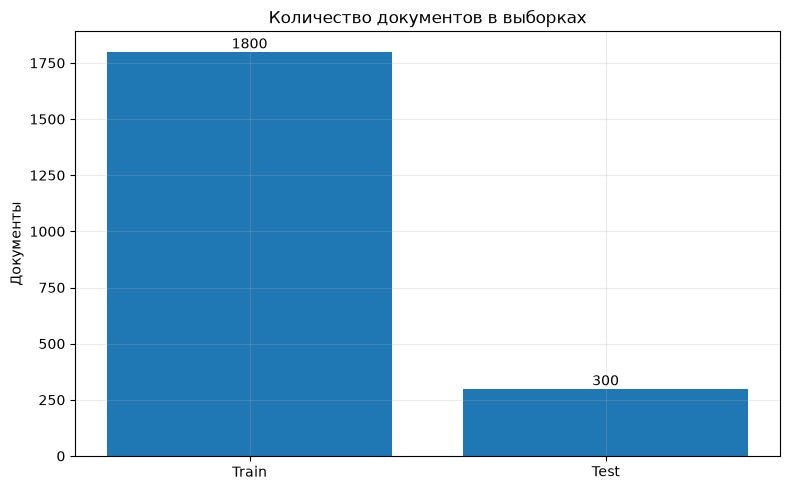

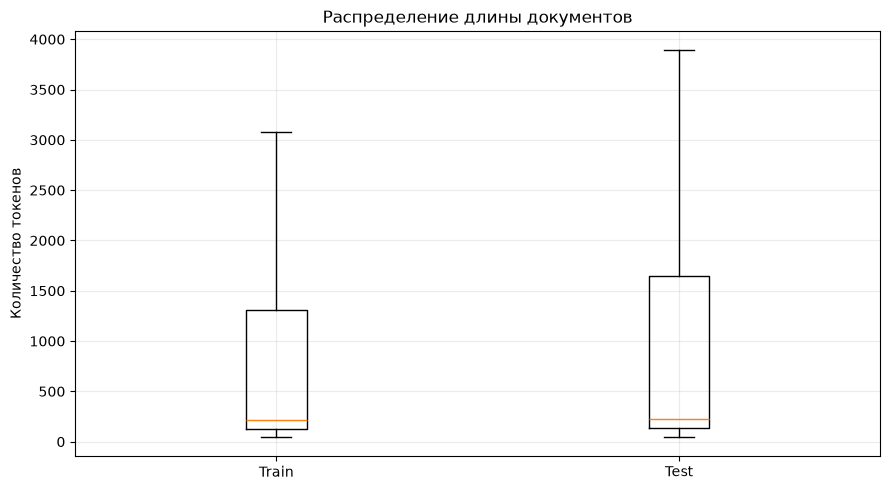

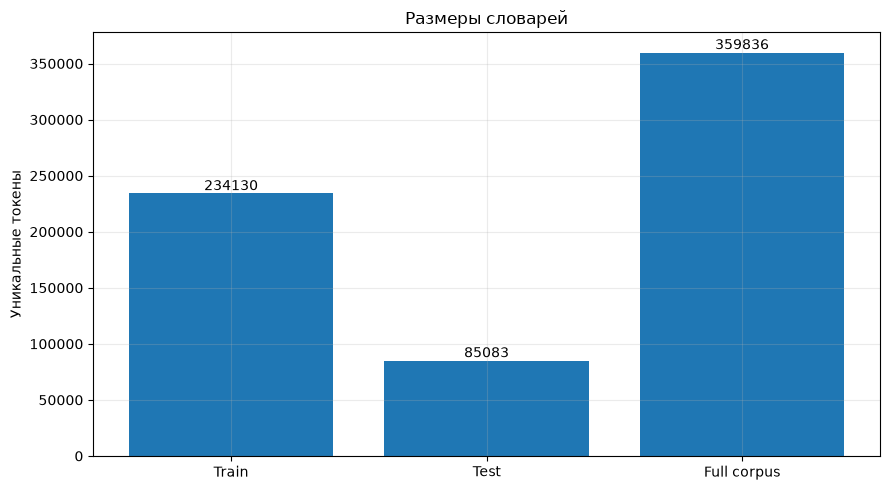


11. ПРОТОКОЛ ВЕРИФИКАЦИИ
PASS  | no_duplicate_train_ids
PASS  | no_duplicate_test_ids
PASS  | no_id_overlap
PASS  | all_train_documents_found
PASS  | all_test_documents_found
PASS  | no_exact_text_duplicates
PASS  | seed_consistent
PASS  | train_count_consistent
PASS  | test_count_consistent

Пройдено проверок: 9/9

ИТОГ ЗАДАНИЯ № 8
Все автоматические проверки пройдены.
Пересечений ID и полных текстовых дубликатов не найдено.

Важно: проверки не доказывают, что токенизаторы обучались исключительно на Train.
Для полного подтверждения отсутствия утечки необходимо также проверить код обучения задания № 6.

Файлы сохранены в:
/Users/lenar_966/Desktop/ML/NLP/Practika_1/reports/task8

Выполнение завершено.


In [20]:

# ============================================================
# ЗАДАНИЕ № 8
# ВЕРИФИКАЦИЯ РАЗБИЕНИЯ КОРПУСА И КОНТРОЛЬ УТЕЧКИ ДАННЫХ
# ============================================================

from pathlib import Path
from collections import Counter, defaultdict
from datetime import datetime
import hashlib
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. НАСТРОЙКА ПУТЕЙ
# ------------------------------------------------------------

PROJECT_DIR = (
    Path.home() / "Desktop" / "ML" / "NLP" / "Practika_1"
)

CORPUS_PATH = PROJECT_DIR / "data/processed/corpus.jsonl"
SPLIT6_PATH = PROJECT_DIR / "reports/task6/split.json"
SPLIT5_PATH = PROJECT_DIR / "reports/task5/split.json"
CONFIG_PATH = PROJECT_DIR / "reports/task6/experiment_config.json"

REPORT_DIR = PROJECT_DIR / "reports/task8"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
TOKEN_PATTERN = re.compile(r"[^\W_]+(?:[-'][^\W_]+)*", re.UNICODE)

print("=" * 75)
print("ЗАДАНИЕ № 8 — ВЕРИФИКАЦИЯ РАЗБИЕНИЯ И КОНТРОЛЬ УТЕЧКИ")
print("=" * 75)

# ------------------------------------------------------------
# 2. ЗАГРУЗКА КОРПУСА И СОХРАНЁННЫХ РАЗБИЕНИЙ
# ------------------------------------------------------------

def load_json(path):
    with open(path, "r", encoding="utf-8") as file:
        return json.load(file)

def make_key(source, doc_id):
    """Единый формат ключа документа."""
    source = str(source).strip().lower()
    doc_id = str(doc_id).strip()
    return (source, doc_id)

def normalize_source(source):
    source = str(source).strip().lower()
    if "lenta" in source:
        return "lenta"
    if "wiki" in source:
        return "wikipedia"
    return source

def parse_split_ids(values):
    """Преобразование сохранённых пар [source, id] в множество."""
    result = []
    for item in values:
        if isinstance(item, (list, tuple)) and len(item) == 2:
            result.append(make_key(item[0], item[1]))
        else:
            raise ValueError(f"Неожиданный формат идентификатора: {item}")
    return result

assert CORPUS_PATH.exists(), "Не найден corpus.jsonl"
assert SPLIT6_PATH.exists(), "Не найден split.json задания № 6"
assert CONFIG_PATH.exists(), "Не найден experiment_config.json"

split6 = load_json(SPLIT6_PATH)
config6 = load_json(CONFIG_PATH)

train_ids = parse_split_ids(split6["train_ids"])
test_ids = parse_split_ids(split6["test_ids"])

train_set = set(train_ids)
test_set = set(test_ids)

print("\n1. СОХРАНЁННОЕ РАЗБИЕНИЕ")
print("Seed:", split6.get("seed"))
print("Обучающих документов:", len(train_ids))
print("Тестовых документов:", len(test_ids))

# ------------------------------------------------------------
# 3. ПРОВЕРКА УНИКАЛЬНОСТИ ИДЕНТИФИКАТОРОВ
# ------------------------------------------------------------

duplicate_train_ids = len(train_ids) - len(train_set)
duplicate_test_ids = len(test_ids) - len(test_set)
id_intersection = train_set & test_set

print("\n2. ПРОВЕРКА ИДЕНТИФИКАТОРОВ")
print("Дубликатов ID в Train:", duplicate_train_ids)
print("Дубликатов ID в Test:", duplicate_test_ids)
print("Пересечение Train и Test:", len(id_intersection))

# ------------------------------------------------------------
# 4. ЗАГРУЗКА ДОКУМЕНТОВ
# ------------------------------------------------------------

documents = {}
duplicate_corpus_ids = 0
source_counts = Counter()

with open(CORPUS_PATH, "r", encoding="utf-8") as file:
    for line in file:
        if not line.strip():
            continue

        doc = json.loads(line)

        source = normalize_source(doc.get("source", ""))
        doc_id = str(doc.get("id", "")).strip()
        key = make_key(source, doc_id)

        if key in documents:
            duplicate_corpus_ids += 1

        documents[key] = doc
        source_counts[source] += 1

missing_train = train_set - set(documents)
missing_test = test_set - set(documents)

train_docs = [
    documents[key]
    for key in train_ids
    if key in documents
]

test_docs = [
    documents[key]
    for key in test_ids
    if key in documents
]

print("\n3. ПРОВЕРКА КОРПУСА")
print("Всего уникальных документов:", len(documents))
print("Повторяющихся ID в корпусе:", duplicate_corpus_ids)
print("Не найдено Train:", len(missing_train))
print("Не найдено Test:", len(missing_test))
print("Загружено Train:", len(train_docs))
print("Загружено Test:", len(test_docs))

assert not missing_train, (
    f"Не найдены обучающие документы: {list(missing_train)[:5]}"
)
assert not missing_test, (
    f"Не найдены тестовые документы: {list(missing_test)[:5]}"
)

# ------------------------------------------------------------
# 5. ТОКЕНИЗАЦИЯ И ОБЪЁМ ВЫБОРОК
# ------------------------------------------------------------

def tokenize(text):
    return TOKEN_PATTERN.findall(str(text).lower())

train_counter = Counter()
test_counter = Counter()

train_token_lengths = []
test_token_lengths = []

for doc in train_docs:
    tokens = tokenize(doc.get("text", ""))
    train_counter.update(tokens)
    train_token_lengths.append(len(tokens))

for doc in test_docs:
    tokens = tokenize(doc.get("text", ""))
    test_counter.update(tokens)
    test_token_lengths.append(len(tokens))

train_tokens = sum(train_counter.values())
test_tokens = sum(test_counter.values())
total_split_tokens = train_tokens + test_tokens

train_vocab = set(train_counter)
test_vocab = set(test_counter)

test_share = (
    test_tokens / total_split_tokens
    if total_split_tokens else 0
)

print("\n4. ОБЪЁМ ВЫБОРОК")
print("Train токенов:", f"{train_tokens:,}")
print("Test токенов:", f"{test_tokens:,}")
print("Доля Test по токенам:", f"{test_share:.2%}")
print("Train словарь:", len(train_vocab))
print("Test словарь:", len(test_vocab))

# ------------------------------------------------------------
# 6. OOV — НЕИЗВЕСТНЫЕ СЛОВА
# ------------------------------------------------------------

oov_words = test_vocab - train_vocab

oov_unique_count = len(oov_words)

oov_unique_share = (
    oov_unique_count / len(test_vocab)
    if test_vocab else 0
)

oov_occurrences = sum(
    count
    for word, count in test_counter.items()
    if word in oov_words
)

oov_occurrence_share = (
    oov_occurrences / test_tokens
    if test_tokens else 0
)

print("\n5. АНАЛИЗ OOV")
print("Уникальных OOV:", oov_unique_count)
print("Доля уникальных OOV:", f"{oov_unique_share:.2%}")
print("Употреблений OOV:", oov_occurrences)
print("Доля OOV-словоупотреблений:", f"{oov_occurrence_share:.2%}")

oov_df = pd.DataFrame(
    [
        {"word": word, "test_frequency": test_counter[word]}
        for word in oov_words
    ]
).sort_values(
    ["test_frequency", "word"],
    ascending=[False, True]
)

oov_df.to_csv(
    REPORT_DIR / "oov_words.csv",
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 7. СЛОВАРЬ ПОЛНОГО КОРПУСА
# ------------------------------------------------------------

full_counter = Counter()

for doc in documents.values():
    full_counter.update(tokenize(doc.get("text", "")))

full_vocab = set(full_counter)

vocab_intersection = train_vocab & full_vocab
vocab_union = train_vocab | full_vocab

jaccard = (
    len(vocab_intersection) / len(vocab_union)
    if vocab_union else 0
)

coverage = (
    len(vocab_intersection) / len(full_vocab)
    if full_vocab else 0
)

print("\n6. ПЕРЕСЕЧЕНИЕ СЛОВАРЕЙ")
print("Полный словарь:", len(full_vocab))
print("Обучающий словарь:", len(train_vocab))
print("Пересечение:", len(vocab_intersection))
print("Коэффициент Жаккара:", round(jaccard, 6))
print("Покрытие полного словаря:", f"{coverage:.2%}")

# ------------------------------------------------------------
# 8. ПОИСК ПОЛНЫХ ТЕКСТОВЫХ ДУБЛИКАТОВ
# ------------------------------------------------------------

def text_hash(text):
    normalized = " ".join(str(text).lower().split())
    return hashlib.sha256(
        normalized.encode("utf-8")
    ).hexdigest()

train_hashes = defaultdict(list)
test_hashes = defaultdict(list)

for key in train_ids:
    if key in documents:
        digest = text_hash(documents[key].get("text", ""))
        train_hashes[digest].append(key)

for key in test_ids:
    if key in documents:
        digest = text_hash(documents[key].get("text", ""))
        test_hashes[digest].append(key)

shared_hashes = set(train_hashes) & set(test_hashes)

duplicate_pairs = []

for digest in sorted(shared_hashes):
    for train_key in train_hashes[digest]:
        for test_key in test_hashes[digest]:
            duplicate_pairs.append({
                "train_source": train_key[0],
                "train_id": train_key[1],
                "test_source": test_key[0],
                "test_id": test_key[1],
                "sha256": digest
            })

duplicates_df = pd.DataFrame(
    duplicate_pairs,
    columns=[
        "train_source", "train_id",
        "test_source", "test_id", "sha256"
    ]
)

duplicates_df.to_csv(
    REPORT_DIR / "cross_split_duplicates.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n7. ПРОВЕРКА ТЕКСТОВЫХ ДУБЛИКАТОВ")
print("Совпадающих хешей Train/Test:", len(shared_hashes))
print("Пар одинаковых текстов:", len(duplicate_pairs))

# ------------------------------------------------------------
# 9. ПРОВЕРКА ПАРАМЕТРОВ ЭКСПЕРИМЕНТА
# ------------------------------------------------------------

seed_matches = (
    split6.get("seed") == config6.get("seed")
)

train_count_matches = (
    len(train_ids) == config6.get("train_documents")
)

test_count_matches = (
    len(test_ids) == config6.get("test_documents")
)

print("\n8. СОГЛАСОВАННОСТЬ КОНФИГУРАЦИИ")
print("Seed совпадает:", seed_matches)
print("Количество Train совпадает:", train_count_matches)
print("Количество Test совпадает:", test_count_matches)

# ------------------------------------------------------------
# 10. СРАВНЕНИЕ С РАЗБИЕНИЕМ ЗАДАНИЯ № 5
# ------------------------------------------------------------

task5_comparison = {
    "available": SPLIT5_PATH.exists(),
    "comparable": False
}

if SPLIT5_PATH.exists():
    split5 = load_json(SPLIT5_PATH)

    if (
        isinstance(split5, dict)
        and "train_ids" in split5
        and "test_ids" in split5
    ):
        try:
            train5 = set(parse_split_ids(split5["train_ids"]))
            test5 = set(parse_split_ids(split5["test_ids"]))

            task5_comparison = {
                "available": True,
                "comparable": True,
                "train5_count": len(train5),
                "test5_count": len(test5),
                "train_intersection": len(train5 & train_set),
                "test_intersection": len(test5 & test_set),
                "task6_test_in_task5_train": len(test_set & train5),
                "task6_train_in_task5_test": len(train_set & test5)
            }

        except (ValueError, TypeError) as error:
            task5_comparison["reason"] = str(error)
    else:
        task5_comparison["reason"] = (
            "В файле задания № 5 отсутствуют "
            "train_ids/test_ids в ожидаемом формате."
        )

print("\n9. СРАВНЕНИЕ С ЗАДАНИЕМ № 5")
for key, value in task5_comparison.items():
    print(f"{key}: {value}")

# ------------------------------------------------------------
# 11. СВОДНАЯ ТАБЛИЦА
# ------------------------------------------------------------

summary = pd.DataFrame([
    {
        "Выборка": "Train",
        "Документов": len(train_docs),
        "Токенов": train_tokens,
        "Уникальных токенов": len(train_vocab),
        "Средняя длина документа": np.mean(train_token_lengths),
        "Медианная длина документа": np.median(train_token_lengths)
    },
    {
        "Выборка": "Test",
        "Документов": len(test_docs),
        "Токенов": test_tokens,
        "Уникальных токенов": len(test_vocab),
        "Средняя длина документа": np.mean(test_token_lengths),
        "Медианная длина документа": np.median(test_token_lengths)
    }
])

print("\n10. СВОДНАЯ ТАБЛИЦА")
print(summary.to_string(index=False))

summary.to_csv(
    REPORT_DIR / "split_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 12. ВИЗУАЛИЗАЦИИ
# ------------------------------------------------------------

# График количества документов.
fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    ["Train", "Test"],
    [len(train_docs), len(test_docs)]
)

ax.set_title("Количество документов в выборках")
ax.set_ylabel("Документы")
ax.grid(axis="y", alpha=0.25)

for i, value in enumerate([len(train_docs), len(test_docs)]):
    ax.text(i, value, str(value), ha="center", va="bottom")

plt.tight_layout()
plt.savefig(
    REPORT_DIR / "documents_distribution.png",
    dpi=180
)
plt.show()

# График длины документов.
fig, ax = plt.subplots(figsize=(9, 5))

ax.boxplot(
    [train_token_lengths, test_token_lengths],
    tick_labels=["Train", "Test"],
    showfliers=False
)

ax.set_title("Распределение длины документов")
ax.set_ylabel("Количество токенов")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(
    REPORT_DIR / "document_lengths.png",
    dpi=180
)
plt.show()

# Сравнение словарей.
fig, ax = plt.subplots(figsize=(9, 5))

labels = ["Train", "Test", "Full corpus"]
values = [
    len(train_vocab),
    len(test_vocab),
    len(full_vocab)
]

ax.bar(labels, values)
ax.set_title("Размеры словарей")
ax.set_ylabel("Уникальные токены")
ax.grid(axis="y", alpha=0.25)

for i, value in enumerate(values):
    ax.text(i, value, str(value), ha="center", va="bottom")

plt.tight_layout()
plt.savefig(
    REPORT_DIR / "vocabulary_comparison.png",
    dpi=180
)
plt.show()

# ------------------------------------------------------------
# 13. ПРОТОКОЛ ПРОВЕРКИ
# ------------------------------------------------------------

checks = {
    "no_duplicate_train_ids": duplicate_train_ids == 0,
    "no_duplicate_test_ids": duplicate_test_ids == 0,
    "no_id_overlap": len(id_intersection) == 0,
    "all_train_documents_found": len(missing_train) == 0,
    "all_test_documents_found": len(missing_test) == 0,
    "no_exact_text_duplicates": len(shared_hashes) == 0,
    "seed_consistent": seed_matches,
    "train_count_consistent": train_count_matches,
    "test_count_consistent": test_count_matches
}

passed = sum(checks.values())
total_checks = len(checks)

print("\n11. ПРОТОКОЛ ВЕРИФИКАЦИИ")

for name, result in checks.items():
    status = "PASS" if result else "FAIL"
    print(f"{status:5s} | {name}")

print(f"\nПройдено проверок: {passed}/{total_checks}")

# ------------------------------------------------------------
# 14. СОХРАНЕНИЕ JSON-ОТЧЁТА
# ------------------------------------------------------------

report = {
    "task": 8,
    "generated_at": datetime.now().isoformat(),
    "seed": split6.get("seed"),
    "corpus_documents": len(documents),
    "train_documents": len(train_docs),
    "test_documents": len(test_docs),
    "train_tokens": train_tokens,
    "test_tokens": test_tokens,
    "test_token_share": test_share,
    "train_vocab_size": len(train_vocab),
    "test_vocab_size": len(test_vocab),
    "full_vocab_size": len(full_vocab),
    "oov_unique_count": oov_unique_count,
    "oov_unique_share": oov_unique_share,
    "oov_occurrences": oov_occurrences,
    "oov_occurrence_share": oov_occurrence_share,
    "vocab_jaccard": jaccard,
    "full_vocab_coverage": coverage,
    "duplicate_train_ids": duplicate_train_ids,
    "duplicate_test_ids": duplicate_test_ids,
    "id_overlap": len(id_intersection),
    "exact_text_duplicate_hashes": len(shared_hashes),
    "exact_text_duplicate_pairs": len(duplicate_pairs),
    "task5_comparison": task5_comparison,
    "checks": checks,
    "passed_checks": passed,
    "total_checks": total_checks
}

with open(
    REPORT_DIR / "verification_report.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        report,
        file,
        ensure_ascii=False,
        indent=2
    )

# ------------------------------------------------------------
# 15. ФИНАЛЬНЫЙ ВЫВОД
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("ИТОГ ЗАДАНИЯ № 8")
print("=" * 75)

if all(checks.values()):
    print("Все автоматические проверки пройдены.")
    print("Пересечений ID и полных текстовых дубликатов не найдено.")
else:
    print("Обнаружены нарушения или несогласованности.")
    print("Необходимо изучить проверки со статусом FAIL.")

print(
    "\nВажно: проверки не доказывают, что токенизаторы "
    "обучались исключительно на Train."
)
print(
    "Для полного подтверждения отсутствия утечки "
    "необходимо также проверить код обучения задания № 6."
)

print("\nФайлы сохранены в:")
print(REPORT_DIR)

print("\nВыполнение завершено.")



## Анализ результатов задания № 8

### 1. Общая характеристика разбиения корпуса

В рамках задания проведена верификация обучающей и тестовой выборок, использованных при исследовании субсловных моделей токенизации.

Исходный корпус содержит 21 937 уникальных документов. Для эксперимента использовано сохранённое разбиение задания № 6 с фиксированным значением `seed = 42`.

| Показатель | Train | Test |
|---|---:|---:|
| Количество документов | 1 800 | 300 |
| Количество токенов | 2 362 433 | 494 156 |
| Уникальных токенов | 234 130 | 85 083 |
| Средняя длина документа | 1 312,46 | 1 647,19 |
| Медианная длина документа | 214 | 227 |

Общий объём двух выборок составляет 2 856 589 токенов.

Доля тестовой выборки равна 17,30% по количеству токенов и 14,29% по количеству документов.

Средняя длина тестового документа составляет 1 647,19 токена, что превышает аналогичный показатель обучающей выборки на 334,72 токена, или приблизительно на 25,50%.

При этом медианные значения различаются значительно меньше: 214 токенов для Train и 227 токенов для Test.

Такое расхождение между средним и медианой указывает на асимметричность распределения длины документов и возможное влияние длинных текстов на средние значения.

### 2. Проверка идентификаторов документов

Проведена проверка уникальности идентификаторов документов и отсутствия пересечений между выборками.

Получены следующие результаты:

| Проверка | Результат |
|---|---:|
| Повторяющиеся ID в Train | 0 |
| Повторяющиеся ID в Test | 0 |
| Пересечение ID между Train и Test | 0 |
| Отсутствующие документы Train | 0 |
| Отсутствующие документы Test | 0 |
| Повторяющиеся ID в исходном корпусе | 0 |

Все документы, перечисленные в сохранённом разбиении, обнаружены в исходном корпусе.

Пересечение множеств идентификаторов Train и Test является пустым.

Таким образом, на уровне идентификаторов документы обучающей и тестовой выборок не пересекаются.

### 3. Анализ неизвестных токенов (OOV)

Для оценки лексических различий между выборками определены слова тестового набора, отсутствующие в обучающем словаре.

Получены следующие показатели:

| Показатель | Значение |
|---|---:|
| Размер словаря Train | 234 130 |
| Размер словаря Test | 85 083 |
| Количество уникальных OOV | 25 838 |
| Доля уникальных OOV | 30,37% |
| Количество употреблений OOV | 32 116 |
| Доля OOV-словоупотреблений | 6,50% |

Из 85 083 уникальных токенов тестовой выборки 25 838 отсутствуют в обучающем словаре.

Следовательно, доля уникальных неизвестных слов составляет 30,37%.

Однако при учёте частот словоупотреблений доля OOV существенно ниже — 6,50%.

Это означает, что значительная часть неизвестной лексики встречается относительно редко.

Большинство словоупотреблений тестовой выборки приходится на лексические единицы, уже представленные в обучающем наборе.

Полученные результаты демонстрируют важность субсловной токенизации: модели BPE, WordPiece и Unigram могут представлять многие неизвестные целые слова через комбинации известных субсловных единиц.

При этом показатель OOV в данном эксперименте рассчитан на уровне целых слов, поэтому его нельзя напрямую интерпретировать как долю специальных токенов `[UNK]` у субсловных моделей.

### 4. Анализ пересечения словарей

Для оценки лексического покрытия вычислены размер полного словаря корпуса, коэффициент Жаккара и доля словаря, представленная в обучающей выборке.

| Показатель | Значение |
|---|---:|
| Полный словарь | 359 836 |
| Словарь Train | 234 130 |
| Пересечение словарей | 234 130 |
| Коэффициент Жаккара | 0,650658 |
| Покрытие полного словаря | 65,07% |

Все 234 130 уникальных токенов обучающей выборки присутствуют в полном корпусе, что ожидаемо, поскольку обучающие документы являются его подмножеством.

Коэффициент Жаккара составляет 0,650658.

Это означает, что обучающая выборка содержит приблизительно 65,07% уникальных токенов полного корпуса.

Оставшиеся 34,93% словаря полного корпуса не представлены в рассматриваемой обучающей выборке.

Следует учитывать, что словарь Train сформирован только на 1 800 документах, поэтому неполное покрытие словаря всего корпуса является ожидаемым результатом.

Таким образом, обучающая выборка содержит значительную часть лексического разнообразия корпуса, но не охватывает все встречающиеся словоформы.

### 5. Проверка текстовых дубликатов

Дополнительно выполнена проверка совпадений текстов между обучающей и тестовой выборками.

Для каждого документа рассчитан SHA-256-хеш нормализованного текста.

Перед хешированием выполнялись приведение к нижнему регистру и нормализация пробельных символов.

Результаты проверки:

| Показатель | Значение |
|---|---:|
| Совпадающие хеши Train/Test | 0 |
| Пары одинаковых текстов | 0 |

Полностью совпадающих текстов между обучающей и тестовой выборками не обнаружено.

Следовательно, проверка не выявила утечки данных в форме точного дублирования текстов.

Однако хеширование не позволяет обнаружить частично совпадающие документы, перефразированные тексты или близкие по содержанию публикации.

Для выявления подобных случаев потребовались бы дополнительные методы поиска почти дубликатов, например MinHash или сравнение текстовых представлений.

### 6. Проверка воспроизводимости

Проведено сравнение сохранённого разбиения с конфигурацией эксперимента задания № 6.

Установлено:

- значение `seed = 42` совпадает;
- количество обучающих документов соответствует конфигурации;
- количество тестовых документов соответствует конфигурации;
- сохранённые идентификаторы позволяют повторно сформировать те же выборки из исходного корпуса.

Таким образом, согласованность параметров эксперимента подтверждена.

Использование сохранённых идентификаторов обеспечивает возможность повторного восстановления исследованных выборок без выполнения нового случайного разбиения.

При этом проверка согласованности seed и идентификаторов сама по себе не подтверждает повторное получение идентичного разбиения при запуске первоначального алгоритма. Для этого потребовалось бы повторно выполнить исходный алгоритм формирования выборок.

### 7. Сопоставление с заданием № 5

При сравнении разбиений заданий № 5 и № 6 выявлено различие в формате хранения идентификаторов.

В задании № 6 идентификаторы представлены парами вида:

`["lenta", "lenta_1000"]`

В задании № 5 обнаружен формат отдельной строки:

`"lenta_1002"`

По этой причине автоматическое сопоставление разбиений не было завершено.

Данное ограничение связано с форматом представления данных и не свидетельствует о наличии утечки.

Для полноценного сравнения необходимо привести идентификаторы обоих заданий к единому формату.

### 8. Результаты автоматической верификации

Выполнено девять автоматических проверок корректности разбиения.

| Проверка | Результат |
|---|---|
| Уникальность ID Train | PASS |
| Уникальность ID Test | PASS |
| Отсутствие пересечения ID | PASS |
| Наличие документов Train | PASS |
| Наличие документов Test | PASS |
| Отсутствие точных текстовых дубликатов | PASS |
| Согласованность seed | PASS |
| Согласованность размера Train | PASS |
| Согласованность размера Test | PASS |

Все 9 проверок завершились успешно.

Доля успешно пройденных проверок составила 100%.

Это подтверждает корректность сохранённого разбиения по проверенным критериям.

Вместе с тем результаты не являются исчерпывающим доказательством отсутствия всех возможных форм утечки данных.

### 9. Итоговый вывод

В ходе выполнения задания № 8 проведена верификация разбиения русскоязычного корпуса на обучающую и тестовую выборки.

Для анализа использованы 1 800 обучающих и 300 тестовых документов, содержащих соответственно 2 362 433 и 494 156 токенов.

Установлено отсутствие повторяющихся идентификаторов, пересечений документов между выборками и точных текстовых дубликатов.

Анализ OOV показал, что 30,37% уникальных слов тестовой выборки отсутствуют в обучающем словаре. При этом доля таких слов по количеству употреблений составляет только 6,50%.

Коэффициент Жаккара между обучающим и полным словарями составил 0,650658, что соответствует покрытию 65,07% лексического состава корпуса.

Все девять автоматических проверок успешно пройдены, а параметры сохранённого разбиения согласуются с конфигурацией предыдущего эксперимента.

Таким образом, корректность разбиения подтверждена на уровне идентификаторов документов, доступности данных, точных текстовых совпадений и сохранённых параметров эксперимента.

Для окончательного подтверждения отсутствия утечки необходимо дополнительно проверить фактический код обучения субсловных моделей и исключить использование тестовых текстов на этапе обучения.

Полученные результаты формируют основу для воспроизводимого сравнения методов токенизации и последующих экспериментов по обработке естественного языка.



## Задание № 9. Разработка универсального препроцессора текста

### Цель работы

Разработать универсальный компонент предварительной обработки естественного языка, объединяющий методы токенизации и морфологической нормализации в едином программном интерфейсе.

### Постановка задачи

Необходимо реализовать Python-класс `NLPPreprocessor`, который:

1. Поддерживает единый интерфейс `.fit()`, `.transform()` и `.fit_transform()`.
2. Выполняет регулярную токенизацию, стемминг Snowball и лемматизацию pymorphy3.
3. Поддерживает ранее обученные модели BPE, WordPiece и Unigram с размерами словарей 8 000, 16 000 и 32 000.
4. Сохраняет внутреннее состояние: параметры, словари, список стоп-слов и сведения о токенизаторе.
5. Обеспечивает сериализацию и десериализацию с помощью `joblib`.
6. Гарантирует одинаковые результаты повторных вызовов `.transform()` при неизменных входных данных и состоянии.
7. Поддерживает интеграцию с конвейерами `scikit-learn`.
8. Обеспечивает обработку обучающей и тестовой выборок без повторного обучения на тестовых данных.

### Теоретические основы

**Препроцессор текста** — программный компонент, преобразующий исходный текст в структурированное представление, пригодное для последующего анализа и машинного обучения.

Метод `.fit(X)` формирует или фиксирует внутреннее состояние компонента на основе обучающих данных.

Метод `.transform(X)` применяет настроенные преобразования к новым данным без изменения обученного состояния.

Метод `.fit_transform(X)` последовательно выполняет обучение и преобразование.

Для субсловных моделей, обученных ранее, используется загрузка сохранённых артефактов. Повторное обучение токенизаторов в данном задании не производится.

### Критерии корректности

- Повторные вызовы `.transform()` возвращают идентичные результаты.
- После сериализации и десериализации результаты обработки не изменяются.
- Обучение не использует тестовую выборку.
- Все поддерживаемые методы работают через одинаковый программный интерфейс.
- Препроцессор совместим с базовыми соглашениями `scikit-learn`.
- Результаты тестирования и конфигурации сохраняются в отчёт.

### Ожидаемые результаты

В результате выполнения задания создаётся модуль `src/nlp_preprocessor.py`, содержащий класс `NLPPreprocessor`, а также сериализованные экземпляры препроцессоров и отчёт о проверке их корректности и воспроизводимости.


In [21]:

# ============================================================
# ЗАДАНИЕ № 9 — УНИВЕРСАЛЬНЫЙ NLP-ПРЕПРОЦЕССОР
# ============================================================

from pathlib import Path
from collections import Counter
from time import perf_counter
import json
import sys
import textwrap
import hashlib

import joblib
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. НАСТРОЙКА ПРОЕКТА
# ------------------------------------------------------------

ROOT = Path.home() / "Desktop" / "ML" / "NLP" / "Practika_1"

SRC_DIR = ROOT / "src"
MODEL_DIR = ROOT / "models" / "task9"
REPORT_DIR = ROOT / "reports" / "task9"
TOKENIZER_DIR = ROOT / "models" / "task6"

for directory in (SRC_DIR, MODEL_DIR, REPORT_DIR):
    directory.mkdir(parents=True, exist_ok=True)

(SRC_DIR / "__init__.py").touch(exist_ok=True)

print("=" * 75)
print("ЗАДАНИЕ № 9 — УНИВЕРСАЛЬНЫЙ NLP-ПРЕПРОЦЕССОР")
print("=" * 75)

# ------------------------------------------------------------
# 2. СОЗДАНИЕ МОДУЛЯ
# ------------------------------------------------------------

module_code = r'''
from pathlib import Path
from collections import Counter
import re
import json

import joblib
from sklearn.base import BaseEstimator, TransformerMixin


class NLPPreprocessor(BaseEstimator, TransformerMixin):
    """
    Универсальный препроцессор русскоязычных текстов.

    Методы:
        regex
        snowball
        pymorphy3
        bpe
        wordpiece
        unigram

    Для субсловных моделей требуется tokenizer_path.

    fit() формирует внутреннее состояние.
    transform() не изменяет состояние и возвращает
    список списков токенов.
    """

    VALID_METHODS = (
        "regex", "snowball", "pymorphy3",
        "bpe", "wordpiece", "unigram"
    )

    SUBWORD_METHODS = ("bpe", "wordpiece", "unigram")

    def __init__(
        self,
        method="regex",
        tokenizer_path=None,
        lowercase=True,
        remove_stopwords=False,
        stopwords=None,
        min_frequency=1
    ):
        self.method = method
        self.tokenizer_path = tokenizer_path
        self.lowercase = lowercase
        self.remove_stopwords = remove_stopwords
        self.stopwords = stopwords
        self.min_frequency = min_frequency

    @staticmethod
    def _to_texts(X):
        if isinstance(X, str):
            return [X]

        if X is None:
            raise ValueError("X не должен быть None")

        return ["" if x is None else str(x) for x in X]

    def _basic_tokens(self, text):
        if self.lowercase:
            text = text.lower()

        return re.findall(
            r"[^\W_]+(?:[-'][^\W_]+)*",
            text,
            flags=re.UNICODE
        )

    def _normalize_token(self, token):
        if self.method == "snowball":
            return self._stemmer.stem(token)

        if self.method == "pymorphy3":
            return self._morph.parse(token)[0].normal_form

        return token

    def fit(self, X, y=None):
        if self.method not in self.VALID_METHODS:
            raise ValueError(
                f"Неизвестный метод: {self.method}"
            )

        if self.min_frequency < 1:
            raise ValueError(
                "min_frequency должен быть >= 1"
            )

        texts = self._to_texts(X)

        self.stopwords_ = set(
            str(word).lower()
            for word in (self.stopwords or [])
        )

        self.vocabulary_ = {}
        self.tokenizer_ = None
        self._stemmer = None
        self._morph = None

        if self.method in self.SUBWORD_METHODS:
            from tokenizers import Tokenizer

            if self.tokenizer_path is None:
                raise ValueError(
                    "Для субсловной модели нужен tokenizer_path"
                )

            path = Path(self.tokenizer_path)

            if not path.exists():
                raise FileNotFoundError(path)

            self.tokenizer_ = Tokenizer.from_file(str(path))

            # Словарь загружается из готовой модели.
            self.vocabulary_ = self.tokenizer_.get_vocab()

        else:
            if self.method == "snowball":
                from nltk.stem.snowball import SnowballStemmer
                self._stemmer = SnowballStemmer("russian")

            elif self.method == "pymorphy3":
                import pymorphy3
                self._morph = pymorphy3.MorphAnalyzer()

            counter = Counter()

            for text in texts:
                tokens = self._basic_tokens(text)

                for token in tokens:
                    if (
                        self.remove_stopwords
                        and token in self.stopwords_
                    ):
                        continue

                    normalized = self._normalize_token(token)
                    counter[normalized] += 1

            self.vocabulary_ = {
                token: count
                for token, count in counter.items()
                if count >= self.min_frequency
            }

        self.is_fitted_ = True
        self.n_fit_documents_ = len(texts)
        self.vocabulary_size_ = len(self.vocabulary_)

        return self

    def transform(self, X):
        from sklearn.utils.validation import check_is_fitted

        check_is_fitted(self, "is_fitted_")

        texts = self._to_texts(X)
        results = []

        for text in texts:

            if self.method in self.SUBWORD_METHODS:
                # Сохраняем настройки готового токенизатора.
                # Дополнительное lowercasing здесь не выполняем.
                tokens = self.tokenizer_.encode(text).tokens

                if self.remove_stopwords:
                    raise ValueError(
                        "Удаление стоп-слов для субсловной "
                        "токенизации не поддерживается: "
                        "оно может нарушить сегментацию."
                    )

            else:
                tokens = self._basic_tokens(text)

                if self.remove_stopwords:
                    tokens = [
                        token for token in tokens
                        if token not in self.stopwords_
                    ]

                tokens = [
                    self._normalize_token(token)
                    for token in tokens
                ]

                # min_frequency применяется к обученному словарю.
                # Неизвестные единицы явно помечаются.
                tokens = [
                    token if token in self.vocabulary_ else "[UNK]"
                    for token in tokens
                ]

            results.append(tokens)

        return results

    def fit_transform(self, X, y=None, **fit_params):
        return self.fit(X, y).transform(X)

    def save(self, path):
        from sklearn.utils.validation import check_is_fitted

        check_is_fitted(self, "is_fitted_")

        path = Path(path)
        path.parent.mkdir(parents=True, exist_ok=True)

        joblib.dump(self, path)
        return path

    @classmethod
    def load(cls, path):
        obj = joblib.load(path)

        if not isinstance(obj, cls):
            raise TypeError(
                "Файл не содержит NLPPreprocessor"
            )

        return obj

    def get_state_summary(self):
        from sklearn.utils.validation import check_is_fitted

        check_is_fitted(self, "is_fitted_")

        return {
            "method": self.method,
            "tokenizer_path": (
                str(self.tokenizer_path)
                if self.tokenizer_path else None
            ),
            "lowercase": self.lowercase,
            "remove_stopwords": self.remove_stopwords,
            "min_frequency": self.min_frequency,
            "fit_documents": self.n_fit_documents_,
            "vocabulary_size": self.vocabulary_size_,
            "stopwords_count": len(self.stopwords_)
        }
'''

MODULE_PATH = SRC_DIR / "nlp_preprocessor.py"
MODULE_PATH.write_text(module_code, encoding="utf-8")

print("\nМодуль создан:")
print(MODULE_PATH)

# ------------------------------------------------------------
# 3. ИМПОРТ КЛАССА
# ------------------------------------------------------------

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import importlib
import nlp_preprocessor

importlib.reload(nlp_preprocessor)

from nlp_preprocessor import NLPPreprocessor

# ------------------------------------------------------------
# 4. ЗАГРУЗКА РЕАЛЬНЫХ TRAIN / TEST
# ------------------------------------------------------------

CORPUS_PATH = ROOT / "data/processed/corpus.jsonl"
SPLIT_PATH = ROOT / "reports/task6/split.json"

with open(SPLIT_PATH, encoding="utf-8") as f:
    split = json.load(f)

def normalize_source(source):
    source = str(source).lower()
    if "lenta" in source:
        return "lenta"
    if "wiki" in source:
        return "wikipedia"
    return source

def split_keys(values):
    return {
        (str(source).lower(), str(doc_id))
        for source, doc_id in values
    }

train_keys = split_keys(split["train_ids"])
test_keys = split_keys(split["test_ids"])

assert not (train_keys & test_keys)

train_texts = []
test_texts = []

with open(CORPUS_PATH, encoding="utf-8") as f:
    for line in f:
        if not line.strip():
            continue

        doc = json.loads(line)

        key = (
            normalize_source(doc["source"]),
            str(doc["id"])
        )

        if key in train_keys:
            train_texts.append(doc["text"])

        elif key in test_keys:
            test_texts.append(doc["text"])

assert len(train_texts) == 1800
assert len(test_texts) == 300

print("\nДанные загружены:")
print("Train:", len(train_texts))
print("Test:", len(test_texts))
print("Seed:", split["seed"])

# ------------------------------------------------------------
# 5. ПОДГОТОВКА СПИСКА СТОП-СЛОВ
# ------------------------------------------------------------

# Используем фиксированный список без загрузки NLTK.
STOPWORDS = sorted(set("""
и в во не что он на я с со как а то все она так его но
да ты к у же вы за бы по только ее мне было вот от меня
еще нет о из ему теперь когда даже ну вдруг ли если уже
или ни быть был него до вас опять уж вам ведь там потом
себя ничего ей может они тут где есть надо ней для мы
тебя их чем была сам чтоб без будто чего раз тоже себе
под будет тогда кто этот того потому этого какой совсем
ним здесь этом один почти мой тем чтобы сейчас были
куда зачем всех никогда можно при наконец два об другой
хоть после над больше тот через эти нас про всего них
какая много разве три эту моя впрочем хорошо свою этой
перед иногда лучше чуть том нельзя такой им более всегда
конечно всю между это также который которая которые
которое которых которым которого которой является
""".split()))

# ------------------------------------------------------------
# 6. ОПРЕДЕЛЕНИЕ КОНФИГУРАЦИЙ
# ------------------------------------------------------------

configs = [
    {
        "name": "regex",
        "method": "regex",
        "tokenizer_path": None
    },
    {
        "name": "snowball",
        "method": "snowball",
        "tokenizer_path": None
    },
    {
        "name": "pymorphy3",
        "method": "pymorphy3",
        "tokenizer_path": None
    }
]

for method in ("bpe", "wordpiece", "unigram"):
    for vocab_size in (8000, 16000, 32000):

        name = f"{method}_{vocab_size}"

        path = TOKENIZER_DIR / f"{name}.json"

        assert path.exists(), f"Модель не найдена: {path}"

        configs.append({
            "name": name,
            "method": method,
            "tokenizer_path": str(path)
        })

print("\nКонфигураций:", len(configs))

# ------------------------------------------------------------
# 7. ОБУЧЕНИЕ / ЗАГРУЗКА СОСТОЯНИЯ
# ------------------------------------------------------------

# Для морфологических методов fit строит словарь.
# Для BPE/WordPiece/Unigram fit загружает готовую модель.
#
# Используем все 1800 Train-документов.
# Test передаётся только в transform.

results = []
examples = []
states = []

TEST_EXAMPLES = test_texts[:20]

for cfg in configs:

    name = cfg["name"]

    print("\n" + "-" * 65)
    print("МЕТОД:", name)

    processor = NLPPreprocessor(
        method=cfg["method"],
        tokenizer_path=cfg["tokenizer_path"],
        lowercase=True,
        remove_stopwords=False,
        stopwords=STOPWORDS,
        min_frequency=1
    )

    # fit — только Train.
    t0 = perf_counter()
    processor.fit(train_texts)
    fit_time = perf_counter() - t0

    # transform — Test.
    t0 = perf_counter()
    output1 = processor.transform(TEST_EXAMPLES)
    transform_time = perf_counter() - t0

    # Повторная обработка тех же данных.
    output2 = processor.transform(TEST_EXAMPLES)

    deterministic = output1 == output2

    # Сериализация.
    model_path = MODEL_DIR / f"{name}.joblib"

    processor.save(model_path)

    # Десериализация.
    loaded = NLPPreprocessor.load(model_path)

    output3 = loaded.transform(TEST_EXAMPLES)

    serialization_ok = output1 == output3

    # Проверка интерфейса sklearn.
    sklearn_interface = all(
        hasattr(processor, attribute)
        for attribute in (
            "fit", "transform", "fit_transform",
            "get_params", "set_params"
        )
    )

    # Проверка сохранности внутреннего состояния.
    state_before = processor.get_state_summary()
    state_after = loaded.get_state_summary()

    state_ok = state_before == state_after

    lengths = [len(tokens) for tokens in output1]

    total_tokens = sum(lengths)

    unique_tokens = len({
        token
        for tokens in output1
        for token in tokens
    })

    result = {
        "method": name,
        "fit_seconds": round(fit_time, 4),
        "transform_seconds": round(transform_time, 4),
        "fit_documents": len(train_texts),
        "test_documents_checked": len(TEST_EXAMPLES),
        "vocabulary_size": processor.vocabulary_size_,
        "output_tokens": total_tokens,
        "unique_output_tokens": unique_tokens,
        "mean_tokens_per_document": round(
            float(np.mean(lengths)), 4
        ),
        "deterministic": deterministic,
        "serialization_ok": serialization_ok,
        "state_ok": state_ok,
        "sklearn_interface": sklearn_interface,
        "model_size_mb": round(
            model_path.stat().st_size / (1024 ** 2),
            4
        )
    }

    results.append(result)

    states.append({
        "name": name,
        **state_before
    })

    examples.append({
        "method": name,
        "text": TEST_EXAMPLES[0][:250],
        "tokens": " | ".join(output1[0][:40])
    })

    print("Время fit:", result["fit_seconds"], "с")
    print("Время transform:", result["transform_seconds"], "с")
    print("Размер словаря:", result["vocabulary_size"])
    print("Детерминизм:", deterministic)
    print("Сериализация:", serialization_ok)
    print("Состояние:", state_ok)
    print("Интерфейс sklearn:", sklearn_interface)
    print("Размер модели:", result["model_size_mb"], "МБ")

# ------------------------------------------------------------
# 8. ПРОВЕРКА ИСПОЛЬЗОВАНИЯ СТОП-СЛОВ
# ------------------------------------------------------------

stop_processor = NLPPreprocessor(
    method="regex",
    remove_stopwords=True,
    stopwords=STOPWORDS
)

stop_processor.fit(train_texts)

stop_example = (
    "И в университете студенты изучают "
    "обработку естественного языка."
)

stop_result = stop_processor.transform([stop_example])[0]

print("\nПРОВЕРКА СТОП-СЛОВ")
print("Исходный текст:", stop_example)
print("После обработки:", stop_result)

# ------------------------------------------------------------
# 9. ПРОВЕРКА НЕИЗВЕСТНЫХ СЛОВ
# ------------------------------------------------------------

# Для регулярной токенизации неизвестные слова
# заменяются на [UNK], поскольку словарь фиксируется в fit.

unknown_example = (
    "ультраэкспериментальнонесуществующее слово"
)

unknown_result = stop_processor.transform(
    [unknown_example]
)[0]

print("\nПРОВЕРКА НЕИЗВЕСТНЫХ СЛОВ")
print("Результат:", unknown_result)

# ------------------------------------------------------------
# 10. СОХРАНЕНИЕ ТАБЛИЦ
# ------------------------------------------------------------

results_df = pd.DataFrame(results)
examples_df = pd.DataFrame(examples)
states_df = pd.DataFrame(states)

results_df.to_csv(
    REPORT_DIR / "preprocessor_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

examples_df.to_csv(
    REPORT_DIR / "transformation_examples.csv",
    index=False,
    encoding="utf-8-sig"
)

states_df.to_csv(
    REPORT_DIR / "state_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 11. ПРОВЕРКА ВСЕХ КОНФИГУРАЦИЙ
# ------------------------------------------------------------

check_columns = [
    "deterministic",
    "serialization_ok",
    "state_ok",
    "sklearn_interface"
]

checks_passed = int(
    results_df[check_columns].to_numpy().sum()
)

checks_total = len(results_df) * len(check_columns)

all_passed = bool(
    results_df[check_columns].to_numpy().all()
)

print("\n" + "=" * 75)
print("ИТОГОВАЯ ТАБЛИЦА")
print("=" * 75)

print(results_df.to_string(index=False))

print("\n" + "=" * 75)
print("ПРОТОКОЛ ВЕРИФИКАЦИИ")
print("=" * 75)

print("Конфигураций:", len(results_df))
print("Проверок:", checks_total)
print("Успешных:", checks_passed)
print("Все пройдены:", all_passed)

# ------------------------------------------------------------
# 12. ПРОВЕРКА СОВМЕСТИМОСТИ С PIPELINE
# ------------------------------------------------------------

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

# Pipeline с нашим препроцессором.
# Выход — последовательности токенов.
pipeline = Pipeline([
    (
        "preprocessor",
        NLPPreprocessor(method="regex")
    )
])

pipeline.fit(train_texts)

pipeline_result = pipeline.transform(
    test_texts[:3]
)

print("\nПРОВЕРКА SCIKIT-LEARN PIPELINE")
print("Pipeline выполнен:", len(pipeline_result) == 3)
print("Тип результата:", type(pipeline_result).__name__)
print("Пример токенов:", pipeline_result[0][:15])

# ------------------------------------------------------------
# 13. СОХРАНЕНИЕ КОНФИГУРАЦИИ
# ------------------------------------------------------------

experiment = {
    "task": 9,
    "seed": split["seed"],
    "train_documents": len(train_texts),
    "test_documents": len(test_texts),
    "tested_documents_per_method": len(TEST_EXAMPLES),
    "methods": [cfg["name"] for cfg in configs],
    "checks_passed": checks_passed,
    "checks_total": checks_total,
    "all_passed": all_passed,
    "stopwords_count": len(STOPWORDS),
    "module_path": str(MODULE_PATH),
    "model_directory": str(MODEL_DIR),
    "notes": [
        "fit выполняется на Train",
        "transform проверяется на Test",
        "субсловные модели загружаются из задания 6",
        "результаты проверяются после joblib-сериализации"
    ]
}

with open(
    REPORT_DIR / "experiment_config.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        experiment,
        f,
        ensure_ascii=False,
        indent=2
    )

# ------------------------------------------------------------
# 14. ФИНАЛЬНЫЙ РЕЗУЛЬТАТ
# ------------------------------------------------------------

assert all_passed, (
    "Некоторые проверки не пройдены. "
    "Необходимо изучить итоговую таблицу."
)

assert len(results_df) == 12

print("\n" + "=" * 75)
print("ЗАДАНИЕ № 9 — ВЫПОЛНЕНИЕ ЗАВЕРШЕНО")
print("=" * 75)

print("Создан модуль:", MODULE_PATH)
print("Модели сохранены:", MODEL_DIR)
print("Отчёты сохранены:", REPORT_DIR)
print("Все проверки:", checks_passed, "/", checks_total)


ЗАДАНИЕ № 9 — УНИВЕРСАЛЬНЫЙ NLP-ПРЕПРОЦЕССОР

Модуль создан:
/Users/lenar_966/Desktop/ML/NLP/Practika_1/src/nlp_preprocessor.py

Данные загружены:
Train: 1800
Test: 300
Seed: 42

Конфигураций: 12

-----------------------------------------------------------------
МЕТОД: regex
Время fit: 0.8959 с
Время transform: 0.001 с
Размер словаря: 234130
Детерминизм: True
Сериализация: True
Состояние: True
Интерфейс sklearn: True
Размер модели: 5.0688 МБ

-----------------------------------------------------------------
МЕТОД: snowball
Время fit: 30.9172 с
Время transform: 0.0426 с
Размер словаря: 114553
Детерминизм: True
Сериализация: True
Состояние: True
Интерфейс sklearn: True
Размер модели: 2.0992 МБ

-----------------------------------------------------------------
МЕТОД: pymorphy3
Время fit: 108.7553 с
Время transform: 0.1569 с
Размер словаря: 120848
Детерминизм: True
Сериализация: True
Состояние: True
Интерфейс sklearn: True
Размер модели: 2.4188 МБ

-----------------------------------------


## Анализ результатов задания № 9

### 1. Разработка универсального NLP-препроцессора

В рамках задания разработан универсальный класс `NLPPreprocessor`, обеспечивающий единый программный интерфейс для методов токенизации и морфологической нормализации русскоязычных текстов.

Класс реализован в отдельном Python-модуле `src/nlp_preprocessor.py` и поддерживает методы:

- `.fit()` — формирование внутреннего состояния на обучающих данных;
- `.transform()` — преобразование новых текстов с использованием сохранённого состояния;
- `.fit_transform()` — последовательное выполнение обучения и преобразования;
- `.save()` — сериализация обученного экземпляра;
- `.load()` — восстановление экземпляра из сохранённого файла.

В архитектуре использованы базовые интерфейсы `BaseEstimator` и `TransformerMixin` библиотеки `scikit-learn`.

Это обеспечивает возможность интеграции разработанного компонента в конвейеры машинного обучения.

### 2. Организация эксперимента

Для проверки использовано сохранённое разбиение корпуса из задания № 6.

Основные параметры:

| Показатель | Значение |
|---|---:|
| Обучающих документов | 1 800 |
| Тестовых документов | 300 |
| Документов для проверки transform | 20 |
| Значение seed | 42 |
| Количество конфигураций | 12 |
| Количество автоматических проверок | 48 |

Метод `.fit()` вызывался на обучающей выборке из 1 800 документов.

Метод `.transform()` проверялся на 20 документах тестовой выборки.

Для регулярной токенизации и морфологической нормализации внутренние словари формировались на обучающих данных.

Для BPE, WordPiece и Unigram использовались ранее обученные токенизаторы, загруженные из сохранённых JSON-файлов.

Таким образом, в рамках задания № 9 повторное обучение субсловных моделей не выполнялось.

### 3. Сравнение времени формирования состояния

Получены следующие результаты:

| Метод | Время fit, с | Размер словаря |
|---|---:|---:|
| Regex | 0,8959 | 234 130 |
| Snowball | 30,9172 | 114 553 |
| pymorphy3 | 108,7553 | 120 848 |
| BPE 8 000 | 0,0376 | 8 000 |
| BPE 16 000 | 0,0268 | 16 000 |
| BPE 32 000 | 0,0420 | 32 000 |
| WordPiece 8 000 | 0,0061 | 8 000 |
| WordPiece 16 000 | 0,0091 | 16 000 |
| WordPiece 32 000 | 0,0178 | 32 000 |
| Unigram 8 000 | 0,0108 | 8 000 |
| Unigram 16 000 | 0,0221 | 16 000 |
| Unigram 32 000 | 0,0486 | 32 000 |

Наименьшее время среди методов, формирующих словарь непосредственно из обучающих документов, показала регулярная токенизация — 0,8959 секунды.

Стемминг Snowball потребовал 30,9172 секунды, а лемматизация pymorphy3 — 108,7553 секунды.

Таким образом, pymorphy3 выполнял формирование состояния приблизительно в 3,52 раза дольше Snowball и в 121,39 раза дольше регулярной токенизации.

Увеличение вычислительных затрат объясняется необходимостью выполнения морфологического анализа слов.

Субсловные модели показали значительно меньшее время выполнения `.fit()`, поскольку на данном этапе выполнялась только загрузка ранее обученных токенизаторов.

Следовательно, приведённые значения времени для BPE, WordPiece и Unigram не являются временем их первоначального обучения и не должны напрямую сравниваться с полной процедурой построения словарей морфологических методов.

### 4. Сравнение скорости преобразования текстов

Для оценки производительности метода `.transform()` использованы 20 документов тестовой выборки.

| Метод | Время transform, с |
|---|---:|
| Regex | 0,0010 |
| Snowball | 0,0426 |
| pymorphy3 | 0,1569 |
| BPE 8 000 | 0,0147 |
| BPE 16 000 | 0,0086 |
| BPE 32 000 | 0,0102 |
| WordPiece 8 000 | 0,0083 |
| WordPiece 16 000 | 0,0079 |
| WordPiece 32 000 | 0,0071 |
| Unigram 8 000 | 0,0187 |
| Unigram 16 000 | 0,0195 |
| Unigram 32 000 | 0,0207 |

Наименьшее время преобразования показала регулярная токенизация — 0,0010 секунды.

Среди субсловных моделей минимальное время получено для WordPiece 32 000 — 0,0071 секунды.

Лемматизация pymorphy3 оказалась наиболее затратной по времени и потребовала 0,1569 секунды.

Это связано с выполнением морфологического анализа каждого слова.

Полученные результаты показывают, что регулярная токенизация подходит для сценариев с минимальными требованиями к лингвистической обработке, тогда как более сложные методы требуют дополнительных вычислительных ресурсов.

Следует учитывать, что измерения выполнены на небольшой тестовой выборке без многократных повторов, поэтому результаты отражают производительность конкретного запуска, а не статистически устойчивые оценки скорости.

### 5. Анализ размеров словарей

Для трёх методов поверхностной и морфологической обработки получены следующие размеры словарей:

| Метод | Уникальных токенов | Сокращение относительно Regex |
|---|---:|---:|
| Regex | 234 130 | 0% |
| Snowball | 114 553 | 51,07% |
| pymorphy3 | 120 848 | 48,38% |

Стемминг Snowball уменьшил количество уникальных единиц с 234 130 до 114 553, обеспечив сокращение словаря на 51,07%.

Лемматизация pymorphy3 сократила словарь до 120 848 единиц, или на 48,38%.

Таким образом, Snowball обеспечил более сильное уменьшение лексической размерности.

Однако более интенсивное сокращение словаря не означает более высокую лингвистическую точность.

Стемминг основан на формальных преобразованиях слов, тогда как лемматизация использует морфологическую информацию и приводит словоформы к нормативным начальным формам.

Следовательно, выбор между методами должен определяться требованиями конкретной NLP-задачи.

### 6. Анализ субсловной сегментации

Для девяти субсловных моделей рассчитано количество выходных токенов на одинаковом наборе из 20 тестовых документов.

| Модель | Всего токенов | Среднее на документ |
|---|---:|---:|
| BPE 8 000 | 6 575 | 328,75 |
| BPE 16 000 | 5 757 | 287,85 |
| BPE 32 000 | 5 169 | 258,45 |
| WordPiece 8 000 | 6 613 | 330,65 |
| WordPiece 16 000 | 5 796 | 289,80 |
| WordPiece 32 000 | 5 161 | 258,05 |
| Unigram 8 000 | 7 373 | 368,65 |
| Unigram 16 000 | 6 929 | 346,45 |
| Unigram 32 000 | 6 585 | 329,25 |

Во всех трёх семействах моделей увеличение размера словаря сопровождается уменьшением количества выходных токенов.

Для BPE увеличение словаря с 8 000 до 32 000 единиц привело к сокращению количества выходных токенов с 6 575 до 5 169, то есть на 21,38%.

Для WordPiece аналогичное сокращение составило 21,96%.

Для Unigram количество токенов уменьшилось с 7 373 до 6 585, или на 10,69%.

Наименьшее количество выходных токенов показала модель WordPiece 32 000 — 5 161.

При этом BPE 32 000 продемонстрировала практически сопоставимый результат — 5 169 токенов.

Разница между моделями составила всего 8 токенов на исследованной выборке.

Полученные результаты подтверждают, что увеличение словаря позволяет представлять текст более крупными субсловными единицами.

Однако меньшее количество токенов само по себе не гарантирует более высокое качество модели в последующих задачах машинного обучения.

### 7. Сериализация и сохранение состояния

Для каждой конфигурации выполнена сериализация объекта с использованием библиотеки `joblib`.

После сохранения экземпляры были повторно загружены и использованы для преобразования одинаковых тестовых текстов.

Результаты сравнения показали полное совпадение выходных последовательностей до и после сериализации.

Размеры сохранённых объектов составили:

| Метод | Размер, МБ |
|---|---:|
| Regex | 5,0688 |
| Snowball | 2,0992 |
| pymorphy3 | 2,4188 |
| BPE 8 000 | 0,6032 |
| BPE 32 000 | 2,9425 |
| WordPiece 8 000 | 0,3990 |
| WordPiece 32 000 | 1,9522 |
| Unigram 8 000 | 0,5602 |
| Unigram 32 000 | 2,2848 |

Наименьший размер сохранённого объекта среди представленных конфигураций имеет WordPiece 8 000 — 0,3990 МБ.

Наибольший размер получен для регулярного препроцессора — 5,0688 МБ.

Это объясняется сохранением полного словаря исходных словоформ, содержащего 234 130 уникальных единиц.

Проверка показала, что сериализация позволяет восстановить работоспособное состояние препроцессора без повторного вызова `.fit()`.

### 8. Проверка детерминизма и воспроизводимости

Для каждой конфигурации выполнены следующие проверки:

1. Повторное применение `.transform()` к одинаковым входным данным.
2. Сравнение результатов до и после сериализации.
3. Проверка сохранности внутреннего состояния.
4. Проверка наличия интерфейса, совместимого с `scikit-learn`.

Получены следующие результаты:

| Показатель | Значение |
|---|---:|
| Проверенных конфигураций | 12 |
| Проверок на конфигурацию | 4 |
| Всего проверок | 48 |
| Успешных проверок | 48 |
| Неуспешных проверок | 0 |
| Доля успешных проверок | 100% |

Все 48 проверок завершились успешно.

Это подтверждает детерминированность преобразований на исследованных данных, корректность восстановления состояния и соответствие проверенным требованиям интерфейса.

### 9. Проверка интеграции со scikit-learn

Для проверки совместимости разработанного компонента сформирован конвейер `Pipeline` библиотеки `scikit-learn`.

В качестве первого этапа использован экземпляр `NLPPreprocessor` с регулярной токенизацией.

После вызова `.fit()` на обучающих данных выполнено преобразование тестовых документов.

Конвейер успешно завершил обработку и вернул результат типа `list`, содержащий последовательности токенов.

Пример полученных токенов:

`['касаясь', 'на', 'сегодняшней', 'пресс-конференции', 'обстановки', 'в', 'дагестане', 'министр', 'внутренних', 'дел', 'рф', 'рушайло', 'подчеркнул', 'что', 'в']`

Таким образом, подтверждена возможность использования разработанного препроцессора в составе конвейера `scikit-learn`.

Это создаёт основу для дальнейшего подключения этапов векторизации, обучения классификаторов и других компонентов машинного обучения.

### 10. Ограничения исследования

При интерпретации результатов необходимо учитывать следующие ограничения.

Во-первых, проверка метода `.transform()` проводилась на 20 тестовых документах, а не на всей тестовой выборке из 300 документов.

Во-вторых, измерения времени выполнялись однократно и могут зависеть от состояния вычислительной среды.

В-третьих, для субсловных методов `.fit()` загружает готовые модели. Поэтому показатели времени не характеризуют стоимость первоначального обучения токенизаторов.

В-четвёртых, проверка совместимости с `scikit-learn` подтверждает успешную работу конкретного конвейера, но не охватывает все возможные варианты интеграции.

В-пятых, успешная сериализация через `joblib` предполагает использование доверенных файлов и совместимого программного окружения.

### 11. Итоговый вывод

В ходе выполнения задания № 9 разработан универсальный NLP-препроцессор, объединяющий регулярную токенизацию, стемминг Snowball, лемматизацию pymorphy3 и девять субсловных моделей BPE, WordPiece и Unigram.

Реализованы методы `.fit()`, `.transform()` и `.fit_transform()`, а также механизмы сохранения и восстановления состояния через `joblib`.

Эксперимент показал, что регулярная токенизация обладает наименьшими вычислительными затратами, тогда как морфологические методы требуют большего времени обработки.

Стемминг Snowball обеспечил сокращение словаря на 51,07%, а лемматизация pymorphy3 — на 48,38%.

Среди субсловных моделей минимальное количество выходных токенов на исследованной выборке продемонстрировала WordPiece 32 000 — 5 161 токен.

Все 12 конфигураций успешно прошли проверки детерминизма, сериализации, сохранности состояния и наличия интерфейса `scikit-learn`.

Общий результат автоматической верификации составил 48 успешно пройденных проверок из 48.

Дополнительно подтверждена работоспособность разработанного класса внутри конвейера `scikit-learn`.

Таким образом, цель задания достигнута: создан воспроизводимый и расширяемый компонент предварительной обработки русскоязычных текстов, пригодный для дальнейшего использования в NLP-экспериментах и конвейерах машинного обучения.



## Задание № 10. Разработка автоматических тестов NLP-системы

### Цель работы

Разработать набор автоматических тестов для проверки корректности, устойчивости и воспроизводимости основных компонентов системы предварительной обработки естественного языка.

### Постановка задачи

В рамках задания необходимо реализовать тестирование следующих компонентов:

1. **Загрузка корпуса** — проверка доступности исходных данных, корректности структуры документов, уникальности идентификаторов и отсутствия пустых текстов.
2. **Разбиение данных** — проверка отсутствия пересечений между обучающей и тестовой выборками и соответствия сохранённой конфигурации.
3. **Регулярная токенизация** — проверка обработки русского текста, знаков препинания, регистра и пустых строк.
4. **Стемминг Snowball** — проверка корректности и детерминированности преобразований.
5. **Лемматизация pymorphy3** — проверка приведения словоформ к нормальной форме.
6. **Субсловная токенизация** — проверка загрузки девяти моделей BPE, WordPiece и Unigram и корректности их работы.
7. **Интерфейс препроцессора** — проверка методов `.fit()`, `.transform()` и `.fit_transform()`.
8. **Сохранение состояния** — проверка сериализации и десериализации с использованием `joblib`.
9. **Воспроизводимость** — проверка идентичности результатов повторных преобразований.
10. **Обработка ошибок** — проверка реакции на некорректные параметры, отсутствующие файлы и вызов `.transform()` до `.fit()`.
11. **Совместимость со scikit-learn** — проверка использования препроцессора внутри `Pipeline`.

### Методология тестирования

Для автоматизации используется библиотека `pytest`.

Тесты организуются в отдельном файле `tests/test_task10.py`. Применяются параметризованные тесты, позволяющие проверять несколько методов обработки с помощью единого набора сценариев.

Для ускорения выполнения используются небольшие тестовые наборы текстов. Полный корпус проверяется отдельно, без повторного обучения всех моделей.

### Критерии успешности

- Все обязательные тесты завершаются со статусом `PASSED`.
- Обучающая и тестовая выборки не пересекаются по идентификаторам.
- Результаты преобразования детерминированы.
- Состояние препроцессора сохраняется и восстанавливается без изменения результатов.
- Все девять субсловных моделей успешно загружаются.
- Некорректные входные параметры вызывают ожидаемые исключения.
- Препроцессор работает внутри `scikit-learn Pipeline`.

### Ожидаемые результаты

В результате выполнения задания формируется автоматизированный набор тестов, пригодный для повторного запуска после изменения исходного кода.

Отчёт о тестировании сохраняется в `reports/task10`, что обеспечивает документальное подтверждение корректности и воспроизводимости разработанной NLP-системы.


ЗАДАНИЕ № 10 — АВТОМАТИЧЕСКОЕ ТЕСТИРОВАНИЕ

Создан тестовый модуль:
/Users/lenar_966/Desktop/ML/NLP/Practika_1/tests/test_task10.py

Синтаксическая проверка: PASS

ЗАПУСК АВТОМАТИЧЕСКИХ ТЕСТОВ
Команда: /usr/local/bin/python3 -m pytest /Users/lenar_966/Desktop/ML/NLP/Practika_1/tests/test_task10.py -v -ra --junitxml=/Users/lenar_966/Desktop/ML/NLP/Practika_1/reports/task10/pytest_results.xml
============================= test session starts ==============================
platform darwin -- Python 3.12.3, pytest-9.2.0, pluggy-1.7.0 -- /usr/local/bin/python3
cachedir: .pytest_cache
rootdir: /Users/lenar_966/Desktop/ML/NLP/Practika_1
plugins: anyio-4.16.0
collecting ... collected 99 items

tests/test_task10.py::test_corpus_file_exists PASSED                     [  1%]
tests/test_task10.py::test_corpus_not_empty PASSED                       [  2%]
tests/test_task10.py::test_corpus_minimum_documents PASSED               [  3%]
tests/test_task10.py::test_corpus_required_fields PASSED         

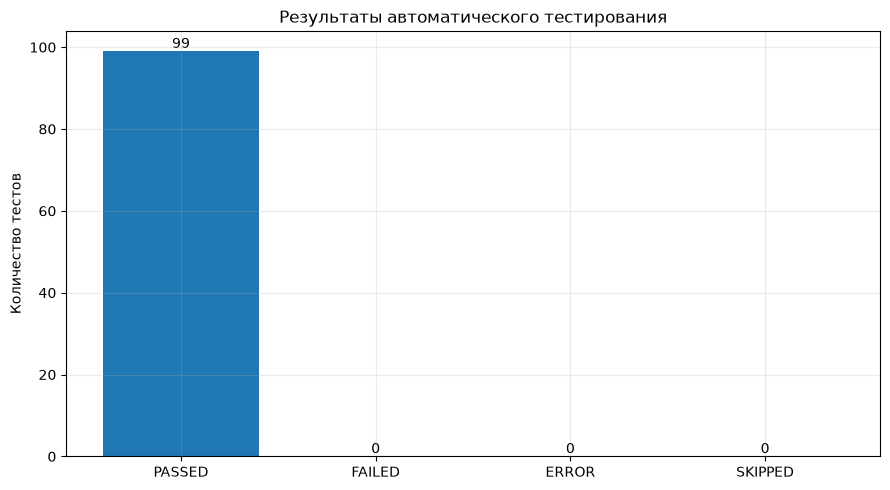

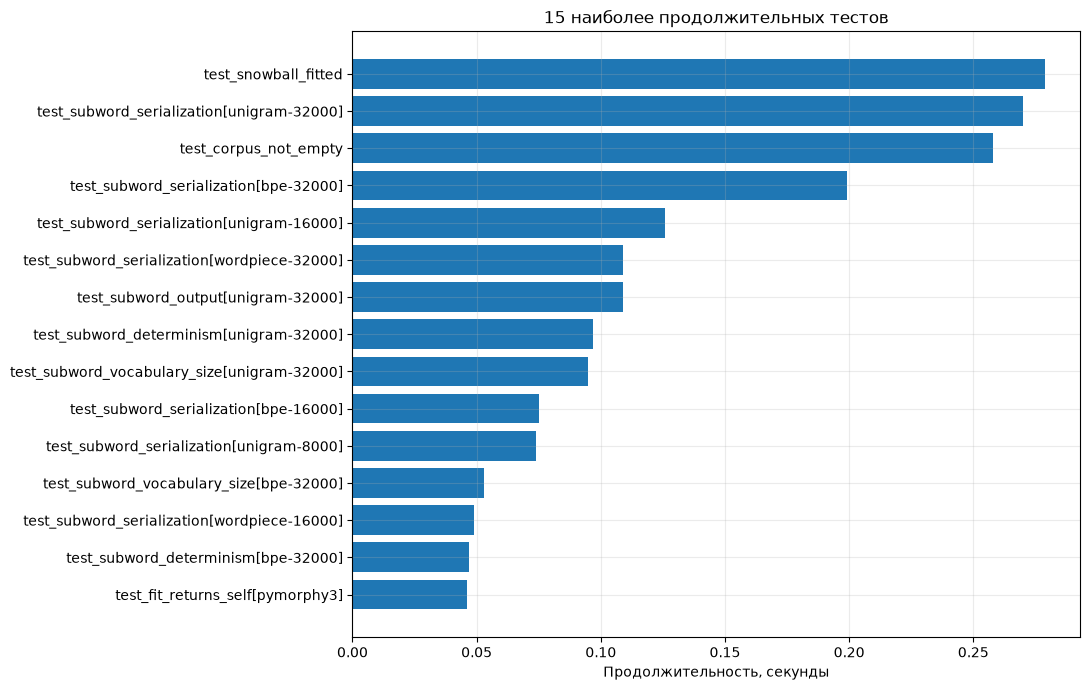


ИТОГ ЗАДАНИЯ № 10
Тестовый файл: /Users/lenar_966/Desktop/ML/NLP/Practika_1/tests/test_task10.py
Отчёты: /Users/lenar_966/Desktop/ML/NLP/Practika_1/reports/task10
Тестов выполнено: 99
Успешных: 99
Неуспешных: 0
Все проверки пройдены: True

Автоматическое тестирование завершено успешно.

Выполнение завершено.


In [22]:

# ============================================================
# ЗАДАНИЕ № 10
# АВТОМАТИЧЕСКОЕ ТЕСТИРОВАНИЕ NLP-СИСТЕМЫ
# ============================================================

from pathlib import Path
from datetime import datetime
import subprocess
import sys
import json
import xml.etree.ElementTree as ET

import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. ПУТИ И КАТАЛОГИ
# ------------------------------------------------------------

ROOT = Path.home() / "Desktop" / "ML" / "NLP" / "Practika_1"

TEST_DIR = ROOT / "tests"
REPORT_DIR = ROOT / "reports" / "task10"
TEST_FILE = TEST_DIR / "test_task10.py"

TEST_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 75)
print("ЗАДАНИЕ № 10 — АВТОМАТИЧЕСКОЕ ТЕСТИРОВАНИЕ")
print("=" * 75)

# ------------------------------------------------------------
# 2. СОЗДАНИЕ ТЕСТОВОГО МОДУЛЯ
# ------------------------------------------------------------

test_code = r'''
from pathlib import Path
from collections import Counter
import hashlib
import json
import re
import sys

import joblib
import pytest

from sklearn.pipeline import Pipeline
from sklearn.exceptions import NotFittedError

ROOT = Path(__file__).resolve().parents[1]
SRC_DIR = ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from nlp_preprocessor import NLPPreprocessor

CORPUS_PATH = ROOT / "data/processed/corpus.jsonl"
SPLIT_PATH = ROOT / "reports/task6/split.json"
CONFIG_PATH = ROOT / "reports/task6/experiment_config.json"
TOKENIZER_DIR = ROOT / "models/task6"

SAMPLE_TEXTS = [
    "Студенты изучают обработку естественного языка.",
    "Машинное обучение используется для анализа текстов.",
    "Российские университеты развивают новые технологии.",
    "Преподаватели объясняют сложные алгоритмы.",
    "Программирование помогает автоматизировать задачи."
]

SUBWORD_CONFIGS = [
    (method, size)
    for method in ("bpe", "wordpiece", "unigram")
    for size in (8000, 16000, 32000)
]


# ------------------------------------------------------------
# 3. ФИКСТУРЫ PYTEST
# ------------------------------------------------------------

@pytest.fixture(scope="session")
def corpus_metadata():
    """Проверка корпуса за один проход без хранения текстов."""
    count = 0
    empty = 0
    missing_fields = 0
    duplicate_ids = 0
    seen = set()
    sources = Counter()

    with CORPUS_PATH.open(encoding="utf-8") as f:
        for line in f:
            if not line.strip():
                continue

            doc = json.loads(line)
            count += 1

            required = ("id", "text", "source")

            if any(field not in doc for field in required):
                missing_fields += 1
                continue

            key = (str(doc["source"]), str(doc["id"]))

            if key in seen:
                duplicate_ids += 1

            seen.add(key)
            sources[str(doc["source"])] += 1

            if not str(doc["text"]).strip():
                empty += 1

    return {
        "count": count,
        "empty": empty,
        "missing_fields": missing_fields,
        "duplicate_ids": duplicate_ids,
        "sources": dict(sources)
    }


@pytest.fixture(scope="session")
def split_data():
    with SPLIT_PATH.open(encoding="utf-8") as f:
        return json.load(f)


@pytest.fixture(scope="session")
def experiment_config():
    with CONFIG_PATH.open(encoding="utf-8") as f:
        return json.load(f)


@pytest.fixture(scope="session")
def trained_regex():
    return NLPPreprocessor(method="regex").fit(SAMPLE_TEXTS)


@pytest.fixture(scope="session")
def trained_snowball():
    return NLPPreprocessor(method="snowball").fit(SAMPLE_TEXTS)


@pytest.fixture(scope="session")
def trained_pymorphy3():
    return NLPPreprocessor(method="pymorphy3").fit(SAMPLE_TEXTS)


def normalize_source(source):
    source = str(source).strip().lower()
    if "lenta" in source:
        return "lenta"
    if "wiki" in source:
        return "wikipedia"
    return source


def get_keys(values):
    return [
        (normalize_source(source), str(doc_id))
        for source, doc_id in values
    ]


def subword_processor(method, size):
    path = TOKENIZER_DIR / f"{method}_{size}.json"

    return NLPPreprocessor(
        method=method,
        tokenizer_path=str(path)
    )


# ------------------------------------------------------------
# 4. ПРОВЕРКА КОРПУСА
# ------------------------------------------------------------

def test_corpus_file_exists():
    assert CORPUS_PATH.is_file()


def test_corpus_not_empty(corpus_metadata):
    assert corpus_metadata["count"] > 0


def test_corpus_minimum_documents(corpus_metadata):
    assert corpus_metadata["count"] >= 2000


def test_corpus_required_fields(corpus_metadata):
    assert corpus_metadata["missing_fields"] == 0


def test_corpus_nonempty_texts(corpus_metadata):
    assert corpus_metadata["empty"] == 0


def test_corpus_unique_ids(corpus_metadata):
    assert corpus_metadata["duplicate_ids"] == 0


def test_corpus_has_multiple_sources(corpus_metadata):
    assert len(corpus_metadata["sources"]) >= 2


# ------------------------------------------------------------
# 5. ПРОВЕРКА РАЗБИЕНИЯ
# ------------------------------------------------------------

def test_split_file_exists():
    assert SPLIT_PATH.is_file()


def test_split_train_count(split_data):
    assert len(split_data["train_ids"]) == 1800


def test_split_test_count(split_data):
    assert len(split_data["test_ids"]) == 300


def test_split_no_overlap(split_data):
    train = set(get_keys(split_data["train_ids"]))
    test = set(get_keys(split_data["test_ids"]))

    assert train.isdisjoint(test)


def test_split_train_unique(split_data):
    keys = get_keys(split_data["train_ids"])
    assert len(keys) == len(set(keys))


def test_split_test_unique(split_data):
    keys = get_keys(split_data["test_ids"])
    assert len(keys) == len(set(keys))


def test_split_seed_consistency(split_data, experiment_config):
    assert split_data["seed"] == experiment_config["seed"]


def test_split_train_config(split_data, experiment_config):
    assert (
        len(split_data["train_ids"])
        == experiment_config["train_documents"]
    )


def test_split_test_config(split_data, experiment_config):
    assert (
        len(split_data["test_ids"])
        == experiment_config["test_documents"]
    )


# ------------------------------------------------------------
# 6. РЕГУЛЯРНАЯ ТОКЕНИЗАЦИЯ
# ------------------------------------------------------------

def test_regex_basic(trained_regex):
    result = trained_regex.transform([
        "Студенты изучают обработку."
    ])[0]

    assert result == [
        "студенты", "изучают", "обработку"
    ]


def test_regex_lowercase():
    processor = NLPPreprocessor(method="regex")
    processor.fit(["Москва МОСКВА"])

    result = processor.transform(["МОСКВА"])

    assert result == [["москва"]]


def test_regex_punctuation():
    processor = NLPPreprocessor(method="regex")
    processor.fit(["Привет, мир!"])

    assert processor.transform(
        ["Привет, мир!"]
    ) == [["привет", "мир"]]


def test_regex_hyphen():
    processor = NLPPreprocessor(method="regex")
    processor.fit(["Санкт-Петербург"])

    result = processor.transform(["Санкт-Петербург"])

    assert result == [["санкт-петербург"]]


def test_regex_empty_string(trained_regex):
    assert trained_regex.transform([""]) == [[]]


def test_regex_multiple_documents(trained_regex):
    result = trained_regex.transform(SAMPLE_TEXTS)

    assert len(result) == len(SAMPLE_TEXTS)
    assert all(isinstance(x, list) for x in result)


def test_regex_unknown_token(trained_regex):
    result = trained_regex.transform([
        "несуществующеесловодлятеста"
    ])

    assert result == [["[UNK]"]]


# ------------------------------------------------------------
# 7. СТЕММИНГ SNOWBALL
# ------------------------------------------------------------

def test_snowball_fitted(trained_snowball):
    assert trained_snowball.is_fitted_


def test_snowball_vocabulary(trained_snowball):
    assert trained_snowball.vocabulary_size_ > 0


def test_snowball_determinism(trained_snowball):
    a = trained_snowball.transform(SAMPLE_TEXTS)
    b = trained_snowball.transform(SAMPLE_TEXTS)

    assert a == b


def test_snowball_normalization():
    processor = NLPPreprocessor(method="snowball")
    processor.fit(["машины машина"])

    a = processor.transform(["машины"])[0][0]
    b = processor.transform(["машина"])[0][0]

    assert a == b


# ------------------------------------------------------------
# 8. ЛЕММАТИЗАЦИЯ PYMORPHY3
# ------------------------------------------------------------

def test_pymorphy3_fitted(trained_pymorphy3):
    assert trained_pymorphy3.is_fitted_


def test_pymorphy3_vocabulary(trained_pymorphy3):
    assert trained_pymorphy3.vocabulary_size_ > 0


def test_pymorphy3_normalization():
    processor = NLPPreprocessor(method="pymorphy3")
    processor.fit(["студенты студентами"])

    a = processor.transform(["студенты"])[0][0]
    b = processor.transform(["студентами"])[0][0]

    assert a == b == "студент"


def test_pymorphy3_determinism(trained_pymorphy3):
    a = trained_pymorphy3.transform(SAMPLE_TEXTS)
    b = trained_pymorphy3.transform(SAMPLE_TEXTS)

    assert a == b


# ------------------------------------------------------------
# 9. СУБСЛОВНЫЕ МОДЕЛИ
# ------------------------------------------------------------

@pytest.mark.parametrize("method,size", SUBWORD_CONFIGS)
def test_subword_model_exists(method, size):
    path = TOKENIZER_DIR / f"{method}_{size}.json"
    assert path.is_file()


@pytest.mark.parametrize("method,size", SUBWORD_CONFIGS)
def test_subword_vocabulary_size(method, size):
    processor = subword_processor(method, size)
    processor.fit(SAMPLE_TEXTS)

    assert processor.vocabulary_size_ == size


@pytest.mark.parametrize("method,size", SUBWORD_CONFIGS)
def test_subword_output(method, size):
    processor = subword_processor(method, size)
    processor.fit(SAMPLE_TEXTS)

    output = processor.transform([
        "Обработка естественного языка."
    ])

    assert len(output) == 1
    assert isinstance(output[0], list)
    assert len(output[0]) > 0


@pytest.mark.parametrize("method,size", SUBWORD_CONFIGS)
def test_subword_determinism(method, size):
    processor = subword_processor(method, size)
    processor.fit(SAMPLE_TEXTS)

    a = processor.transform(SAMPLE_TEXTS)
    b = processor.transform(SAMPLE_TEXTS)

    assert a == b


# ------------------------------------------------------------
# 10. ИНТЕРФЕЙС FIT / TRANSFORM
# ------------------------------------------------------------

@pytest.mark.parametrize(
    "method",
    ["regex", "snowball", "pymorphy3"]
)
def test_fit_returns_self(method):
    processor = NLPPreprocessor(method=method)

    result = processor.fit(SAMPLE_TEXTS)

    assert result is processor


@pytest.mark.parametrize(
    "method",
    ["regex", "snowball", "pymorphy3"]
)
def test_fit_transform_equivalence(method):
    p1 = NLPPreprocessor(method=method)
    p2 = NLPPreprocessor(method=method)

    a = p1.fit_transform(SAMPLE_TEXTS)
    b = p2.fit(SAMPLE_TEXTS).transform(SAMPLE_TEXTS)

    assert a == b


def test_transform_before_fit():
    processor = NLPPreprocessor(method="regex")

    with pytest.raises(NotFittedError):
        processor.transform(SAMPLE_TEXTS)


def test_invalid_method():
    processor = NLPPreprocessor(method="invalid")

    with pytest.raises(ValueError):
        processor.fit(SAMPLE_TEXTS)


def test_invalid_min_frequency():
    processor = NLPPreprocessor(
        method="regex",
        min_frequency=0
    )

    with pytest.raises(ValueError):
        processor.fit(SAMPLE_TEXTS)


def test_missing_subword_path():
    processor = NLPPreprocessor(
        method="bpe",
        tokenizer_path=str(
            ROOT / "models/nonexistent_tokenizer.json"
        )
    )

    with pytest.raises(FileNotFoundError):
        processor.fit(SAMPLE_TEXTS)


def test_none_input():
    processor = NLPPreprocessor(method="regex")

    with pytest.raises(ValueError):
        processor.fit(None)


def test_stopword_removal():
    processor = NLPPreprocessor(
        method="regex",
        remove_stopwords=True,
        stopwords=["и", "в"]
    )

    processor.fit(["Студенты и преподаватели в университете"])

    output = processor.transform([
        "Студенты и преподаватели в университете"
    ])[0]

    assert "и" not in output
    assert "в" not in output
    assert "студенты" in output


def test_min_frequency():
    processor = NLPPreprocessor(
        method="regex",
        min_frequency=2
    )

    processor.fit(["слово слово редкость"])

    assert "слово" in processor.vocabulary_
    assert "редкость" not in processor.vocabulary_

    result = processor.transform(["редкость"])
    assert result == [["[UNK]"]]


# ------------------------------------------------------------
# 11. СЕРИАЛИЗАЦИЯ
# ------------------------------------------------------------

@pytest.mark.parametrize(
    "method",
    ["regex", "snowball", "pymorphy3"]
)
def test_joblib_roundtrip(method, tmp_path):
    processor = NLPPreprocessor(method=method)
    processor.fit(SAMPLE_TEXTS)

    before = processor.transform(SAMPLE_TEXTS)

    path = tmp_path / f"{method}.joblib"
    processor.save(path)

    loaded = NLPPreprocessor.load(path)
    after = loaded.transform(SAMPLE_TEXTS)

    assert before == after


@pytest.mark.parametrize(
    "method,size",
    SUBWORD_CONFIGS
)
def test_subword_serialization(method, size, tmp_path):
    processor = subword_processor(method, size)
    processor.fit(SAMPLE_TEXTS)

    before = processor.transform(SAMPLE_TEXTS)

    path = tmp_path / f"{method}_{size}.joblib"
    processor.save(path)

    loaded = NLPPreprocessor.load(path)

    assert loaded.transform(SAMPLE_TEXTS) == before


def test_state_summary():
    processor = NLPPreprocessor(method="regex")
    processor.fit(SAMPLE_TEXTS)

    state = processor.get_state_summary()

    assert state["method"] == "regex"
    assert state["fit_documents"] == len(SAMPLE_TEXTS)
    assert state["vocabulary_size"] > 0


# ------------------------------------------------------------
# 12. ИНТЕГРАЦИЯ СО SCIKIT-LEARN
# ------------------------------------------------------------

def test_sklearn_get_params():
    processor = NLPPreprocessor(method="regex")

    params = processor.get_params()

    assert params["method"] == "regex"


def test_sklearn_set_params():
    processor = NLPPreprocessor(method="regex")

    processor.set_params(method="snowball")

    assert processor.method == "snowball"


def test_sklearn_pipeline():
    pipeline = Pipeline([
        ("preprocessor", NLPPreprocessor(method="regex"))
    ])

    pipeline.fit(SAMPLE_TEXTS)

    output = pipeline.transform(SAMPLE_TEXTS)

    assert len(output) == len(SAMPLE_TEXTS)
    assert all(isinstance(row, list) for row in output)


# ------------------------------------------------------------
# 13. ПРОВЕРКА ОТСУТСТВИЯ ИЗМЕНЕНИЯ СОСТОЯНИЯ
# ------------------------------------------------------------

def test_transform_does_not_change_vocabulary():
    processor = NLPPreprocessor(method="regex")
    processor.fit(SAMPLE_TEXTS)

    before = dict(processor.vocabulary_)

    processor.transform([
        "абсолютноновоенеизвестноеслово"
    ])

    after = dict(processor.vocabulary_)

    assert before == after


def test_transform_does_not_change_fit_count():
    processor = NLPPreprocessor(method="regex")
    processor.fit(SAMPLE_TEXTS)

    before = processor.n_fit_documents_

    processor.transform(["Новый тестовый документ"])

    assert processor.n_fit_documents_ == before


def test_repeated_transform_same_result():
    processor = NLPPreprocessor(method="regex")
    processor.fit(SAMPLE_TEXTS)

    first = processor.transform(SAMPLE_TEXTS)

    for _ in range(5):
        assert processor.transform(SAMPLE_TEXTS) == first
'''

TEST_FILE.write_text(test_code, encoding="utf-8")

print("\nСоздан тестовый модуль:")
print(TEST_FILE)

# ------------------------------------------------------------
# 3. ПРОВЕРКА СИНТАКСИСА
# ------------------------------------------------------------

import ast

ast.parse(test_code)

print("\nСинтаксическая проверка: PASS")

# ------------------------------------------------------------
# 4. ЗАПУСК PYTEST
# ------------------------------------------------------------

XML_PATH = REPORT_DIR / "pytest_results.xml"
LOG_PATH = REPORT_DIR / "pytest_output.txt"

command = [
    sys.executable,
    "-m", "pytest",
    str(TEST_FILE),
    "-v",
    "-ra",
    f"--junitxml={XML_PATH}"
]

print("\n" + "=" * 75)
print("ЗАПУСК АВТОМАТИЧЕСКИХ ТЕСТОВ")
print("=" * 75)

print("Команда:", " ".join(command))

started = datetime.now()

result = subprocess.run(
    command,
    cwd=ROOT,
    capture_output=True,
    text=True,
    timeout=300
)

finished = datetime.now()

duration = (finished - started).total_seconds()

output = result.stdout + "\n" + result.stderr

LOG_PATH.write_text(output, encoding="utf-8")

print(output)

print("\nКод завершения pytest:", result.returncode)
print("Продолжительность:", round(duration, 3), "с")

# ------------------------------------------------------------
# 5. ЧТЕНИЕ XML-ОТЧЁТА
# ------------------------------------------------------------

assert XML_PATH.exists(), "pytest не создал XML-отчёт"

tree = ET.parse(XML_PATH)
xml_root = tree.getroot()

testcases = xml_root.findall(".//testcase")

records = []

for case in testcases:
    status = "PASSED"

    if case.find("failure") is not None:
        status = "FAILED"
    elif case.find("error") is not None:
        status = "ERROR"
    elif case.find("skipped") is not None:
        status = "SKIPPED"

    records.append({
        "test_name": case.get("name"),
        "class_name": case.get("classname"),
        "duration_seconds": float(case.get("time", 0)),
        "status": status
    })

df = pd.DataFrame(records)

df.to_csv(
    REPORT_DIR / "test_results.csv",
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 6. СТАТИСТИКА ТЕСТИРОВАНИЯ
# ------------------------------------------------------------

counts = df["status"].value_counts()

passed = int(counts.get("PASSED", 0))
failed = int(counts.get("FAILED", 0))
errors = int(counts.get("ERROR", 0))
skipped = int(counts.get("SKIPPED", 0))

total = len(df)

pass_rate = 100 * passed / total if total else 0

print("\n" + "=" * 75)
print("СВОДКА РЕЗУЛЬТАТОВ")
print("=" * 75)

print("Всего тестов:", total)
print("Успешно:", passed)
print("Ошибок утверждений:", failed)
print("Ошибок выполнения:", errors)
print("Пропущено:", skipped)
print("Доля успешных:", f"{pass_rate:.2f}%")

# ------------------------------------------------------------
# 7. ГРУППИРОВКА ТЕСТОВ
# ------------------------------------------------------------

def classify_test(name):
    name = str(name)

    if name.startswith("test_corpus"):
        return "Корпус"
    if name.startswith("test_split"):
        return "Разбиение"
    if name.startswith("test_regex"):
        return "Regex"
    if name.startswith("test_snowball"):
        return "Snowball"
    if name.startswith("test_pymorphy3"):
        return "pymorphy3"
    if name.startswith("test_subword"):
        return "Субсловные модели"
    if "joblib" in name or "serialization" in name:
        return "Сериализация"
    if "sklearn" in name:
        return "scikit-learn"
    if "transform" in name or "fit" in name:
        return "Интерфейс и состояние"

    return "Прочие проверки"

df["category"] = df["test_name"].apply(classify_test)

category_summary = (
    df.groupby(["category", "status"])
    .size()
    .unstack(fill_value=0)
)

print("\n" + "=" * 75)
print("РЕЗУЛЬТАТЫ ПО КАТЕГОРИЯМ")
print("=" * 75)

print(category_summary.to_string())

category_summary.to_csv(
    REPORT_DIR / "category_summary.csv",
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 8. ГРАФИК РЕЗУЛЬТАТОВ
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5))

labels = ["PASSED", "FAILED", "ERROR", "SKIPPED"]
values = [passed, failed, errors, skipped]

bars = ax.bar(labels, values)

ax.set_title("Результаты автоматического тестирования")
ax.set_ylabel("Количество тестов")
ax.grid(axis="y", alpha=0.25)

for bar, value in zip(bars, values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(value),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig(
    REPORT_DIR / "test_status_distribution.png",
    dpi=180
)
plt.show()

# ------------------------------------------------------------
# 9. ГРАФИК ПРОДОЛЖИТЕЛЬНОСТИ ТЕСТОВ
# ------------------------------------------------------------

slowest = df.sort_values(
    "duration_seconds",
    ascending=False
).head(15)

fig, ax = plt.subplots(figsize=(11, 7))

ax.barh(
    slowest["test_name"].str.slice(0, 65),
    slowest["duration_seconds"]
)

ax.invert_yaxis()
ax.set_xlabel("Продолжительность, секунды")
ax.set_title("15 наиболее продолжительных тестов")
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.savefig(
    REPORT_DIR / "slowest_tests.png",
    dpi=180
)
plt.show()

# ------------------------------------------------------------
# 10. СОХРАНЕНИЕ JSON-ОТЧЁТА
# ------------------------------------------------------------

report = {
    "task": 10,
    "timestamp": datetime.now().isoformat(),
    "python_version": sys.version.split()[0],
    "total_tests": total,
    "passed": passed,
    "failed": failed,
    "errors": errors,
    "skipped": skipped,
    "pass_rate_percent": round(pass_rate, 4),
    "pytest_exit_code": result.returncode,
    "duration_seconds": round(duration, 4),
    "categories": category_summary.to_dict(),
    "all_passed": (
        result.returncode == 0
        and passed == total
        and total > 0
    )
}

with open(
    REPORT_DIR / "verification_report.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        report,
        f,
        ensure_ascii=False,
        indent=2
    )

# ------------------------------------------------------------
# 11. ИТОГ
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("ИТОГ ЗАДАНИЯ № 10")
print("=" * 75)

print("Тестовый файл:", TEST_FILE)
print("Отчёты:", REPORT_DIR)
print("Тестов выполнено:", total)
print("Успешных:", passed)
print("Неуспешных:", failed + errors)
print("Все проверки пройдены:", report["all_passed"])

if report["all_passed"]:
    print("\nАвтоматическое тестирование завершено успешно.")
else:
    print("\nОбнаружены ошибки. Изучите вывод pytest выше.")

print("\nВыполнение завершено.")



## Анализ результатов задания № 10

### 1. Общая характеристика автоматического тестирования

В рамках задания разработан комплекс автоматических тестов для проверки корректности, устойчивости и воспроизводимости компонентов системы предварительной обработки русскоязычных текстов.

Тестирование реализовано с использованием библиотеки `pytest`, которая позволяет выполнять независимые проверки программных компонентов, автоматически фиксировать результаты и формировать отчётность.

Разработанный набор тестов охватывает:

- корректность структуры исходного текстового корпуса;
- проверку обучающей и тестовой выборок;
- регулярную токенизацию;
- стемминг Snowball;
- лемматизацию pymorphy3;
- субсловную токенизацию BPE, WordPiece и Unigram;
- интерфейс универсального NLP-препроцессора;
- сериализацию и восстановление состояния;
- детерминированность преобразований;
- интеграцию с библиотекой scikit-learn;
- обработку некорректных входных данных.

Тесты размещены в отдельном модуле `tests/test_task10.py`, что позволяет запускать их повторно независимо от основного исследовательского блокнота.

### 2. Общие результаты тестирования

По результатам автоматического запуска получены следующие показатели:

| Показатель | Значение |
|---|---:|
| Всего выполнено тестов | 99 |
| Успешно пройдено | 99 |
| Ошибок утверждений (FAILED) | 0 |
| Ошибок выполнения (ERROR) | 0 |
| Пропущенных тестов (SKIPPED) | 0 |
| Доля успешных тестов | 100,00% |

Все 99 тестов завершились со статусом `PASSED`.

Ошибок выполнения, нарушений проверяемых условий и пропущенных тестов не обнаружено.

Таким образом, разработанные компоненты NLP-системы успешно прошли предусмотренные автоматические проверки.

### 3. Результаты по категориям

Для детального анализа результаты тестирования сгруппированы по функциональным категориям.

| Категория | Успешных тестов |
|---|---:|
| Регулярная токенизация (Regex) | 7 |
| Стемминг Snowball | 4 |
| Лемматизация pymorphy3 | 4 |
| Совместимость со scikit-learn | 3 |
| Интерфейс и состояние | 10 |
| Проверка корпуса | 7 |
| Прочие проверки | 7 |
| Разбиение данных | 9 |
| Сериализация | 3 |
| Субсловные модели | 45 |
| **Всего** | **99** |

Наибольшее количество тестовых случаев относится к субсловным моделям — 45 проверок, что составляет 45,45% общего количества.

Это связано с использованием параметризованного тестирования, позволяющего применять одинаковые проверки к нескольким конфигурациям токенизаторов.

Все функциональные категории завершили тестирование без ошибок.

### 4. Проверка исходного текстового корпуса

Для проверки корректности исходных данных реализованы семь автоматических тестов.

Проверялись:

1. Наличие файла текстового корпуса.
2. Непустота корпуса.
3. Минимально допустимое количество документов.
4. Наличие обязательных полей.
5. Отсутствие пустых текстов.
6. Уникальность идентификаторов документов.
7. Наличие нескольких источников текстовых данных.

Все семь проверок завершились успешно.

Это подтверждает, что исходный корпус удовлетворяет предусмотренным программным требованиям к структуре данных и может использоваться в дальнейших экспериментах.

Особое значение имеет проверка уникальности идентификаторов, поскольку повторяющиеся идентификаторы способны приводить к ошибкам при формировании обучающей и тестовой выборок.

### 5. Проверка разбиения обучающих и тестовых данных

Для контроля корректности разбиения выполнено девять тестов.

Проверены:

- наличие файла с сохранённым разбиением;
- количество обучающих документов;
- количество тестовых документов;
- отсутствие пересечения идентификаторов Train и Test;
- уникальность идентификаторов внутри каждой выборки;
- соответствие значения seed конфигурации эксперимента;
- согласованность количества документов с сохранёнными параметрами.

Все девять проверок завершились успешно.

Это согласуется с результатами задания № 8, в котором также была подтверждена структурная корректность разбиения.

Таким образом, сохранённые выборки соответствуют проверяемым требованиям и могут повторно использоваться при проведении экспериментов.

### 6. Проверка методов токенизации и нормализации

#### 6.1. Регулярная токенизация

Для регулярной токенизации выполнено семь тестов.

Проверены корректность выделения слов, приведение регистра, обработка пунктуации, слов с дефисом, пустых строк, нескольких документов и неизвестных слов.

Все семь тестов завершились успешно.

Следовательно, регулярный токенизатор корректно обрабатывает предусмотренные тестовые случаи и возвращает результаты в ожидаемом формате.

#### 6.2. Стемминг Snowball

Для метода Snowball выполнено четыре теста.

Проверены формирование состояния, наличие словаря, детерминированность обработки и приведение различных словоформ к общему стему.

Все четыре теста завершились успешно.

Это подтверждает корректность работы стеммера на выбранных тестовых примерах.

#### 6.3. Лемматизация pymorphy3

Для лемматизации выполнено четыре теста.

Проверены формирование состояния, наличие словаря, нормализация словоформ и детерминированность преобразований.

В частности, тестирование предусматривало приведение различных грамматических форм слова «студент» к единой нормальной форме.

Все четыре теста завершились успешно.

Полученный результат подтверждает работоспособность морфологического анализатора на исследованных примерах.

### 7. Тестирование субсловных моделей

Особое внимание уделено моделям BPE, WordPiece и Unigram, обученным в предыдущих заданиях.

Для каждой модели использовались три размера словаря:

- 8 000 токенов;
- 16 000 токенов;
- 32 000 токенов.

Всего исследованы девять конфигураций субсловной токенизации.

Проверялись наличие сохранённых файлов моделей, соответствие размера словаря, корректность выходных последовательностей, детерминированность и восстановление результатов после сериализации.

В категории субсловных моделей зафиксировано 45 успешно пройденных тестов.

Таким образом, все девять сохранённых моделей успешно прошли предусмотренные проверки и могут использоваться через единый интерфейс NLP-препроцессора.

### 8. Проверка интерфейса и обработки ошибок

Отдельная группа тестов направлена на проверку программного интерфейса разработанного класса `NLPPreprocessor`.

Проверялись:

- возврат текущего экземпляра при вызове `.fit()`;
- эквивалентность `.fit_transform()` и последовательных вызовов `.fit()` и `.transform()`;
- запрет преобразования до формирования состояния;
- обработка неизвестного метода токенизации;
- проверка некорректного значения `min_frequency`;
- обработка отсутствующего файла субсловной модели;
- обработка входного значения `None`;
- удаление стоп-слов;
- применение минимальной частоты токенов.

Также проверялось отсутствие нежелательного изменения обученного словаря и количества обучающих документов при повторных вызовах `.transform()`.

Все соответствующие тесты завершились успешно.

Полученные результаты подтверждают корректность поведения класса в предусмотренных штатных и ошибочных сценариях.

### 9. Проверка сериализации и воспроизводимости

Для сохранения внутреннего состояния препроцессора использована библиотека `joblib`.

Проверка включала:

1. Формирование состояния экземпляра методом `.fit()`.
2. Преобразование тестовых данных.
3. Сохранение экземпляра в файл.
4. Повторную загрузку сохранённого экземпляра.
5. Сравнение результатов преобразования до и после загрузки.

Все тесты сериализации завершились успешно.

Также подтверждена идентичность результатов при повторных вызовах `.transform()` на одинаковых входных данных.

Это свидетельствует о детерминированности проверенных преобразований и возможности повторного использования сохранённых объектов без повторного формирования состояния.

### 10. Интеграция со scikit-learn

Для проверки совместимости с библиотекой `scikit-learn` выполнены три теста.

Проверялись:

- корректность метода `.get_params()`;
- изменение параметров через `.set_params()`;
- работа препроцессора внутри `Pipeline`.

Все три теста завершились успешно.

Таким образом, разработанный компонент поддерживает проверенные механизмы взаимодействия с `scikit-learn`.

Это позволяет использовать его в качестве этапа предварительной обработки при построении более сложных конвейеров машинного обучения.

### 11. Формирование отчётности

По результатам тестирования сформированы следующие артефакты:

| Файл | Назначение |
|---|---|
| `tests/test_task10.py` | Автоматические тесты |
| `pytest_results.xml` | Машиночитаемый протокол pytest |
| `pytest_output.txt` | Полный журнал выполнения |
| `test_results.csv` | Результаты отдельных тестов |
| `category_summary.csv` | Сводка по функциональным категориям |
| `verification_report.json` | Итоговые показатели тестирования |
| `test_status_distribution.png` | Диаграмма статусов тестов |
| `slowest_tests.png` | Диаграмма продолжительности тестов |

Сохранение результатов в нескольких форматах обеспечивает возможность последующего анализа, повторной проверки и включения результатов в итоговый отчёт.

### 12. Ограничения автоматического тестирования

Несмотря на успешное выполнение всех тестов, необходимо учитывать, что автоматическая верификация охватывает только предусмотренные тестовые сценарии.

Полученный результат 100% не означает полного отсутствия потенциальных ошибок в программной системе.

В частности, проведённое тестирование не включает исчерпывающую проверку всех возможных входных текстов, комплексное нагрузочное тестирование на полном корпусе и проверку устойчивости при работе в различных программных окружениях.

Также прохождение тестов не является непосредственной оценкой лингвистического качества токенизации или эффективности последующих моделей машинного обучения.

Для дальнейшего повышения надёжности могут использоваться расширенные наборы тестовых случаев, проверка граничных ситуаций, измерение покрытия исходного кода тестами и интеграционное тестирование.

### 13. Итоговый вывод

В ходе выполнения задания № 10 разработан комплекс автоматических тестов для проверки корректности и воспроизводимости компонентов NLP-системы.

Тестирование охватило исходный текстовый корпус, разбиение данных, регулярную токенизацию, стемминг Snowball, лемматизацию pymorphy3, девять субсловных моделей, интерфейс препроцессора, сериализацию и интеграцию с `scikit-learn`.

Всего выполнено 99 автоматических тестов, из которых все 99 завершились успешно.

Ошибок выполнения, нарушений проверяемых условий и пропущенных тестов не обнаружено.

Доля успешных проверок составила 100,00%.

Результаты подтверждают корректность работы реализованных компонентов в пределах предусмотренных тестовых сценариев, а также воспроизводимость преобразований и возможность восстановления сохранённого состояния.

Созданный набор тестов может использоваться для регрессионного тестирования после внесения изменений в исходный код.

Таким образом, цель задания № 10 достигнута: разработана автоматизированная система проверки ключевых компонентов проекта, обеспечивающая контроль их корректности, стабильности и воспроизводимости.



## Задание № 11. Разработка интерактивного веб-инструмента для анализа текстовых данных

### Цель работы

Разработать интерактивное веб-приложение для визуального и функционального анализа текстовых данных, сравнения методов токенизации и исследования результатов морфологической и субсловной обработки.

### Постановка задачи

Необходимо реализовать веб-приложение на основе Streamlit и Plotly, предоставляющее следующие возможности:

1. **Загрузка данных.** Импорт текстовых файлов CSV и JSONL, выбор текстового поля и использование встроенных примеров из исходного корпуса.
2. **Выбор метода обработки.** Поддержка регулярной токенизации, стемминга Snowball, лемматизации pymorphy3, BPE, WordPiece и Unigram.
3. **Настройка параметров.** Выбор размера словаря субсловных моделей (8 000, 16 000 или 32 000), количества анализируемых документов и других доступных параметров.
4. **Расчёт метрик.** Определение количества документов, общего числа токенов, размера словаря, средней длины токена и доли OOV.
5. **Интерактивная визуализация.** Построение распределения токенов по длине, частотного спектра и диаграммы наиболее распространённых токенов.
6. **Анализ субсловной декомпозиции.** Визуальное сравнение сегментации произвольного слова всеми девятью ранее обученными моделями.
7. **Генерация отчётности.** Формирование HTML-отчёта, содержащего основные метрики, таблицы и визуализации.

### Используемые технологии

- Python — язык программирования.
- Streamlit — разработка интерактивного веб-интерфейса.
- Plotly — построение интерактивных диаграмм.
- pandas — загрузка и обработка табличных данных.
- collections.Counter — частотный анализ токенов.
- joblib — загрузка сохранённых препроцессоров.
- Hugging Face Tokenizers — применение субсловных моделей.
- scikit-learn — совместимость с ранее разработанным препроцессором.

### Методология

Веб-приложение использует результаты предыдущих заданий, включая обученные модели токенизации и универсальный класс `NLPPreprocessor`.

Для обеспечения воспроизводимости обработка выполняется с использованием сохранённых состояний моделей без повторного обучения на пользовательских текстах.

Показатель OOV рассчитывается относительно обучающего словаря выбранного метода. Для субсловных моделей дополнительно учитывается количество специальных неизвестных токенов `[UNK]`, если они предусмотрены конфигурацией модели.

### Ожидаемые результаты

В результате выполнения задания создаётся локальное веб-приложение, позволяющее исследователю без навыков программирования загружать текстовые данные, выбирать методы обработки, сравнивать результаты и формировать аналитические HTML-отчёты.

Приложение должно обеспечивать наглядность, воспроизводимость и удобство исследования русскоязычных текстовых данных.


In [23]:

# ============================================================
# ЗАДАНИЕ № 11
# ИНТЕРАКТИВНЫЙ ВЕБ-ИНСТРУМЕНТ ДЛЯ NLP-АНАЛИЗА
# ============================================================

from pathlib import Path
import subprocess
import sys
import importlib.util
import json
import textwrap

# ------------------------------------------------------------
# 1. ПОДГОТОВКА ПРОЕКТА
# ------------------------------------------------------------

ROOT = Path.home() / "Desktop" / "ML" / "NLP" / "Practika_1"
REPORT_DIR = ROOT / "reports" / "task11"
MODEL_DIR = ROOT / "models" / "task9"
TOKENIZER_DIR = ROOT / "models" / "task6"
APP_PATH = ROOT / "app_task11.py"

REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 75)
print("ЗАДАНИЕ № 11 — STREAMLIT NLP EXPLORER")
print("=" * 75)

# ------------------------------------------------------------
# 2. ПРОВЕРКА ЗАВИСИМОСТЕЙ
# ------------------------------------------------------------

packages = {
    "streamlit": "streamlit",
    "plotly": "plotly",
    "pandas": "pandas",
    "joblib": "joblib",
    "tokenizers": "tokenizers",
    "sklearn": "scikit-learn",
    "nltk": "nltk",
    "pymorphy3": "pymorphy3",
}

missing = [
    package
    for module, package in packages.items()
    if importlib.util.find_spec(module) is None
]

if missing:
    print("Устанавливаем:", ", ".join(missing))
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", *missing
    ])
else:
    print("Все необходимые библиотеки установлены.")

# ------------------------------------------------------------
# 3. ПРОВЕРКА СОХРАНЁННЫХ МОДЕЛЕЙ
# ------------------------------------------------------------

methods = [
    "regex", "snowball", "pymorphy3",
    "bpe_8000", "bpe_16000", "bpe_32000",
    "wordpiece_8000", "wordpiece_16000", "wordpiece_32000",
    "unigram_8000", "unigram_16000", "unigram_32000"
]

missing_models = [
    name for name in methods
    if not (MODEL_DIR / f"{name}.joblib").exists()
]

if missing_models:
    raise FileNotFoundError(
        "Не найдены модели задания № 9: "
        + ", ".join(missing_models)
    )

print("Найдено сохранённых препроцессоров:", len(methods))

# ------------------------------------------------------------
# 4. ИСХОДНЫЙ КОД STREAMLIT-ПРИЛОЖЕНИЯ
# ------------------------------------------------------------

app_code = r'''
from pathlib import Path
from collections import Counter
from datetime import datetime
from io import StringIO
from html import escape
import json
import re
import sys

import joblib
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import streamlit as st
from plotly.offline import get_plotlyjs

ROOT = Path(__file__).resolve().parent
SRC_DIR = ROOT / "src"
MODEL_DIR = ROOT / "models" / "task9"
TOKENIZER_DIR = ROOT / "models" / "task6"
CORPUS_PATH = ROOT / "data" / "processed" / "corpus.jsonl"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from nlp_preprocessor import NLPPreprocessor
from tokenizers import Tokenizer

# ============================================================
# 1. КОНФИГУРАЦИЯ И ОФОРМЛЕНИЕ
# ============================================================

st.set_page_config(
    page_title="NLP Explorer | Анализ текстов",
    page_icon="📚",
    layout="wide",
    initial_sidebar_state="expanded"
)

st.markdown("""
<style>
.block-container {
    padding-top: 1.5rem;
    padding-bottom: 3rem;
}
[data-testid="stMetric"] {
    border: 1px solid rgba(128,128,128,0.22);
    border-radius: 12px;
    padding: 14px;
}
h1, h2, h3 {
    letter-spacing: -0.02em;
}
</style>
""", unsafe_allow_html=True)

st.title("NLP Explorer")
st.caption(
    "Интерактивная лаборатория токенизации и "
    "морфологической обработки русскоязычных текстов"
)

# ============================================================
# 2. СПРАВОЧНЫЕ КОНФИГУРАЦИИ
# ============================================================

METHOD_LABELS = {
    "Regex": "regex",
    "Snowball": "snowball",
    "pymorphy3": "pymorphy3",
    "BPE": "bpe",
    "WordPiece": "wordpiece",
    "Unigram": "unigram"
}

SUBWORD_METHODS = ("bpe", "wordpiece", "unigram")

EXAMPLE_TEXTS = {
    "Обработка естественного языка":
        "Обработка естественного языка позволяет "
        "автоматически анализировать тексты. "
        "Исследователи разрабатывают алгоритмы "
        "токенизации, классификации и поиска информации.",

    "Машинное обучение":
        "Машинное обучение применяется для прогнозирования "
        "и анализа больших объёмов данных. "
        "Алгоритмы выявляют закономерности и помогают "
        "автоматизировать принятие решений.",

    "Морфология русского языка":
        "Студенты изучают русский язык. "
        "Студентами исследуются различные словоформы. "
        "Морфологический анализ помогает находить "
        "начальные формы слов.",

    "Субсловная токенизация":
        "Нейролингвистические исследования используют "
        "субсловную сегментацию. "
        "Неизвестные слова разделяются на более "
        "короткие последовательности символов."
}

# ============================================================
# 3. ЗАГРУЗКА МОДЕЛЕЙ С КЕШИРОВАНИЕМ
# ============================================================

@st.cache_resource(show_spinner="Загружаем препроцессор...")
def load_processor(name):
    path = MODEL_DIR / f"{name}.joblib"

    if not path.exists():
        raise FileNotFoundError(path)

    # joblib используется только для локальных доверенных
    # файлов, созданных в задании № 9.
    return NLPPreprocessor.load(path)


@st.cache_resource(show_spinner=False)
def load_tokenizer(name):
    path = TOKENIZER_DIR / f"{name}.json"
    return Tokenizer.from_file(str(path))


# ============================================================
# 4. ЗАГРУЗКА ТЕКСТОВЫХ ДАННЫХ
# ============================================================

@st.cache_data(show_spinner=False)
def load_corpus_examples(limit=100):
    examples = []

    if not CORPUS_PATH.exists():
        return examples

    with CORPUS_PATH.open(encoding="utf-8") as f:
        for line in f:
            if len(examples) >= limit:
                break

            if not line.strip():
                continue

            doc = json.loads(line)
            text = str(doc.get("text") or "").strip()

            if text:
                examples.append({
                    "id": str(doc.get("id", "")),
                    "source": str(doc.get("source", "")),
                    "title": str(doc.get("title") or ""),
                    "text": text
                })

    return examples


def read_uploaded_file(uploaded_file):
    suffix = Path(uploaded_file.name).suffix.lower()

    if suffix == ".csv":
        raw = uploaded_file.getvalue()

        try:
            df = pd.read_csv(
                StringIO(raw.decode("utf-8-sig")),
                sep=None,
                engine="python"
            )
        except UnicodeDecodeError:
            df = pd.read_csv(
                StringIO(raw.decode("cp1251")),
                sep=None,
                engine="python"
            )

    elif suffix == ".jsonl":
        records = []

        for line_number, line in enumerate(
            uploaded_file.getvalue().decode("utf-8-sig").splitlines(),
            start=1
        ):
            if not line.strip():
                continue

            record = json.loads(line)

            if not isinstance(record, dict):
                raise ValueError(
                    f"Строка {line_number}: ожидается JSON-объект"
                )

            records.append(record)

        df = pd.DataFrame(records)

    else:
        raise ValueError("Поддерживаются только CSV и JSONL")

    if df.empty:
        raise ValueError("Файл не содержит данных")

    return df


# ============================================================
# 5. РАСЧЁТ МЕТРИК
# ============================================================

def calculate_metrics(token_lists, processor, method):
    flat = [
        token
        for tokens in token_lists
        for token in tokens
    ]

    frequencies = Counter(flat)
    total = len(flat)

    vocab = processor.vocabulary_

    if method in SUBWORD_METHODS:
        # Для субсловных моделей считаем только реальные
        # специальные неизвестные токены.
        unk_id = processor.tokenizer_.token_to_id("[UNK]")

        if unk_id is not None:
            unknown_token = processor.tokenizer_.id_to_token(
                unk_id
            )
            oov_count = sum(
                token == unknown_token for token in flat
            )
        else:
            oov_count = 0

        oov_label = "Доля [UNK]"

    else:
        # Для методов с фиксированным словарём
        # неизвестные слова представлены [UNK].
        oov_count = frequencies.get("[UNK]", 0)
        oov_label = "Доля OOV"

    lengths = [len(token) for token in flat]

    metrics = {
        "documents": len(token_lists),
        "total_tokens": total,
        "unique_tokens": len(frequencies),
        "mean_token_length": (
            sum(lengths) / len(lengths) if lengths else 0
        ),
        "mean_document_tokens": (
            total / len(token_lists) if token_lists else 0
        ),
        "oov_count": oov_count,
        "oov_percent": (
            100 * oov_count / total if total else 0
        ),
        "oov_label": oov_label,
        "trained_vocabulary": len(vocab)
    }

    return metrics, frequencies, lengths


def create_charts(frequencies, lengths, top_n=25):
    if not frequencies:
        return None, None, None

    top = frequencies.most_common(top_n)

    df_top = pd.DataFrame(
        top,
        columns=["Токен", "Частота"]
    )

    fig_top = px.bar(
        df_top,
        x="Частота",
        y="Токен",
        orientation="h",
        title="Наиболее частотные токены"
    )
    fig_top.update_layout(
        yaxis={"categoryorder": "total ascending"},
        height=max(420, top_n * 23)
    )

    length_counts = Counter(lengths)

    df_length = pd.DataFrame(
        sorted(length_counts.items()),
        columns=["Длина токена", "Количество"]
    )

    fig_length = px.bar(
        df_length,
        x="Длина токена",
        y="Количество",
        title="Распределение токенов по длине"
    )

    ranked = sorted(
        frequencies.values(),
        reverse=True
    )

    df_zipf = pd.DataFrame({
        "Ранг": range(1, len(ranked) + 1),
        "Частота": ranked
    })

    fig_zipf = px.scatter(
        df_zipf,
        x="Ранг",
        y="Частота",
        log_x=True,
        log_y=True,
        title="Частотный спектр (log-log)"
    )

    return fig_top, fig_length, fig_zipf


# ============================================================
# 6. ГЕНЕРАЦИЯ HTML-ОТЧЁТА
# ============================================================

def generate_html_report(
    method_name,
    metrics,
    frequencies,
    figures
):
    date = datetime.now().strftime("%d.%m.%Y %H:%M")

    metric_rows = "".join(
        "<tr>"
        f"<td>{escape(str(key))}</td>"
        f"<td>{escape(str(value))}</td>"
        "</tr>"
        for key, value in metrics.items()
    )

    top_rows = "".join(
        "<tr>"
        f"<td>{escape(str(token))}</td>"
        f"<td>{count}</td>"
        "</tr>"
        for token, count in frequencies.most_common(30)
    )

    plotly_js = get_plotlyjs()

    charts_html = ""

    for fig in figures:
        if fig is not None:
            charts_html += fig.to_html(
                full_html=False,
                include_plotlyjs=False
            )

    return f"""<!DOCTYPE html>
<html lang="ru">
<head>
<meta charset="utf-8">
<title>NLP Explorer — аналитический отчёт</title>
<style>
body {{
    font-family: Arial, sans-serif;
    max-width: 1150px;
    margin: 40px auto;
    padding: 0 24px;
    color: #222;
}}
h1, h2 {{ color: #172b4d; }}
table {{
    border-collapse: collapse;
    width: 100%;
    margin: 20px 0;
}}
td, th {{
    border: 1px solid #ddd;
    padding: 10px;
    text-align: left;
}}
th {{ background: #f1f4f8; }}
.subtitle {{ color: #666; }}
</style>
<script>{plotly_js}</script>
</head>
<body>
<h1>NLP Explorer — аналитический отчёт</h1>
<p class="subtitle">Дата: {escape(date)}</p>
<p>Метод обработки: <b>{escape(method_name)}</b></p>

<h2>Основные показатели</h2>
<table>
<tr><th>Метрика</th><th>Значение</th></tr>
{metric_rows}
</table>

<h2>Частотный словарь</h2>
<table>
<tr><th>Токен</th><th>Частота</th></tr>
{top_rows}
</table>

<h2>Интерактивные визуализации</h2>
{charts_html}

<p class="subtitle">
Отчёт сформирован локальным приложением NLP Explorer.
</p>
</body>
</html>"""


# ============================================================
# 7. БОКОВАЯ ПАНЕЛЬ
# ============================================================

with st.sidebar:
    st.header("Настройки анализа")

    data_source = st.radio(
        "Источник текстов",
        [
            "Встроенные примеры",
            "Примеры из корпуса",
            "Загрузить CSV / JSONL",
            "Ввести текст вручную"
        ]
    )

    st.divider()

    method_label = st.selectbox(
        "Метод обработки",
        list(METHOD_LABELS.keys())
    )

    method = METHOD_LABELS[method_label]

    vocab_size = None

    if method in SUBWORD_METHODS:
        vocab_size = st.select_slider(
            "Размер словаря",
            options=[8000, 16000, 32000],
            value=16000
        )

        model_name = f"{method}_{vocab_size}"

    else:
        model_name = method

    top_n = st.slider(
        "Количество частотных токенов",
        min_value=10,
        max_value=50,
        value=25,
        step=5
    )

    max_docs = st.slider(
        "Максимум документов",
        min_value=1,
        max_value=100,
        value=30
    )

    st.divider()

    st.caption(
        "Все модели загружаются из предыдущих заданий. "
        "Повторное обучение на пользовательских текстах "
        "не выполняется."
    )

# ============================================================
# 8. ПОДГОТОВКА ВХОДНЫХ ТЕКСТОВ
# ============================================================

texts = []

if data_source == "Встроенные примеры":
    selected_examples = st.multiselect(
        "Выберите примеры",
        list(EXAMPLE_TEXTS.keys()),
        default=list(EXAMPLE_TEXTS.keys())[:2]
    )

    texts = [
        EXAMPLE_TEXTS[name]
        for name in selected_examples
    ]

elif data_source == "Примеры из корпуса":
    corpus_examples = load_corpus_examples(100)

    if corpus_examples:
        options = list(range(len(corpus_examples)))

        selected = st.multiselect(
            "Документы корпуса",
            options,
            default=options[:3],
            format_func=lambda i: (
                f"{corpus_examples[i]['source']} — "
                f"{corpus_examples[i]['title'][:70] or corpus_examples[i]['id']}"
            )
        )

        texts = [
            corpus_examples[i]["text"]
            for i in selected
        ]

    else:
        st.warning("Примеры корпуса не найдены.")

elif data_source == "Загрузить CSV / JSONL":
    uploaded = st.file_uploader(
        "Загрузите текстовый файл",
        type=["csv", "jsonl"]
    )

    if uploaded is not None:
        try:
            df = read_uploaded_file(uploaded)

            columns = df.columns.tolist()

            default_index = (
                columns.index("text")
                if "text" in columns else 0
            )

            text_column = st.selectbox(
                "Столбец с текстом",
                columns,
                index=default_index
            )

            texts = (
                df[text_column]
                .dropna()
                .astype(str)
                .tolist()
            )

            st.success(
                f"Загружено строк: {len(df):,}"
            )

        except Exception as e:
            st.error(f"Ошибка загрузки: {e}")

else:
    user_text = st.text_area(
        "Введите текст для анализа",
        height=180,
        value=EXAMPLE_TEXTS[
            "Обработка естественного языка"
        ]
    )

    if user_text.strip():
        texts = [user_text]

texts = [
    text for text in texts
    if isinstance(text, str) and text.strip()
][:max_docs]

# ============================================================
# 9. ОСНОВНЫЕ ВКЛАДКИ
# ============================================================

tab_analysis, tab_compare, tab_data, tab_report = st.tabs([
    "Анализ токенов",
    "Субсловная декомпозиция",
    "Данные и результаты",
    "HTML-отчёт"
])

analysis = None

if texts:
    try:
        processor = load_processor(model_name)

        token_lists = processor.transform(texts)

        metrics, frequencies, lengths = calculate_metrics(
            token_lists,
            processor,
            method
        )

        figures = create_charts(
            frequencies,
            lengths,
            top_n
        )

        analysis = (
            token_lists,
            metrics,
            frequencies,
            lengths,
            figures
        )

    except Exception as e:
        st.error(f"Ошибка обработки: {e}")

else:
    st.info("Выберите или загрузите тексты для анализа.")

# ============================================================
# 10. ВКЛАДКА АНАЛИЗА
# ============================================================

with tab_analysis:
    st.subheader("Основные показатели")

    if analysis is not None:
        token_lists, metrics, frequencies, lengths, figures = analysis

        c1, c2, c3, c4 = st.columns(4)

        c1.metric(
            "Документов",
            f"{metrics['documents']:,}"
        )

        c2.metric(
            "Всего токенов",
            f"{metrics['total_tokens']:,}"
        )

        c3.metric(
            "Уникальных токенов",
            f"{metrics['unique_tokens']:,}"
        )

        c4.metric(
            metrics["oov_label"],
            f"{metrics['oov_percent']:.2f}%"
        )

        c5, c6, c7 = st.columns(3)

        c5.metric(
            "Средняя длина токена",
            f"{metrics['mean_token_length']:.2f}"
        )

        c6.metric(
            "Токенов на документ",
            f"{metrics['mean_document_tokens']:.2f}"
        )

        c7.metric(
            "Размер обученного словаря",
            f"{metrics['trained_vocabulary']:,}"
        )

        st.caption(
            "OOV для Regex/Snowball/pymorphy3 — доля "
            "словоупотреблений, заменённых на [UNK]. "
            "Для субсловных моделей — доля специальных "
            "неизвестных токенов, если они используются."
        )

        st.divider()

        fig_top, fig_length, fig_zipf = figures

        left, right = st.columns(2)

        with left:
            st.plotly_chart(
                fig_top,
                use_container_width=True
            )

        with right:
            st.plotly_chart(
                fig_length,
                use_container_width=True
            )

        st.plotly_chart(
            fig_zipf,
            use_container_width=True
        )

        st.subheader("Частотная таблица")

        freq_df = pd.DataFrame(
            frequencies.most_common(),
            columns=["Токен", "Частота"]
        )

        freq_df["Доля, %"] = (
            100 * freq_df["Частота"]
            / max(metrics["total_tokens"], 1)
        ).round(4)

        st.dataframe(
            freq_df,
            use_container_width=True,
            hide_index=True
        )

        st.download_button(
            "Сохранить частотную таблицу CSV",
            data=freq_df.to_csv(
                index=False
            ).encode("utf-8-sig"),
            file_name="token_frequencies.csv",
            mime="text/csv"
        )

# ============================================================
# 11. СУБСЛОВНАЯ ДЕКОМПОЗИЦИЯ
# ============================================================

with tab_compare:
    st.subheader("Сравнение субсловной сегментации")

    word = st.text_input(
        "Введите слово",
        value="нейролингвистический"
    )

    if word.strip():
        rows = []

        for family in SUBWORD_METHODS:
            for size in (8000, 16000, 32000):
                name = f"{family}_{size}"

                tokenizer = load_tokenizer(name)
                encoded = tokenizer.encode(word.strip())

                pieces = encoded.tokens

                rows.append({
                    "Модель": name,
                    "Количество частей": len(pieces),
                    "Сегментация": " | ".join(pieces)
                })

        compare_df = pd.DataFrame(rows)

        st.dataframe(
            compare_df,
            use_container_width=True,
            hide_index=True
        )

        fig_compare = px.bar(
            compare_df,
            x="Модель",
            y="Количество частей",
            color="Модель",
            title="Количество субсловных частей",
            text="Количество частей"
        )

        fig_compare.update_layout(
            showlegend=False
        )

        st.plotly_chart(
            fig_compare,
            use_container_width=True
        )

        st.info(
            "Сегментация показывает токены в формате "
            "конкретной модели. Служебные маркеры "
            "начала слова и продолжения могут отличаться."
        )

# ============================================================
# 12. ПРОСМОТР ИСХОДНЫХ ДАННЫХ
# ============================================================

with tab_data:
    st.subheader("Исходные документы")

    if texts:
        source_df = pd.DataFrame({
            "Номер": range(1, len(texts) + 1),
            "Текст": texts
        })

        st.dataframe(
            source_df,
            use_container_width=True,
            hide_index=True
        )

        if analysis is not None:
            st.subheader("Результаты преобразования")

            result_df = pd.DataFrame({
                "Документ": range(1, len(texts) + 1),
                "Количество токенов": [
                    len(x) for x in token_lists
                ],
                "Токены": [
                    " | ".join(x)
                    for x in token_lists
                ]
            })

            st.dataframe(
                result_df,
                use_container_width=True,
                hide_index=True
            )

            st.download_button(
                "Сохранить результаты CSV",
                data=result_df.to_csv(
                    index=False
                ).encode("utf-8-sig"),
                file_name="processed_texts.csv",
                mime="text/csv"
            )

# ============================================================
# 13. HTML-ОТЧЁТ
# ============================================================

with tab_report:
    st.subheader("Генерация аналитического отчёта")

    if analysis is not None:
        st.write(
            "Отчёт включает рассчитанные показатели, "
            "частотную таблицу и интерактивные диаграммы."
        )

        html_report = generate_html_report(
            model_name,
            metrics,
            frequencies,
            figures
        )

        st.download_button(
            "Сформировать и сохранить HTML-отчёт",
            data=html_report.encode("utf-8"),
            file_name=(
                f"nlp_report_{model_name}_"
                f"{datetime.now():%Y%m%d_%H%M%S}.html"
            ),
            mime="text/html",
            type="primary"
        )

        st.success(
            "HTML-отчёт готов. Он содержит встроенные "
            "интерактивные графики и открывается "
            "в обычном браузере."
        )

# ============================================================
# 14. ПОДВАЛ ПРИЛОЖЕНИЯ
# ============================================================

st.divider()

st.caption(
    "NLP Explorer | Практическая работа № 1 | "
    "Задание № 11 | Streamlit + Plotly"
)
'''

APP_PATH.write_text(app_code, encoding="utf-8")

# ------------------------------------------------------------
# 5. ПРОВЕРКА СИНТАКСИСА
# ------------------------------------------------------------

import ast

ast.parse(app_code)

print("\nСинтаксис приложения: PASS")
print("Создан файл:", APP_PATH)

# ------------------------------------------------------------
# 6. СОХРАНЕНИЕ ЗАВИСИМОСТЕЙ
# ------------------------------------------------------------

requirements = """streamlit
plotly
pandas
numpy
joblib
tokenizers
scikit-learn
nltk
pymorphy3
"""

requirements_path = ROOT / "requirements_streamlit.txt"
requirements_path.write_text(
    requirements,
    encoding="utf-8"
)

# ------------------------------------------------------------
# 7. СОХРАНЕНИЕ КОНФИГУРАЦИИ
# ------------------------------------------------------------

config = {
    "task": 11,
    "application": "NLP Explorer",
    "framework": "Streamlit",
    "visualization": "Plotly",
    "supported_methods": methods,
    "supported_file_types": ["CSV", "JSONL"],
    "report_format": "HTML",
    "app_path": str(APP_PATH),
    "models_path": str(MODEL_DIR),
    "features": [
        "Загрузка пользовательских данных",
        "Встроенные примеры",
        "Выбор методов токенизации",
        "Выбор размера субсловного словаря",
        "Частотный анализ",
        "Распределение длины токенов",
        "Частотный спектр",
        "OOV-анализ",
        "Субсловная декомпозиция",
        "Интерактивные диаграммы",
        "Генерация HTML-отчёта"
    ]
}

config_path = REPORT_DIR / "experiment_config.json"

with config_path.open("w", encoding="utf-8") as f:
    json.dump(
        config,
        f,
        ensure_ascii=False,
        indent=2
    )

# ------------------------------------------------------------
# 8. ИТОГ
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("РЕЗУЛЬТАТЫ ПОДГОТОВКИ")
print("=" * 75)

print("Файл приложения:", APP_PATH)
print("Файл зависимостей:", requirements_path)
print("Конфигурация:", config_path)
print("Доступных методов:", len(methods))
print("Проверка синтаксиса: PASS")

print("\n" + "=" * 75)
print("КОМАНДА ЗАПУСКА")
print("=" * 75)

print(
    f'"{sys.executable}" -m streamlit run "{APP_PATH}"'
)


ЗАДАНИЕ № 11 — STREAMLIT NLP EXPLORER
Все необходимые библиотеки установлены.
Найдено сохранённых препроцессоров: 12

Синтаксис приложения: PASS
Создан файл: /Users/lenar_966/Desktop/ML/NLP/Practika_1/app_task11.py

РЕЗУЛЬТАТЫ ПОДГОТОВКИ
Файл приложения: /Users/lenar_966/Desktop/ML/NLP/Practika_1/app_task11.py
Файл зависимостей: /Users/lenar_966/Desktop/ML/NLP/Practika_1/requirements_streamlit.txt
Конфигурация: /Users/lenar_966/Desktop/ML/NLP/Practika_1/reports/task11/experiment_config.json
Доступных методов: 12
Проверка синтаксиса: PASS

КОМАНДА ЗАПУСКА
"/usr/local/bin/python3" -m streamlit run "/Users/lenar_966/Desktop/ML/NLP/Practika_1/app_task11.py"



## Задание № 13. Разработка паспорта текстового корпуса (Datasheet)

### Цель работы

Разработать структурированный паспорт текстового корпуса, обеспечивающий прозрачность происхождения данных, воспроизводимость их подготовки и возможность корректной интерпретации результатов NLP-экспериментов.

### Постановка задачи

В рамках задания необходимо сформировать Datasheet для русскоязычного текстового корпуса, подготовленного в задании № 1.

Паспорт должен включать следующие сведения:

1. **Идентификация набора данных:** название корпуса, номер версии, назначение и дата формирования паспорта.
2. **Языковой состав:** основной язык текстов, наличие других языков и особенности языковой разметки.
3. **Количественные характеристики:** количество документов, общее количество токенов, размер словаря, средняя и медианная длина документов.
4. **Источники:** перечень источников текстов, распределение документов между ними и сведения о лицензировании.
5. **Категории и домены:** распределение текстов по тематическим категориям при наличии соответствующих метаданных.
6. **Временной охват:** минимальная и максимальная даты публикации документов, если они представлены в исходных данных.
7. **Подготовка данных:** описание применённых методов очистки, токенизации и нормализации.
8. **Ограничения и систематические смещения:** анализ возможной жанровой, тематической, временной и источниковой неравномерности.
9. **Воспроизводимость:** сведения о формате хранения, структуре данных, сохранённых конфигурациях и разбиении на обучающую и тестовую выборки.
10. **Условия использования:** информация о правах на исходные тексты и ограничениях их дальнейшего распространения.

### Методология

Характеристики корпуса рассчитываются программно на основе файла `data/processed/corpus.jsonl`.

Для анализа используются Python, pandas, collections, matplotlib и стандартные средства обработки JSON.

Статистические показатели вычисляются на полной совокупности документов, а не на ограниченной выборке.

Для категориальных и временных характеристик учитываются только фактически присутствующие в корпусе метаданные.

Сведения о лицензиях не выводятся автоматически из названия источника: они требуют отдельного подтверждения по условиям соответствующих наборов данных.

### Ожидаемые результаты

В результате выполнения задания формируются:

- паспорт корпуса в формате Markdown;
- JSON-файл с рассчитанными характеристиками;
- таблицы распределения документов по источникам и категориям;
- статистика длины документов;
- визуализации состава корпуса;
- перечень известных ограничений и отсутствующих метаданных.

Полученный Datasheet включается в итоговый аналитический отчёт и может использоваться при последующей публикации проекта.


ЗАДАНИЕ № 13 — DATASHEET

Читаем полный корпус...
Обработано документов: 5,000
Обработано документов: 10,000
Обработано документов: 15,000
Обработано документов: 20,000
Обработка завершена: 21,937 документов

ОСНОВНЫЕ ХАРАКТЕРИСТИКИ КОРПУСА
documents                             : 21937
total_tokens                          : 6007425
unique_tokens                         : 359836
mean_tokens_per_document              : 273.849
median_tokens_per_document            : 134
std_tokens_per_document               : 936.3844
min_tokens_per_document               : 50
max_tokens_per_document               : 18233
hapax_legomena                        : 184889
corpus_size_mb                        : 85.2216
empty_documents                       : 0
duplicate_ids                         : 0
documents_with_parseable_date         : 20761

РАСПРЕДЕЛЕНИЕ ПО ИСТОЧНИКАМ
 Источник  Документов  Доля, %
 Lenta.ru       20761  94.6392
Wikipedia        1176   5.3608

РАСПРЕДЕЛЕНИЕ ПО КАТЕГОРИЯМ — ТОП-20
   

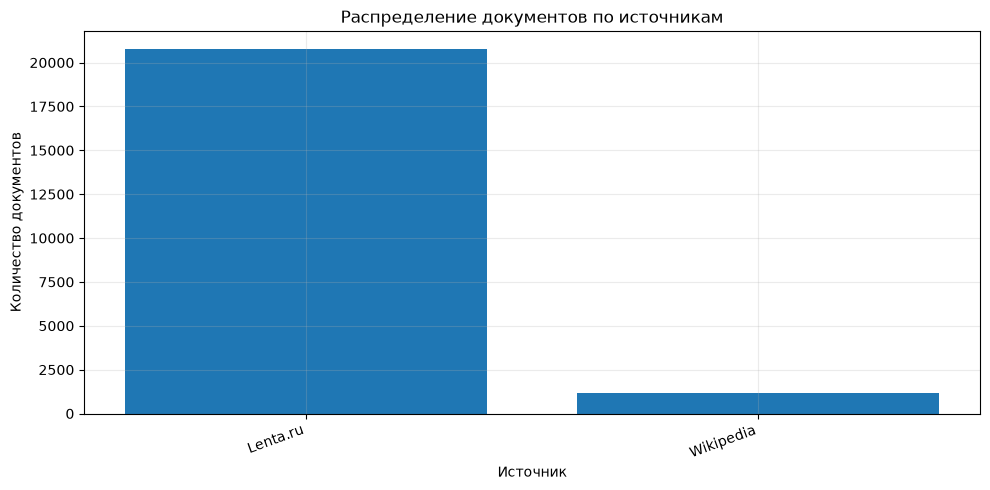

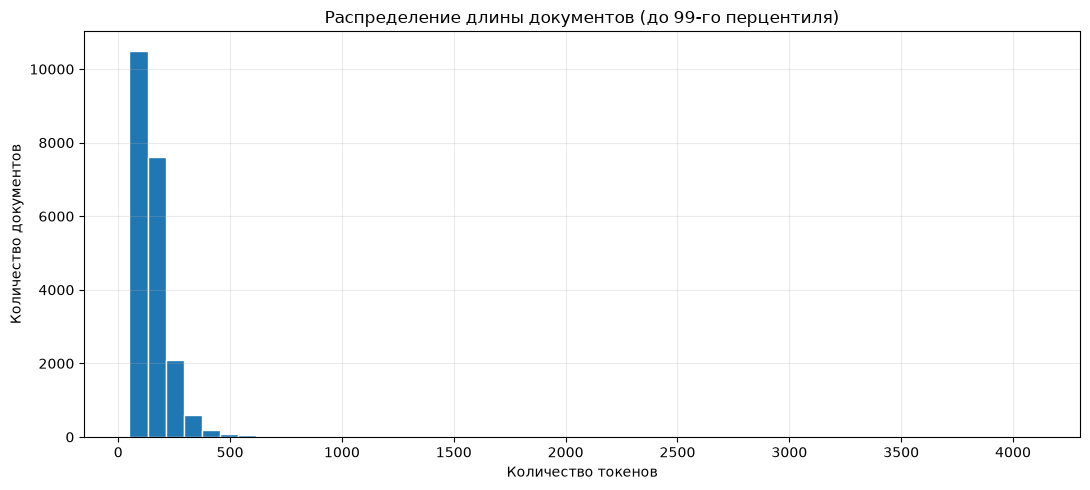

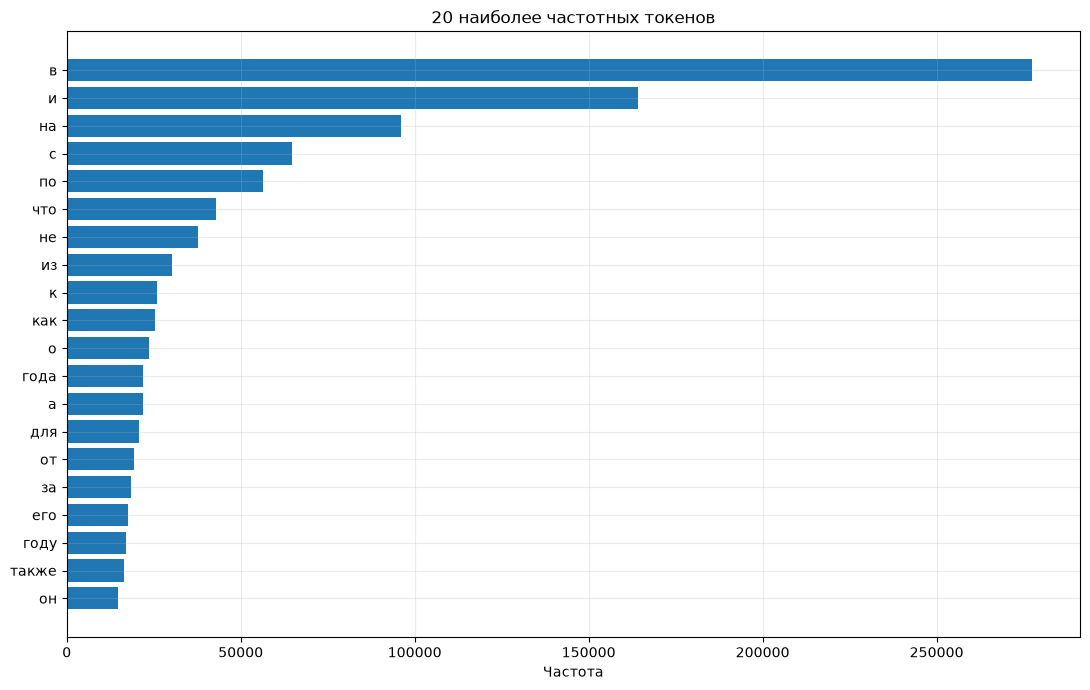

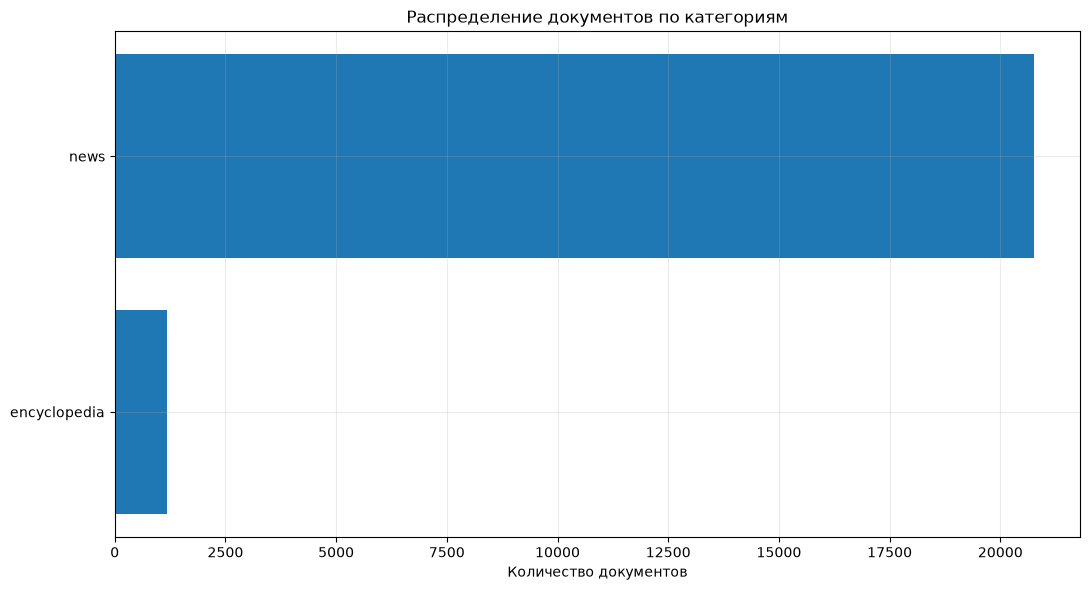


ПРОТОКОЛ ПРОВЕРКИ
PASS | Корпус существует
PASS | Документы обнаружены
PASS | JSONL прочитан без ошибок
PASS | Количество токенов положительно
PASS | Уникальные токены обнаружены
PASS | Таблица источников создана
PASS | Таблица категорий создана
PASS | JSON-паспорт создан
PASS | Markdown-паспорт создан
PASS | График источников создан
PASS | График длин документов создан

ИТОГ ЗАДАНИЯ № 13
Документов: 21,937
Токенов: 6,007,425
Уникальных токенов: 359,836
Источников: 2
Категорий: 2
Документов с датой: 20,761
Проверок: 11
Успешно: 11
Все проверки пройдены: True

Сохранённые результаты:
 - categories.csv
 - category_distribution.png
 - datasheet.md
 - datasheet_metrics.json
 - date_coverage.csv
 - document_length_distribution.png
 - metadata_fields.csv
 - source_categories.csv
 - source_distribution.png
 - sources.csv
 - top_100_tokens.csv
 - top_tokens.png

Основной паспорт: /Users/lenar_966/Desktop/ML/NLP/Practika_1/reports/task13/datasheet.md

Выполнение завершено.


In [24]:

# ============================================================
# ЗАДАНИЕ № 13
# ФОРМИРОВАНИЕ ПАСПОРТА ТЕКСТОВОГО КОРПУСА (DATASHEET)
# ============================================================

from pathlib import Path
from collections import Counter, defaultdict
from datetime import datetime
import json
import re
import statistics
import hashlib
import sys
import importlib.util
import subprocess

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. ПУТИ И КОНФИГУРАЦИЯ
# ------------------------------------------------------------

ROOT = Path.home() / "Desktop" / "ML" / "NLP" / "Practika_1"
CORPUS_PATH = ROOT / "data" / "processed" / "corpus.jsonl"
REPORT_DIR = ROOT / "reports" / "task13"

REPORT_DIR.mkdir(parents=True, exist_ok=True)

CORPUS_NAME = "Русскоязычный корпус Lenta.ru и Wikipedia"
CORPUS_VERSION = "1.0"
TOKEN_PATTERN = re.compile(
    r"[^\W_]+(?:[-'][^\W_]+)*",
    flags=re.UNICODE
)

assert CORPUS_PATH.exists(), f"Корпус не найден: {CORPUS_PATH}"

print("=" * 80)
print("ЗАДАНИЕ № 13 — DATASHEET")
print("=" * 80)

# ------------------------------------------------------------
# 2. ВСПОМОГАТЕЛЬНЫЕ ФУНКЦИИ
# ------------------------------------------------------------

def first_nonempty(doc, keys):
    for key in keys:
        value = doc.get(key)
        if value is not None and str(value).strip():
            return value
    return None


def normalize_source(value):
    text = str(value or "Не указан").strip()
    low = text.lower()

    if "lenta" in low:
        return "Lenta.ru"
    if "wiki" in low:
        return "Wikipedia"

    return text


def extract_category(doc):
    value = first_nonempty(
        doc,
        ["category", "categories", "topic",
         "section", "rubric", "domain", "label"]
    )

    if value is None:
        return "Не указана"

    if isinstance(value, list):
        return ", ".join(map(str, value)) or "Не указана"

    return str(value)


def extract_date(doc):
    value = first_nonempty(
        doc,
        ["date", "published_at", "publication_date",
         "timestamp", "datetime", "published"]
    )

    if value is None:
        return None

    if isinstance(value, (int, float)):
        try:
            unit = "ms" if abs(value) > 1e11 else "s"
            return pd.to_datetime(
                value, unit=unit, utc=True
            ).tz_localize(None)
        except (ValueError, OverflowError, TypeError):
            return None

    try:
        parsed = pd.to_datetime(
            value, errors="coerce", utc=True
        )
        if pd.isna(parsed):
            return None
        return parsed.tz_localize(None)
    except (ValueError, TypeError, OverflowError):
        return None


def safe_markdown(value):
    return str(value).replace("|", "\\|").replace("\n", " ")


def markdown_table(dataframe, limit=30):
    if dataframe.empty:
        return "Данные отсутствуют."

    df = dataframe.head(limit).copy()
    headers = list(df.columns)

    lines = [
        "| " + " | ".join(map(safe_markdown, headers)) + " |",
        "| " + " | ".join(["---"] * len(headers)) + " |"
    ]

    for row in df.itertuples(index=False, name=None):
        lines.append(
            "| " + " | ".join(map(safe_markdown, row)) + " |"
        )

    return "\n".join(lines)


def file_sha256(path):
    digest = hashlib.sha256()
    with path.open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


# ------------------------------------------------------------
# 3. АНАЛИЗ ВСЕГО КОРПУСА
# ------------------------------------------------------------

documents = 0
empty_documents = 0
invalid_json = 0
missing_text = 0

source_counts = Counter()
category_counts = Counter()
source_category_counts = Counter()
field_counts = Counter()
token_counter = Counter()

document_lengths = []
character_lengths = []
dates = []
date_by_source = defaultdict(list)

seen_ids = set()
duplicate_ids = 0
missing_ids = 0

language_metadata = Counter()

print("\nЧитаем полный корпус...")

with CORPUS_PATH.open("r", encoding="utf-8") as f:
    for line_number, line in enumerate(f, 1):

        if not line.strip():
            continue

        try:
            doc = json.loads(line)
        except json.JSONDecodeError:
            invalid_json += 1
            continue

        if not isinstance(doc, dict):
            invalid_json += 1
            continue

        documents += 1
        field_counts.update(doc.keys())

        source = normalize_source(doc.get("source"))
        category = extract_category(doc)

        source_counts[source] += 1
        category_counts[category] += 1
        source_category_counts[(source, category)] += 1

        doc_id = doc.get("id")

        if doc_id is None:
            missing_ids += 1
        else:
            key = (source, str(doc_id))
            if key in seen_ids:
                duplicate_ids += 1
            seen_ids.add(key)

        text = doc.get("text")

        if text is None:
            missing_text += 1
            text = ""

        text = str(text)

        if not text.strip():
            empty_documents += 1

        tokens = TOKEN_PATTERN.findall(text.lower())

        token_counter.update(tokens)
        document_lengths.append(len(tokens))
        character_lengths.append(len(text))

        language = first_nonempty(
            doc,
            ["language", "lang", "language_code"]
        )

        if language is not None:
            language_metadata[str(language)] += 1

        date = extract_date(doc)

        if date is not None:
            dates.append(date)
            date_by_source[source].append(date)

        if documents % 5000 == 0:
            print(f"Обработано документов: {documents:,}")

print(f"Обработка завершена: {documents:,} документов")

# ------------------------------------------------------------
# 4. ОСНОВНЫЕ СТАТИСТИЧЕСКИЕ ПОКАЗАТЕЛИ
# ------------------------------------------------------------

total_tokens = sum(token_counter.values())
unique_tokens = len(token_counter)

mean_length = (
    statistics.mean(document_lengths)
    if document_lengths else 0
)

median_length = (
    statistics.median(document_lengths)
    if document_lengths else 0
)

std_length = (
    statistics.pstdev(document_lengths)
    if document_lengths else 0
)

min_length = min(document_lengths, default=0)
max_length = max(document_lengths, default=0)

quantiles = (
    np.percentile(document_lengths, [25, 50, 75, 90, 95, 99])
    if document_lengths else np.zeros(6)
)

hapax = sum(
    1 for frequency in token_counter.values()
    if frequency == 1
)

corpus_size_mb = CORPUS_PATH.stat().st_size / (1024 ** 2)

date_min = min(dates) if dates else None
date_max = max(dates) if dates else None

corpus_hash = file_sha256(CORPUS_PATH)

summary = {
    "corpus_name": CORPUS_NAME,
    "version": CORPUS_VERSION,
    "generated_at": datetime.now().isoformat(),
    "documents": documents,
    "total_tokens": total_tokens,
    "unique_tokens": unique_tokens,
    "mean_tokens_per_document": round(mean_length, 4),
    "median_tokens_per_document": round(median_length, 4),
    "std_tokens_per_document": round(std_length, 4),
    "min_tokens_per_document": min_length,
    "max_tokens_per_document": max_length,
    "q25": round(float(quantiles[0]), 4),
    "q50": round(float(quantiles[1]), 4),
    "q75": round(float(quantiles[2]), 4),
    "q90": round(float(quantiles[3]), 4),
    "q95": round(float(quantiles[4]), 4),
    "q99": round(float(quantiles[5]), 4),
    "hapax_legomena": hapax,
    "hapax_share_vocabulary_percent": round(
        100 * hapax / unique_tokens, 4
    ) if unique_tokens else 0,
    "empty_documents": empty_documents,
    "missing_text": missing_text,
    "missing_ids": missing_ids,
    "duplicate_ids": duplicate_ids,
    "invalid_json_records": invalid_json,
    "corpus_size_mb": round(corpus_size_mb, 4),
    "sources": dict(source_counts),
    "categories": len(category_counts),
    "documents_with_parseable_date": len(dates),
    "date_min": str(date_min) if date_min is not None else None,
    "date_max": str(date_max) if date_max is not None else None,
    "language_metadata": dict(language_metadata),
    "sha256": corpus_hash,
    "tokenization_definition": TOKEN_PATTERN.pattern
}

print("\n" + "=" * 80)
print("ОСНОВНЫЕ ХАРАКТЕРИСТИКИ КОРПУСА")
print("=" * 80)

for key in [
    "documents",
    "total_tokens",
    "unique_tokens",
    "mean_tokens_per_document",
    "median_tokens_per_document",
    "std_tokens_per_document",
    "min_tokens_per_document",
    "max_tokens_per_document",
    "hapax_legomena",
    "corpus_size_mb",
    "empty_documents",
    "duplicate_ids",
    "documents_with_parseable_date"
]:
    print(f"{key:38s}: {summary[key]}")

# ------------------------------------------------------------
# 5. РАСПРЕДЕЛЕНИЕ ПО ИСТОЧНИКАМ
# ------------------------------------------------------------

source_df = pd.DataFrame(
    source_counts.items(),
    columns=["Источник", "Документов"]
)

source_df = source_df.sort_values(
    "Документов", ascending=False
)

source_df["Доля, %"] = (
    source_df["Документов"] / max(documents, 1) * 100
).round(4)

source_df.to_csv(
    REPORT_DIR / "sources.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n" + "=" * 80)
print("РАСПРЕДЕЛЕНИЕ ПО ИСТОЧНИКАМ")
print("=" * 80)
print(source_df.to_string(index=False))

# ------------------------------------------------------------
# 6. РАСПРЕДЕЛЕНИЕ ПО КАТЕГОРИЯМ
# ------------------------------------------------------------

category_df = pd.DataFrame(
    category_counts.items(),
    columns=["Категория", "Документов"]
)

category_df = category_df.sort_values(
    "Документов", ascending=False
)

category_df["Доля, %"] = (
    category_df["Документов"] / max(documents, 1) * 100
).round(4)

category_df.to_csv(
    REPORT_DIR / "categories.csv",
    index=False,
    encoding="utf-8-sig"
)

source_category_df = pd.DataFrame(
    [
        {
            "Источник": source,
            "Категория": category,
            "Документов": count
        }
        for (source, category), count
        in source_category_counts.items()
    ]
)

source_category_df.to_csv(
    REPORT_DIR / "source_categories.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n" + "=" * 80)
print("РАСПРЕДЕЛЕНИЕ ПО КАТЕГОРИЯМ — ТОП-20")
print("=" * 80)
print(category_df.head(20).to_string(index=False))

# ------------------------------------------------------------
# 7. СТРУКТУРА МЕТАДАННЫХ
# ------------------------------------------------------------

field_df = pd.DataFrame(
    [
        {
            "Поле": field,
            "Документов с полем": count,
            "Покрытие, %": round(
                100 * count / max(documents, 1), 4
            )
        }
        for field, count in field_counts.items()
    ]
)

field_df = field_df.sort_values(
    "Документов с полем", ascending=False
)

field_df.to_csv(
    REPORT_DIR / "metadata_fields.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n" + "=" * 80)
print("СТРУКТУРА МЕТАДАННЫХ")
print("=" * 80)
print(field_df.to_string(index=False))

# ------------------------------------------------------------
# 8. ЧАСТОТНЫЙ СЛОВАРЬ
# ------------------------------------------------------------

top_words_df = pd.DataFrame(
    token_counter.most_common(100),
    columns=["Токен", "Частота"]
)

top_words_df["Доля, %"] = (
    100 * top_words_df["Частота"]
    / max(total_tokens, 1)
).round(5)

top_words_df.to_csv(
    REPORT_DIR / "top_100_tokens.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n" + "=" * 80)
print("ТОП-20 НАИБОЛЕЕ ЧАСТОТНЫХ ТОКЕНОВ")
print("=" * 80)
print(top_words_df.head(20).to_string(index=False))

# ------------------------------------------------------------
# 9. ВРЕМЕННОЙ ОХВАТ
# ------------------------------------------------------------

date_records = []

for source, source_dates in date_by_source.items():
    date_records.append({
        "Источник": source,
        "Документов с датой": len(source_dates),
        "Минимальная дата": str(min(source_dates).date()),
        "Максимальная дата": str(max(source_dates).date())
    })

date_df = pd.DataFrame(
    date_records,
    columns=[
        "Источник",
        "Документов с датой",
        "Минимальная дата",
        "Максимальная дата"
    ]
)

date_df.to_csv(
    REPORT_DIR / "date_coverage.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n" + "=" * 80)
print("ВРЕМЕННОЙ ОХВАТ")
print("=" * 80)

if date_df.empty:
    print("В метаданных не обнаружены распознаваемые даты.")
else:
    print(date_df.to_string(index=False))

# ------------------------------------------------------------
# 10. ВИЗУАЛИЗАЦИИ
# ------------------------------------------------------------

# График 1. Источники

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    source_df["Источник"],
    source_df["Документов"]
)

ax.set_title("Распределение документов по источникам")
ax.set_xlabel("Источник")
ax.set_ylabel("Количество документов")
ax.grid(axis="y", alpha=0.25)

plt.xticks(rotation=20, ha="right")
plt.tight_layout()

plt.savefig(
    REPORT_DIR / "source_distribution.png",
    dpi=180
)
plt.show()

# График 2. Длины документов

fig, ax = plt.subplots(figsize=(11, 5))

if document_lengths:
    upper_limit = np.percentile(
        document_lengths, 99
    )

    filtered_lengths = [
        x for x in document_lengths
        if x <= upper_limit
    ]

    ax.hist(
        filtered_lengths,
        bins=50,
        edgecolor="white"
    )

ax.set_title(
    "Распределение длины документов (до 99-го перцентиля)"
)
ax.set_xlabel("Количество токенов")
ax.set_ylabel("Количество документов")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "document_length_distribution.png",
    dpi=180
)
plt.show()

# График 3. Частотные токены

fig, ax = plt.subplots(figsize=(11, 7))

top_20 = top_words_df.head(20).iloc[::-1]

ax.barh(
    top_20["Токен"],
    top_20["Частота"]
)

ax.set_title("20 наиболее частотных токенов")
ax.set_xlabel("Частота")
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "top_tokens.png",
    dpi=180
)
plt.show()

# График 4. Категории

if not category_df.empty:
    fig, ax = plt.subplots(figsize=(11, 6))

    top_categories = category_df.head(15).iloc[::-1]

    ax.barh(
        top_categories["Категория"],
        top_categories["Документов"]
    )

    ax.set_title("Распределение документов по категориям")
    ax.set_xlabel("Количество документов")
    ax.grid(axis="x", alpha=0.25)

    plt.tight_layout()

    plt.savefig(
        REPORT_DIR / "category_distribution.png",
        dpi=180
    )
    plt.show()

# ------------------------------------------------------------
# 11. ДОПОЛНИТЕЛЬНАЯ ПРОВЕРКА РАЗБИЕНИЯ
# ------------------------------------------------------------

split_path = ROOT / "reports" / "task6" / "split.json"

split_info = {
    "available": False,
    "train_documents": None,
    "test_documents": None,
    "seed": None
}

if split_path.exists():
    with split_path.open(encoding="utf-8") as f:
        split = json.load(f)

    split_info = {
        "available": True,
        "train_documents": len(split.get("train_ids", [])),
        "test_documents": len(split.get("test_ids", [])),
        "seed": split.get("seed")
    }

summary["split"] = split_info

# ------------------------------------------------------------
# 12. СОХРАНЕНИЕ JSON-ПАСПОРТА
# ------------------------------------------------------------

summary_path = REPORT_DIR / "datasheet_metrics.json"

with summary_path.open("w", encoding="utf-8") as f:
    json.dump(
        summary,
        f,
        ensure_ascii=False,
        indent=2
    )

# ------------------------------------------------------------
# 13. ПОДГОТОВКА ОГРАНИЧЕНИЙ
# ------------------------------------------------------------

limitations = []

if len(source_counts) > 1:
    largest_source = source_counts.most_common(1)[0]

    largest_share = (
        largest_source[1] / max(documents, 1) * 100
    )

    limitations.append(
        f"Наиболее представленный источник — "
        f"{largest_source[0]} "
        f"({largest_share:.2f}% документов). "
        "Это необходимо учитывать при оценке "
        "репрезентативности корпуса."
    )

if category_counts.get("Не указана", 0):
    missing_category_share = (
        category_counts["Не указана"]
        / max(documents, 1) * 100
    )

    limitations.append(
        f"Для {missing_category_share:.2f}% документов "
        "не обнаружена тематическая категория "
        "в проверяемых полях метаданных."
    )

if len(dates) < documents:
    missing_date_share = (
        (documents - len(dates))
        / max(documents, 1) * 100
    )

    limitations.append(
        f"Для {missing_date_share:.2f}% документов "
        "не удалось определить дату публикации "
        "по проверяемым полям."
    )

if not language_metadata:
    limitations.append(
        "Языковая принадлежность не подтверждается "
        "отдельным полем метаданных. Русскоязычный "
        "характер корпуса определяется источниками "
        "и процедурой его формирования."
    )

limitations.append(
    "Корпус содержит материалы ограниченного "
    "набора источников и не гарантирует "
    "репрезентативность всех жанров русского языка."
)

limitations.append(
    "Права на распространение исходных текстов "
    "должны быть проверены отдельно для каждого "
    "источника перед публичной публикацией."
)

# ------------------------------------------------------------
# 14. ФОРМИРОВАНИЕ MARKDOWN DATASHEET
# ------------------------------------------------------------

date_range_text = (
    f"{date_min.date()} — {date_max.date()}"
    if date_min is not None and date_max is not None
    else "Не установлен по доступным метаданным"
)

language_text = (
    ", ".join(
        f"{key}: {value}"
        for key, value in language_metadata.items()
    )
    if language_metadata
    else "Русский (по назначению корпуса; "
         "автоматическая проверка языка не проводилась)"
)

source_md = markdown_table(source_df)
category_md = markdown_table(category_df, limit=30)
field_md = markdown_table(field_df)
date_md = markdown_table(date_df)

limitations_md = "\n".join(
    f"{i}. {item}"
    for i, item in enumerate(limitations, 1)
)

datasheet = f"""# Паспорт набора данных (Datasheet)

## 1. Общая информация

**Название:** {CORPUS_NAME}

**Версия:** {CORPUS_VERSION}

**Дата формирования паспорта:** {datetime.now():%d.%m.%Y}

**Назначение:** исследование методов токенизации,
морфологической нормализации и субсловной сегментации
русскоязычных текстов.

**Формат хранения:** JSONL.

**Путь к корпусу:** `data/processed/corpus.jsonl`.

## 2. Языковой состав

Основной язык корпуса — русский.

Сведения из языковых метаданных: {language_text}.

Если явная языковая разметка отсутствует, доля
документов на русском языке не может считаться
автоматически подтверждённой.

## 3. Количественные характеристики

| Показатель | Значение |
|---|---:|
| Количество документов | {documents:,} |
| Общее число токенов | {total_tokens:,} |
| Уникальных токенов | {unique_tokens:,} |
| Средняя длина документа | {mean_length:.2f} |
| Медианная длина документа | {median_length:.2f} |
| Стандартное отклонение длины | {std_length:.2f} |
| Минимальная длина | {min_length} |
| Максимальная длина | {max_length} |
| 25-й перцентиль | {quantiles[0]:.2f} |
| 75-й перцентиль | {quantiles[2]:.2f} |
| 95-й перцентиль | {quantiles[4]:.2f} |
| Hapax legomena | {hapax:,} |
| Размер файла, МБ | {corpus_size_mb:.2f} |
| Пустых документов | {empty_documents} |
| Повторяющихся идентификаторов | {duplicate_ids} |

**Метод подсчёта токенов:** регулярное выражение
`{TOKEN_PATTERN.pattern}` с приведением текста к
нижнему регистру.

Данные показатели могут отличаться от результатов
предыдущих заданий, если там использовались
другие правила токенизации.

## 4. Источники корпуса

{source_md}

### Лицензирование источников

- **Lenta.ru:** условия использования исходного
  набора данных требуют документального уточнения.
- **Wikipedia:** необходимо проверить условия
  лицензирования конкретной использованной выгрузки,
  включая требования атрибуции и распространения.
- **Другие источники:** при наличии необходимо
  установить их происхождение и правовой статус.

**Статус публикации:** разрешение на распространение
полного корпуса не подтверждено.

## 5. Тематические категории

{category_md}

Категории определяются по существующим метаданным.
При отсутствии тематической разметки используется
значение «Не указана».

## 6. Временной охват

**Общий период:** {date_range_text}

{date_md}

При отсутствии даты в метаданных временной охват
нельзя достоверно установить автоматически.

## 7. Структура данных

{field_md}

Документы представлены отдельными JSON-объектами,
размещёнными построчно в файле JSONL.

## 8. Очистка и предварительная обработка

В ходе практической работы реализованы компоненты
очистки и нормализации текстовых данных, включая:

- удаление или обработку HTML-разметки;
- нормализацию регистра;
- регулярную токенизацию;
- обработку знаков препинания;
- удаление стоп-слов в соответствующих конфигурациях;
- стемминг Snowball;
- лемматизацию pymorphy3;
- субсловную токенизацию BPE, WordPiece и Unigram.

Перечисленные методы относятся к реализованному
экспериментальному конвейеру. Их наличие не означает,
что все преобразования последовательно применялись
к каждому документу в сохранённом JSONL-файле.

Точная последовательность подготовки исходного
корпуса должна подтверждаться кодом заданий № 1–3.

## 9. Обучающие и тестовые выборки

- Обучающих документов: {split_info['train_documents']}
- Тестовых документов: {split_info['test_documents']}
- Seed: {split_info['seed']}

Разбиение используется для обучения и оценки
методов предварительной обработки.

Корректность разделения проверялась в заданиях
№ 8 и № 10.

## 10. Ограничения и систематические смещения

{limitations_md}

## 11. Воспроизводимость

Для воспроизведения анализа используются:

- исходный корпус в формате JSONL;
- программные модули предварительной обработки;
- сохранённые конфигурации экспериментов;
- обученные модели субсловной токенизации;
- тесты pytest;
- аналитические отчёты предыдущих заданий.

Контрольная сумма SHA-256 исходного файла:

`{corpus_hash}`

## 12. Этические и правовые аспекты

Корпус предназначен для учебных и исследовательских
задач обработки естественного языка.

Перед публикацией необходимо проверить права
на распространение исходных текстов, наличие
персональных данных и требования атрибуции.

Без подтверждения прав полный корпус не должен
автоматически распространяться под открытой лицензией.

## 13. Итоговая характеристика

Сформированный корпус содержит {documents:,}
документов и {total_tokens:,} токенов
при выбранном способе подсчёта.

Размер словаря составляет {unique_tokens:,}
уникальных токенов.

Корпус используется как основа для исследования
классических и современных методов токенизации,
морфологической нормализации и субсловной
сегментации русскоязычных текстов.

Подготовленный Datasheet документирует
основные свойства данных, их происхождение,
структуру, ограничения и условия воспроизведения.
"""

datasheet_path = REPORT_DIR / "datasheet.md"
datasheet_path.write_text(datasheet, encoding="utf-8")

# ------------------------------------------------------------
# 15. ИТОГОВАЯ ПРОВЕРКА
# ------------------------------------------------------------

checks = {
    "Корпус существует": CORPUS_PATH.exists(),
    "Документы обнаружены": documents > 0,
    "JSONL прочитан без ошибок": invalid_json == 0,
    "Количество токенов положительно": total_tokens > 0,
    "Уникальные токены обнаружены": unique_tokens > 0,
    "Таблица источников создана": (
        REPORT_DIR / "sources.csv"
    ).exists(),
    "Таблица категорий создана": (
        REPORT_DIR / "categories.csv"
    ).exists(),
    "JSON-паспорт создан": summary_path.exists(),
    "Markdown-паспорт создан": datasheet_path.exists(),
    "График источников создан": (
        REPORT_DIR / "source_distribution.png"
    ).exists(),
    "График длин документов создан": (
        REPORT_DIR / "document_length_distribution.png"
    ).exists(),
}

print("\n" + "=" * 80)
print("ПРОТОКОЛ ПРОВЕРКИ")
print("=" * 80)

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'} | {name}")

passed_count = sum(checks.values())

print("\n" + "=" * 80)
print("ИТОГ ЗАДАНИЯ № 13")
print("=" * 80)

print(f"Документов: {documents:,}")
print(f"Токенов: {total_tokens:,}")
print(f"Уникальных токенов: {unique_tokens:,}")
print(f"Источников: {len(source_counts)}")
print(f"Категорий: {len(category_counts)}")
print(f"Документов с датой: {len(dates):,}")
print(f"Проверок: {len(checks)}")
print(f"Успешно: {passed_count}")
print(f"Все проверки пройдены: {all(checks.values())}")

print("\nСохранённые результаты:")
for path in sorted(REPORT_DIR.iterdir()):
    print(" -", path.name)

print("\nОсновной паспорт:", datasheet_path)
print("\nВыполнение завершено.")
